This script (Tomofast-x-µ) runs Tomofast-x Code for QDM 3D Inversion, Magnetic source location determination, and Magnetic vector direction and intensity Detection

 The full workflow:
 1. Run TomoFast-x 3D inversion (WSL, or Linux)
 2. Extract best-fit dipole 3D location for each anomaly
 3. Compute dipole moment, declination, and inclination

 Every step in an independent tool

 To Run this code you have to install Tomofast-x first, and copy paste the current code in the same folder beside Bz file, this code automatically organizes the outputs within some folders


 Conversion rule between Tomofast and QDM

**QDM:** Z-axis positive *up*  
**Tomofast:** Z-axis positive *down*

| Conversion | Rule |
|-----------|------|
| **QDM → Tomofast** | Flip both **Bz** and **Mz** |
| **Tomofast → QDM** | Flip both **Bz** and **Mz** |
| **Tomofast → Tomofast** | Don’t flip **Bz** and don’t flip **Mz** |
| **QDM → QDM** | Don’t flip **Bz** and don’t flip **Mz** |


# Import Libraries


In [1]:
# paths
import os

# files
import glob

# arrays
import numpy as np

# plotting
import matplotlib.pyplot as plt

# matlab
from scipy.io import loadmat
import scipy.io

# datasets
import xarray as xr

# tables
import pandas as pd

# paths
from pathlib import Path

# Connectiviy
from scipy import ndimage as ndi

# shapes
import matplotlib.patches as patches

# Connectiviy
from scipy.ndimage import binary_dilation

# processes
import subprocess

# system
import sys

# Connectiviy
from scipy.ndimage import label, generate_binary_structure

# 3D 
from mpl_toolkits.mplot3d import Axes3D 

# math
import math

# regex
import re

# paleomag
import pmagpy.ipmag as ipmag


# colormap
from matplotlib.cm import ScalarMappable

# scaling
from matplotlib.colors import Normalize

#time
import time

#Tomofast Directory
TOMOFAST_HOME_WSL = "/home/abekhit/Tomofast-X"
TOMOFAST_HOME = "/home/abekhit/Tomofast-X"

#WSL Directory
WSL = r"C:\Windows\System32\wsl.exe"
#nUM of cores for tomofast run
NPROC = 7  # mpirun -np


base_dir = os.getcwd()  # current working directory
BASE_DIR = os.getcwd()  # current working directory
print("Current working directory (Windows):", base_dir)

-W- cartopy is not installed
    If you want to make maps, install using conda:
    conda install cartopy
Current working directory (Windows): D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3


# Create Folders


In [2]:
# 1-Create 3D Folder
folder_path = os.path.join(base_dir, "4-3D_Inversion_Filtered")       

if os.path.exists(folder_path):
    print("Folder already exists:", folder_path)
else:
    os.mkdir(folder_path)
    print("Folder created:", folder_path)
    

# 2-Create parfiles Folder
folder_path = os.path.join(base_dir, "0-Parfiles")       

if os.path.exists(folder_path):
    print("Folder already exists:", folder_path)
else:
    os.mkdir(folder_path)
    print("Folder created:", folder_path)

# 3-Create source detection Folder

folder_path = os.path.join(base_dir,  "4-Source_Detection")#, "Single_cell_meshs")        

if os.path.exists(folder_path):
    print("Folder already exists:", folder_path)
else:
    os.mkdir(folder_path)
    print("Folder created:", folder_path)

# 4- Create source location ouputs Folder

folder_path = os.path.join(base_dir,  "4-Source_Detection", "Tomofast_Output")      

if os.path.exists(folder_path):
    print("Folder already exists:", folder_path)
else:
    os.mkdir(folder_path)
    print("Folder created:", folder_path)

Folder already exists: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered
Folder already exists: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\0-Parfiles
Folder already exists: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-Source_Detection
Folder already exists: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-Source_Detection\Tomofast_Output


# Quick Visualization
the following two lines show the bz vs LED, assuming Bz.mat is in the same folder of this code.
* User Attention: in the second Define pixel size below, we used pix= 4.4 

Using: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\7Bz_uc0.mat
Variables: ['h', 'corners', 'newLED', 'Bz', 'Bt', 'step']
Pixel size (µm): 4.4


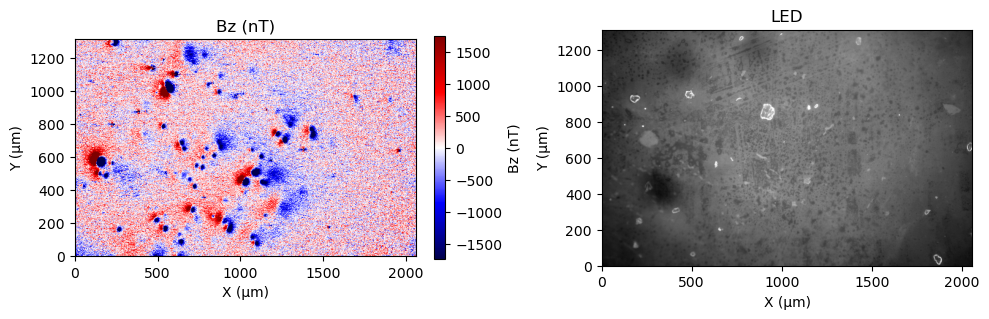

In [2]:
# Show Bz vs LED

# -------------------------------------------------
# LOAD MAT FILE
# -------------------------------------------------
mat_file = glob.glob(os.path.join(os.getcwd(), "*.mat"))[0]
print("Using:", mat_file)

mat = loadmat(mat_file)

print("Variables:",
      [k for k in mat.keys() if not k.startswith("__")])

# -------------------------------------------------
# EXTRACT DATA
# -------------------------------------------------
Bz = np.squeeze(mat["Bz"])* 1e9
led = np.squeeze(mat["newLED"])

# pixel size in µm
pix = float(np.squeeze(mat["step"]))*1e6

print("Pixel size (µm):", pix)

ny, nx = Bz.shape
extent = [0, nx*pix, 0, ny*pix]

# -------------------------------------------------
# PLOT
# -------------------------------------------------
fig, axs = plt.subplots(1,2, figsize=(10,5))

# --- Bz ---
v = np.percentile(np.abs(Bz), 99)

im = axs[0].imshow(
    Bz,
    cmap="seismic",
    vmin=-v,
    vmax=v,
    origin="upper",
    extent=extent
)

axs[0].set_title("Bz (nT)")
axs[0].set_xlabel("X (µm)")
axs[0].set_ylabel("Y (µm)")
#plt.colorbar(im, ax=axs[0], label="Bz (nT)")
plt.colorbar(im, ax=axs[0], label="Bz (nT)", fraction=0.03)
# --- LED ---
axs[1].imshow(
    led,
    cmap="gray",
    origin="upper",
    extent=extent
)

axs[1].set_title("LED")
axs[1].set_xlabel("X (µm)")
axs[1].set_ylabel("Y (µm)")

plt.tight_layout()
plt.show()


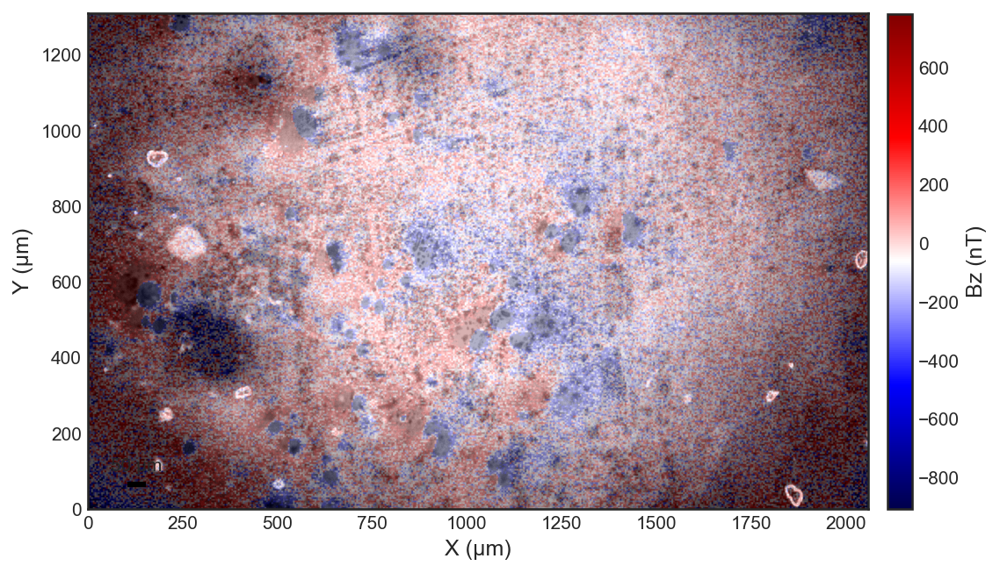

In [3]:
# Show Bz overlaid by LED

### User Attention: Define pixel size below, we used pix= 4.4 

# ---------- BASE DIRECTORY ----------
base_dir = os.getcwd()

# ---------- LOAD MAT ----------
mat_file = glob.glob(os.path.join(base_dir, "*.mat"))[0]
mat = loadmat(mat_file)

Bz  = np.squeeze(mat["Bz"])* 1e9
led = np.squeeze(mat["newLED"])

# ---------- Pixel size ----------
pix = 4.4  # µm
ny, nx = Bz.shape

x = np.linspace(0, nx*pix, nx)
y = np.linspace(0, ny*pix, ny)

X, Y = np.meshgrid(x, y)

# ---------- Clip outliers ----------
bz_min = np.percentile(Bz, 2)
bz_max = np.percentile(Bz, 98)

# ---------- Style ----------
plt.style.use("seaborn-v0_8-white")

fig, ax = plt.subplots(figsize=(8,6), dpi=150)

# ---------- Bz base ----------
im = ax.imshow(
    Bz,
    cmap="seismic",
    vmin=bz_min,
    vmax=bz_max,
    origin="upper",
    extent=[x.min(), x.max(), y.min(), y.max()]
)

cbar = plt.colorbar(im, ax=ax, shrink=0.66, pad=0.02)
cbar.set_label("Bz (nT)", fontsize=12)
cbar.ax.tick_params(labelsize=10)

# ---------- LED overlay ----------
ax.imshow(
    led,
    cmap="gray",
    alpha=0.7,
    origin="upper",
    extent=[x.min(), x.max(), y.min(), y.max()],
    vmin=np.percentile(led,5),
    vmax=np.percentile(led,95)
)

# ---------- Scale bar ----------
bar_len = 50  # µm
x0 = x.min() + 0.05*(x.max()-x.min())
y0 = y.min() + 0.05*(y.max()-y.min())

ax.plot([x0, x0+bar_len], [y0, y0],
        color="k", linewidth=3, solid_capstyle="butt")

ax.text(
    x0 + bar_len/2,
    y0 + 0.02*(y.max()-y.min()),
    f"{int(bar_len)} µm",
    ha="center", va="bottom", fontsize=10
)

# ---------- Labels ----------
ax.set_xlabel("X (µm)", fontsize=12)
ax.set_ylabel("Y (µm)", fontsize=12)

ax.set_aspect("equal", adjustable="box")
ax.margins(0)



plt.tight_layout()

# ---------- Save ----------
out_png = os.path.join(base_dir, "Bz_LED_overlay.png")
plt.savefig(out_png, dpi=300, bbox_inches="tight")

plt.show()


# 1: Data Preparation
This tool prepares the data

### 1. Read Bz mat file
This line reads Bz mat file (qdmlab) format and save it as csv and plot (if your data is csv skip the first step)
* User Attention: Define the Bz.mat name, and define Vmin max for the plot, given it's very important parameter for seeing tiny dipoles. This line converts the data from Tesla to nanotesla

In [5]:
# Function Definition 
#For Bu case change any Bz to Bu


# Unit conversion constants
METER_TO_MICROMETER = 1e6
TESLA_TO_NANOTESLA = 1e9

def load_qdm_mat(path, save_csv=True, csv_path=None):
    """
    Load QDM microscopy data from a MATLAB .mat file 
    return as an xarray Dataset.
    
    Parameters
    ----------
    path : str or Path
        Path to the .mat file
    
    save_csv : bool, optional (default=True)
        If True, save the output as a CSV file.
    
    csv_path : str or Path, optional
        Path to save the CSV file. 
        If None, will save as "<mat_file_stem>.csv" in the same folder.
    
    Returns
    -------
    xarray.Dataset
        Dataset with:
          - bz(y, x): vertical magnetic field [nT]
          - coords: x [µm], y [µm], z [µm] (sensor-sample distance)
          - attributes: units + file metadata
    """
    # Ensure path is Path object
    path = Path(path)

    # Load MATLAB file
    contents = scipy.io.loadmat(path)

    # Pixel spacing (convert m -> µm)
    spacing = contents['step'].ravel()[0] * METER_TO_MICROMETER

    # Vertical magnetic field (convert T -> nT)
    bz = contents['Bz'] * TESLA_TO_NANOTESLA

    # Sensor-sample distance ( µm)
    sensor_sample_distance = float(contents['h'])

    # Coordinates
    x = np.arange(bz.shape[1]) * spacing
    #y = np.arange(bz.shape[0]) * spacing
    y = np.arange(bz.shape[0])[::-1] * spacing #flip from image coordinates (origin up) to cartesian coordinate (origin low) 
    z = np.full_like(bz, sensor_sample_distance)

    # Wrap into xarray
    data = xr.Dataset(
        data_vars={
            "bz": (("y", "x"), bz)
        },
        coords={
            "x": ("x", x, {"units": "µm"}),
            "y": ("y", y, {"units": "µm"}),
            "z": (("y", "x"), z, {"long_name": "sensor sample distance", "units": "µm"})
        },
        attrs={"file_name": str(path)}
    )

    # Add field metadata
    data.bz.attrs = {"long_name": "vertical magnetic field", "units": "nT"}

    # --- Save to CSV if requested ---
    if save_csv:
        if csv_path is None:
            csv_path = path.with_suffix(".csv")  # same name as input, .csv extension
        
        # Flatten arrays into a table
        # When saving:
        df = pd.DataFrame({
        "x (µm)": np.tile(x, len(y)),      # x varies fastest
        "y (µm)": np.repeat(y, len(x)),    # y varies slowest
        "z (µm)": np.repeat(sensor_sample_distance, len(x)*len(y)),
        "bz (nT)": bz.ravel(order="C")
        })
        
        df = df.sort_values(by=["y (µm)", "x (µm)"], ascending=[True, True]) #sort Y after flipping)
        df.to_csv(csv_path, index=False)
        print(f"[INFO] Saved CSV file at: {csv_path}")

    return data

In [6]:
# Read Bz and save is as csv
### User Attention: Define the Bz.mat name

data = load_qdm_mat(os.path.join(base_dir, "7Bz_uc0.mat"))

# Dataset available in memory
print(data)

# CSV also saved: "-.csv"

[INFO] Saved CSV file at: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\7Bz_uc0.csv
<xarray.Dataset> Size: 2MB
Dimensions:  (y: 298, x: 468)
Coordinates:
  * x        (x) float64 4kB 0.0 4.4 8.8 13.2 ... 2.046e+03 2.05e+03 2.055e+03
  * y        (y) float64 2kB 1.307e+03 1.302e+03 1.298e+03 ... 8.8 4.4 0.0
    z        (y, x) float64 1MB 5.0 5.0 5.0 5.0 5.0 5.0 ... 5.0 5.0 5.0 5.0 5.0
Data variables:
    bz       (y, x) float64 1MB -403.9 70.92 541.0 161.9 ... 947.6 -17.23 -350.2
Attributes:
    file_name:  D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\7Bz_uc0.mat


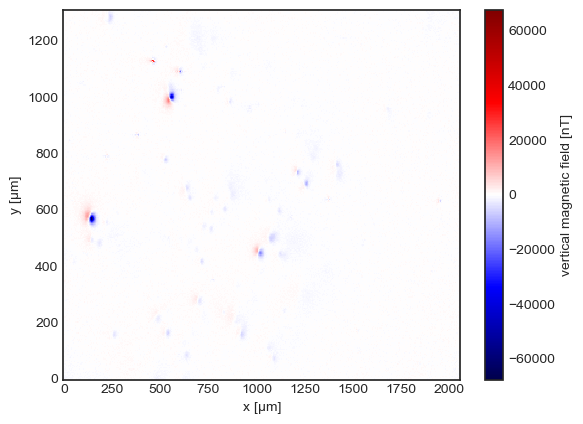

In [7]:
# Plot the vertical magnetic field map
### User Attention: define Vmin max for the plot, given it's very important parameter for seeing tiny dipoles

data.bz.plot.pcolormesh(cmap="seismic")#, vmax=5000, vmin=-5000)

### 2. Format data into Tomofast-x format [XYZBz]
This line reads the csv file output from the previous line or defined by user
* Also supports data clipping by definning the desired cells indeices {x_start = 0, x_end   = nx, y_start = 0, y_end   = ny}
* User Attention: define define CSV file name (filename_z=)

(139464, 4)
Plot saved to D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\bz.png


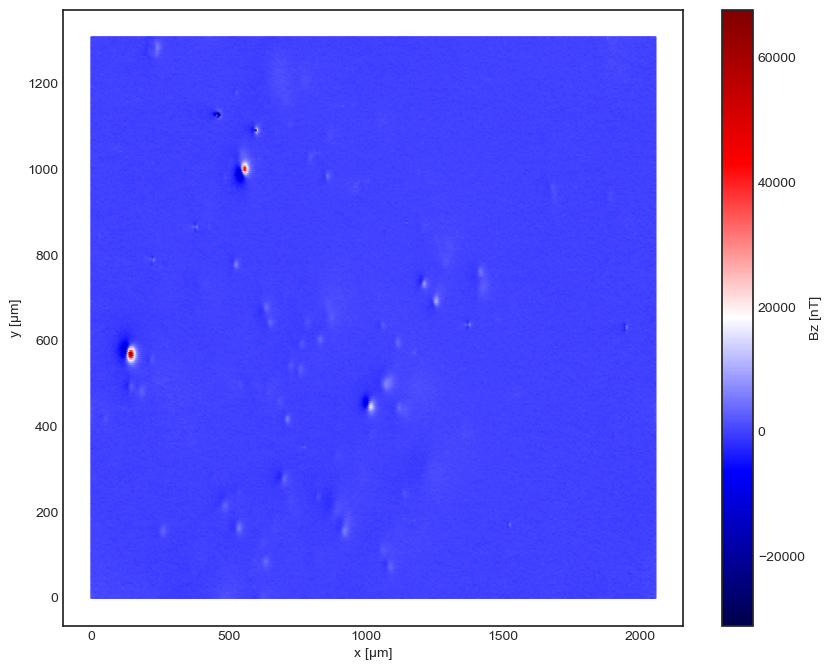

Grid dimensions: 468 298
(298, 468)
Plot saved to D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Clipped_bz.png


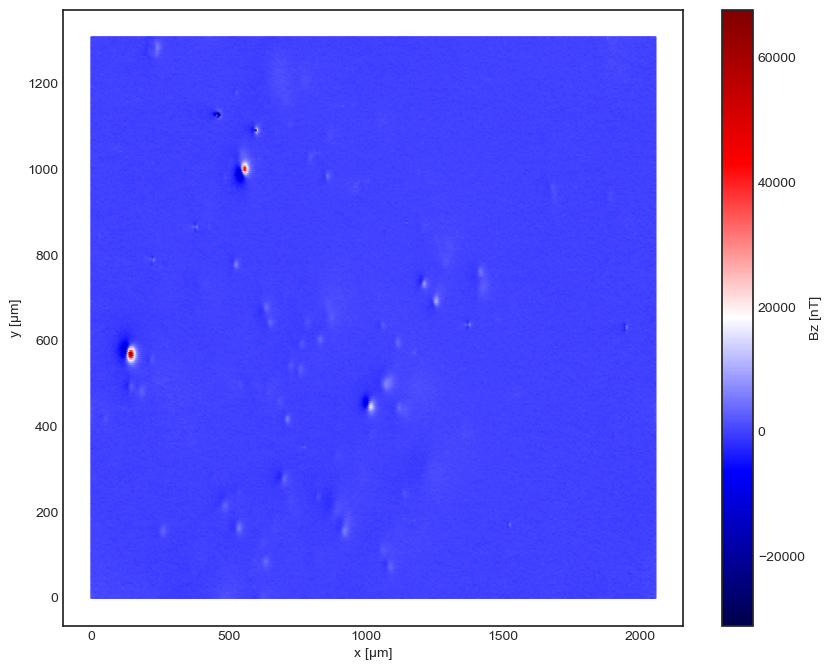

Xmin, Xmax = 0.0 2054.8
Ymin, Ymax = 0.0 1306.8000000000002
Ndata = 139464


In [8]:
#Data Perp. full scan ( or clip optional)
# also reads CsV
### User Attention: define define CSV file name (filename_z=)

   
def plot_data(x_coords, y_coords, values, title, out_dir= os.path.join(base_dir, "4-3D_Inversion_Filtered")):
    # Make sure output directory exists
    os.makedirs(out_dir, exist_ok=True)

    plt.figure(figsize=(10, 8))
    scatter = plt.scatter(x_coords, y_coords, c=values, cmap='seismic', s=1)#, vmax=5000, vmin=-5000) # define Vmin max if wanted
    #plt.axis('equal')
    plt.colorbar(scatter, label='Bz [nT]')
    plt.xlabel('x [µm]')
    plt.ylabel('y [µm]')
    #plt.title(title)

    # Save plot to file
    filename = os.path.join(out_dir, f"{title.replace(' ', '_')}.png")
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    print(f"Plot saved to {filename}")

    plt.show()

# Reads CSV User input
#filename_z = os.path.join(base_dir, "2-Forward_Data","Tomofast_Output", "data", "mag_calc_prior_data.txt")
#data_z = np.loadtxt(filename_z, skiprows=1)

# Reads CSV  ouput from the previous line (Bz read)
filename_z = os.path.join(base_dir, "7Bz_uc0.csv")
data_z = np.loadtxt(filename_z, delimiter=",", skiprows=1)

print(data_z.shape)

x_coords = data_z[:, 0]
y_coords = data_z[:, 1]
z_coords = data_z[:, 2]
z_coords = 0*data_z[:, 2] #Make Z=0

#bz = data_z[:, 3] # dont flip  if tomofast forwarded

bz = -1*data_z[:, 3] #Flipping Bz for tomofast coordiante system Z is positive down, the QDM Bz is positive up

#bx = data_z[:, 3]
#by = data_z[:, 4]

#amplitude
#b_mag = np.sqrt(bx**2 + by**2 + bz**2)


# Plot the image of data.
plot_data(x_coords, y_coords, bz, 'bz')

#==============================================================
# Find unique coordinates to determine grid dimensions.
unique_x = np.unique(x_coords)
unique_y = np.unique(y_coords)

nx = len(unique_x)  # number of points in X direction
ny = len(unique_y)  # number of points in Y direction

print("Grid dimensions:", nx, ny)

x_coords = x_coords.reshape(ny, nx)
y_coords = y_coords.reshape(ny, nx)
z_coords = z_coords.reshape(ny, nx)

bz = bz.reshape(ny, nx)
#==============================================================
# Clipping the data.
#enter the cell index (given the one index equal 4.4 increment)
# to cover the full range (min → max)
x_start = 0
x_end   = nx
y_start = 0
y_end   = ny

x_coords = x_coords[y_start:y_end, x_start:x_end]
y_coords = y_coords[y_start:y_end, x_start:x_end]
z_coords = z_coords[y_start:y_end, x_start:x_end]
bz = bz[y_start:y_end, x_start:x_end]

print(bz.shape)

# Convert back to 1D array.
x_coords = x_coords.flatten()
y_coords = y_coords.flatten()
z_coords = z_coords.flatten()
bz = bz.flatten()

# Plot the image of data.
plot_data(x_coords, y_coords, bz, 'Clipped bz')

print('Xmin, Xmax =', np.min(x_coords), np.max(x_coords))
print('Ymin, Ymax =', np.min(y_coords), np.max(y_coords))

#==============================================================
# Write tomofast data grid.
# Bz only
data_combined = np.column_stack((x_coords, y_coords, z_coords, bz))
#data_combined = np.column_stack((x_coords, y_coords, z_coords, bx, by, bz))

Ndataz = len(bz)
print('Ndata =', Ndataz)

np.savetxt(os.path.join(base_dir, "4-3D_Inversion_Filtered", "Mag_Inversion.obs"), data_combined, delimiter=' ', fmt="%f %f %f %f", header=str(Ndataz), comments='')

### 3. Anomalies Detection
This line reads the Bz data and split the anomalies into windows, using a standard deviation-based thresholding approach to suppress the unwanted background signals, focus on the sources and reduce computational cost and also useful for the cases where the dipoles are very close and data interfers.

* User Attention: the following line needs user adjustment to capture relaiable anomlaies:
* threshold_factor : is the number where user decide which pixels in bz_grid count as “signal” (potential anomaly) vs “background/noise” (recommended to change with 0.25).
* Pad_X, and Pad_Y : extend the window size around the anomaly (good for 3D modelling, but not recommend in use in the case of interfering data : keep 0)
* MIN_BLOB_CELLS : this number ignores the noisy small anomalies based of the cell size printed (set 1 to keep everything)
* MAX_BLOB_CELLS: this number ignores the noisy huge anomalies based of the cell size printed (set very big number to keep everything e.g, 100000)
* NZ_FIXED : this number defines the number of depth cells required for the parfile (step 5); should match the mesh model in the next step.
* for the case where positive and negative dipoles detected as two anomlaies use labels, n_blobs = ndi.label(mask_dilated), otherwise use:labels, n_blobs = ndi.label(mask)
* dx_cell, dy_cell, dz_cell: Set the appropriate cell size for the dipole locating step.

Grid: 468 298
Blobs detected (raw): 55
Blob 1: 2 cells
Blob 2: 15 cells
Blob 3: 24 cells
Blob 4: 7 cells
Blob 5: 47 cells
Blob 6: 13 cells
Blob 7: 24 cells
Blob 8: 2 cells
Blob 9: 13 cells
Blob 10: 7 cells
Blob 11: 32 cells
Blob 12: 1 cells
Blob 13: 16 cells
Blob 14: 2 cells
Blob 15: 116 cells
Blob 16: 1 cells
Blob 17: 25 cells
Blob 18: 1 cells
Blob 19: 14 cells
Blob 20: 75 cells
Blob 21: 18 cells
Blob 22: 8 cells
Blob 23: 273 cells
Blob 24: 3 cells
Blob 25: 3 cells
Blob 26: 1 cells
Blob 27: 2 cells
Blob 28: 13 cells
Blob 29: 10 cells
Blob 30: 7 cells
Blob 31: 3 cells
Blob 32: 8 cells
Blob 33: 12 cells
Blob 34: 9 cells
Blob 35: 18 cells
Blob 36: 2 cells
Blob 37: 45 cells
Blob 38: 48 cells
Blob 39: 36 cells
Blob 40: 16 cells
Blob 41: 4 cells
Blob 42: 7 cells
Blob 43: 6 cells
Blob 44: 2 cells
Blob 45: 219 cells
Blob 46: 3 cells
Blob 47: 1 cells
Blob 48: 11 cells
Blob 49: 1 cells
Blob 50: 37 cells
Blob 51: 26 cells
Blob 52: 1 cells
Blob 53: 2 cells
Blob 54: 41 cells
Blob 55: 1 cells

Blob

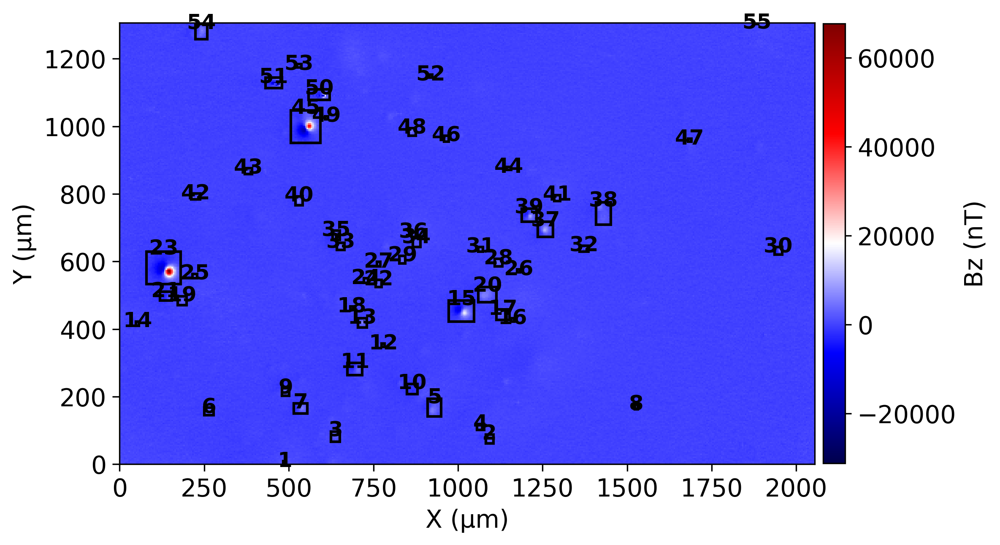


DONE
Kept blobs: 55
Obs folder: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Blob_Clipped_obs_RECT
Windows file: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\blob_windows.txt
Summary file: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\blob_window_summary.txt
Seed meshrow file: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\blob_seed_meshrow.txt
-31178.446952 67672.478035


In [3]:
# ============================================================
# SETTINGS
# ============================================================

threshold_factor = 2

PAD_X = 0   # extend rectangle in X (cols)
PAD_Y = 0 # extend rectangle in Y (rows)

MIN_BLOB_CELLS = 1   # ignore tiny blobs (set 1 to keep everything)
MAX_BLOB_CELLS = 100000   # ignore huge blobs (set very big number to keep everything e.g, 100000)
NZ_FIXED = 60        # nz for Tomofast (same for all blobs)

# ---- cell size + z center at half model depth (for Steepest search) ----
dx_cell = 4.4
dy_cell = 4.4
dz_cell = 4.4
z_center = (NZ_FIXED/15 + 0.5) * dz_cell

# store seed rows to write after loop
seed_rows = []  # (blob_id, xmin, xmax, ymin, ymax, zmin, zmax)

# ============================================================
# PATHS
# ============================================================
obs_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Mag_Inversion.obs")

out_obs_dir = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Blob_Clipped_obs_RECT")

# clear old outputs
if os.path.exists(out_obs_dir):
    for fname in os.listdir(out_obs_dir):
        fpath = os.path.join(out_obs_dir, fname)
        if os.path.isfile(fpath):
            os.remove(fpath)
else:
    os.makedirs(out_obs_dir)


# Output 1: blob windows (xmin xmax ymin ymax)
windows_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "blob_windows.txt")

# Output 2: summary for parfiles (nx ny nz ndata)
summary_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "blob_window_summary.txt")

# Output 3: seed single-cell mesh rows
seed_meshrow_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "blob_seed_meshrow.txt")


# Write headers (overwrite each run)
with open(windows_path, "w") as fw:
    fw.write("# blob_id x_min x_max y_min y_max\n")

with open(summary_path, "w") as fs:
    fs.write("# blob_id nx ny nz ndata\n")

# ============================================================
# 1) READ OBS
# ============================================================
with open(obs_path, "r") as f:
    header_line = f.readline().strip()

data = np.loadtxt(obs_path, skiprows=1)
x  = data[:, 0]
y  = data[:, 1]
bz = data[:, 3]

# ============================================================
# 2) GRID RESHAPE
# ============================================================
nx = len(np.unique(x))
ny = len(np.unique(y))

# assumes grid-ordered obs
x_grid  = x.reshape(ny, nx)
y_grid  = y.reshape(ny, nx)
bz_grid = bz.reshape(ny, nx)

print("Grid:", nx, ny)

# ============================================================
# 3) DETECT BLOBS
# ============================================================
thr = threshold_factor * np.std(bz_grid)
mask = np.abs(bz_grid) > thr


# allows nearby high-amplitude regions to connect if they are spatially close.
structure = np.ones((3, 3))  # allows diagonal + small gaps
mask_dilated = binary_dilation(mask, structure=structure, iterations=1)

labels, n_blobs = ndi.label(mask_dilated)

# not merging .
#labels, n_blobs = ndi.label(mask)

print("Blobs detected (raw):", n_blobs)

sizes = ndi.sum(mask, labels, index=np.arange(1, n_blobs + 1))
for i, sz in enumerate(sizes, start=1):
    print(f"Blob {i}: {int(sz)} cells")

slices = ndi.find_objects(labels)

# ============================================================
# helper: write obs file with updated Ndata in header
# ============================================================
def write_obs(out_path, header, arr):
    parts = header.split()
    try:
        int(parts[0])           # if header starts with Ndata
        parts[0] = str(arr.shape[0])
        header = " ".join(parts)
    except:
        pass

    with open(out_path, "w") as f:
        f.write(header + "\n")
        np.savetxt(f, arr, fmt="%.6f")

# ============================================================
# 4) OVERVIEW PLOT
# ============================================================
plt.figure(figsize=(8, 6), dpi=300)
#im = plt.imshow(
#    bz_grid,
#    origin="lower",
#    extent=[x_grid.min(), x_grid.max(), y_grid.min(), y_grid.max()],
#    cmap="seismic",
 #   aspect="equal"
#)

im = plt.imshow(
    bz_grid,
    origin="lower",
    extent=[x_grid.min(), x_grid.max(), y_grid.min(), y_grid.max()],
    cmap="seismic",
    aspect="equal")#, vmax=5000, vmin=-5000)

cbar = plt.colorbar(im, pad=0.01, shrink=0.61)
cbar.set_label("Bz (nT)", fontsize=14)
cbar.ax.tick_params(labelsize=14)

plt.xlabel("X (µm)", fontsize=14)
plt.ylabel("Y (µm)", fontsize=14)

ax = plt.gca()
ax.tick_params(axis="both", length=4, labelsize=14)
#ax.grid(True, linestyle="--", alpha=0.3)
ax.margins(0)
#ax.text(
##    0.02, 0.98, "(a)",
#    transform=ax.transAxes,
#    fontsize=25,
#    fontweight="bold",
 #   va="top",
 #   ha="left"
#)

plt.tight_layout()

# ============================================================
# 5) LOOP BLOBS: SAVE obs + SAVE windows + SAVE summary
# ============================================================
kept = 0

for i, sl in enumerate(slices, start=1):
    if sl is None:
        continue

    # skip tiny blobs
    if sizes[i-1] < MIN_BLOB_CELLS:
        print(f"Skipping Blob {i} (too small: {int(sizes[i-1])} cells)")
        continue
        
    # skip Huge blobs
    if sizes[i-1] > MAX_BLOB_CELLS:
        print(f"Skipping Blob {i} (too small: {int(sizes[i-1])} cells)")
        continue
        
    ys, xs = sl
    r0, r1 = ys.start, ys.stop - 1
    c0, c1 = xs.start, xs.stop - 1

    # extend bbox (Y longer)
    r0e = max(0, r0 - PAD_Y)
    r1e = min(ny - 1, r1 + PAD_Y)
    c0e = max(0, c0 - PAD_X)
    c1e = min(nx - 1, c1 + PAD_X)

    # rectangular mask
    rect_mask = np.zeros((ny, nx), dtype=bool)
    rect_mask[r0e:r1e+1, c0e:c1e+1] = True

    # clip rows (RECTANGLE)
    blob_data = data[rect_mask.ravel(), :]

    # rectangle coords (µm)
    x_min = x_grid[r0e, c0e]
    x_max = x_grid[r1e, c1e]
    y_min = y_grid[r0e, c0e]
    y_max = y_grid[r1e, c1e]

    # window size in CELLS (for parfile modelGrid.size)
    nx_win = (c1e - c0e + 1)  # X = columns
    ny_win = (r1e - r0e + 1)  # Y = rows
    nz_win = NZ_FIXED

    # number of data points in clipped obs (for parfile nData)
    ndata = blob_data.shape[0]

    print(f"\nBlob {i}:")
    print(f"  X range: [{x_min:.3f}, {x_max:.3f}] µm")
    print(f"  Y range: [{y_min:.3f}, {y_max:.3f}] µm")
    print(f"  nx ny nz: {nx_win} {ny_win} {nz_win}")
    print(f"  nData   : {ndata}")

    # --------------------------
    # (A) SAVE BLOB OBS
    # --------------------------
    obs_out = os.path.join(out_obs_dir, f"Blob_{i:03d}_RECT.obs")
    write_obs(obs_out, header_line, blob_data)

    # --------------------------
    # (B) SAVE WINDOW FILE LINE
    # --------------------------
    with open(windows_path, "a") as fw:
        fw.write(f"{i} {x_min:.6f} {x_max:.6f} {y_min:.6f} {y_max:.6f}\n")

    # --------------------------
    # (C) SAVE SUMMARY FILE LINE
    # --------------------------
    with open(summary_path, "a") as fs:
        fs.write(f"{i} {nx_win} {ny_win} {nz_win} {ndata}\n")

    # --------------------------
    # (D) SAVE SEED SINGLE-CELL MESH ROW
    # --------------------------
    cx = 0.5 * (x_min + x_max) 
    cy = 0.5 * (y_min + y_max)  

    # snap to nearest 4.4 grid
    cx = round(cx / dx_cell) * dx_cell # coordinate fix fix to cell size
    cy = round(cy / dy_cell) * dy_cell # coordinate fix fix to cell size
 
    xmin_seed = cx - 0.5 * dx_cell
    xmax_seed = cx + 0.5 * dx_cell
    ymin_seed = cy - 0.5 * dy_cell
    ymax_seed = cy + 0.5 * dy_cell

    zmin_seed = z_center - 0.5 * dz_cell
    zmax_seed = z_center + 0.5 * dz_cell

    seed_rows.append((i, xmin_seed, xmax_seed, ymin_seed, ymax_seed, zmin_seed, zmax_seed))

    # draw rectangle + label on overview
    ax.add_patch(
        patches.Rectangle(
            (x_min, y_min),
            x_max - x_min, y_max - y_min,
            edgecolor="black", facecolor="none", linewidth=1.5
        )
    )
    ax.text(
        0.5*(x_min+x_max), y_max + 0.9 * (y_max - y_min) * 0.1, str(i),
      color="black", ha="center", va="center", fontsize=12, weight="bold"
   )

    kept += 1
    print("  Saved obs:", obs_out)

plt.tight_layout()
out_png = os.path.join(base_dir, "4-3D_Inversion_Filtered", "BZ_Blobs.png")
plt.savefig(out_png, dpi=300, bbox_inches='tight')
plt.show()


# ============================================================
# Write seed meshrow file
# first line = count
# ============================================================
with open(seed_meshrow_path, "w") as f:
    f.write(f"{len(seed_rows)}\n")
    for r in seed_rows:
        blob_id, xmin_s, xmax_s, ymin_s, ymax_s, zmin_s, zmax_s = r

        blob_name = f"Blob_{blob_id:03d}"
        grain_id = 1

        i_idx = 1
        j_idx = 1
        k_idx = 1

        f.write(
            f"{blob_name} {grain_id} "
            f"{xmin_s:.6f} {xmax_s:.6f} "
            f"{ymin_s:.6f} {ymax_s:.6f} "
            f"{zmin_s:.6f} {zmax_s:.6f} "
            f"0.000000 0.000000 0.000000 {i_idx} {j_idx} {k_idx}\n"
        )


        
print("\n====================================")
print("DONE")
print("Kept blobs:", kept)
print("Obs folder:", out_obs_dir)
print("Windows file:", windows_path)
print("Summary file:", summary_path)
print("Seed meshrow file:", seed_meshrow_path)
print("====================================")

print(min(bz),max(bz))

# Tool 1: 3D full grid model (optional)
* If you do not wish to perform the full 3D inversion and instead want to proceed directly with dipole locating and fitting, skip it and go to Tool 3.
* This tool runs Tomofast-x full magnetic vector inversion in order to obtain the full 3D magnetic image of the QDM micromagnetic scan.  
the inputs are (Bz file, mesh file, Tomofast Parameter file)

### 1. Create Meshs
this line creates 3d Mesh model.  
this line supports non-uniform padding regions dx , dy (delta per layer), and dz (delta per layer) to reach maximum pads and depth with less computational resources)
* User Attention: define the model parameters:
* dx_core, dy_core: the x,y cell size in the core area below the anomlaies (must match the data spacing)
* npad_x, npad_y : Number of padding cell (outside the windows to ensure full 3D model recovery and overcome the edge effect)
* rx, ry : Padding growth (for example 1.15 means every cell is cummlatively 15% larger than the previous one)
* nz, dz0, rz: number of depth cells, depth cell size, and depth cell growth ( for example 60, 4.4, 1 mean 60 x 4.4 x 1 = 264 µm depth); non-uniform depth saves time and cost for 3d modelling, however, it is not recommended for dipole information as it might lead to non-accurate results. in all cases total depth should matches the sample thickness)

In [10]:

# ============================================================
#  INPUTS (EDIT ONLY THIS BLOCK)
# ============================================================

# Input blob windows file:
# Each line: blob_id x_min x_max y_min y_max
windows_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "blob_windows.txt")

# Output folder for meshgrids
out_dir = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Blob_Meshgrids")
os.makedirs(out_dir, exist_ok=True)

# Output 2: summary for parfiles (nx ny nz ndata)
summary_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "blob_window_summary.txt")

# --- Core (data) cell sizes in X/Y (µm) ---
dx_core = 4.4
dy_core = 4.4

# Expand each window by half a core-cell (recommended so data falls inside nicely)
expand_half_cell = True

# --- Non-uniform padding in X/Y ---
npad_x = 5         # pad cells on EACH side in X
npad_y = 5       # pad cells on EACH side in Y
rx = 1.15         # pad growth factor in X (outwards)
ry = 1.15          # pad growth factor in Y (outwards)

# --- Non-uniform Z (layer thickness grows with depth) ---
z_min = 0.0         # top of model (positive down)
nz = 60             # number of z cells
dz0 = 4.4           # top layer thickness (µm)
rz = 1        # z growth factor per layer (depth)

# ------------------------------------------------------------
# ndata handling:
# If you already know ndata per blob, put it in blob_windows.txt
# (add 6th column: ndata). If not, we use a simple fallback:
# ndata = nx_core * ny_core (core grid count)
# ------------------------------------------------------------
use_ndata_from_file_if_present = True

# ============================================================


# ------------------------------------------------
# Write Tomofast meshgrid file (3-component model)
# ------------------------------------------------
def write_meshgrid_tomofast(filename, line_data):
    os.makedirs(os.path.dirname(filename), exist_ok=True)
    with open(filename, "w") as f:
        f.write(f"{line_data.shape[0]}\n")
        np.savetxt(
            f, line_data,
            fmt="%f %f %f %f %f %f %f %f %f %d %d %d"
        )


def make_edges(core_min, d_core, n_core, npad, r):
    """
    Build edges with:
      - uniform core widths = d_core (n_core cells)
      - geometric padding widths growing OUTWARD from the core
    Returns:
      edges: length (n_core + 2*npad + 1)
      widths: length (n_core + 2*npad)
    """
    core_widths = np.full(n_core, d_core, dtype=float)

    # padding widths: closest pad cell = d_core, then grows outward
    left_widths  = d_core * (r ** np.arange(npad - 1, -1, -1))  # big -> ... -> d_core (toward core)
    right_widths = d_core * (r ** np.arange(0, npad))           # d_core -> ... -> big (outward)

    widths = np.concatenate([left_widths, core_widths, right_widths])

    start_edge = core_min - left_widths.sum()
    edges = start_edge + np.concatenate(([0.0], np.cumsum(widths)))
    return edges, widths


def build_mesh_for_window(
    x_min, x_max, y_min, y_max, out_file,
    dx_core=dx_core, dy_core=dy_core,
    npad_x=npad_x, npad_y=npad_y, rx=rx, ry=ry,
    z_min=z_min, nz=nz, dz0=dz0, rz=rz,
    expand_half_cell=expand_half_cell
):
    # -----------------------------
    # 1) Define CORE extents
    # -----------------------------
    if expand_half_cell:
        x_core_min = x_min - 0.5 * dx_core
        x_core_max = x_max + 0.5 * dx_core
        y_core_min = y_min - 0.5 * dy_core
        y_core_max = y_max + 0.5 * dy_core
    else:
        x_core_min, x_core_max = x_min, x_max
        y_core_min, y_core_max = y_min, y_max

    # Core cell counts
    nx_core = int(np.round((x_core_max - x_core_min) / dx_core))
    ny_core = int(np.round((y_core_max - y_core_min) / dy_core))

    if nx_core < 1 or ny_core < 1:
        raise ValueError(
            f"Window too small for given dx/dy. "
            f"Got nx_core={nx_core}, ny_core={ny_core}. Check units/extents."
        )

    # Snap core max so it is exactly n_core * d_core from core_min
    x_core_max = x_core_min + nx_core * dx_core
    y_core_max = y_core_min + ny_core * dy_core

    # -----------------------------
    # 2) Build NON-UNIFORM X/Y edges
    # -----------------------------
    x_edges, x_widths = make_edges(x_core_min, dx_core, nx_core, npad_x, rx)
    y_edges, y_widths = make_edges(y_core_min, dy_core, ny_core, npad_y, ry)

    # Totals including pads
    nx_cells = nx_core + 2 * npad_x
    ny_cells = ny_core + 2 * npad_y
    nz_cells = nz

    # -----------------------------
    # 3) Build NON-UNIFORM Z edges (geometric growth)
    # -----------------------------
    dz_list = dz0 * (rz ** np.arange(nz_cells))                 # len = nz_cells
    z_edges = z_min + np.concatenate(([0.0], np.cumsum(dz_list)))

    # -----------------------------
    # 4) Create cell bounds grids (Tomofast ordering)
    # -----------------------------
    # Use indexing="ij" and flatten(order="F")
    X1, Y1, Z1 = np.meshgrid(x_edges[:-1], y_edges[:-1], z_edges[:-1], indexing="ij")
    X2, Y2, Z2 = np.meshgrid(x_edges[ 1:], y_edges[ 1:], z_edges[ 1:], indexing="ij")

    # 1-based indices for Tomofast
    I, J, K = np.meshgrid(
        np.arange(1, nx_cells + 1),
        np.arange(1, ny_cells + 1),
        np.arange(1, nz_cells + 1),
        indexing="ij"
    )

    # Flatten (Fortran order)
    x1 = X1.flatten(order="F"); x2 = X2.flatten(order="F")
    y1 = Y1.flatten(order="F"); y2 = Y2.flatten(order="F")
    z1 = Z1.flatten(order="F"); z2 = Z2.flatten(order="F")
    ii = I.flatten(order="F");  jj = J.flatten(order="F");  kk = K.flatten(order="F")

    N = x1.size
    zeros = np.zeros(N, dtype=float)

    # 3-comp model format:
    # X1 X2 Y1 Y2 Z1 Z2 0 0 0 I J K
    line_data = np.column_stack([x1, x2, y1, y2, z1, z2, zeros, zeros, zeros, ii, jj, kk])

    # Write file
    write_meshgrid_tomofast(out_file, line_data)

    # Return summary info
    info = {
        "nx_core": nx_core, "ny_core": ny_core, "nz": nz_cells,
        "nx": nx_cells, "ny": ny_cells,
        "x_min": x_edges[0], "x_max": x_edges[-1],
        "y_min": y_edges[0], "y_max": y_edges[-1],
        "z_min": z_edges[0], "z_max": z_edges[-1],
        "dz_top": dz_list[0], "dz_bottom": dz_list[-1],
        "dx_min": x_widths.min(), "dx_max": x_widths.max(),
        "dy_min": y_widths.min(), "dy_max": y_widths.max()
    }
    return info


# ------------------------------------------------
# MAIN
# ------------------------------------------------
windows = np.loadtxt(windows_path, comments="#", ndmin=2)

print("Windows loaded:", windows.shape[0])
print("Output folder:", out_dir)
print(f"Pads: npad_x={npad_x}, npad_y={npad_y}, rx={rx}, ry={ry}")
print(f"Z: nz={nz}, dz0={dz0}, rz={rz}\n")

# Write summary header once
with open(summary_path, "w") as fs:
    fs.write("# blob_id nx ny nz ndata\n")

for row in windows:
    blob_id = int(row[0])
    x_min, x_max, y_min, y_max = row[1], row[2], row[3], row[4]

    out_file = os.path.join(out_dir, f"Meshgrid_Blob_{blob_id:03d}.txt")
    info = build_mesh_for_window(x_min, x_max, y_min, y_max, out_file)

    # -----------------------------
    # ndata (keep simple, unchanged)
    # -----------------------------
    # If blob_windows.txt has a 6th column (ndata), use it
    if use_ndata_from_file_if_present and row.size >= 6:
        ndata = int(row[5])
    else:
        # fallback (simple): number of core cells in XY
        ndata = int(info["nx_core"] * info["ny_core"])

    # ---------------------------------------------------------
    # WRITE SUMMARY (UPDATED): use padded FINAL nx ny nz
    # ---------------------------------------------------------
    with open(summary_path, "a") as fs:
        fs.write(
            f"{blob_id:d} "
            f"{info['nx']:d} {info['ny']:d} {info['nz']:d} "
            f"{ndata:d}\n"
        )

    print(
        f"Blob {blob_id:03d}: "
        f"core(nx,ny)=({info['nx_core']},{info['ny_core']})  "
        f"total(nx,ny,nz)=({info['nx']},{info['ny']},{info['nz']})  "
        f"ndata={ndata}"
    )
    print(
        f"  X[{info['x_min']:.3f}, {info['x_max']:.3f}]  "
        f"Y[{info['y_min']:.3f}, {info['y_max']:.3f}]  "
        f"Z[{info['z_min']:.3f}, {info['z_max']:.3f}]"
    )
    print(
        f"  Δx(min,max)=({info['dx_min']:.3f},{info['dx_max']:.3f})  "
        f"Δy(min,max)=({info['dy_min']:.3f},{info['dy_max']:.3f})  "
        f"Δz(top,bottom)=({info['dz_top']:.3f},{info['dz_bottom']:.3f})"
    )
    print("  saved:", out_file, "\n")

print("Summary saved:", summary_path)
print("Done.")


Windows loaded: 55
Output folder: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Blob_Meshgrids
Pads: npad_x=5, npad_y=5, rx=1.15, ry=1.15
Z: nz=60, dz0=4.4, rz=1

Blob 001: core(nx,ny)=(3,3)  total(nx,ny,nz)=(13,13,60)  ndata=9
  X[452.134, 524.666]  Y[-31.866, 40.666]  Z[0.000, 264.000]
  Δx(min,max)=(4.400,7.696)  Δy(min,max)=(4.400,7.696)  Δz(top,bottom)=(4.400,4.400)
  saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Blob_Meshgrids\Meshgrid_Blob_001.txt 

Blob 002: core(nx,ny)=(6,7)  total(nx,ny,nz)=(16,17,60)  ndata=42
  X[1050.534, 1136.266]  Y[29.734, 119.866]  Z[0.000, 264.000]
  Δx(min,max)=(4.400,7.696)  Δy(min,max)=(4.400,7.696)  Δz(top,bottom)=(4.400,4.400)
  saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Blob_Meshgrids\Meshgrid_Blob_002.txt 

Blob 003: core(nx,ny)=(7,8)  total(nx,ny,nz)=(17,18,60)  ndata=56
  X[592.934, 683.066]  Y[34.134, 128.666]  Z[0.000, 264.000]
  Δx(mi

### 2. Create Parfiles
this line creates the parameter files for each anomaly required for the Tomofast-x 3D full vector inverions.
this line reads the number of data [Ndata] , mesh sizes [nx,ny,nz] from the anomalies output. 
* User Attention: Define the compression rate : (forward.matrixCompression.rate) for saving time, however not recommend to use extreme compression, best values between (0.1 - 0.01), where less than 0.01 makes some artifacts.


In [11]:
### User Attention: Define the compression rate : (forward.matrixCompression.rate) 

# ------------------------------------------------
# INPUT: reads anomalies detection output summary file
# ------------------------------------------------
# Format:
# blob_id nx ny nz ndata
summary_path = os.path.join(
    base_dir,
    "4-3D_Inversion_Filtered",
    "blob_window_summary.txt"
)

# ------------------------------------------------
# OUTPUT: parfiles
# ------------------------------------------------
par_out_dir = os.path.join(base_dir, "0-Parfiles")
os.makedirs(par_out_dir, exist_ok=True)

# ------------------------------------------------
# Parfile template (ONLY placeholders will change)
# ------------------------------------------------
PAR_TEMPLATE = """==================================================================================
GLOBAL
==================================================================================
global.outputFolderPath         = ./output/QDM/Blob_{blob_id:03d}
global.description              = QDM inversion – Blob {blob_id}

==================================================================================
MODEL GRID parameters
==================================================================================
# nx ny nz
modelGrid.size                        = {nx} {ny} {nz}
modelGrid.magn.file                   = data/QDM/Meshgrid_Blob_{blob_id:03d}.txt
modelGrid.magn.nModelComponents       = 3

==================================================================================
DATA parameters
==================================================================================
forward.data.magn.nData                = {ndata}
forward.data.magn.dataGridFile         = data/QDM/Blob_{blob_id:03d}_RECT.obs
forward.data.magn.dataValuesFile       = data/QDM/Blob_{blob_id:03d}_RECT.obs
forward.data.magn.nDataComponents      = 1

==================================================================================
MAGNETIC FIELD constants
==================================================================================
forward.magneticField.inclination              = 90.0
forward.magneticField.declination              = 0.0
forward.magneticField.XaxisDeclination         = 0.d0

==================================================================================
DEPTH WEIGHTING
==================================================================================
# 1-depth weight, 2-distance weight.
forward.depthWeighting.type                    = 1

==================================================================================
SENSITIVITY KERNEL
==================================================================================
sensit.readFromFiles                  = 0
sensit.folderPath                     = ./output/QDM/SENSIT/

==================================================================================
MATRIX COMPRESSION
==================================================================================
forward.matrixCompression.type                        = 1
forward.matrixCompression.rate                        = 0.1

==================================================================================
PRIOR MODEL
==================================================================================
inversion.priorModel.type                  = 1
inversion.priorModel.magn.value            = 0.000000

==================================================================================
INVERSION parameters
==================================================================================
inversion.nMajorIterations              = 3
inversion.nMinorIterations              = 100

==================================================================================
MODEL DAMPING (m - m_prior)
==================================================================================
inversion.modelDamping.magn.weight      = 0.0

==================================================================================
JOINT INVERSION parameters
==================================================================================
inversion.joint.grav.problemWeight      = 0.00000000
inversion.joint.magn.problemWeight      = 1.00000000
"""

# ------------------------------------------------
# LOAD SUMMARY + WRITE PARFILES
# ------------------------------------------------
summary = np.loadtxt(summary_path, comments="#", ndmin=2)

print("Creating Parfiles...")

for row in summary:
    blob_id = int(row[0])
    nx      = int(row[1])
    ny      = int(row[2])
    nz      = int(row[3])
    ndata   = int(row[4])

    par_text = PAR_TEMPLATE.format(
        blob_id=blob_id,
        nx=nx,
        ny=ny,
        nz=nz,
        ndata=ndata
    )

    out_path = os.path.join(
        par_out_dir,
        f"Parfile_QDM_Inversion_Blob_{blob_id:03d}.txt"
    )

    with open(out_path, "w") as f:
        f.write(par_text)

    print(f"  Blob {blob_id:03d}: nx={nx}, ny={ny}, nz={nz}, nData={ndata}")
    print("    ->", out_path)

print("\nDone. Parfiles written to:", par_out_dir)


Creating Parfiles...
  Blob 001: nx=13, ny=13, nz=60, nData=9
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\0-Parfiles\Parfile_QDM_Inversion_Blob_001.txt
  Blob 002: nx=16, ny=17, nz=60, nData=42
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\0-Parfiles\Parfile_QDM_Inversion_Blob_002.txt
  Blob 003: nx=17, ny=18, nz=60, nData=56
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\0-Parfiles\Parfile_QDM_Inversion_Blob_003.txt
  Blob 004: nx=16, ny=15, nz=60, nData=30
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\0-Parfiles\Parfile_QDM_Inversion_Blob_004.txt
  Blob 005: nx=20, ny=23, nz=60, nData=130
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\0-Parfiles\Parfile_QDM_Inversion_Blob_005.txt
  Blob 006: nx=17, ny=16, nz=60, nData=42
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\0-Parfiles\Parfile_QDM_Inversion_Blob_006.txt
  Blob 007: nx=20, ny=18, nz=60, nData=80
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_application

### 3. Run Tomofast-x 3D full vector inversion
this line runs tomofast inversion using the mag.obs, mesh and parfile per window. 
it's also handles transition between Linux (WSL) and windows [automatic copy inputs and outputs)
* for WSL use the first line, for Linux use the second line (just a simple directory change)

In [12]:
# WSL Tomofast-x Run

#start run time
script_start_time = time.time()

# Where blob files are (Windows paths)
OBS_DIR  = os.path.join(BASE_DIR, "4-3D_Inversion_Filtered", "Blob_Clipped_obs_RECT")
MESH_DIR = os.path.join(BASE_DIR, "4-3D_Inversion_Filtered","Blob_Meshgrids")               
PAR_DIR  = os.path.join(BASE_DIR, "0-Parfiles")

# Where to copy outputs back (Windows)
OUT_WIN_ROOT = os.path.join(BASE_DIR,  "4-3D_Inversion_Filtered","Tomofast_Output_Blobs")
os.makedirs(OUT_WIN_ROOT, exist_ok=True)

print("Base dir:", BASE_DIR)
print("Obs dir :", OBS_DIR)
print("Mesh dir:", MESH_DIR)
print("Par dir :", PAR_DIR)
print("Out dir :", OUT_WIN_ROOT)

# -----------------------------
# Helpers
# -----------------------------
def to_wsl_path(win_path: str) -> str:
    win_path = win_path.replace("\\", "/")
    drive = win_path[0].lower()
    rest = win_path[2:]
    return f"/mnt/{drive}/{rest}"


#Run live
def run_live(cmd):
    """Run WSL bash command WITHOUT live output (prevents crash)."""
    p = subprocess.Popen(
        [WSL, "bash", "-lc", cmd],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    _ = p.stdout.read()   # ← consume output, do NOT print
    p.wait()

    if p.returncode != 0:
        raise RuntimeError(f"Command failed: {cmd}")


#Run quiet

#def run_live(cmd):
 #   """Run WSL bash command with live output."""
#    p = subprocess.Popen(
  #      [WSL, "bash", "-lc", cmd],
   #     stdout=subprocess.PIPE,
    #    stderr=subprocess.STDOUT,
     #   text=True,
     #   bufsize=1
    #)
   # for line in p.stdout:
     #   print(line, end="")
      #  sys.stdout.flush()
   # p.wait()
    #print(f"\n[Return code: {p.returncode}]\n")
    #if p.returncode != 0:
     #   raise RuntimeError(f"Command failed: {cmd}")


        

# -----------------------------
# Find blob IDs from obs files
# -----------------------------
obs_files = sorted(glob.glob(os.path.join(OBS_DIR, "Blob_*_RECT.obs")))
if not obs_files:
    raise FileNotFoundError(f"No blob obs found in: {OBS_DIR}")

def blob_id_from_name(path):
    # Blob_001_RECT.obs -> 1
    name = os.path.basename(path)
    return int(name.split("_")[1])

blob_ids = [blob_id_from_name(f) for f in obs_files]
print("Found blobs:", blob_ids)

# WSL versions of key paths
OBS_DIR_WSL  = to_wsl_path(OBS_DIR)
MESH_DIR_WSL = to_wsl_path(MESH_DIR)
PAR_DIR_WSL  = to_wsl_path(PAR_DIR)
OUT_WIN_WSL  = to_wsl_path(OUT_WIN_ROOT)

# -----------------------------
# Loop over blobs
# -----------------------------
for bid in blob_ids:
    print("\n=======================================================")
    print(f"RUNNING BLOB {bid:03d}")
    print("=======================================================\n")

    # Filenames for this blob (Windows)
    obs_win  = os.path.join(OBS_DIR,  f"Blob_{bid:03d}_RECT.obs")
    mesh_win = os.path.join(MESH_DIR, f"Meshgrid_Blob_{bid:03d}.txt")
    par_win  = os.path.join(PAR_DIR,  f"Parfile_QDM_Inversion_Blob_{bid:03d}.txt")

    # Check they exist
    if not os.path.exists(obs_win):
        raise FileNotFoundError(obs_win)
    if not os.path.exists(mesh_win):
        raise FileNotFoundError(mesh_win)
    if not os.path.exists(par_win):
        raise FileNotFoundError(par_win)

    # Filenames in WSL (source)
    obs_wsl  = f"{OBS_DIR_WSL}/Blob_{bid:03d}_RECT.obs"
    mesh_wsl = f"{MESH_DIR_WSL}/Meshgrid_Blob_{bid:03d}.txt"
    par_wsl  = f"{PAR_DIR_WSL}/Parfile_QDM_Inversion_Blob_{bid:03d}.txt"


    run_live(f"cp '{par_wsl}'  {TOMOFAST_HOME_WSL}/parfiles/")
    run_live(f"cp '{obs_wsl}'  {TOMOFAST_HOME_WSL}/data/QDM/")
    run_live(f"cp '{mesh_wsl}' {TOMOFAST_HOME_WSL}/data/QDM/")

    # (Optional) clean previous output to avoid mixing
    run_live(f"rm -rf {TOMOFAST_HOME_WSL}/output/QDM/*")

    # Run Tomofast for this blob
    par_name = f"Parfile_QDM_Inversion_Blob_{bid:03d}.txt"
    log_name = f"QDM_log_Blob_{bid:03d}.txt"
 #   run_live(
 #       f"cd {TOMOFAST_HOME_WSL} && "
 #       f"time mpirun -np {NPROC} ./tomofastx -p ./parfiles/{par_name} | tee ./output/QDM/{log_name}"
 #   )
    run_live(
    f"cd {TOMOFAST_HOME_WSL} && "
    f"{{ time mpirun -np {NPROC} ./tomofastx -p ./parfiles/{par_name}; }} " #time logging
    f"2>&1 | tee ./output/QDM/{log_name}"
)

    # Copy outputs back to Windows into a separate folder per blob
    out_blob_win = os.path.join(OUT_WIN_ROOT, f"Blob_{bid:03d}")
    os.makedirs(out_blob_win, exist_ok=True)
    out_blob_wsl = to_wsl_path(out_blob_win)

    # Copy everything from output/QDM into this blob folder
    #run_live(f"cp -r {TOMOFAST_HOME_WSL}/output/QDM/* '{out_blob_wsl}/'")
       
    # Copy everything from output/QDM into this blob folder excluding SENSIT
    run_live(
    f"rsync -av --exclude='SENSIT/' "
    f"{TOMOFAST_HOME_WSL}/output/QDM/ '{out_blob_wsl}/'"
    )

    print(f"\n Finished Blob {bid:03d}. Outputs -> {out_blob_win}\n")

print("\nALL BLOBS DONE.")
# calculate cost time
total_time = time.time() - script_start_time
print(f"\nTotal runtime: {total_time/60:.2f} minutes ({total_time:.1f} seconds)")

Base dir: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3
Obs dir : D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Blob_Clipped_obs_RECT
Mesh dir: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Blob_Meshgrids
Par dir : D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\0-Parfiles
Out dir : D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs
Found blobs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55]

RUNNING BLOB 001


 Finished Blob 001. Outputs -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_001


RUNNING BLOB 002


 Finished Blob 002. Outputs -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_002


RUNN

### 4. Models Misfits

Reads and plots observed data, calculated data, and residuals

Found blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005', 'Blob_006', 'Blob_007', 'Blob_008', 'Blob_009', 'Blob_010', 'Blob_011', 'Blob_012', 'Blob_013', 'Blob_014', 'Blob_015', 'Blob_016', 'Blob_017', 'Blob_018', 'Blob_019', 'Blob_020', 'Blob_021', 'Blob_022', 'Blob_023', 'Blob_024', 'Blob_025', 'Blob_026', 'Blob_027', 'Blob_028', 'Blob_029', 'Blob_030', 'Blob_031', 'Blob_032', 'Blob_033', 'Blob_034', 'Blob_035', 'Blob_036', 'Blob_037', 'Blob_038', 'Blob_039', 'Blob_040', 'Blob_041', 'Blob_042', 'Blob_043', 'Blob_044', 'Blob_045', 'Blob_046', 'Blob_047', 'Blob_048', 'Blob_049', 'Blob_050', 'Blob_051', 'Blob_052', 'Blob_053', 'Blob_054', 'Blob_055']

Processing Blob_001


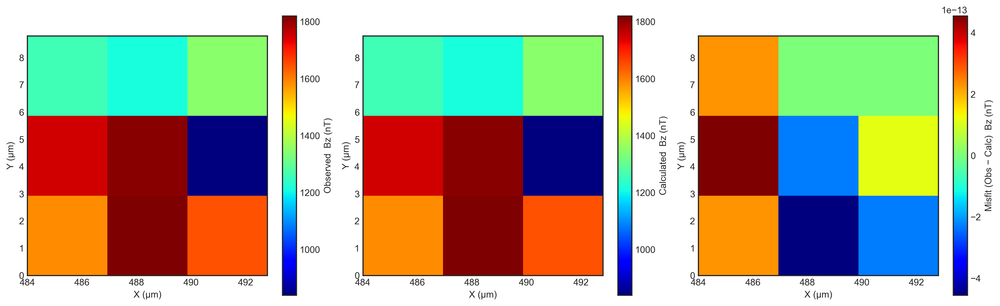

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_001\Blob_001_misfit.png

Processing Blob_002


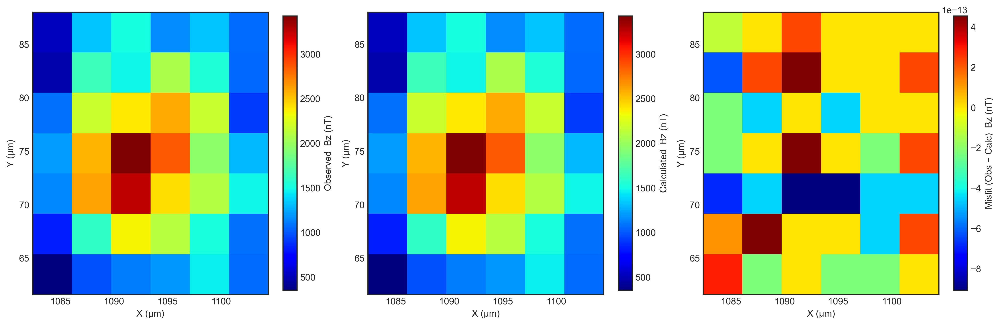

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_002\Blob_002_misfit.png

Processing Blob_003


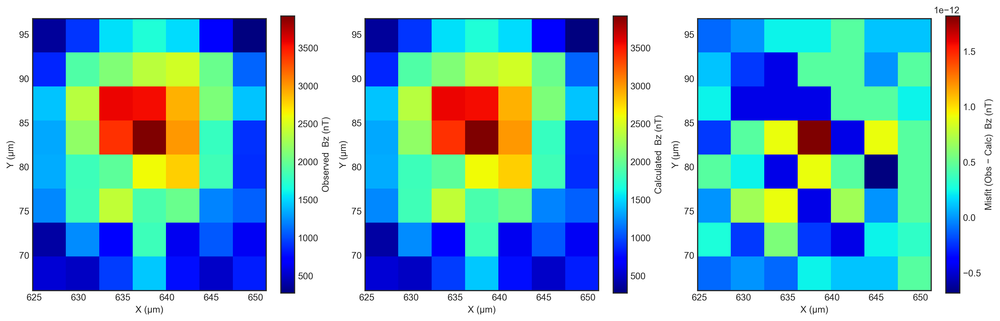

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_003\Blob_003_misfit.png

Processing Blob_004


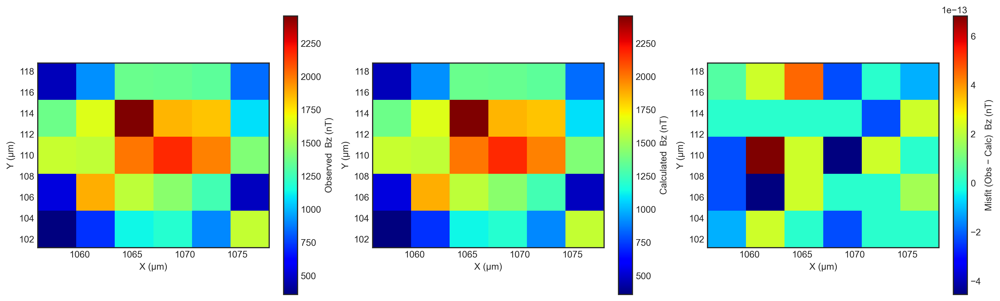

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_004\Blob_004_misfit.png

Processing Blob_005


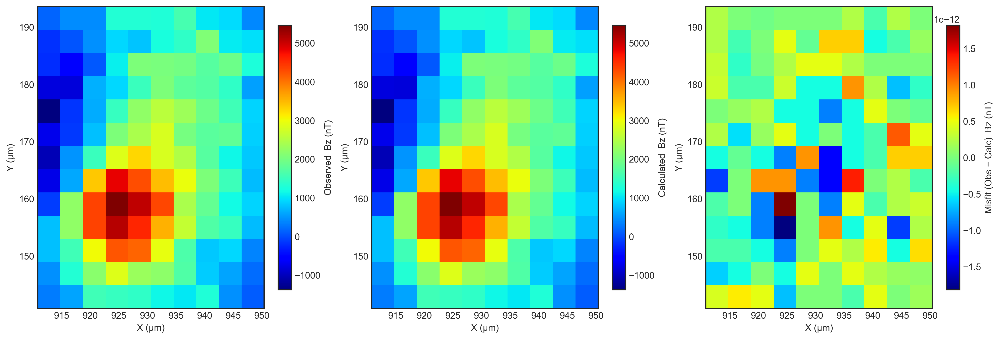

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_005\Blob_005_misfit.png

Processing Blob_006


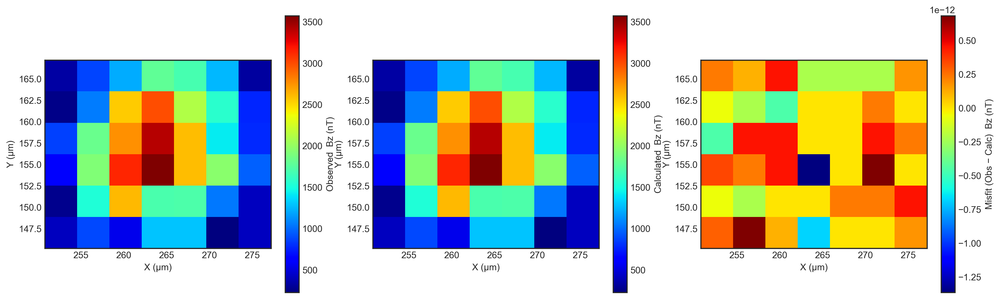

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_006\Blob_006_misfit.png

Processing Blob_007


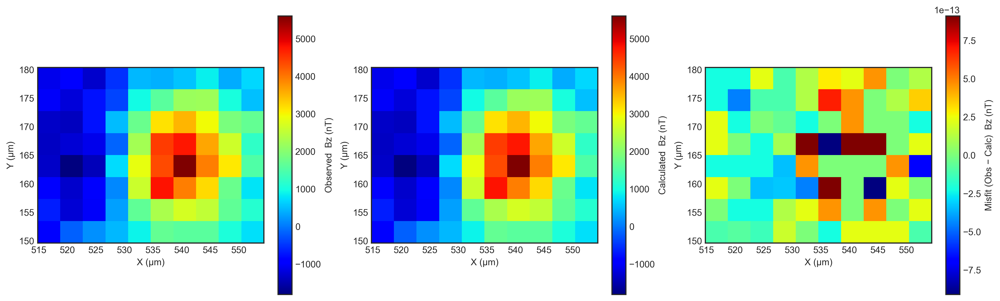

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_007\Blob_007_misfit.png

Processing Blob_008


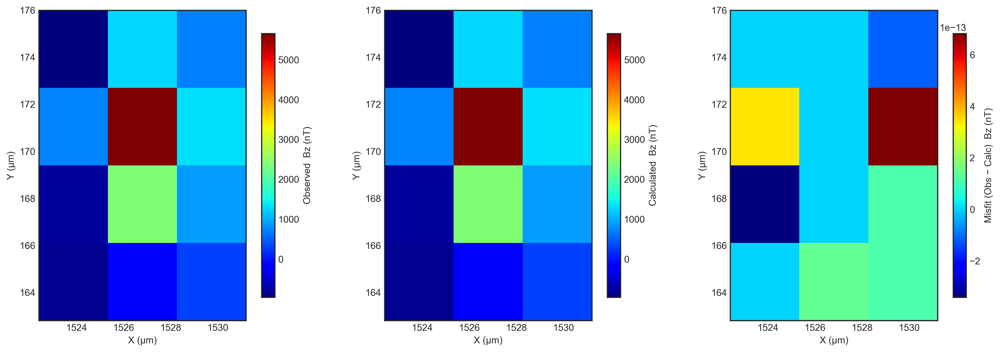

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_008\Blob_008_misfit.png

Processing Blob_009


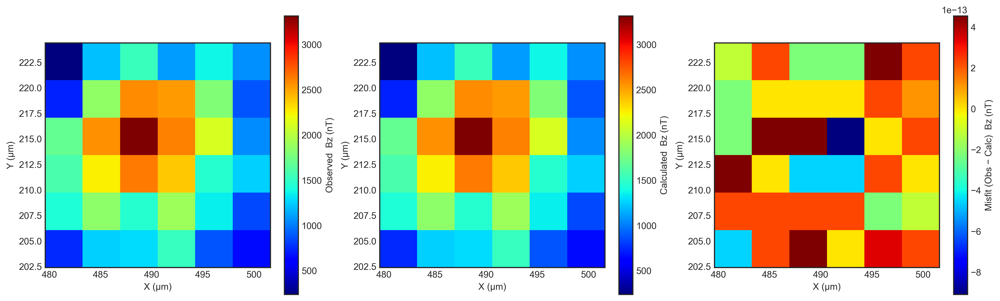

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_009\Blob_009_misfit.png

Processing Blob_010


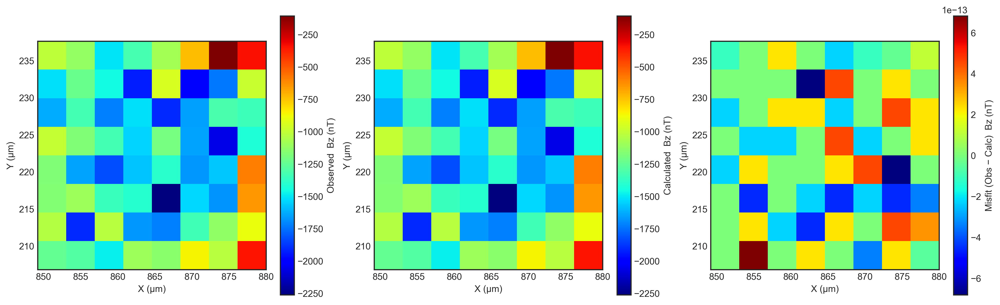

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_010\Blob_010_misfit.png

Processing Blob_011


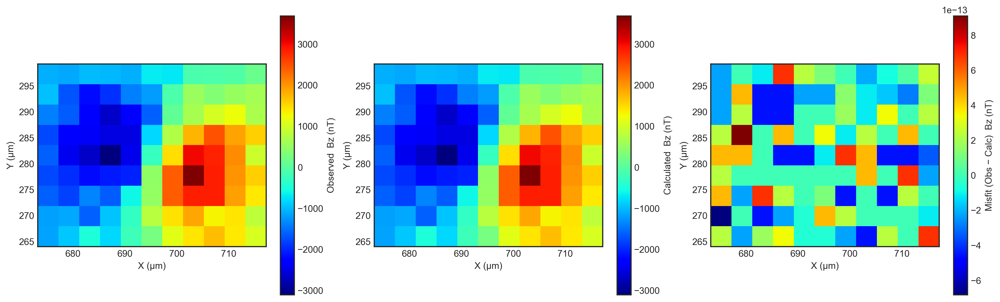

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_011\Blob_011_misfit.png

Processing Blob_012


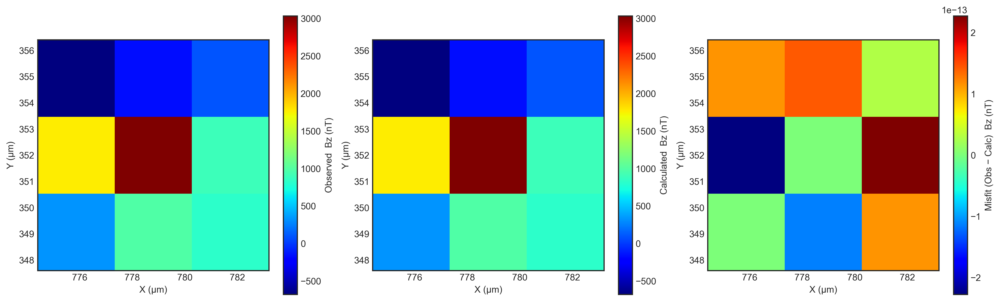

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_012\Blob_012_misfit.png

Processing Blob_013


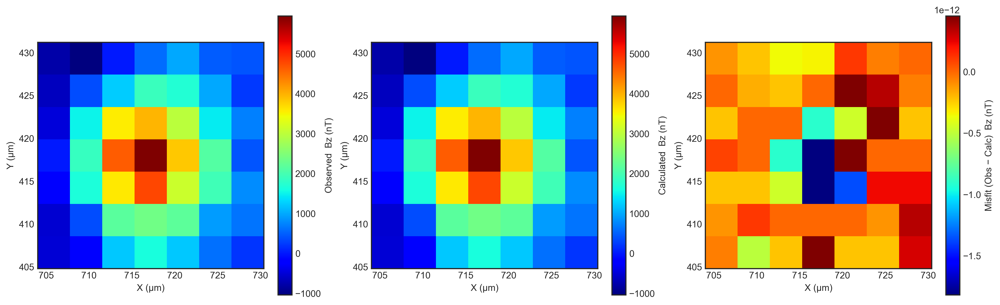

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_013\Blob_013_misfit.png

Processing Blob_014


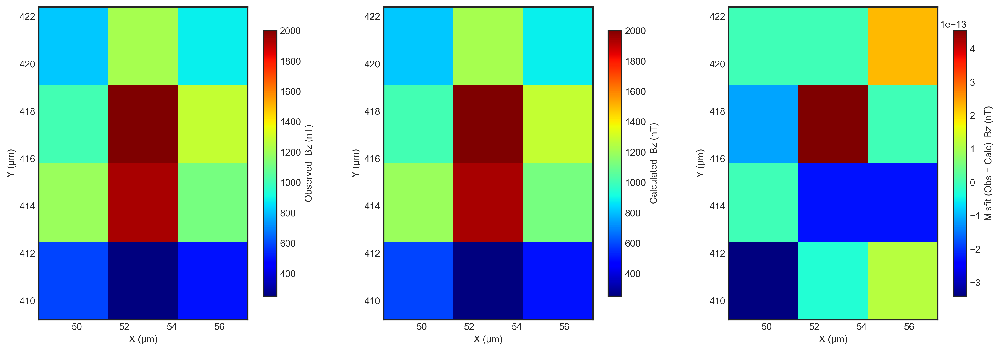

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_014\Blob_014_misfit.png

Processing Blob_015


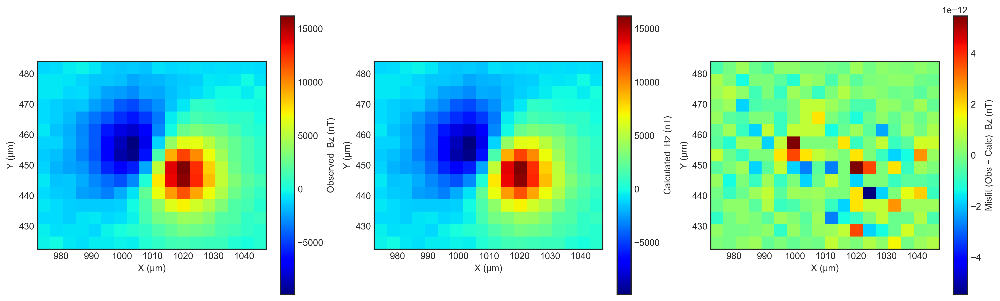

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_015\Blob_015_misfit.png

Processing Blob_016


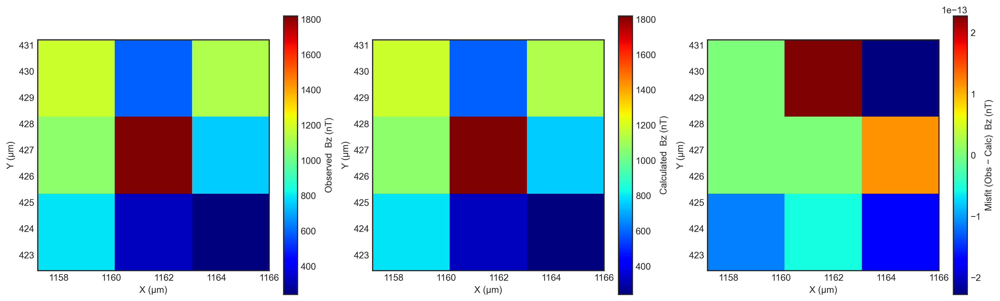

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_016\Blob_016_misfit.png

Processing Blob_017


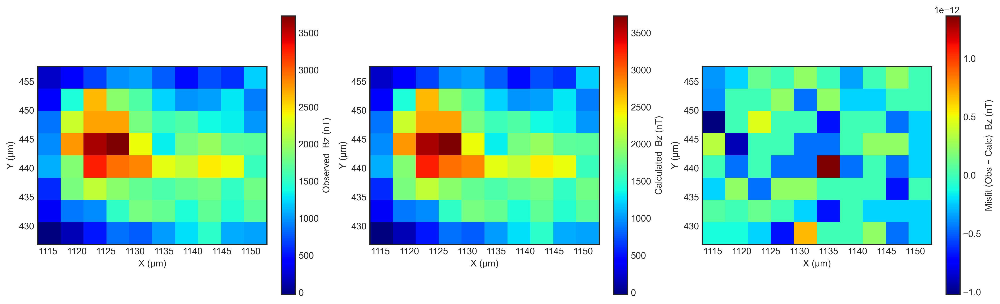

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_017\Blob_017_misfit.png

Processing Blob_018


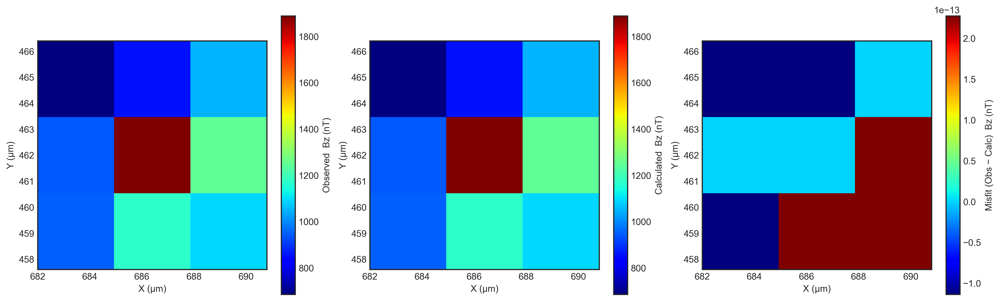

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_018\Blob_018_misfit.png

Processing Blob_019


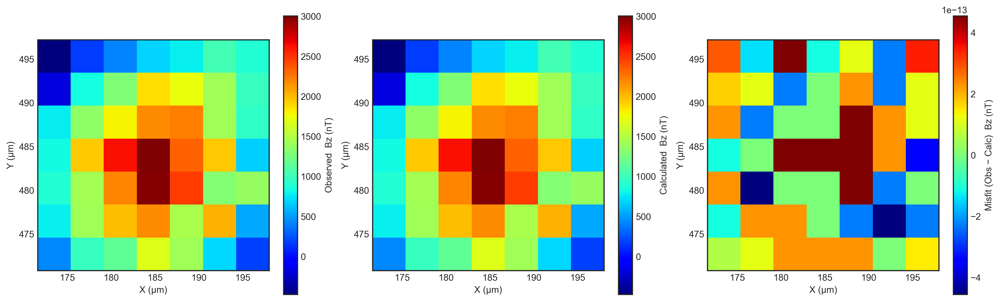

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_019\Blob_019_misfit.png

Processing Blob_020


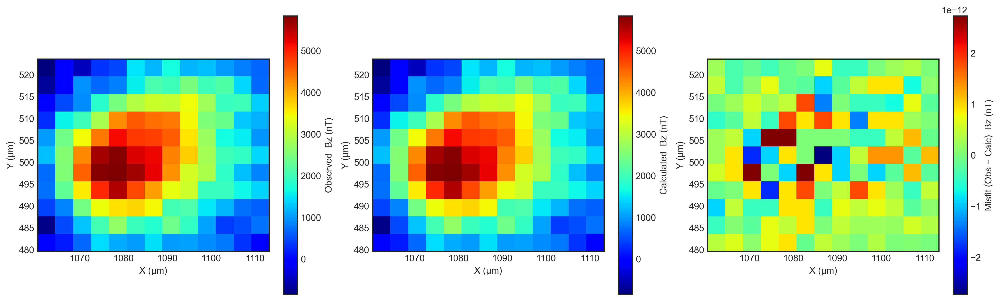

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_020\Blob_020_misfit.png

Processing Blob_021


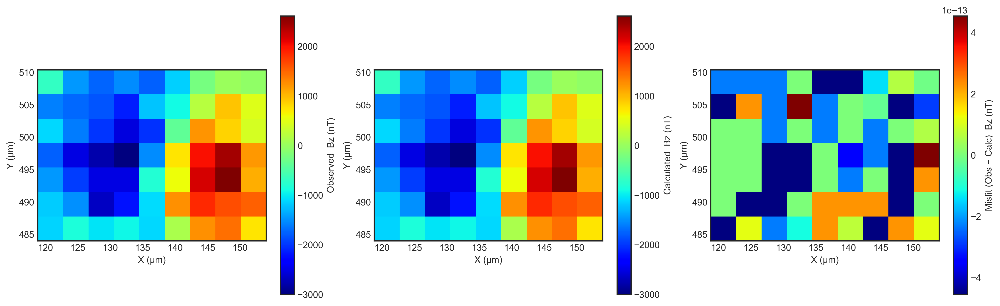

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_021\Blob_021_misfit.png

Processing Blob_022


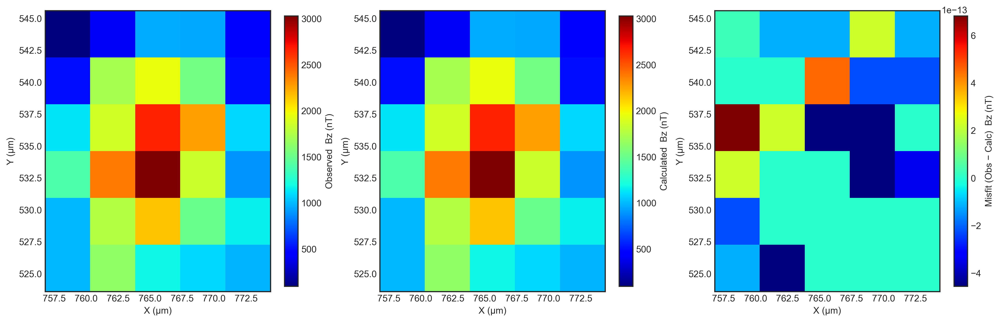

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_022\Blob_022_misfit.png

Processing Blob_023


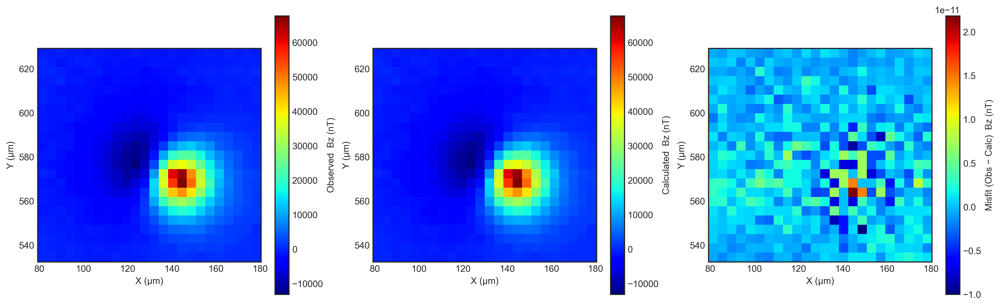

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_023\Blob_023_misfit.png

Processing Blob_024


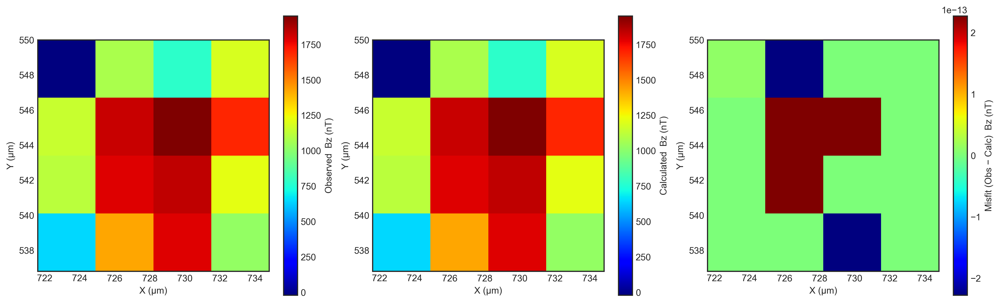

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_024\Blob_024_misfit.png

Processing Blob_025


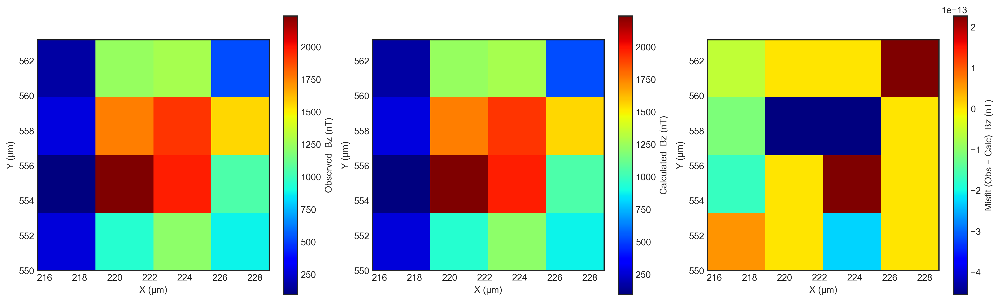

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_025\Blob_025_misfit.png

Processing Blob_026


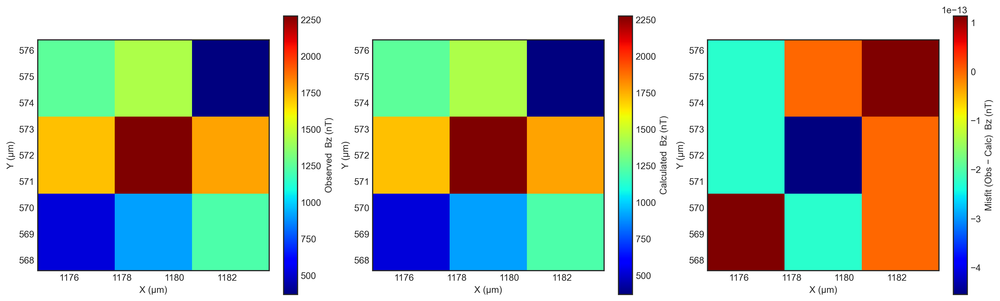

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_026\Blob_026_misfit.png

Processing Blob_027


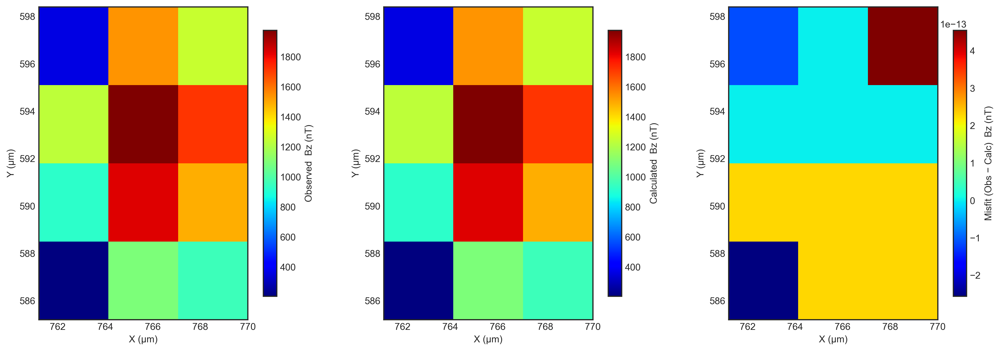

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_027\Blob_027_misfit.png

Processing Blob_028


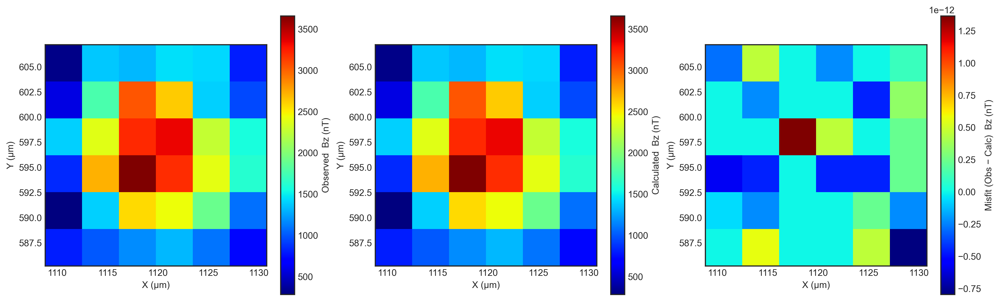

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_028\Blob_028_misfit.png

Processing Blob_029


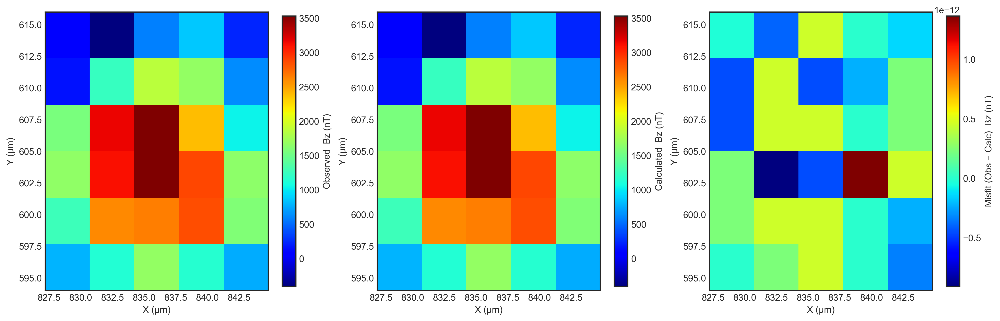

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_029\Blob_029_misfit.png

Processing Blob_030


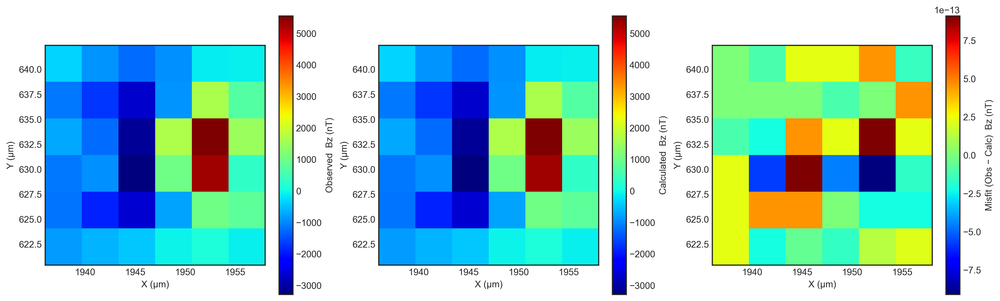

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_030\Blob_030_misfit.png

Processing Blob_031


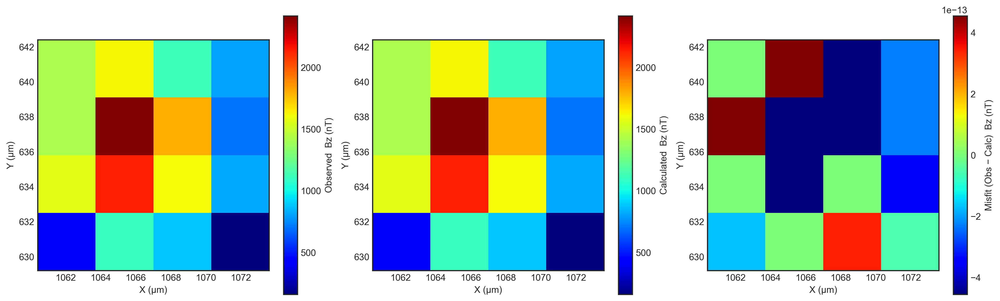

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_031\Blob_031_misfit.png

Processing Blob_032


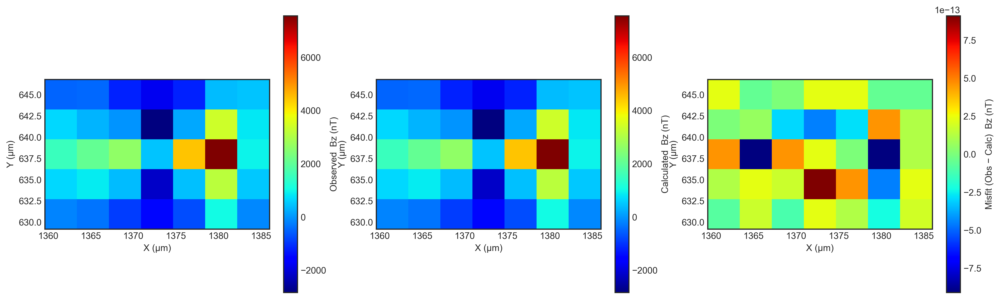

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_032\Blob_032_misfit.png

Processing Blob_033


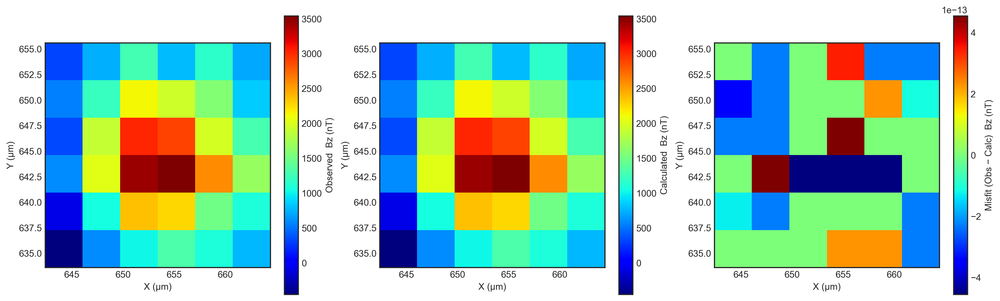

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_033\Blob_033_misfit.png

Processing Blob_034


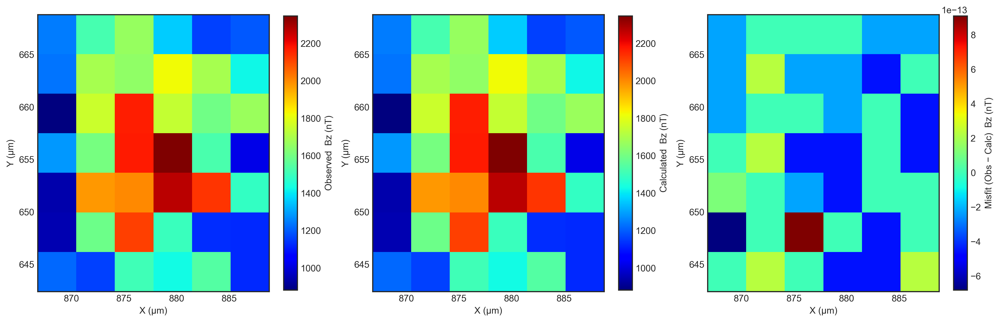

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_034\Blob_034_misfit.png

Processing Blob_035


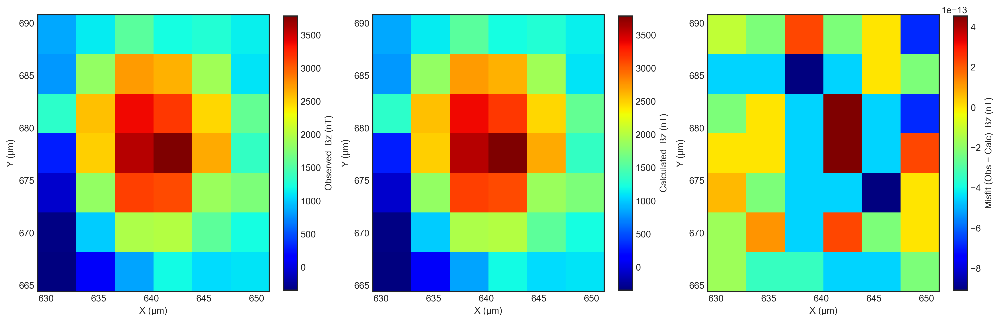

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_035\Blob_035_misfit.png

Processing Blob_036


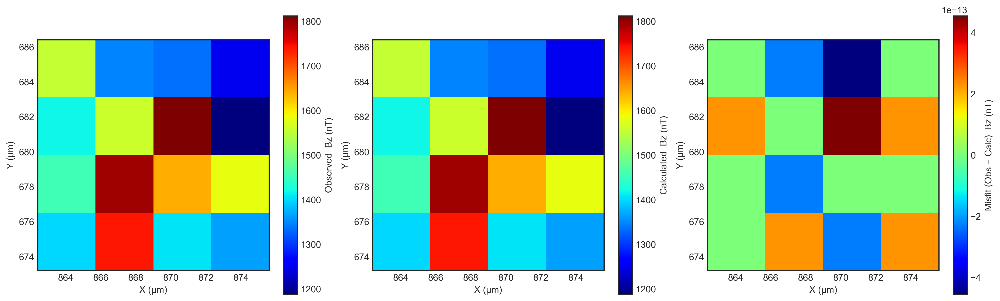

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_036\Blob_036_misfit.png

Processing Blob_037


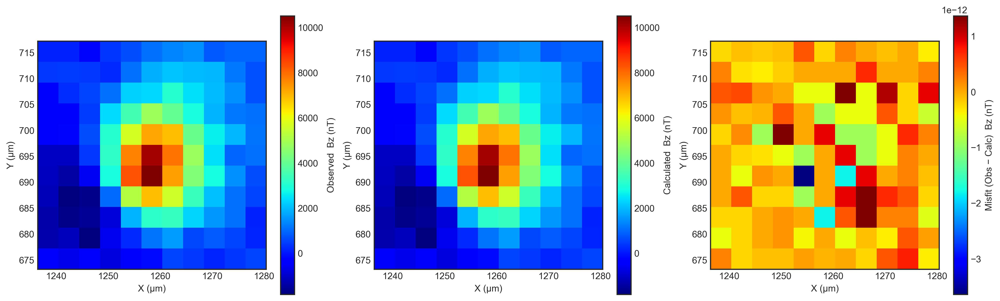

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_037\Blob_037_misfit.png

Processing Blob_038


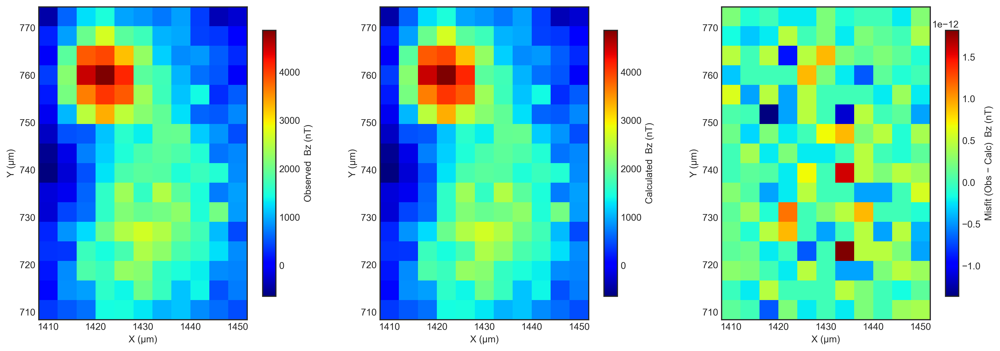

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_038\Blob_038_misfit.png

Processing Blob_039


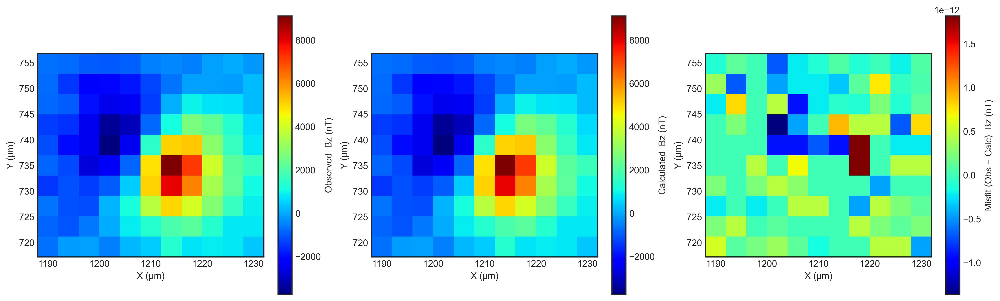

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_039\Blob_039_misfit.png

Processing Blob_040


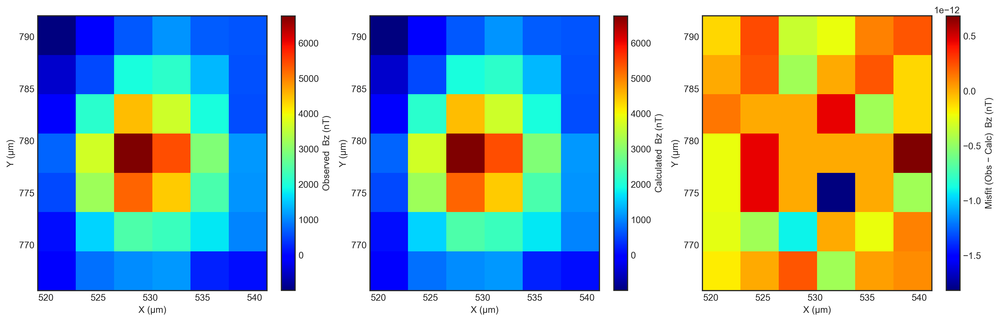

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_040\Blob_040_misfit.png

Processing Blob_041


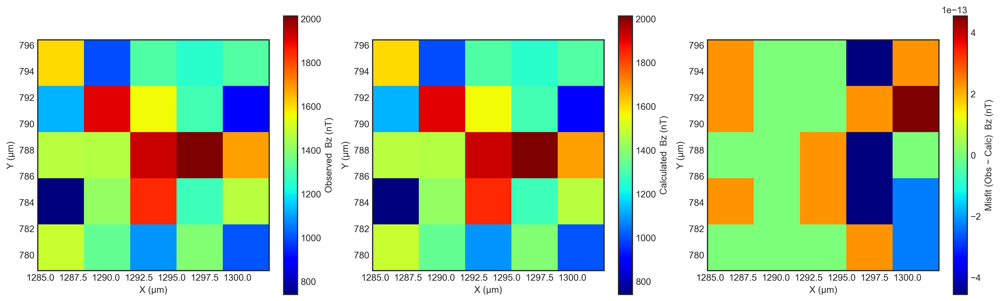

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_041\Blob_041_misfit.png

Processing Blob_042


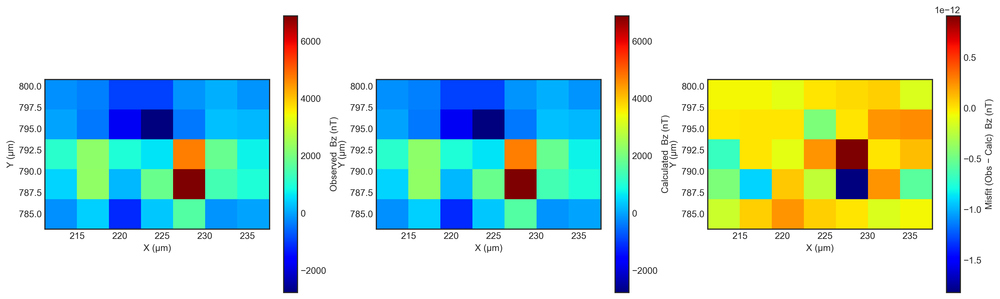

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_042\Blob_042_misfit.png

Processing Blob_043


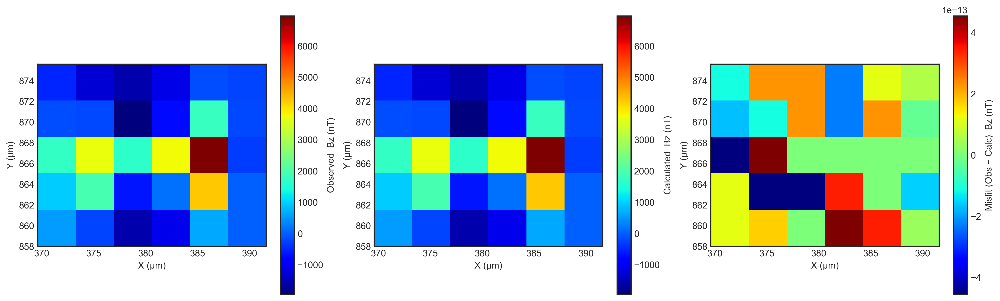

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_043\Blob_043_misfit.png

Processing Blob_044


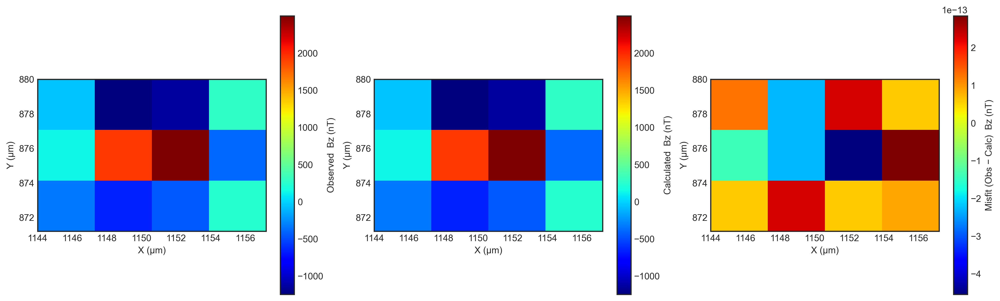

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_044\Blob_044_misfit.png

Processing Blob_045


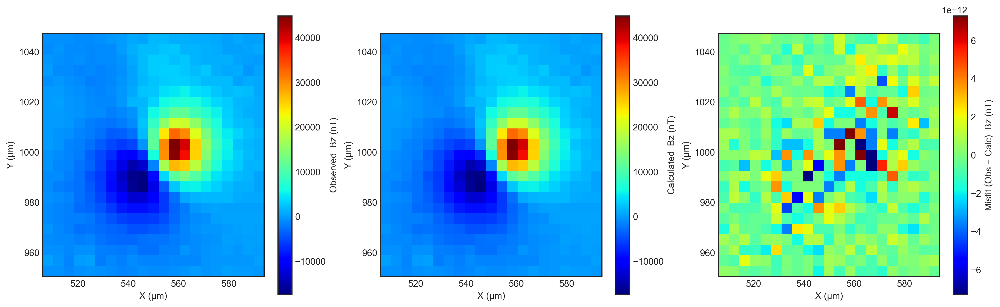

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_045\Blob_045_misfit.png

Processing Blob_046


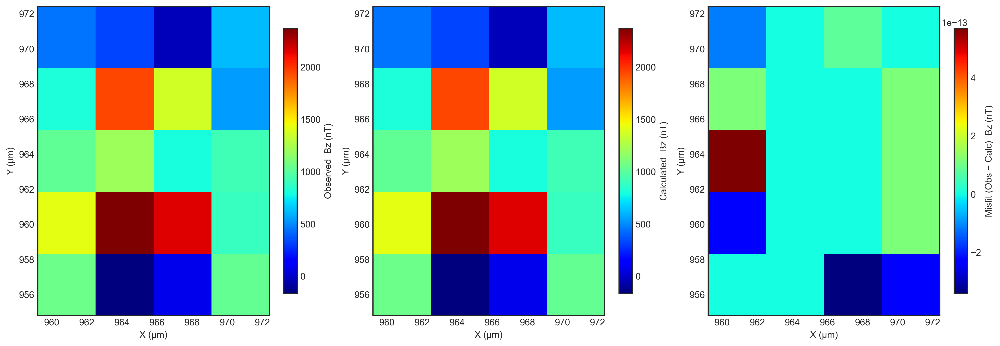

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_046\Blob_046_misfit.png

Processing Blob_047


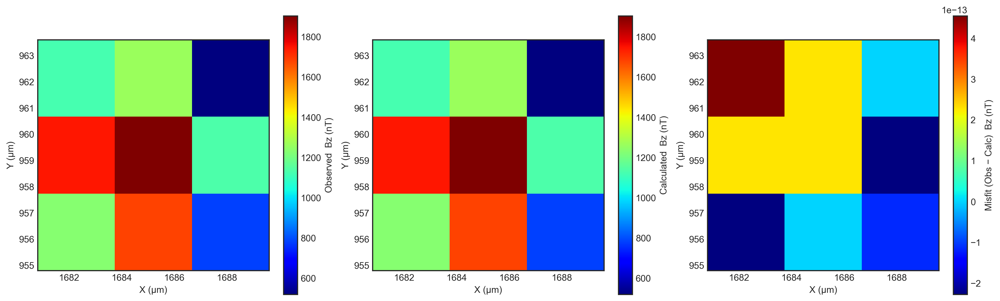

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_047\Blob_047_misfit.png

Processing Blob_048


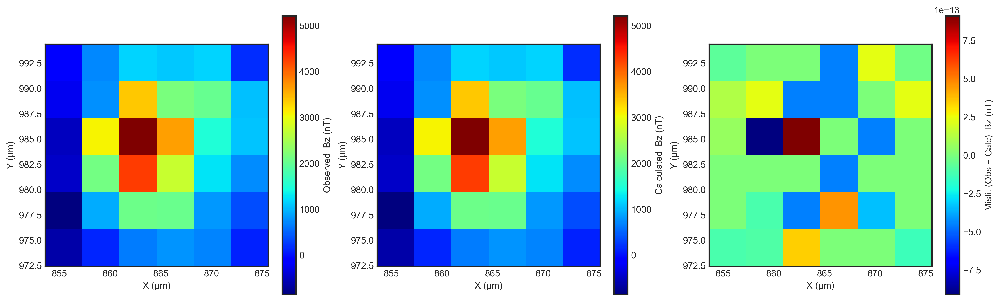

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_048\Blob_048_misfit.png

Processing Blob_049


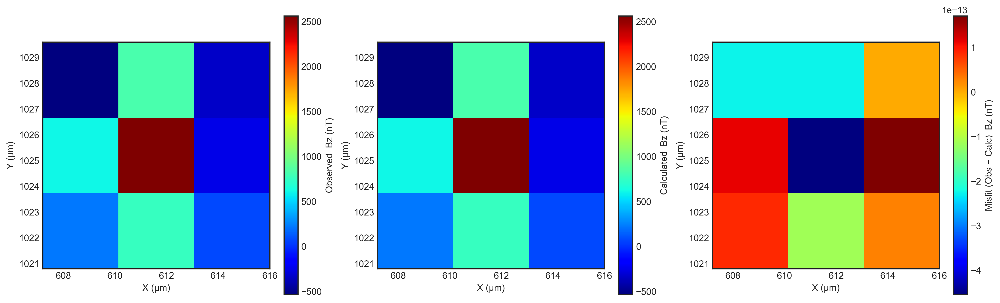

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_049\Blob_049_misfit.png

Processing Blob_050


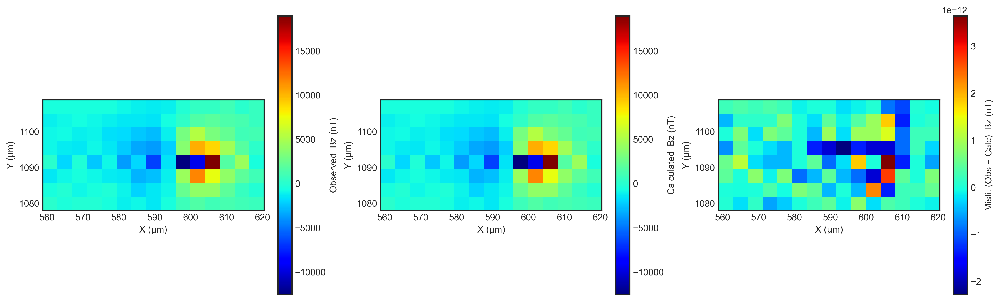

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_050\Blob_050_misfit.png

Processing Blob_051


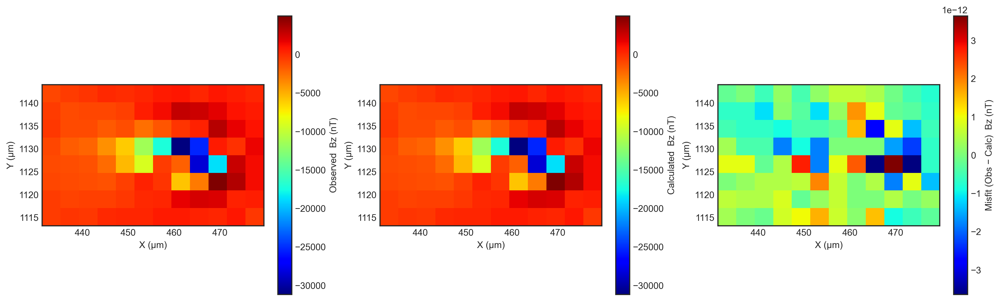

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_051\Blob_051_misfit.png

Processing Blob_052


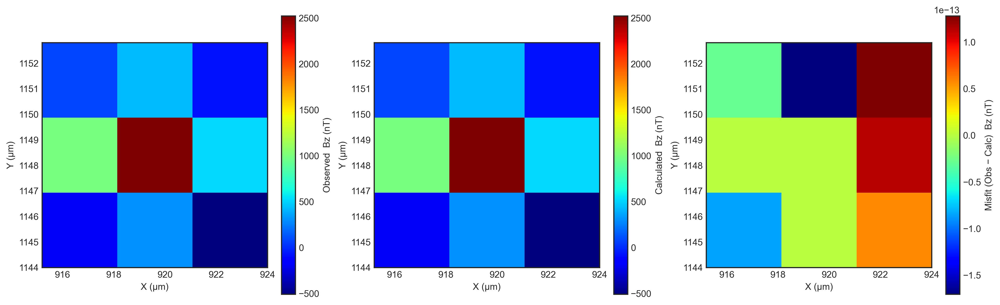

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_052\Blob_052_misfit.png

Processing Blob_053


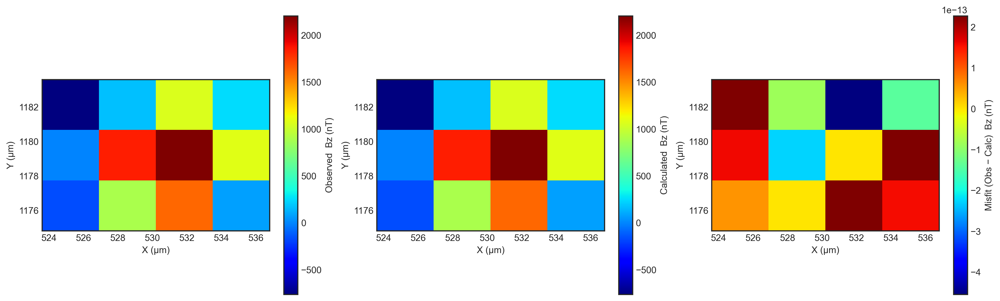

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_053\Blob_053_misfit.png

Processing Blob_054


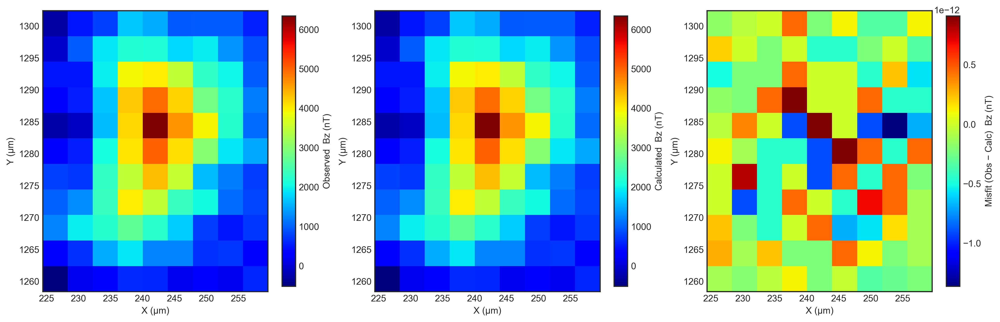

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_054\Blob_054_misfit.png

Processing Blob_055


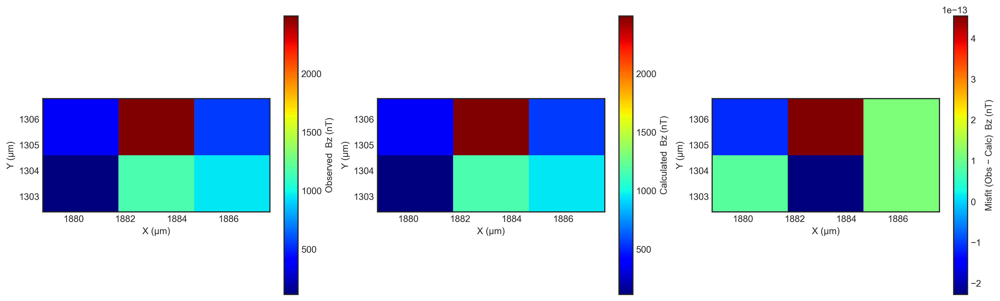

   Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_055\Blob_055_misfit.png

All blob misfit plots done.


In [13]:


# ------------------------------------------------
# Root folder containing Blob_XXX subfolders
# ------------------------------------------------
root_out = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Tomofast_Output_Blobs")

# ------------------------------------------------
# Helpers
# ------------------------------------------------
def load_field_table(path, names=("x", "y", "z", "value")):
   # return pd.read_csv(path, delim_whitespace=True, names=list(names))
    return pd.read_csv(path, sep=r"\s+", names=list(names)) #alternative if error
    
def clean_df(df):
    df["x"] = pd.to_numeric(df["x"], errors="coerce")
    df["y"] = pd.to_numeric(df["y"], errors="coerce")
    df["value"] = pd.to_numeric(df["value"], errors="coerce")
    df = df.dropna(subset=["x", "y", "value"])
    df = df[np.isfinite(df["x"]) & np.isfinite(df["y"]) & np.isfinite(df["value"])]
    return df

def df_to_grid(df):
    xs = np.sort(df["x"].unique())
    ys = np.sort(df["y"].unique())
    if xs.size == 0 or ys.size == 0:
        return None, None, None
    grid = df.pivot_table(index="y", columns="x", values="value")
    grid = grid.reindex(index=ys, columns=xs)
    return grid.values, xs, ys

# ------------------------------------------------
# Loop over blobs
# ------------------------------------------------
blob_dirs = sorted(d for d in os.listdir(root_out) if d.startswith("Blob_"))

print("Found blobs:", blob_dirs)

for blob in blob_dirs:
    print(f"\nProcessing {blob}")

    data_dir = os.path.join(root_out, blob, blob, "data")

    obs_file    = os.path.join(data_dir, "mag_observed_data.txt")
    calc_file   = os.path.join(data_dir, "mag_calc_final_data.txt")
    misfit_file = os.path.join(data_dir, "mag_misfit_final_data.txt")

    # check files exist (skip blob if any missing)
    missing = False
    for f in [obs_file, calc_file, misfit_file]:
        if not os.path.exists(f):
            print("   Missing:", f)
            missing = True
    if missing:
        continue

    # load + clean
    obs_df    = clean_df(load_field_table(obs_file))
    calc_df   = clean_df(load_field_table(calc_file))
    misfit_df = clean_df(load_field_table(misfit_file))

    if obs_df.empty or calc_df.empty or misfit_df.empty:
        print(f"   Empty/invalid data after cleaning for {blob}, skipping.")
        continue

    # grid
    obs_grid, xs, ys      = df_to_grid(obs_df)
    calc_grid, xs2, ys2   = df_to_grid(calc_df)
    misfit_grid, xs3, ys3 = df_to_grid(misfit_df)

    if obs_grid is None or calc_grid is None or misfit_grid is None:
        print(f"   No valid grid for {blob}, skipping.")
        continue

    # use observed grid coords for extent (paper axes in Mm)
    extent = [xs.min(), xs.max(), ys.min(), ys.max()]
    if not np.all(np.isfinite(extent)):
        print(f"   Bad extent (NaN/Inf) for {blob}, skipping.")
        continue

    # ------------------------------------------------
    # Plot 3-panel figure
    # ------------------------------------------------
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=300)

    for ax, grid, cbar_label in zip(
        axes,
        [obs_grid, calc_grid, misfit_grid],
        ["Observed", "Calculated", "Misfit (Obs − Calc)"]
    ):
        im = ax.imshow(
            grid,
            origin="lower",
            cmap="jet",
            extent=extent,
            aspect="equal"
        )

    
        ax.set_xlabel("X (µm)")
        ax.set_ylabel("Y (µm)")
        ax.margins(0)

        cbar = plt.colorbar(im, ax=ax, shrink=0.85)
        #cbar.set_label(cbar_label)
        cbar.set_label(f"{cbar_label}  Bz (nT)")


    plt.tight_layout(pad=0.2)

    # save per blob
    out_png = os.path.join(root_out, blob, f"{blob}_misfit.png")
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()

    print(f"   Saved: {out_png}")

print("\nAll blob misfit plots done.")


In [14]:
# Print Final Data Costs

root_dir = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Tomofast_Output_Blobs")

results = []

# loop through Blob folders
for blob in sorted(os.listdir(root_dir)):
    if not blob.startswith("Blob_"):
        continue

    log_file = os.path.join(root_dir, blob, f"QDM_log_{blob}.txt")

    if not os.path.exists(log_file):
        continue

    last_cost = None

    with open(log_file, "r") as f:
        for line in f:
            if "data cost (new)" in line:
                # extract scientific number
                match = re.search(r"[-+]?\d+\.\d+E[-+]?\d+", line)
                if match:
                    last_cost = float(match.group())

    if last_cost is not None:
        results.append({
            "Blob": blob,
            "Final_Data_Cost": last_cost
        })

# print table
df = pd.DataFrame(results).sort_values("Blob").reset_index(drop=True)
pd.set_option("display.float_format", lambda x: f"{x:.6e}")

print("\n=== Final Data Cost (Last Iteration) ===")
print(df)


=== Final Data Cost (Last Iteration) ===
        Blob  Final_Data_Cost
0   Blob_001     1.760424e-16
1   Blob_002     1.944157e-16
2   Blob_003     2.669428e-16
3   Blob_004     1.654983e-16
4   Blob_005     2.672082e-16
5   Blob_006     2.138444e-16
6   Blob_007     1.700192e-16
7   Blob_008     1.294319e-16
8   Blob_009     1.800045e-16
9   Blob_010     1.972578e-16
10  Blob_011     1.911785e-16
11  Blob_012     1.031038e-16
12  Blob_013     2.472243e-16
13  Blob_014     1.740654e-16
14  Blob_015     2.718613e-16
15  Blob_016     1.354262e-16
16  Blob_017     2.108595e-16
17  Blob_018     1.282863e-16
18  Blob_019     1.617948e-16
19  Blob_020     3.190590e-16
20  Blob_021     1.722816e-16
21  Blob_022     1.675199e-16
22  Blob_023     2.696807e-16
23  Blob_024     9.207771e-17
24  Blob_025     1.541907e-16
25  Blob_026     1.485393e-16
26  Blob_027     1.609795e-16
27  Blob_028     1.967543e-16
28  Blob_029     2.306729e-16
29  Blob_030     1.969836e-16
30  Blob_031     2.295163e-1

### 5. 3D grains detection

this line uses scipy yo detect the 3d grains models based on cell connectivity and amplitude thresholds, calculate mean results per grain, and save 3d plots
* User: Attention: change cell size for mean magnitude (dx,dy,dz)

In [15]:
# grains extraction

# ------------------------------------------------------------
#  PATHS 
# ------------------------------------------------------------
# Root folder that contains Blob_001, Blob_002, ...
BLOB_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered","Tomofast_Output_Blobs")

# Folder that contains Meshgrid_Blob_001.txt, Meshgrid_Blob_002.txt, ...
MESH_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered","Blob_Meshgrids")

# thresholds
threshold_list = np.arange(0.1, 1.0, 0.1)  # 0.1..0.9

# 26-connectivity in 3D
structure = generate_binary_structure(3, 3)

# ------------------------------------------------------------
# LOOP BLOBS
# ------------------------------------------------------------
blob_dirs = sorted(
    d for d in os.listdir(BLOB_ROOT)
    if d.startswith("Blob_") and os.path.isdir(os.path.join(BLOB_ROOT, d))
)

print("Found blobs:", blob_dirs)

for blob in blob_dirs:
    print("\n===================================================")
    print("Processing", blob)
    print("===================================================")

    # Your structure: Blob_001/Blob_001/model/...
    model_file = os.path.join(BLOB_ROOT, blob, blob, "model", "mag_final_model_full.txt")
    mesh_file  = os.path.join(MESH_ROOT, f"Meshgrid_Blob_{blob.split('_')[1]}.txt")  # uses 001 etc.

    if not os.path.exists(model_file):
        print("   Missing model:", model_file)
        continue
    if not os.path.exists(mesh_file):
        print("   Missing mesh :", mesh_file)
        continue

    # ------------------------------------------------------------
    # 1) Load magnetization model
    # ------------------------------------------------------------
    data = np.genfromtxt(model_file, skip_header=1)

    # Tomofast model file expected columns: Mx My Mz ...
    Mx = data[:, 0]
    My = data[:, 1]
    Mz = data[:, 2]

    mag = np.sqrt(Mx**2 + My**2 + Mz**2)

    # ------------------------------------------------------------
    # 2) Load mesh (cell bounds) -> centers
    # ------------------------------------------------------------
    mesh = np.genfromtxt(mesh_file, skip_header=1)

    x_centers = (mesh[:, 0] + mesh[:, 1]) / 2
    y_centers = (mesh[:, 2] + mesh[:, 3]) / 2
    z_centers = (mesh[:, 4] + mesh[:, 5]) / 2

    # Infer nx, ny, nz from mesh size (IMPORTANT for per-blob)
    n_cells = mesh.shape[0]
    # For uniform grids: n_cells = nx * ny * nz

    nx = len(np.unique(x_centers))
    ny = len(np.unique(y_centers))
    nz = int(n_cells / (nx * ny))

    if nx * ny * nz != n_cells:
        print(f"   Cannot infer nx,ny,nz correctly for {blob}.")
        print(f"     nx*ny*nz={nx*ny*nz} but n_cells={n_cells}")
        continue

    print(f"  Mesh dims inferred: nx={nx}, ny={ny}, nz={nz}")

    # ------------------------------------------------------------
    # LOOP THRESHOLDS
    # ------------------------------------------------------------
    for threshold_per in threshold_list:
        print(f"   -> threshold = {threshold_per:.1f}")

        threshold = threshold_per * mag.max()
        mask = mag > threshold

        # reshape into (nz, ny, nx) like your original script
        mask_3d = mask.reshape((nz, ny, nx))

        labeled_grains_3d, num_grains = label(mask_3d, structure=structure)
        print(f"      grains detected: {num_grains}")

        # dataframe
        df = pd.DataFrame({
            "X": x_centers.ravel(),
            "Y": y_centers.ravel(),
            "Z": -1 * z_centers.ravel(),     # keep your sign convention
            "GrainID": labeled_grains_3d.ravel(),
            "Mx": Mx,
            "My": My,
            "Mz": Mz
        })

        df = df[df["GrainID"] != 0]

        # save inside each blob folder
        out_folder = os.path.join(BLOB_ROOT, blob, blob, "Grains_detection")
        os.makedirs(out_folder, exist_ok=True)

        csv_file = os.path.join(out_folder, f"grain_labels_{threshold_per:.1f}.csv")
        df.to_csv(csv_file, index=False)

        print(f"      saved: {csv_file}")

print("\nDONE.")


Found blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005', 'Blob_006', 'Blob_007', 'Blob_008', 'Blob_009', 'Blob_010', 'Blob_011', 'Blob_012', 'Blob_013', 'Blob_014', 'Blob_015', 'Blob_016', 'Blob_017', 'Blob_018', 'Blob_019', 'Blob_020', 'Blob_021', 'Blob_022', 'Blob_023', 'Blob_024', 'Blob_025', 'Blob_026', 'Blob_027', 'Blob_028', 'Blob_029', 'Blob_030', 'Blob_031', 'Blob_032', 'Blob_033', 'Blob_034', 'Blob_035', 'Blob_036', 'Blob_037', 'Blob_038', 'Blob_039', 'Blob_040', 'Blob_041', 'Blob_042', 'Blob_043', 'Blob_044', 'Blob_045', 'Blob_046', 'Blob_047', 'Blob_048', 'Blob_049', 'Blob_050', 'Blob_051', 'Blob_052', 'Blob_053', 'Blob_054', 'Blob_055']

Processing Blob_001
  Mesh dims inferred: nx=13, ny=13, nz=60
   -> threshold = 0.1
      grains detected: 1
      saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_001\Blob_001\Grains_detection\grain_labels_0.1.csv
   -> threshold = 0.2
      grains detected: 1
  

In [16]:
# grains extraction largest picking (same as above but this keeps only the largest grains per blob) useful for flitering compression artifacts 

# ------------------------------------------------------------
#   PATHS 
# ------------------------------------------------------------
BLOB_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Tomofast_Output_Blobs")
MESH_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Blob_Meshgrids")

threshold_list = np.arange(0.1, 1.0, 0.1)  # 0.1..0.9

# 26-connectivity in 3D
structure = generate_binary_structure(3, 3)

# ------------------------------------------------------------
# LOOP BLOBS
# ------------------------------------------------------------
blob_dirs = sorted(
    d for d in os.listdir(BLOB_ROOT)
    if d.startswith("Blob_") and os.path.isdir(os.path.join(BLOB_ROOT, d))
)

print("Found blobs:", blob_dirs)

for blob in blob_dirs:
    print("\n===================================================")
    print("Processing", blob)
    print("===================================================")

    # Your structure: Blob_001/Blob_001/model/...
    model_file = os.path.join(BLOB_ROOT, blob, blob, "model", "mag_final_model_full.txt")
    mesh_file  = os.path.join(MESH_ROOT, f"Meshgrid_Blob_{blob.split('_')[1]}.txt")  # uses 001 etc.

    if not os.path.exists(model_file):
        print("   Missing model:", model_file)
        continue
    if not os.path.exists(mesh_file):
        print("   Missing mesh :", mesh_file)
        continue

    # Output folder for this blob
    out_folder = os.path.join(BLOB_ROOT, blob, blob, "Grains_detection")
    os.makedirs(out_folder, exist_ok=True)

    # Will store largest grain info per threshold (one row per threshold)
    blob_largest_summary = []

    # ------------------------------------------------------------
    # 1) Load magnetization model
    # ------------------------------------------------------------
    data = np.genfromtxt(model_file, skip_header=1)

    # Tomofast model file expected columns: Mx My Mz ...
    Mx = data[:, 0]
    My = data[:, 1]
    Mz = data[:, 2]

    mag = np.sqrt(Mx**2 + My**2 + Mz**2)

    # ------------------------------------------------------------
    # 2) Load mesh (cell bounds) -> centers
    # ------------------------------------------------------------
    mesh = np.genfromtxt(mesh_file, skip_header=1)

    x_centers = (mesh[:, 0] + mesh[:, 1]) / 2
    y_centers = (mesh[:, 2] + mesh[:, 3]) / 2
    z_centers = (mesh[:, 4] + mesh[:, 5]) / 2

    # Infer nx, ny, nz from mesh size
    n_cells = mesh.shape[0]
    nx = len(np.unique(x_centers))
    ny = len(np.unique(y_centers))
    nz = int(n_cells / (nx * ny))

    if nx * ny * nz != n_cells:
        print(f"   Cannot infer nx,ny,nz correctly for {blob}.")
        print(f"     nx*ny*nz={nx*ny*nz} but n_cells={n_cells}")
        continue

    print(f"  Mesh dims inferred: nx={nx}, ny={ny}, nz={nz}")

    # ------------------------------------------------------------
    # LOOP THRESHOLDS
    # ------------------------------------------------------------
    for threshold_per in threshold_list:
        thr_str = f"{threshold_per:.1f}"
        print(f"   -> threshold = {thr_str}")

        threshold = threshold_per * mag.max()
        mask = mag > threshold

        # reshape into (nz, ny, nx)
        mask_3d = mask.reshape((nz, ny, nx))

        labeled_grains_3d, num_grains = label(mask_3d, structure=structure)
        print(f"      grains detected: {num_grains}")

        # Build voxel table for ALL grains
        df = pd.DataFrame({
            "X": x_centers.ravel(),
            "Y": y_centers.ravel(),
            "Z": -1 * z_centers.ravel(),     # keep your sign convention
            "GrainID": labeled_grains_3d.ravel(),
            "Mx": Mx,
            "My": My,
            "Mz": Mz
        })

        # remove background
        df = df[df["GrainID"] != 0]

        # --- Save original labels file ---
        csv_file = os.path.join(out_folder, f"grain_labels_{thr_str}.csv")
        df.to_csv(csv_file, index=False)
        print(f"       saved: {csv_file}")

        # --- If no grains, skip largest outputs ---
        if df.empty:
            print("      (no voxels above threshold) skip largest")
            continue

        # --- Pick largest grain by voxel count ---
        # counts is a Series: index=GrainID, value=num voxels
        counts = df["GrainID"].value_counts()
        largest_id = int(counts.idxmax())
        largest_nvox = int(counts.max())

        df_largest = df[df["GrainID"] == largest_id].copy()

        largest_csv = os.path.join(out_folder, f"grain_labels_largest_{thr_str}.csv")
        df_largest.to_csv(largest_csv, index=False)
        print(f"       saved largest: {largest_csv} (GrainID={largest_id}, Num_Voxels={largest_nvox})")

        # store summary row for this threshold
        blob_largest_summary.append({
            "Blob": blob,
            "Threshold": float(threshold_per),
            "Threshold_abs": float(threshold),   # threshold in mag units (same as mag)
            "Largest_GrainID": largest_id,
            "Num_Voxels": largest_nvox
        })

    # ------------------------------------------------------------
    # Save per-blob ALL-threshold summary
    # ------------------------------------------------------------
    if blob_largest_summary:
        summary_df = pd.DataFrame(blob_largest_summary).sort_values("Threshold")
        summary_path = os.path.join(out_folder, "grain_labels_largest_ALL.csv")
        summary_df.to_csv(summary_path, index=False)
        print(f"\n   saved blob largest summary: {summary_path}")
    else:
        print("\n  (no largest summary rows written for this blob)")

print("\nDONE.")


Found blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005', 'Blob_006', 'Blob_007', 'Blob_008', 'Blob_009', 'Blob_010', 'Blob_011', 'Blob_012', 'Blob_013', 'Blob_014', 'Blob_015', 'Blob_016', 'Blob_017', 'Blob_018', 'Blob_019', 'Blob_020', 'Blob_021', 'Blob_022', 'Blob_023', 'Blob_024', 'Blob_025', 'Blob_026', 'Blob_027', 'Blob_028', 'Blob_029', 'Blob_030', 'Blob_031', 'Blob_032', 'Blob_033', 'Blob_034', 'Blob_035', 'Blob_036', 'Blob_037', 'Blob_038', 'Blob_039', 'Blob_040', 'Blob_041', 'Blob_042', 'Blob_043', 'Blob_044', 'Blob_045', 'Blob_046', 'Blob_047', 'Blob_048', 'Blob_049', 'Blob_050', 'Blob_051', 'Blob_052', 'Blob_053', 'Blob_054', 'Blob_055']

Processing Blob_001
  Mesh dims inferred: nx=13, ny=13, nz=60
   -> threshold = 0.1
      grains detected: 1
       saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_001\Blob_001\Grains_detection\grain_labels_0.1.csv
       saved largest: D:\My_Work\Tomofast-x-µ\Wo

In [17]:
#3d grains plots (Use paraview for better 3d visualziations)


# ------------------------------------------------------------
#   PATHS
# ------------------------------------------------------------
# Root folder that contains Blob_001, Blob_002, ...
BLOB_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered","Tomofast_Output_Blobs")

# Folder that contains Meshgrid_Blob_001.txt, Meshgrid_Blob_002.txt, ...
MESH_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered","Blob_Meshgrids")

threshold_list = np.arange(0.1, 1.0, 0.1)  # 0.1 .. 0.9
structure = generate_binary_structure(3, 3)  # 26-connectivity

# ------------------------------------------------------------
# Find blobs
# ------------------------------------------------------------
blob_dirs = sorted(
    d for d in os.listdir(BLOB_ROOT)
    if d.startswith("Blob_") and os.path.isdir(os.path.join(BLOB_ROOT, d))
)

print("Found blobs:", blob_dirs)

# ------------------------------------------------------------
# LOOP BLOBS
# ------------------------------------------------------------
for blob in blob_dirs:
    print("\n===================================================")
    print("Processing", blob)
    print("===================================================")

    #  structure: Blob_001/Blob_001/model/mag_final_model_full.txt
    model_file = os.path.join(BLOB_ROOT, blob, blob, "model", "mag_final_model_full.txt")

    # Meshgrid_Blob_001.txt etc (blob number is "001")
    blob_num = blob.split("_")[1]
    mesh_file = os.path.join(MESH_ROOT, f"Meshgrid_Blob_{blob_num}.txt")

    if not os.path.exists(model_file):
        print("   Missing model:", model_file)
        continue
    if not os.path.exists(mesh_file):
        print("   Missing mesh :", mesh_file)
        continue

    # ------------------------------------------------------------
    # Load model (Mx, My, Mz)
    # ------------------------------------------------------------
    model = np.genfromtxt(model_file, skip_header=1)
    Mx = model[:, 0]
    My = model[:, 1]
    Mz = model[:, 2]
    mag = np.sqrt(Mx**2 + My**2 + Mz**2)

    # ------------------------------------------------------------
    # Load mesh -> centers
    # ------------------------------------------------------------
    mesh = np.genfromtxt(mesh_file, skip_header=1)
    x_centers = (mesh[:, 0] + mesh[:, 1]) / 2
    y_centers = (mesh[:, 2] + mesh[:, 3]) / 2
    z_centers = (mesh[:, 4] + mesh[:, 5]) / 2

    # Infer nx, ny, nz per blob 
    n_cells = mesh.shape[0]
    nx = len(np.unique(x_centers))
    ny = len(np.unique(y_centers))
    nz = int(n_cells / (nx * ny))

    if nx * ny * nz != n_cells:
        print(f"   Bad dims: nx*ny*nz={nx*ny*nz} but cells={n_cells}")
        continue

    print(f"  Mesh dims: nx={nx}, ny={ny}, nz={nz}")

    # Output folder inside each blob
    out_folder = os.path.join(BLOB_ROOT, blob, blob, "Grains_detection_3D")
    os.makedirs(out_folder, exist_ok=True)

    # ------------------------------------------------------------
    # LOOP THRESHOLDS
    # ------------------------------------------------------------
    for threshold_per in threshold_list:
        print(f"   -> threshold = {threshold_per:.1f}")

        threshold = threshold_per * mag.max()
        mask = mag > threshold
        mask_3d = mask.reshape((nz, ny, nx))

        labeled_grains_3d, num_grains = label(mask_3d, structure=structure)
        print(f"      grains detected: {num_grains}")

        df = pd.DataFrame({
            "X": x_centers,
            "Y": y_centers,
            "Z": -1 * z_centers,
            "GrainID": labeled_grains_3d.ravel(),
            "Mx": Mx,
            "My": My,
            "Mz": Mz
        })
        df = df[df["GrainID"] != 0]

        # If nothing to plot, skip
        if len(df) == 0:
            print("      (no points above threshold) skip plot")
            continue

        # ------------------------------------------------
        # 3D Plot (sample for speed)
        # ------------------------------------------------
        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection="3d")

        sample_df = df.sample(min(5000, len(df)), random_state=42)

        sc = ax.scatter(
            sample_df["X"],
            sample_df["Y"],
            sample_df["Z"],
            c=sample_df["GrainID"],
            cmap="turbo",
            s=5
        )

        ax.set_xlabel("X")
        ax.set_ylabel("Y")
        ax.set_zlabel("Z")
        ax.set_title(f"{blob} — 3D Grains (thr={threshold_per:.1f}, n={num_grains})")
        ax.invert_zaxis()

        plt.colorbar(sc, label="Grain ID")

        out_fig = os.path.join(out_folder, f"{blob}_grains_3D_{threshold_per:.1f}.png")
        plt.savefig(out_fig, dpi=300, bbox_inches="tight")
        plt.close(fig)

        print(f"      saved: {out_fig}")

print("\nDONE.")


Found blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005', 'Blob_006', 'Blob_007', 'Blob_008', 'Blob_009', 'Blob_010', 'Blob_011', 'Blob_012', 'Blob_013', 'Blob_014', 'Blob_015', 'Blob_016', 'Blob_017', 'Blob_018', 'Blob_019', 'Blob_020', 'Blob_021', 'Blob_022', 'Blob_023', 'Blob_024', 'Blob_025', 'Blob_026', 'Blob_027', 'Blob_028', 'Blob_029', 'Blob_030', 'Blob_031', 'Blob_032', 'Blob_033', 'Blob_034', 'Blob_035', 'Blob_036', 'Blob_037', 'Blob_038', 'Blob_039', 'Blob_040', 'Blob_041', 'Blob_042', 'Blob_043', 'Blob_044', 'Blob_045', 'Blob_046', 'Blob_047', 'Blob_048', 'Blob_049', 'Blob_050', 'Blob_051', 'Blob_052', 'Blob_053', 'Blob_054', 'Blob_055']

Processing Blob_001
  Mesh dims: nx=13, ny=13, nz=60
   -> threshold = 0.1
      grains detected: 1
      saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_001\Blob_001\Grains_detection_3D\Blob_001_grains_3D_0.1.png
   -> threshold = 0.2
      grains detected: 1
  

In [18]:
# 3D calculations (this is mean per grain not dipole result)
# User: Attention: change cell size for dipole moment
# ------------------------------------------------------------
#   PATH
# ------------------------------------------------------------
BLOB_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered","Tomofast_Output_Blobs")

# Cell size 
dx = dy = dz = 4.4
V = dx * dy * dz

threshold_list = np.arange(0.1, 1.0, 0.1)  # 0.1..0.9

# ------------------------------------------------------------
# Find blob folders
# ------------------------------------------------------------
blob_dirs = sorted(
    d for d in os.listdir(BLOB_ROOT)
    if d.startswith("Blob_") and os.path.isdir(os.path.join(BLOB_ROOT, d))
)

print("Found blobs:", blob_dirs)

# ------------------------------------------------------------
# LOOP BLOBS
# ------------------------------------------------------------
for blob in blob_dirs:
    print("\n===================================================")
    print("Processing", blob)
    print("===================================================")

    #  structure: Blob_001/Blob_001/Grains_detection
    grains_folder = os.path.join(BLOB_ROOT, blob, blob, "Grains_detection")

    if not os.path.isdir(grains_folder):
        print("   Missing Grains_detection folder:", grains_folder)
        print("     (Run the grain_labels script first for this blob.)")
        continue

    # output folder (same)
    out_folder = grains_folder

    for threshold_per in threshold_list:
        print(f"\n  === threshold {threshold_per:.1f} ===")

        in_name = f"grain_labels_{threshold_per:.1f}.csv"
        csv_path = os.path.join(grains_folder, in_name)

        if not os.path.exists(csv_path):
            print("    Missing:", csv_path)
            continue

        df = pd.read_csv(csv_path)
        if df.empty:
            print("   (empty file) skip")
            continue

        results = []

        for grain_id, group in df.groupby("GrainID"):
            vectors = group[["Mx", "My", "Mz"]].to_numpy()
            n_vectors = len(vectors)

            mean_Mx, mean_My, mean_Mz = vectors.mean(axis=0)
            mean_vec = np.array([mean_Mx, mean_My, mean_Mz])

            mags = np.linalg.norm(vectors, axis=1)
            mean_magnitude = mags.mean()

            mean_vec_length = np.linalg.norm(mean_vec)
            if mean_magnitude > 0:
                R = mean_vec_length / mean_magnitude
            else:
                R = np.nan

            # angular standard deviation (fix nan logic)
            if (not np.isnan(R)) and (R > 0):
                sigma_rad = np.sqrt(-2 * np.log(R))
                sigma_deg = np.degrees(sigma_rad)
            else:
                sigma_deg = np.nan

            # dec/inc
            m = mean_vec_length
            if m == 0:
                dec, inc = np.nan, np.nan
            else:
                theta = np.degrees(np.arccos(mean_Mz / m))
                phi   = np.degrees(np.arctan2(mean_My, mean_Mx))
                inc = 90.0 - theta
                dec = phi
                if dec < 0:
                    dec += 360.0

            # moment amplitude
            moment_amp = mean_magnitude * V

            # moment-weighted dipole position
            Mi = mags
            Xi = group["X"].to_numpy()
            Yi = group["Y"].to_numpy()
            Zi = group["Z"].to_numpy()

            weight = Mi * V
            w_sum = weight.sum()

            if w_sum > 0:
                r_dip_x = (weight * Xi).sum() / w_sum
                r_dip_y = (weight * Yi).sum() / w_sum
                r_dip_z = (weight * Zi).sum() / w_sum
            else:
                r_dip_x = r_dip_y = r_dip_z = np.nan

            results.append({
                "Blob": blob,
                "Threshold": float(threshold_per),
                "GrainID": int(grain_id),
                "Num_Voxels": int(n_vectors),
                "Mx_mean": mean_Mx,
                "My_mean": mean_My,
                "Mz_mean": mean_Mz,
                "Mean_Magnitude": mean_magnitude,
                "Mean_Moment_Amplitude": moment_amp,
                "Resultant_R": R,
                "Angular_STD_deg": sigma_deg,
                "Dec": dec,
                "Inc": inc,
                "Dipole_X": r_dip_x,
                "Dipole_Y": r_dip_y,
                "Dipole_Z": r_dip_z,
            })

        out_name = f"grain_dec_inc_{threshold_per:.1f}.csv"
        out_path = os.path.join(out_folder, out_name)

        out_df = pd.DataFrame(results)
        out_df.to_csv(out_path, index=False)

        print("    Saved:", out_path)
        print(out_df.head())

print("\nDONE.")


Found blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005', 'Blob_006', 'Blob_007', 'Blob_008', 'Blob_009', 'Blob_010', 'Blob_011', 'Blob_012', 'Blob_013', 'Blob_014', 'Blob_015', 'Blob_016', 'Blob_017', 'Blob_018', 'Blob_019', 'Blob_020', 'Blob_021', 'Blob_022', 'Blob_023', 'Blob_024', 'Blob_025', 'Blob_026', 'Blob_027', 'Blob_028', 'Blob_029', 'Blob_030', 'Blob_031', 'Blob_032', 'Blob_033', 'Blob_034', 'Blob_035', 'Blob_036', 'Blob_037', 'Blob_038', 'Blob_039', 'Blob_040', 'Blob_041', 'Blob_042', 'Blob_043', 'Blob_044', 'Blob_045', 'Blob_046', 'Blob_047', 'Blob_048', 'Blob_049', 'Blob_050', 'Blob_051', 'Blob_052', 'Blob_053', 'Blob_054', 'Blob_055']

Processing Blob_001

  === threshold 0.1 ===
    Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_001\Blob_001\Grains_detection\grain_dec_inc_0.1.csv
       Blob    Threshold  GrainID  Num_Voxels      Mx_mean      My_mean  \
0  Blob_001 1.000000e-01        1      

In [19]:
# calculations  + largest grains (filter errors) (same as above but this keeps only the largest grains per blob) useful for flitering compression artifacts 

# ------------------------------------------------------------
#   PATH
# ------------------------------------------------------------
BLOB_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Tomofast_Output_Blobs")

# Cell size 
dx = dy = dz = 4.4
V = dx * dy * dz

threshold_list = np.arange(0.1, 1.0, 0.1)  # 0.1..0.9

# ------------------------------------------------------------
# Find blob folders
# ------------------------------------------------------------
blob_dirs = sorted(
    d for d in os.listdir(BLOB_ROOT)
    if d.startswith("Blob_") and os.path.isdir(os.path.join(BLOB_ROOT, d))
)

print("Found blobs:", blob_dirs)

# ------------------------------------------------------------
# LOOP BLOBS
# ------------------------------------------------------------
for blob in blob_dirs:
    print("\n===================================================")
    print("Processing", blob)
    print("===================================================")

    #  structure: Blob_001/Blob_001/Grains_detection
    grains_folder = os.path.join(BLOB_ROOT, blob, blob, "Grains_detection")

    if not os.path.isdir(grains_folder):
        print("   Missing Grains_detection folder:", grains_folder)
        print("     (Run the grain_labels script first for this blob.)")
        continue

    # output folder (same)
    out_folder = grains_folder

    # Collect "largest grain per threshold" for this blob
    blob_largest_rows = []

    for threshold_per in threshold_list:
        thr_str = f"{threshold_per:.1f}"
        print(f"\n  === threshold {thr_str} ===")

        in_name = f"grain_labels_{thr_str}.csv"
        csv_path = os.path.join(grains_folder, in_name)

        if not os.path.exists(csv_path):
            print("    Missing:", csv_path)
            continue

        df = pd.read_csv(csv_path)
        if df.empty:
            print("   (empty file) skip")
            continue

        results = []

        for grain_id, group in df.groupby("GrainID"):
            vectors = group[["Mx", "My", "Mz"]].to_numpy()
            n_vectors = len(vectors)

            mean_Mx, mean_My, mean_Mz = vectors.mean(axis=0)
            mean_vec = np.array([mean_Mx, mean_My, mean_Mz], dtype=float)

            mags = np.linalg.norm(vectors, axis=1)
            mean_magnitude = float(mags.mean()) if len(mags) else np.nan

            mean_vec_length = float(np.linalg.norm(mean_vec))
            if mean_magnitude and mean_magnitude > 0:
                R = mean_vec_length / mean_magnitude
            else:
                R = np.nan

            # angular standard deviation
            if (not np.isnan(R)) and (R > 0):
                sigma_rad = np.sqrt(-2.0 * np.log(R))
                sigma_deg = float(np.degrees(sigma_rad))
            else:
                sigma_deg = np.nan

            # dec/inc
            m = mean_vec_length
            if m == 0 or np.isnan(m):
                dec, inc = np.nan, np.nan
            else:
                theta = float(np.degrees(np.arccos(mean_Mz / m)))
                phi   = float(np.degrees(np.arctan2(mean_My, mean_Mx)))
                inc = 90.0 - theta
                dec = phi if phi >= 0 else phi + 360.0

            # moment amplitude
            moment_amp = mean_magnitude * V if not np.isnan(mean_magnitude) else np.nan

            # moment-weighted dipole position
            Mi = mags
            Xi = group["X"].to_numpy()
            Yi = group["Y"].to_numpy()
            Zi = group["Z"].to_numpy()

            weight = Mi * V
            w_sum = float(weight.sum())

            if w_sum > 0:
                r_dip_x = float((weight * Xi).sum() / w_sum)
                r_dip_y = float((weight * Yi).sum() / w_sum)
                r_dip_z = float((weight * Zi).sum() / w_sum)
            else:
                r_dip_x = r_dip_y = r_dip_z = np.nan

            results.append({
                "Blob": blob,
                "Threshold": float(threshold_per),
                "GrainID": int(grain_id),
                "Num_Voxels": int(n_vectors),
                "Mx_mean": mean_Mx,
                "My_mean": mean_My,
                "Mz_mean": mean_Mz,
                "Mean_Magnitude": mean_magnitude,
                "Mean_Moment_Amplitude": moment_amp,
                "Resultant_R": R,
                "Angular_STD_deg": sigma_deg,
                "Dec": dec,
                "Inc": inc,
                "Dipole_X": r_dip_x,
                "Dipole_Y": r_dip_y,
                "Dipole_Z": r_dip_z,
            })

        # --- Save full per-grain results 
        out_name = f"grain_dec_inc_{thr_str}.csv"
        out_path = os.path.join(out_folder, out_name)

        out_df = pd.DataFrame(results)
        out_df.to_csv(out_path, index=False)
        print("    Saved:", out_path)

        # --- Pick + save ONLY the largest grain (by Num_Voxels) ---
        if out_df.empty:
            print("   (no grains computed) skip largest")
            continue

        largest_row = out_df.loc[out_df["Num_Voxels"].idxmax()].copy()

        out_largest_name = f"grain_dec_inc_largest_{thr_str}.csv"
        out_largest_path = os.path.join(out_folder, out_largest_name)

        pd.DataFrame([largest_row]).to_csv(out_largest_path, index=False)
        print("    Saved largest:", out_largest_path,
              f"(GrainID={int(largest_row['GrainID'])}, Num_Voxels={int(largest_row['Num_Voxels'])})")

        blob_largest_rows.append(largest_row)

    # --- Save "largest per threshold" summary for this blob ---
    if blob_largest_rows:
        blob_largest_df = pd.DataFrame(blob_largest_rows).sort_values("Threshold")
        blob_largest_all_path = os.path.join(out_folder, "grain_dec_inc_largest_ALL.csv")
        blob_largest_df.to_csv(blob_largest_all_path, index=False)
        print("\n    Saved blob largest summary:", blob_largest_all_path)

print("\nDONE.")


Found blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005', 'Blob_006', 'Blob_007', 'Blob_008', 'Blob_009', 'Blob_010', 'Blob_011', 'Blob_012', 'Blob_013', 'Blob_014', 'Blob_015', 'Blob_016', 'Blob_017', 'Blob_018', 'Blob_019', 'Blob_020', 'Blob_021', 'Blob_022', 'Blob_023', 'Blob_024', 'Blob_025', 'Blob_026', 'Blob_027', 'Blob_028', 'Blob_029', 'Blob_030', 'Blob_031', 'Blob_032', 'Blob_033', 'Blob_034', 'Blob_035', 'Blob_036', 'Blob_037', 'Blob_038', 'Blob_039', 'Blob_040', 'Blob_041', 'Blob_042', 'Blob_043', 'Blob_044', 'Blob_045', 'Blob_046', 'Blob_047', 'Blob_048', 'Blob_049', 'Blob_050', 'Blob_051', 'Blob_052', 'Blob_053', 'Blob_054', 'Blob_055']

Processing Blob_001

  === threshold 0.1 ===
    Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_001\Blob_001\Grains_detection\grain_dec_inc_0.1.csv
    Saved largest: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blo

### 6. Maximum cell Extraction
this line detects the 3d location of the maximum cell per grain (it will be used as a guide for the source location searching)
* User attention: we assume here the best amplitude threshold is 0.9 (change THR = 0.9 if wanted)
* the output maxi cells shouldn't be very deep; if so increase the padding to make sure the model is fully covered.

In [20]:
# creating max cells per threshold for each grain

# ------------------------------------------------------------
#   PATHS
# ------------------------------------------------------------
# Root folder that contains Blob_001, Blob_002, ...
BLOB_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered","Tomofast_Output_Blobs")

# Folder that contains Meshgrid_Blob_001.txt, Meshgrid_Blob_002.txt, ...
MESH_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered","Blob_Meshgrids")

TARGET_GRAIN_IDS = None  # or e.g. [1,2,3]
tol = 1e-6

threshold_list = np.arange(0.1, 1.0, 0.1)

# ------------------------------------------------------------
# Find blobs
# ------------------------------------------------------------
blob_dirs = sorted(
    d for d in os.listdir(BLOB_ROOT)
    if d.startswith("Blob_") and os.path.isdir(os.path.join(BLOB_ROOT, d))
)

print("Found blobs:", blob_dirs)

# ------------------------------------------------------------
# LOOP BLOBS
# ------------------------------------------------------------
for blob in blob_dirs:
    print("\n===================================================")
    print("Processing", blob)
    print("===================================================")

    blob_num = blob.split("_")[1]

    # Blob grain labels folder
    grains_folder = os.path.join(BLOB_ROOT, blob, blob, "Grains_detection")
    if not os.path.isdir(grains_folder):
        print("   Missing Grains_detection:", grains_folder)
        continue

    # Blob mesh file
    mesh_path = os.path.join(MESH_ROOT, f"Meshgrid_Blob_{blob_num}.txt")
    if not os.path.exists(mesh_path):
        print("   Missing mesh file:", mesh_path)
        continue

    # Output folder inside blob
    meshs_folder = os.path.join(BLOB_ROOT, blob, blob, "Maxs_meshs")
    os.makedirs(meshs_folder, exist_ok=True)

    # ---- Load blob mesh once ----
    mesh = np.genfromtxt(mesh_path, skip_header=1)

    # centers
    x_c = (mesh[:, 0] + mesh[:, 1]) / 2
    y_c = (mesh[:, 2] + mesh[:, 3]) / 2
    z_c = (mesh[:, 4] + mesh[:, 5]) / 2  # positive down in Tomofast

    # ------------------------------------------------------------
    # LOOP THRESHOLDS (or pick largest cell)
    # ------------------------------------------------------------
    for threshold_per in threshold_list:
        print(f"\n  === Threshold {threshold_per:.1f} ===")
        
        # this picks normal file not filtered
        #csv_path = os.path.join(grains_folder, f"grain_labels_{threshold_per:.1f}.csv")

        # this picks largest grain per blob (flitered)
        csv_path = os.path.join(grains_folder, f"grain_labels_largest_{threshold_per:.1f}.csv")
        if not os.path.isfile(csv_path):
            print("   CSV not found:", csv_path)
            continue

        df = pd.read_csv(csv_path)

        if TARGET_GRAIN_IDS is not None:
            df = df[df["GrainID"].isin(TARGET_GRAIN_IDS)]

        if df.empty:
            print("   No rows in this CSV.")
            continue

        rows_out = []

        # For each grain: pick voxel with max |M|
        for grain_id, group in df.groupby("GrainID"):
            mags = np.sqrt(
                group["Mx"].values**2 +
                group["My"].values**2 +
                group["Mz"].values**2
            )

            i_max = np.argmax(mags)
            row = group.iloc[i_max]

            X0, Y0, Z0 = row["X"], row["Y"], row["Z"]

            # match to mesh centers (df stores Z = -z_center)
            idx_mesh_arr = np.where(
                (np.abs(x_c - X0) < tol) &
                (np.abs(y_c - Y0) < tol) &
                (np.abs(-z_c - Z0) < tol)
            )[0]

            if len(idx_mesh_arr) == 0:
                print(f"   Grain {grain_id}: no mesh match (float mismatch).")
                continue

            idx_mesh = idx_mesh_arr[0]

            # Store GrainID + mesh row
            rows_out.append(np.hstack(([grain_id], mesh[idx_mesh, :])))

        # ---- Save output ----
        if len(rows_out) > 0:
            rows_out = np.array(rows_out)

            out_txt = os.path.join(meshs_folder, f"grain_max_meshrow_{threshold_per:.1f}.txt")

            with open(out_txt, "w") as f:
                f.write(f"{rows_out.shape[0]}\n")
                for row in rows_out:
                    # GrainID as int, rest as floats
                    f.write(f"{int(row[0])} " + " ".join([f"{v:.6f}" for v in row[1:]]) + "\n")

            print("    Saved:", out_txt)
        else:
            print("   No mesh rows found for this threshold.")

print("\nDONE.")


Found blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005', 'Blob_006', 'Blob_007', 'Blob_008', 'Blob_009', 'Blob_010', 'Blob_011', 'Blob_012', 'Blob_013', 'Blob_014', 'Blob_015', 'Blob_016', 'Blob_017', 'Blob_018', 'Blob_019', 'Blob_020', 'Blob_021', 'Blob_022', 'Blob_023', 'Blob_024', 'Blob_025', 'Blob_026', 'Blob_027', 'Blob_028', 'Blob_029', 'Blob_030', 'Blob_031', 'Blob_032', 'Blob_033', 'Blob_034', 'Blob_035', 'Blob_036', 'Blob_037', 'Blob_038', 'Blob_039', 'Blob_040', 'Blob_041', 'Blob_042', 'Blob_043', 'Blob_044', 'Blob_045', 'Blob_046', 'Blob_047', 'Blob_048', 'Blob_049', 'Blob_050', 'Blob_051', 'Blob_052', 'Blob_053', 'Blob_054', 'Blob_055']

Processing Blob_001

  === Threshold 0.1 ===
    Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomofast_Output_Blobs\Blob_001\Blob_001\Maxs_meshs\grain_max_meshrow_0.1.txt

  === Threshold 0.2 ===
    Saved: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-3D_Inversion_Filtered\Tomo

In [21]:
#summary of all
# this line combine all the maxi cells in one file for the source location searching
#User attention: we assume here the best amplitude threshold is 0.9 (change THR = 0.9 if wanted)
# ------------------------------------------------------------
#   PATH
# ------------------------------------------------------------
BLOB_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered","Tomofast_Output_Blobs")

# define best threshold for combinning 

THR = 0.9
fname = f"grain_max_meshrow_{THR:.1f}.txt"

all_rows = []

# find blobs
blob_dirs = sorted(
    d for d in os.listdir(BLOB_ROOT)
    if d.startswith("Blob_") and os.path.isdir(os.path.join(BLOB_ROOT, d))
)

print("Found blobs:", blob_dirs)

for blob in blob_dirs:
    path_txt = os.path.join(BLOB_ROOT, blob, blob, "Maxs_meshs", fname)

    if not os.path.exists(path_txt):
        print("Missing:", path_txt)
        continue

    # first line is count -> skip it
    arr = np.loadtxt(path_txt, skiprows=1)

    # if only one row, make it 2D
    if arr.ndim == 1:
        arr = arr.reshape(1, -1)

    # add blob column
    for row in arr:
        all_rows.append([blob] + row.tolist())

    print(f"Read {blob}: {arr.shape[0]} rows")

# ------------------------------------------------------------
# SAVE COMBINED CSV
# ------------------------------------------------------------
if len(all_rows) == 0:
    print("\nNo files found / no rows read.")
else:
    # Column names: Blob + GrainID + mesh columns
    cols = ["Blob", "GrainID",
            "X1","X2","Y1","Y2","Z1","Z2",
            "V1","V2","V3","I","J","K"]

    df = pd.DataFrame(all_rows, columns=cols)

    out_csv = os.path.join(BLOB_ROOT, f"ALL_BLOBS_grain_max_meshrow_{THR:.1f}.csv")
    df.to_csv(out_csv, index=False)

    print("\nSaved combined CSV:", out_csv)

    # ------------------------------------------------------------
    # SAVE COMBINED TXT (Tomofast-style: first line = total)
    # ------------------------------------------------------------
    out_txt = os.path.join(BLOB_ROOT, f"ALL_BLOBS_grain_max_meshrow_{THR:.1f}.txt")

    with open(out_txt, "w") as f:
        f.write(f"{len(df)}\n")
        for _, r in df.iterrows():
            # keep blob name first, then rest numbers
            f.write(
                f"{r['Blob']} {int(r['GrainID'])} "
                f"{r['X1']:.6f} {r['X2']:.6f} "
                f"{r['Y1']:.6f} {r['Y2']:.6f} "
                f"{r['Z1']:.6f} {r['Z2']:.6f} "
                f"{r['V1']:.6f} {r['V2']:.6f} {r['V3']:.6f} "
                f"{int(r['I'])} {int(r['J'])} {int(r['K'])}\n"
            )

    print("Saved combined TXT:", out_txt)

print("\nAll grains completed; max cells:")

print( df)

Found blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005', 'Blob_006', 'Blob_007', 'Blob_008', 'Blob_009', 'Blob_010', 'Blob_011', 'Blob_012', 'Blob_013', 'Blob_014', 'Blob_015', 'Blob_016', 'Blob_017', 'Blob_018', 'Blob_019', 'Blob_020', 'Blob_021', 'Blob_022', 'Blob_023', 'Blob_024', 'Blob_025', 'Blob_026', 'Blob_027', 'Blob_028', 'Blob_029', 'Blob_030', 'Blob_031', 'Blob_032', 'Blob_033', 'Blob_034', 'Blob_035', 'Blob_036', 'Blob_037', 'Blob_038', 'Blob_039', 'Blob_040', 'Blob_041', 'Blob_042', 'Blob_043', 'Blob_044', 'Blob_045', 'Blob_046', 'Blob_047', 'Blob_048', 'Blob_049', 'Blob_050', 'Blob_051', 'Blob_052', 'Blob_053', 'Blob_054', 'Blob_055']
Read Blob_001: 1 rows
Read Blob_002: 1 rows
Read Blob_003: 1 rows
Read Blob_004: 1 rows
Read Blob_005: 1 rows
Read Blob_006: 1 rows
Read Blob_007: 1 rows
Read Blob_008: 1 rows
Read Blob_009: 1 rows
Read Blob_010: 1 rows
Read Blob_011: 1 rows
Read Blob_012: 1 rows
Read Blob_013: 1 rows
Read Blob_014: 1 rows
Read Blob_015: 1 r

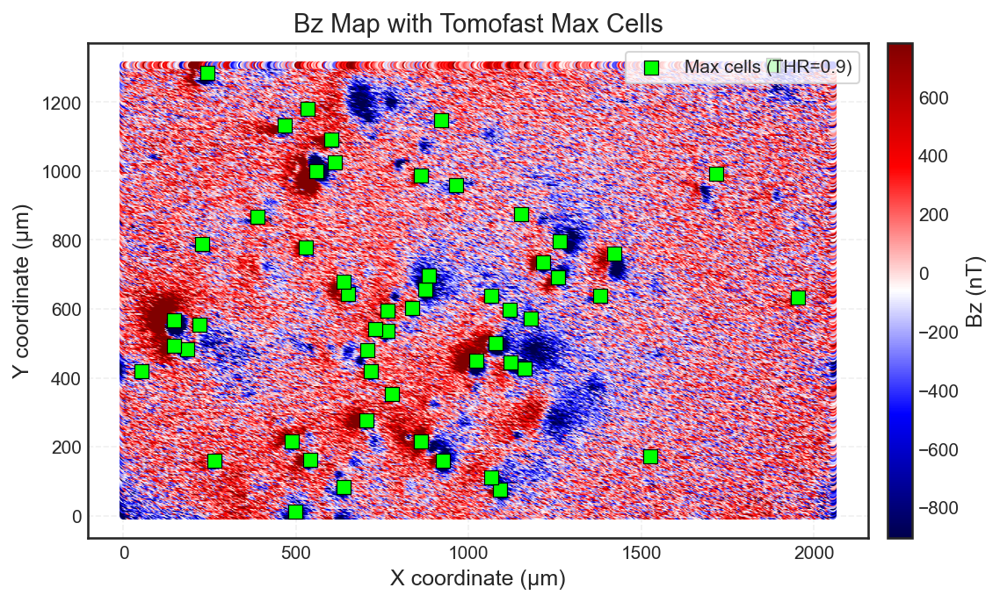

Saved figure: 4-3D_Inversion_Filtered\Tomofast_Output_Blobs\BZ_max_cells_THR_0.9.png


In [6]:
#max cells plot

#User attention: we assume here the best amplitude threshold is 0.9 (change THR = 0.9 if wanted)
# ============================================================
#  SETTINGS
# ============================================================

# define best threshold
THR = 0.9 

# ------------------------------------------------------------
# 1. Read Mag data (Bz)
# ------------------------------------------------------------
mag_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Mag_Inversion.obs")
mag = np.loadtxt(mag_path, skiprows=1)

x = mag[:, 0]
y = mag[:, 1]
bz = -1 * mag[:, 3]   # QDM convention

# ------------------------------------------------------------
# 2. Read MAX CELLS (combined file)
# ------------------------------------------------------------
max_cells_path = os.path.join(
    base_dir,
    "4-3D_Inversion_Filtered",
    "Tomofast_Output_Blobs",
    f"ALL_BLOBS_grain_max_meshrow_{THR:.1f}.csv"
)

df = pd.read_csv(max_cells_path)

# Compute cell centres
mx = 0.5 * (df["X1"].values + df["X2"].values)
my = 0.5 * (df["Y1"].values + df["Y2"].values)

# ------------------------------------------------------------
# 3. Colour scaling (clip outliers)
# ------------------------------------------------------------
bz_min = np.percentile(bz, 2)
bz_max = np.percentile(bz, 98)

# ------------------------------------------------------------
# 4. Plot
# ------------------------------------------------------------
plt.style.use("seaborn-v0_8-white")

fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

# Bz map
sc = ax.scatter(
    x, y,
    c=bz,
    s=10,
    cmap="seismic",
    vmin=bz_min,
    vmax=bz_max,
    rasterized=True
)

cbar = plt.colorbar(sc, ax=ax, shrink=0.66, pad=0.02)
cbar.set_label("Bz (nT)", fontsize=12)
cbar.ax.tick_params(labelsize=10)

# ------------------------------------------------------------
# 5. Overlay MAX CELLS
# ------------------------------------------------------------
ax.scatter(
    mx, my,
    s=55,
    c="lime",
    edgecolors="black",
    linewidths=0.6,
    marker="s",
    label=f"Max cells (THR={THR:.1f})",
    zorder=3
)

# ------------------------------------------------------------
# 6. Labels & styling
# ------------------------------------------------------------
ax.set_xlabel("X coordinate (µm)", fontsize=12)
ax.set_ylabel("Y coordinate (µm)", fontsize=12)
ax.set_title("Bz Map with Tomofast Max Cells", fontsize=14)

ax.set_aspect("equal", adjustable="box")
ax.grid(True, linestyle="--", alpha=0.3)

ax.legend(frameon=True, fontsize=10, loc="upper right")
plt.tight_layout()

# ------------------------------------------------------------
# 7. Save figure (linked to max-cells file)
# ------------------------------------------------------------
out_png = os.path.join(
     "4-3D_Inversion_Filtered","Tomofast_Output_Blobs",
    f"BZ_max_cells_THR_{THR:.1f}.png"
)

plt.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()

print("Saved figure:", out_png)


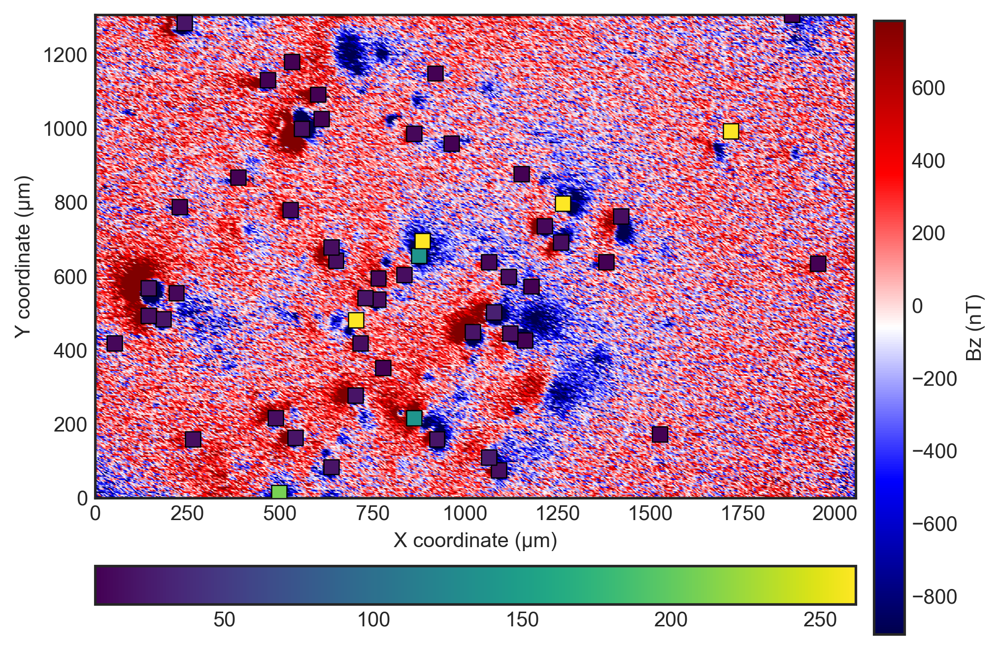

In [23]:
#max cells plot
#User attention: we assume here the best amplitude threshold is 0.9 (change THR = 0.9 if wanted)

THR = 0.9

# ------------------------------------------------------------
# 1. Read Mag data (Bz)
# ------------------------------------------------------------
mag_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Mag_Inversion.obs")
mag = np.loadtxt(mag_path, skiprows=1)

x = mag[:, 0]
y = mag[:, 1]
bz = -1 * mag[:, 3] #flip for qdm convention

# ------------------------------------------------------------
# 2. Read MAX CELLS
# ------------------------------------------------------------
max_cells_path = os.path.join(
    base_dir,
    "4-3D_Inversion_Filtered",
    "Tomofast_Output_Blobs",
    f"ALL_BLOBS_grain_max_meshrow_{THR:.1f}.csv"
)

df = pd.read_csv(max_cells_path)

mx = 0.5 * (df["X1"].values + df["X2"].values)
my = 0.5 * (df["Y1"].values + df["Y2"].values)
mz = 0.5 * (df["Z1"].values + df["Z2"].values)   # depth

# ------------------------------------------------------------
# 3. Colour scaling 
# ------------------------------------------------------------
bz_min = np.percentile(bz, 2)
bz_max = np.percentile(bz, 98)

# ------------------------------------------------------------
# 4. Plot
# ------------------------------------------------------------
plt.style.use("seaborn-v0_8-white")
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

sc = ax.scatter(
    x, y,
    c=bz,
    s=5,
    cmap="seismic",
    vmin=bz_min,
    vmax=bz_max,
    rasterized=True
)

cbar = plt.colorbar(sc, ax=ax, shrink=0.9, pad=0.02)
cbar.set_label("Bz (nT)")

# ------------------------------------------------------------
# 5. Overlay MAX CELLS (depth coloured)
# ------------------------------------------------------------
sc_max = ax.scatter(
    mx, my,
    s=55,
    c=mz,
    cmap="viridis",
    edgecolors="black",
    linewidths=0.6,
    marker="s",
    zorder=3
)

plt.colorbar(sc_max, ax=ax, orientation="horizontal", pad=0.10)

# ------------------------------------------------------------
# 6. Labels & save (unchanged)
# ------------------------------------------------------------
ax.set_xlabel("X coordinate (µm)")
ax.set_ylabel("Y coordinate (µm)")
ax.set_aspect("equal")
ax.set_xlim(x.min(), x.max())
ax.set_ylim(y.min(), y.max())

out_png = os.path.join(
    "4-3D_Inversion_Filtered",
    "Tomofast_Output_Blobs",
    f"BZ_max_cells_THR_{THR:.1f}.png"
)

plt.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()


# Tool 2: Source Location Detection
This tool runs a series of single cell Tomofast-x full magnetic vector inversion in order to obtain the true source location which matches the minimum data cost(misfit). 
* if you are starting from here run Tool 1 lines [1-3].

### 1. Create Parfile
this line creates parfiles for the single cell inversions

In [4]:

# ------------------------------------------------
# INPUT: window summary file
# ------------------------------------------------
# Format:
# blob_id nx ny nz ndata
summary_path = os.path.join(
    base_dir,
    "4-3D_Inversion_Filtered",
    "blob_window_summary.txt"
)

# ------------------------------------------------
# OUTPUT: parfiles
# ------------------------------------------------
par_out_dir = os.path.join(base_dir, "0-Parfiles")
os.makedirs(par_out_dir, exist_ok=True)

# ------------------------------------------------
# Parfile template 
# ------------------------------------------------
PAR_TEMPLATE = """==================================================================================
GLOBAL
==================================================================================
global.outputFolderPath         = ./output/QDM/Blob_{blob_id:03d}
global.description              = QDM inversion – Blob {blob_id}

==================================================================================
MODEL GRID parameters
==================================================================================
# nx ny nz
modelGrid.size                        = 1 1 1
modelGrid.magn.file                   = data/QDM/meshgrid.txt
modelGrid.magn.nModelComponents       = 3

==================================================================================
DATA parameters
==================================================================================
forward.data.magn.nData                = {ndata}
forward.data.magn.dataGridFile         = data/QDM/Blob_{blob_id:03d}_RECT.obs
forward.data.magn.dataValuesFile       = data/QDM/Blob_{blob_id:03d}_RECT.obs
forward.data.magn.nDataComponents      = 1

==================================================================================
MAGNETIC FIELD constants
==================================================================================
forward.magneticField.inclination              = 90.0
forward.magneticField.declination              = 0.0
forward.magneticField.XaxisDeclination         = 0.d0

==================================================================================
DEPTH WEIGHTING
==================================================================================
# 1-depth weight, 2-distance weight.
forward.depthWeighting.type                    = 1

==================================================================================
SENSITIVITY KERNEL
==================================================================================
sensit.readFromFiles                  = 0
sensit.folderPath                     = ./output/QDM/SENSIT/

==================================================================================
MATRIX COMPRESSION
==================================================================================
forward.matrixCompression.type                        = 0
forward.matrixCompression.rate                        = 0.1

==================================================================================
PRIOR MODEL
==================================================================================
inversion.priorModel.type                  = 1
inversion.priorModel.magn.value            = 0.000000

==================================================================================
INVERSION parameters
==================================================================================
inversion.nMajorIterations              = 3
inversion.nMinorIterations              = 100

==================================================================================
MODEL DAMPING (m - m_prior)
==================================================================================
inversion.modelDamping.magn.weight      = 0.0

==================================================================================
JOINT INVERSION parameters
==================================================================================
inversion.joint.grav.problemWeight      = 0.00000000
inversion.joint.magn.problemWeight      = 1.00000000
"""

# ------------------------------------------------
# LOAD SUMMARY + WRITE PARFILES
# ------------------------------------------------
summary = np.loadtxt(summary_path, comments="#", ndmin=2)

print("Creating Parfiles...")

for row in summary:
    blob_id = int(row[0])
    nx      = int(row[1])
    ny      = int(row[2])
    nz      = int(row[3])
    ndata   = int(row[4])

    par_text = PAR_TEMPLATE.format(
        blob_id=blob_id,
        nx=nx,
        ny=ny,
        nz=nz,
        ndata=ndata
    )

    out_path = os.path.join(
        par_out_dir,
        f"Parfile_QDM_Inversion_Blob_{blob_id:03d}.txt"
    )

    with open(out_path, "w") as f:
        f.write(par_text)

    print(f"  Blob {blob_id:03d}: nx={nx}, ny={ny}, nz={nz}, nData={ndata}")
    print("    ->", out_path)

print("\nDone. Parfiles written to:", par_out_dir)


Creating Parfiles...
  Blob 001: nx=3, ny=3, nz=60, nData=9
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\0-Parfiles\Parfile_QDM_Inversion_Blob_001.txt
  Blob 002: nx=6, ny=7, nz=60, nData=42
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\0-Parfiles\Parfile_QDM_Inversion_Blob_002.txt
  Blob 003: nx=7, ny=8, nz=60, nData=56
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\0-Parfiles\Parfile_QDM_Inversion_Blob_003.txt
  Blob 004: nx=6, ny=5, nz=60, nData=30
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\0-Parfiles\Parfile_QDM_Inversion_Blob_004.txt
  Blob 005: nx=10, ny=13, nz=60, nData=130
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\0-Parfiles\Parfile_QDM_Inversion_Blob_005.txt
  Blob 006: nx=7, ny=6, nz=60, nData=42
    -> D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\0-Parfiles\Parfile_QDM_Inversion_Blob_006.txt
  Blob 007: nx=10, ny=8, nz=60, nData=80
    -> D:\My_Work\Tomofa

### 2. Run Tomofast for minimum Data Cost Detection
This script performs a steepest-descent search for each detected blob to find the single-cell position that minimizes the Tomofast-x data cost, starting either from 3D inversion maximum cells (`maxs`) or anomaly seed centers (`seed`).
* for WSL use the first line, for Linux use the second line (just a simple directory change)
* THR : define the threshold of the maximums that matches the model (e.g, one grain per one dipole)
* START_MODE = choose  "seed" or "maxs"


In [27]:
# WSL Tomofast-x Run (Steepest Descent)  - maxs OR seed start
# ============================================================
# Settings
# ============================================================
# Choose start file:
#   "maxs" = use the maxi cells outputed from 3d inversion
#   "seed" = use the center seed output from anomalies detection
# ============================================================
START_MODE = "seed"   # <-- choose  "seed" or "maxs
THR = 0.9  # threshold of max cells
MAX_STEPS = 200

in_name = f"grain_max_meshrow_{THR:.1f}.txt"
last_data_cost = None

# ============================================================
# Paths / Base
# ============================================================
base_dir = os.getcwd()
print("Windows base_dir:", base_dir)

def to_wsl_path(p: str) -> str:
    p = p.replace("\\", "/")
    return f"/mnt/{p[0].lower()}/{p[2:]}"

def run_quiet(cmd: str):
    """Run WSL command, store last 'data cost ... = number' in last_data_cost."""
    global last_data_cost
    last_data_cost = None

    p = subprocess.Popen(
        [WSL, "bash", "-lc", cmd],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    out_lines = []
    for line in p.stdout:
        out_lines.append(line)
        if "data cost" in line.lower():
            try:
                last_data_cost = float(line.split("=")[-1].strip())
            except:
                pass

    p.wait()
    return p.returncode, "".join(out_lines)

# ============================================================
# FOLDERS
# ============================================================
BLOB_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Tomofast_Output_Blobs")
obs_dir   = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Blob_Clipped_obs_RECT")
par_dir   = os.path.join(base_dir, "0-Parfiles")

out_dir = os.path.join(base_dir, "4-Source_Detection", "Results_DataCost_Steepest")
os.makedirs(out_dir, exist_ok=True)

print("BLOB_ROOT:", BLOB_ROOT)
print("obs_dir :", obs_dir)
print("par_dir :", par_dir)
print("out_dir :", out_dir)

# seed file (used only if START_MODE="seed")
seed_meshrow_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "blob_seed_meshrow.txt")

# ============================================================
# Neighbour offsets (26 neighbours + current), in steps of (dx,dy,dz)
# ============================================================
#NEIGH = [(0, 0, 0)]
#for ix in (-1, 0, 1):
#    for iy in (-1, 0, 1):
 #       for iz in (-1, 0, 1):
  #          if not (ix == 0 and iy == 0 and iz == 0):
  #              NEIGH.append((ix, iy, iz))

# ============================================================
# Neighbour offsets (6 neighbours + current)
# ============================================================
NEIGH = [
    (-1, 0, 0),  # -x
    ( 1, 0, 0),  # +x
    ( 0,-1, 0),  # -y
    ( 0, 1, 0),  # +y
    ( 0, 0,-1),  # -z
    ( 0, 0, 1),  # +z
]

# ============================================================
# Temp mesh files (Windows -> copied to WSL target meshgrid.txt)
# ============================================================
tmp_mesh_win = os.path.join(base_dir, "_meshgrid_tmp.txt")
tmp_mesh_wsl = to_wsl_path(tmp_mesh_win)
meshgrid_target_wsl = f"{TOMOFAST_HOME_WSL}/data/QDM/meshgrid.txt"

# ============================================================
# Find blobs
# ============================================================
blob_dirs = sorted(
    d for d in os.listdir(BLOB_ROOT)
    if d.startswith("Blob_") and os.path.isdir(os.path.join(BLOB_ROOT, d))
)
print("\nFound blobs:", blob_dirs)

# ============================================================
# Read seed file once (if selected)
# ============================================================
seed_map = {}
if START_MODE == "seed":
    lines = [ln.strip() for ln in open(seed_meshrow_path, "r").readlines() if ln.strip()]

    for ln in lines[1:]:
        c = ln.split()

        # c[0] = "Blob_001"
        blob_id = int(c[0].split("_")[1])

        # format:
        # Blob_001 1 xmin xmax ymin ymax zmin zmax 0 0 0 i j k
        xmin0 = float(c[2])
        xmax0 = float(c[3])
        ymin0 = float(c[4])
        ymax0 = float(c[5])
        zmin0 = float(c[6])
        zmax0 = float(c[7])

        seed_map[blob_id] = (xmin0, xmax0, ymin0, ymax0, zmin0, zmax0)

t0 = time.time()

# ============================================================
# Main loop
# ============================================================
best_per_blob = []

for blob in blob_dirs:
    print("\n===================================================")
    print("Processing", blob)
    print("===================================================")

    blob_id = int(blob.split("_")[1])

    # --------------------------------------------------------
    # 1) Read start cell bounds
    # --------------------------------------------------------
    if START_MODE == "maxs":
        startfile = os.path.join(BLOB_ROOT, blob, blob, "Maxs_meshs", in_name)
        lines = [ln.strip() for ln in open(startfile, "r").readlines() if ln.strip()]
        cols = lines[1].split()  # line0=count, line1=grain row
        grain_id = int(float(cols[0]))
        xmin0, xmax0 = float(cols[1]), float(cols[2])
        ymin0, ymax0 = float(cols[3]), float(cols[4])
        zmin0, zmax0 = float(cols[5]), float(cols[6])

    else:  # START_MODE == "seed"
        grain_id = 1
        xmin0, xmax0, ymin0, ymax0, zmin0, zmax0 = seed_map[blob_id]

    dx, dy, dz = (xmax0 - xmin0), (ymax0 - ymin0), (zmax0 - zmin0)
    cx, cy, cz = 0.5 * (xmin0 + xmax0), 0.5 * (ymin0 + ymax0), 0.5 * (zmin0 + zmax0)

    print(f"Seed center=({cx:.3f},{cy:.3f},{cz:.3f}), cell size=({dx:.3f},{dy:.3f},{dz:.3f})")

    best_cost = float("inf")
    best_center = (cx, cy, cz)
    best_bounds = (xmin0, xmax0, ymin0, ymax0, zmin0, zmax0)
    best_meshname = "meshgrid_seed.txt"

    # --------------------------------------------------------
    # 2) Copy parfile + obs to WSL (filename must match Parfile)
    # --------------------------------------------------------
    obs_win = os.path.join(obs_dir, f"Blob_{blob_id:03d}_RECT.obs")
    par_win = os.path.join(par_dir, f"Parfile_QDM_Inversion_Blob_{blob_id:03d}.txt")

    run_quiet(f"cp '{to_wsl_path(par_win)}' {TOMOFAST_HOME_WSL}/parfiles/")
    run_quiet(f"cp '{to_wsl_path(obs_win)}' {TOMOFAST_HOME_WSL}/data/QDM/Blob_{blob_id:03d}_RECT.obs")

    par_name = f"Parfile_QDM_Inversion_Blob_{blob_id:03d}.txt"

    log_path = os.path.join(out_dir, f"{blob}_steepest_log.txt")
    with open(log_path, "w") as f:
        f.write("# step meshfile cx cy cz xmin xmax ymin ymax zmin zmax cost\n")

    # --------------------------------------------------------
    # 3) Steepest descent
    # --------------------------------------------------------
    for step in range(1, MAX_STEPS + 1):
        move_best_cost = float("inf")
        move_best_center = None
        move_best_bounds = None

        for (ix, iy, iz) in NEIGH:
            tx = cx + ix * dx
            ty = cy + iy * dy
            tz = cz + iz * dz

            xmin = tx - dx / 2
            xmax = tx + dx / 2
            ymin = ty - dy / 2
            ymax = ty + dy / 2
            zmin = tz - dz / 2
            zmax = tz + dz / 2

            with open(tmp_mesh_win, "w") as f:
                f.write("1\n")
                f.write(
                    f"{xmin:.6f} {xmax:.6f} {ymin:.6f} {ymax:.6f} {zmin:.6f} {zmax:.6f} "
                    "0 0 0 1 1 1\n"
                )

            rc, _ = run_quiet(f"cp '{tmp_mesh_wsl}' {meshgrid_target_wsl}")
            if rc != 0:
                continue

            rc, _ = run_quiet(f"cd {TOMOFAST_HOME_WSL} && ./tomofastx -p ./parfiles/{par_name}")
            if rc != 0 or last_data_cost is None:
                continue

            cost = last_data_cost
            if math.isnan(cost) or math.isinf(cost):
                continue

            if cost < move_best_cost:
                move_best_cost = cost
                move_best_center = (tx, ty, tz)
                move_best_bounds = (xmin, xmax, ymin, ymax, zmin, zmax)

        if move_best_center is None:
            print(f"step {step:03d}: all NaN -> STOP")
            break

        cx, cy, cz = move_best_center
        meshname = f"meshgrid_step{step:03d}.txt"

        print(f"step {step:03d}: best cost={move_best_cost:.6e} at center=({cx:.3f},{cy:.3f},{cz:.3f})")

        xmin, xmax, ymin, ymax, zmin, zmax = move_best_bounds
        with open(log_path, "a") as f:
            f.write(
                f"{step} {meshname} {cx:.6f} {cy:.6f} {cz:.6f} "
                f"{xmin:.6f} {xmax:.6f} {ymin:.6f} {ymax:.6f} {zmin:.6f} {zmax:.6f} "
                f"{move_best_cost:.16e}\n"
            )

        if move_best_cost >= best_cost:
            print(f"no improvement (best={best_cost:.6e}) -> STOP")
            break

        best_cost = move_best_cost
        best_center = (cx, cy, cz)
        best_bounds = move_best_bounds
        best_meshname = meshname

    # --------------------------------------------------------
    # 4) Save best per blob
    # --------------------------------------------------------
    if math.isinf(best_cost):
        best_per_blob.append((blob, grain_id, "meshgrid_NONE.txt", (float("nan"),) * 6, float("nan")))
        print(f">>> BEST for {blob}: NONE")
    else:
        print(
            f">>> BEST for {blob}: cost={best_cost:.6e} "
            f"center=({best_center[0]:.3f},{best_center[1]:.3f},{best_center[2]:.3f})"
        )
        best_per_blob.append((blob, grain_id, best_meshname, best_bounds, best_cost))

# ============================================================
# Write best_per_blob_steepest.txt
# ============================================================
summary_path = os.path.join(out_dir, "best_per_blob_steepest.txt")
with open(summary_path, "w") as f:
    f.write("# blob grain meshfile xmin xmax ymin ymax zmin zmax final_data_cost\n")
    for (blob, grain_id, meshname, b, cost) in best_per_blob:
        xmin, xmax, ymin, ymax, zmin, zmax = b
        f.write(
            f"{blob} grain_{grain_id} {meshname} "
            f"{xmin:.6f} {xmax:.6f} {ymin:.6f} {ymax:.6f} {zmin:.6f} {zmax:.6f} "
            f"{cost:.16e}\n"
        )

print("\nWrote:", summary_path)
print(f"Total runtime: {(time.time() - t0) / 60:.2f} minutes")

Windows base_dir: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy
BLOB_ROOT: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\4-3D_Inversion_Filtered\Tomofast_Output_Blobs
obs_dir : D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\4-3D_Inversion_Filtered\Blob_Clipped_obs_RECT
par_dir : D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\0-Parfiles
out_dir : D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\4-Source_Detection\Results_DataCost_Steepest

Found blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005', 'Blob_006', 'Blob_007', 'Blob_008', 'Blob_009', 'Blob_010', 'Blob_011', 'Blob_012', 'Blob_013', 'Blob_014', 'Blob_015', 'Blob_016', 'Blob_017', 'Blob_018', 'Blob_019', 'Blob_020', 'Blob_021', 'Blob_022', 'Blob_023', 'Blob_024', 'Blob_025', 'Blob_026', 'Blob_027', 'Blob_028', 'Blob_029', 'Blob_030', 'Blob_031', 'Blob_032', 'Blob_033', 'Blob_034', 'Blob_035', 'Blob_036', 'Blob_037', 'Blob_038', 'Blob_039', 'Blob_040', 'Bl

### 3. Analysis Plots
* the output data costs should increase every where around the true locations  the analysis plots should show this shape < < < in x y z 

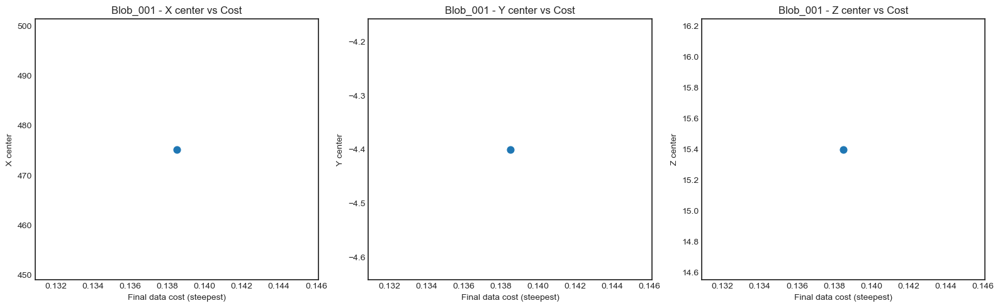


-------------------------------------
Blob: Blob_001
Minimum final data cost = 0.13850185127237363
Best meshfile           = meshgrid_step008.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    473.0
xmax    477.4
ymin     -6.6
ymax     -2.2
zmin     13.2
zmax     17.6
Name: 0, dtype: object
-------------------------------------



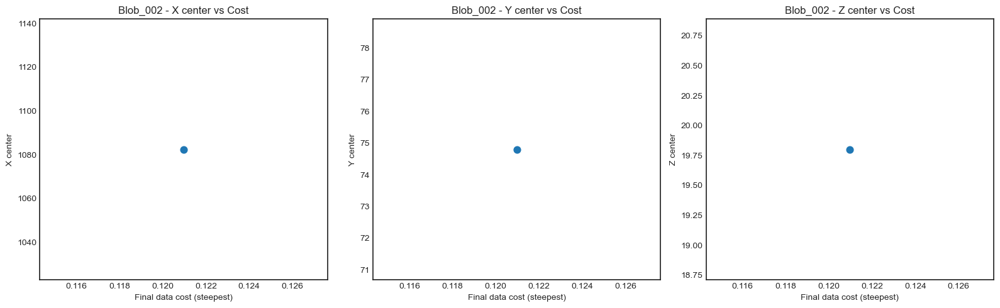


-------------------------------------
Blob: Blob_002
Minimum final data cost = 0.12097191983080716
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1080.2
xmax    1084.6
ymin      72.6
ymax      77.0
zmin      17.6
zmax      22.0
Name: 1, dtype: object
-------------------------------------



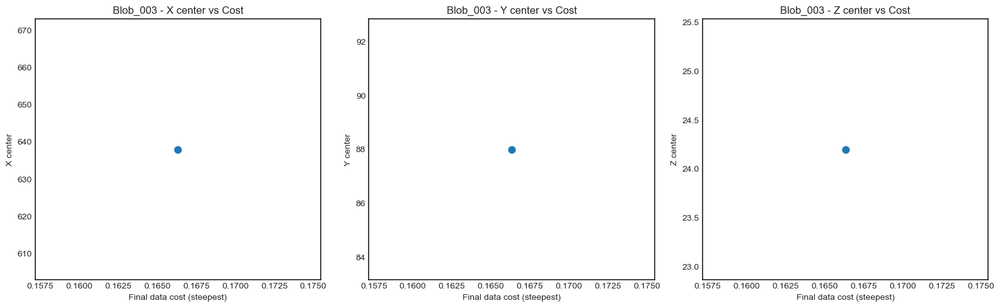


-------------------------------------
Blob: Blob_003
Minimum final data cost = 0.16632769720990373
Best meshfile           = meshgrid_step003.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    635.8
xmax    640.2
ymin     85.8
ymax     90.2
zmin     22.0
zmax     26.4
Name: 2, dtype: object
-------------------------------------



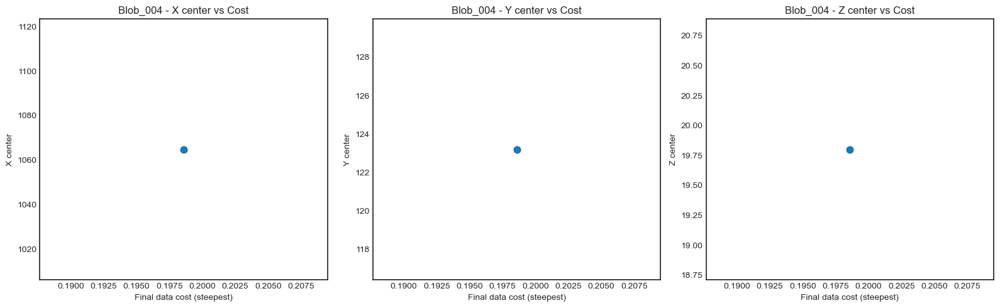


-------------------------------------
Blob: Blob_004
Minimum final data cost = 0.19858686556537936
Best meshfile           = meshgrid_step003.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1062.6
xmax    1067.0
ymin     121.0
ymax     125.4
zmin      17.6
zmax      22.0
Name: 3, dtype: object
-------------------------------------



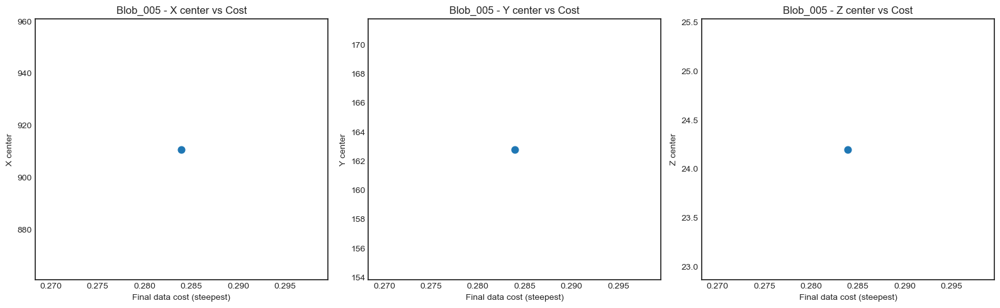


-------------------------------------
Blob: Blob_005
Minimum final data cost = 0.2839357429187462
Best meshfile           = meshgrid_step006.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    908.6
xmax    913.0
ymin    160.6
ymax    165.0
zmin     22.0
zmax     26.4
Name: 4, dtype: object
-------------------------------------



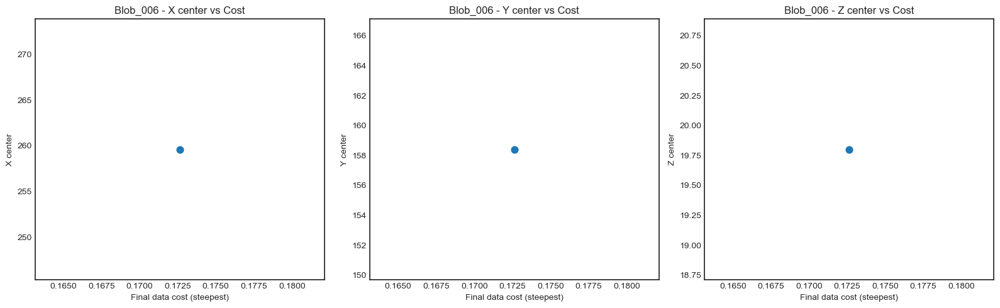


-------------------------------------
Blob: Blob_006
Minimum final data cost = 0.1726255850699723
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    257.4
xmax    261.8
ymin    156.2
ymax    160.6
zmin     17.6
zmax     22.0
Name: 5, dtype: object
-------------------------------------



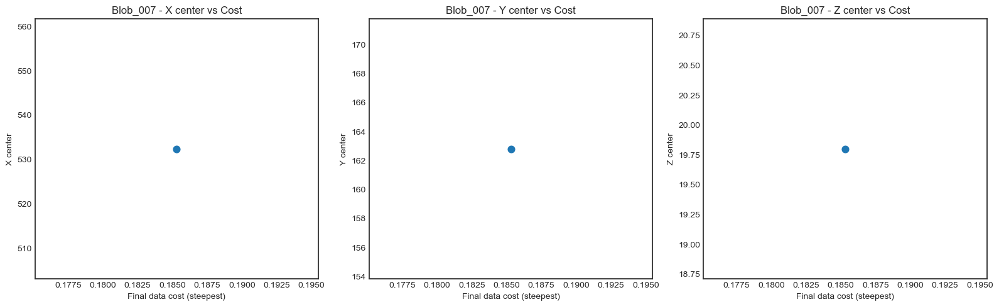


-------------------------------------
Blob: Blob_007
Minimum final data cost = 0.18530985402963893
Best meshfile           = meshgrid_step001.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    530.2
xmax    534.6
ymin    160.6
ymax    165.0
zmin     17.6
zmax     22.0
Name: 6, dtype: object
-------------------------------------



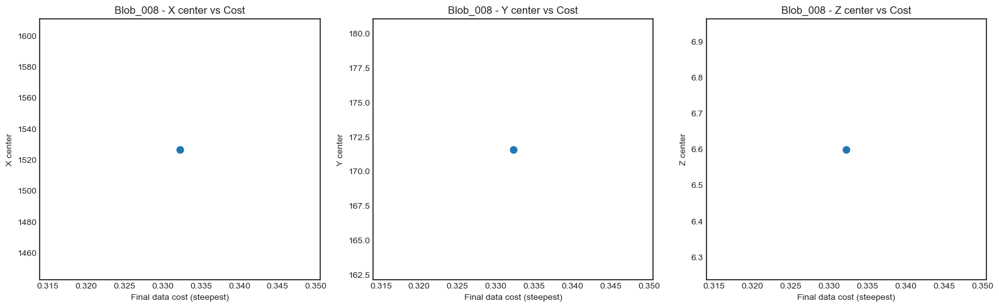


-------------------------------------
Blob: Blob_008
Minimum final data cost = 0.33225980748070766
Best meshfile           = meshgrid_step004.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1524.6
xmax    1529.0
ymin     169.4
ymax     173.8
zmin       4.4
zmax       8.8
Name: 7, dtype: object
-------------------------------------



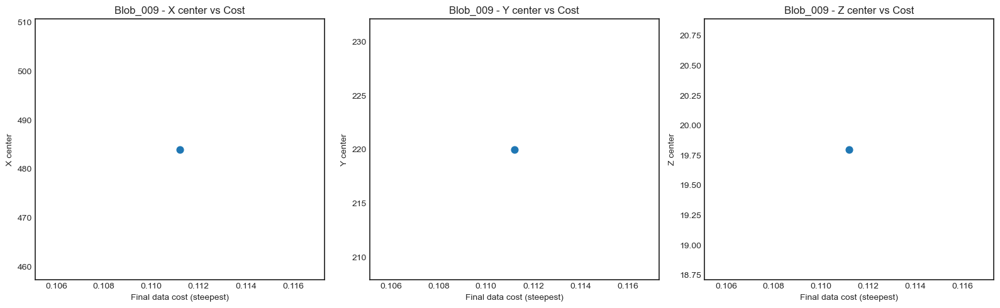


-------------------------------------
Blob: Blob_009
Minimum final data cost = 0.11120019528712174
Best meshfile           = meshgrid_step004.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    481.8
xmax    486.2
ymin    217.8
ymax    222.2
zmin     17.6
zmax     22.0
Name: 8, dtype: object
-------------------------------------



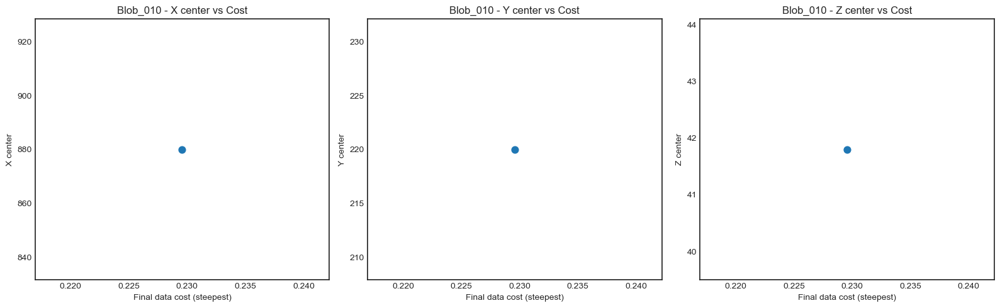


-------------------------------------
Blob: Blob_010
Minimum final data cost = 0.22958051963881712
Best meshfile           = meshgrid_step009.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    877.8
xmax    882.2
ymin    217.8
ymax    222.2
zmin     39.6
zmax     44.0
Name: 9, dtype: object
-------------------------------------



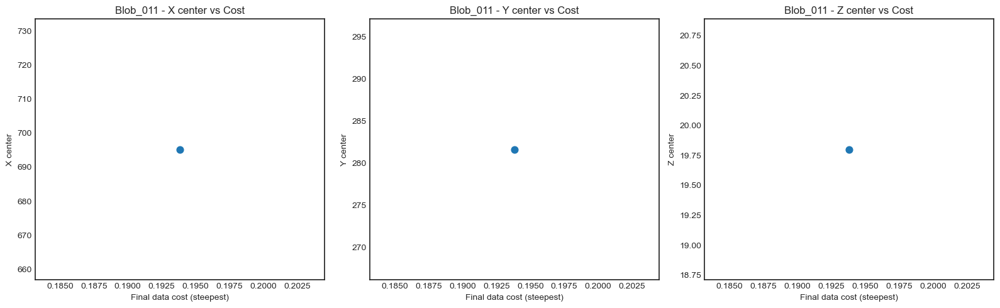


-------------------------------------
Blob: Blob_011
Minimum final data cost = 0.19382268296762264
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    693.0
xmax    697.4
ymin    279.4
ymax    283.8
zmin     17.6
zmax     22.0
Name: 10, dtype: object
-------------------------------------



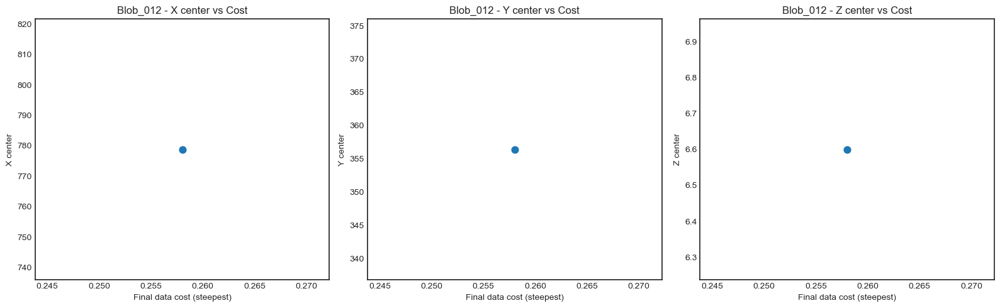


-------------------------------------
Blob: Blob_012
Minimum final data cost = 0.2580172899640566
Best meshfile           = meshgrid_step004.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    776.6
xmax    781.0
ymin    354.2
ymax    358.6
zmin      4.4
zmax      8.8
Name: 11, dtype: object
-------------------------------------



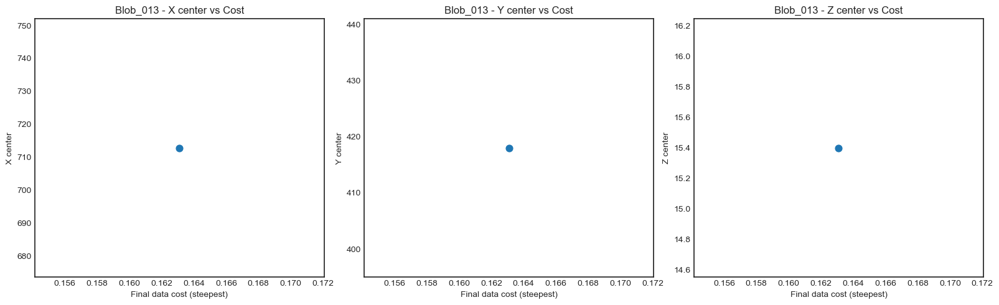


-------------------------------------
Blob: Blob_013
Minimum final data cost = 0.16309795407460406
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    710.6
xmax    715.0
ymin    415.8
ymax    420.2
zmin     13.2
zmax     17.6
Name: 12, dtype: object
-------------------------------------



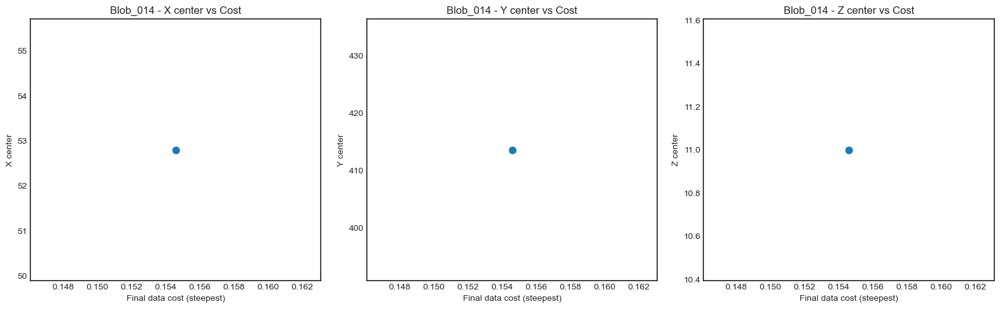


-------------------------------------
Blob: Blob_014
Minimum final data cost = 0.15459550667071614
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin     50.6
xmax     55.0
ymin    411.4
ymax    415.8
zmin      8.8
zmax     13.2
Name: 13, dtype: object
-------------------------------------



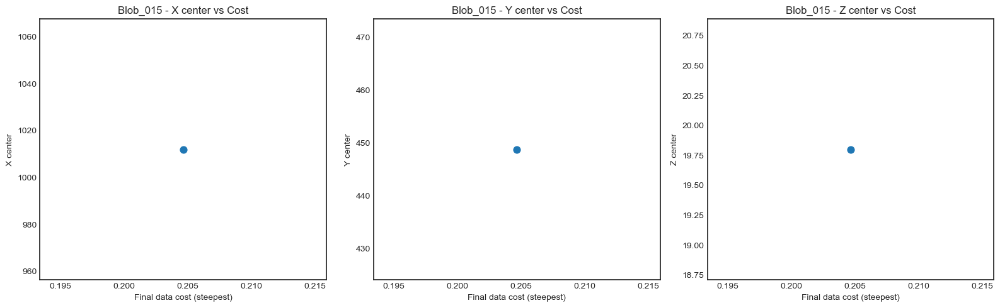


-------------------------------------
Blob: Blob_015
Minimum final data cost = 0.20466059269973827
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1009.8
xmax    1014.2
ymin     446.6
ymax     451.0
zmin      17.6
zmax      22.0
Name: 14, dtype: object
-------------------------------------



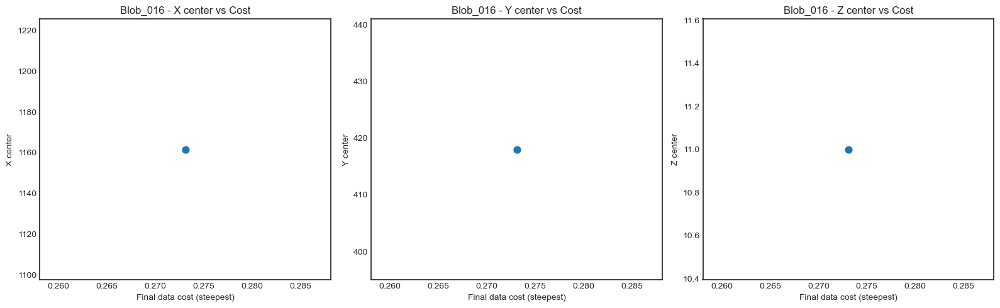


-------------------------------------
Blob: Blob_016
Minimum final data cost = 0.27308067493811705
Best meshfile           = meshgrid_step004.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1159.4
xmax    1163.8
ymin     415.8
ymax     420.2
zmin       8.8
zmax      13.2
Name: 15, dtype: object
-------------------------------------



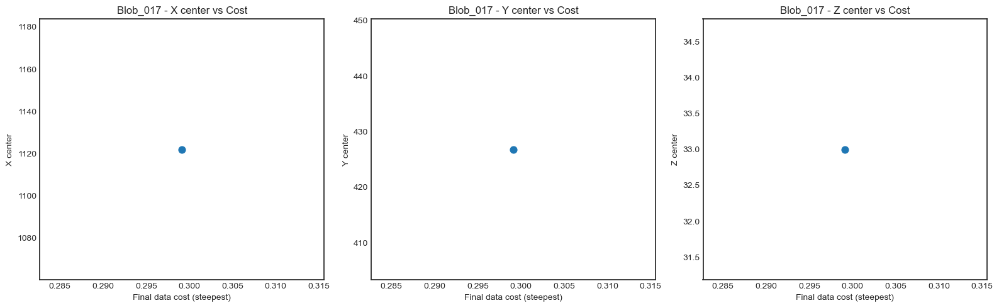


-------------------------------------
Blob: Blob_017
Minimum final data cost = 0.2991368069810912
Best meshfile           = meshgrid_step009.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1119.8
xmax    1124.2
ymin     424.6
ymax     429.0
zmin      30.8
zmax      35.2
Name: 16, dtype: object
-------------------------------------



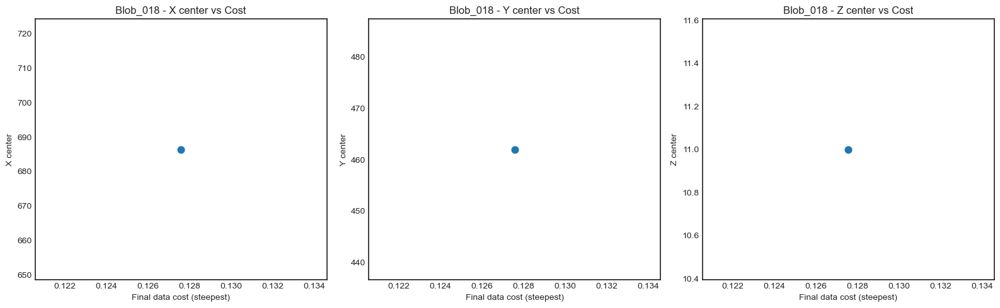


-------------------------------------
Blob: Blob_018
Minimum final data cost = 0.12757463330802124
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    684.2
xmax    688.6
ymin    459.8
ymax    464.2
zmin      8.8
zmax     13.2
Name: 17, dtype: object
-------------------------------------



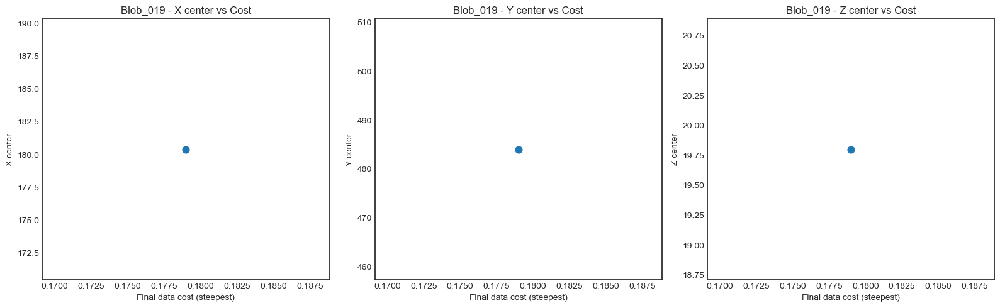


-------------------------------------
Blob: Blob_019
Minimum final data cost = 0.17899390057746525
Best meshfile           = meshgrid_step001.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    178.2
xmax    182.6
ymin    481.8
ymax    486.2
zmin     17.6
zmax     22.0
Name: 18, dtype: object
-------------------------------------



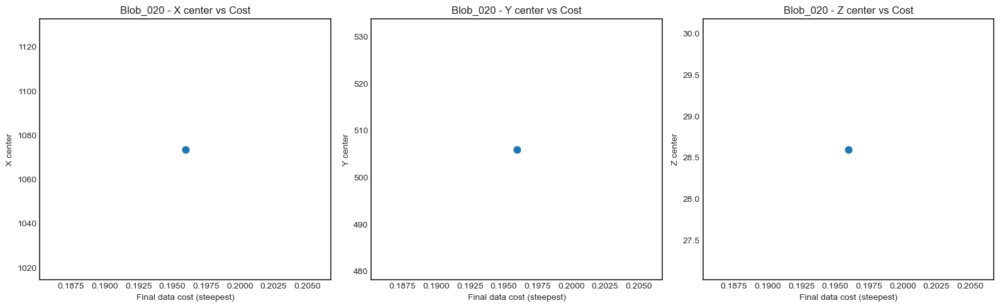


-------------------------------------
Blob: Blob_020
Minimum final data cost = 0.1959630647367916
Best meshfile           = meshgrid_step006.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1071.4
xmax    1075.8
ymin     503.8
ymax     508.2
zmin      26.4
zmax      30.8
Name: 19, dtype: object
-------------------------------------



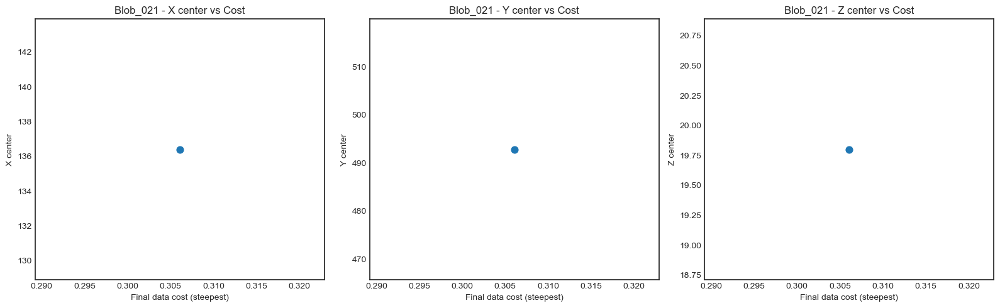


-------------------------------------
Blob: Blob_021
Minimum final data cost = 0.3060658814374878
Best meshfile           = meshgrid_step001.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    134.2
xmax    138.6
ymin    490.6
ymax    495.0
zmin     17.6
zmax     22.0
Name: 20, dtype: object
-------------------------------------



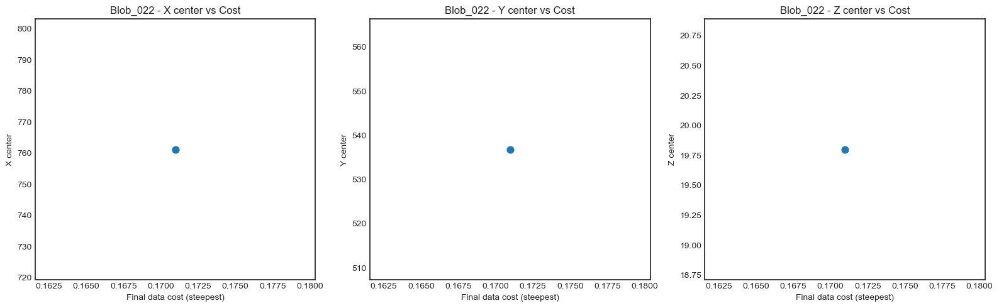


-------------------------------------
Blob: Blob_022
Minimum final data cost = 0.17096621203851525
Best meshfile           = meshgrid_step001.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    759.0
xmax    763.4
ymin    534.6
ymax    539.0
zmin     17.6
zmax     22.0
Name: 21, dtype: object
-------------------------------------



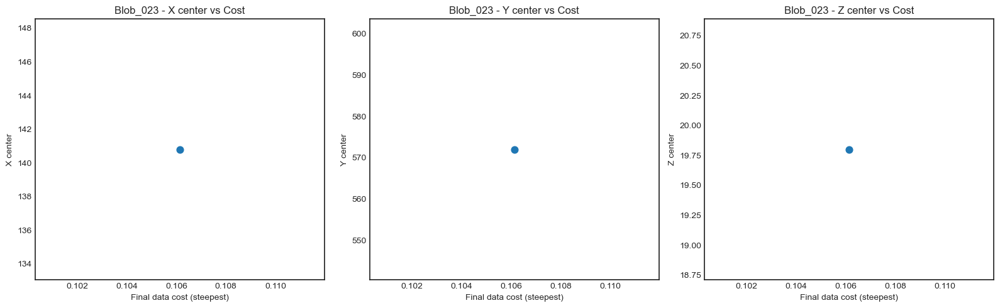


-------------------------------------
Blob: Blob_023
Minimum final data cost = 0.10613473406866838
Best meshfile           = meshgrid_step004.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    138.6
xmax    143.0
ymin    569.8
ymax    574.2
zmin     17.6
zmax     22.0
Name: 22, dtype: object
-------------------------------------



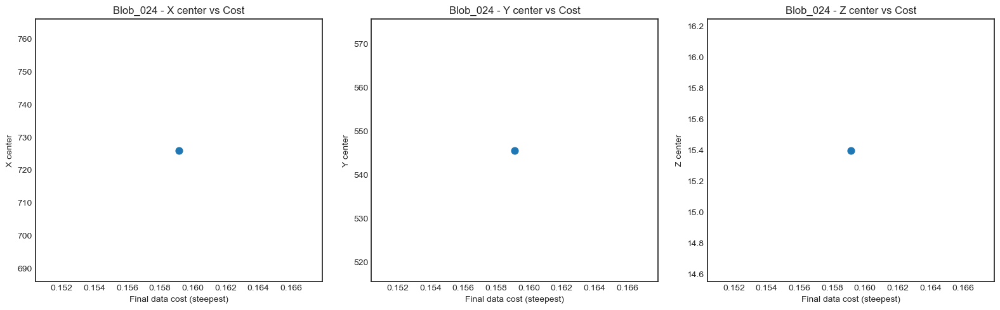


-------------------------------------
Blob: Blob_024
Minimum final data cost = 0.1591410807512898
Best meshfile           = meshgrid_step003.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    723.8
xmax    728.2
ymin    543.4
ymax    547.8
zmin     13.2
zmax     17.6
Name: 23, dtype: object
-------------------------------------



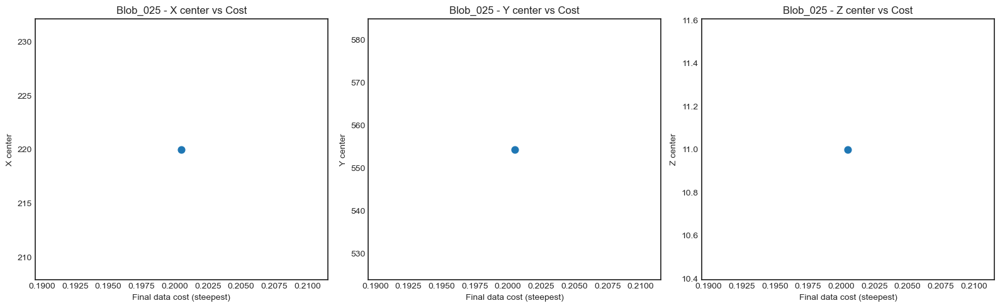


-------------------------------------
Blob: Blob_025
Minimum final data cost = 0.2005085860926331
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    217.8
xmax    222.2
ymin    552.2
ymax    556.6
zmin      8.8
zmax     13.2
Name: 24, dtype: object
-------------------------------------



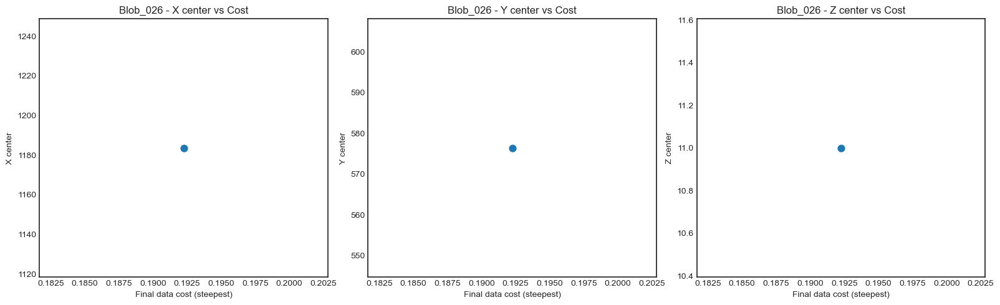


-------------------------------------
Blob: Blob_026
Minimum final data cost = 0.19225108385873568
Best meshfile           = meshgrid_step004.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1181.4
xmax    1185.8
ymin     574.2
ymax     578.6
zmin       8.8
zmax      13.2
Name: 25, dtype: object
-------------------------------------



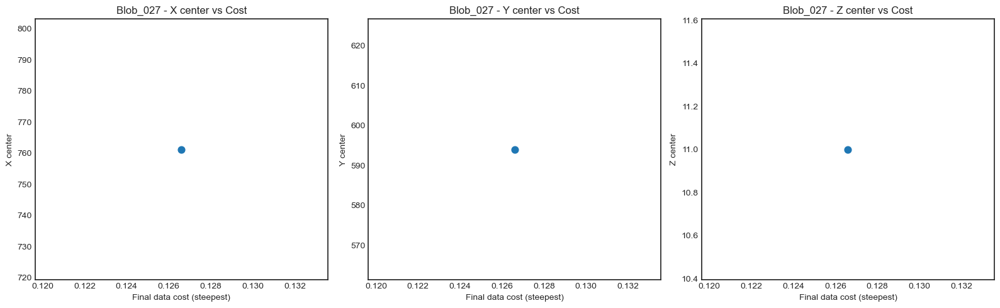


-------------------------------------
Blob: Blob_027
Minimum final data cost = 0.12660294978295789
Best meshfile           = meshgrid_step004.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    759.0
xmax    763.4
ymin    591.8
ymax    596.2
zmin      8.8
zmax     13.2
Name: 26, dtype: object
-------------------------------------



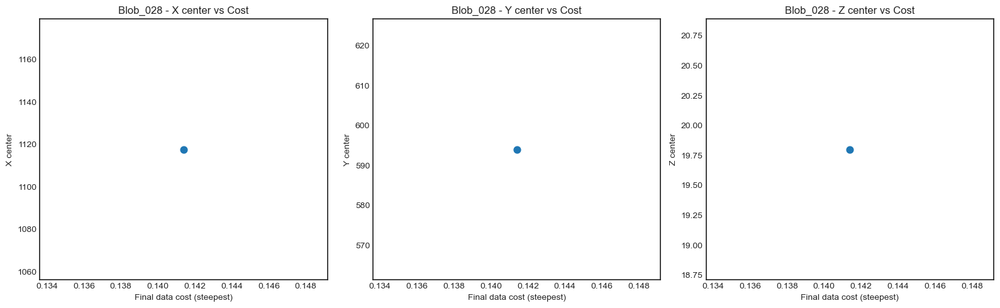


-------------------------------------
Blob: Blob_028
Minimum final data cost = 0.14139815809529846
Best meshfile           = meshgrid_step001.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1115.4
xmax    1119.8
ymin     591.8
ymax     596.2
zmin      17.6
zmax      22.0
Name: 27, dtype: object
-------------------------------------



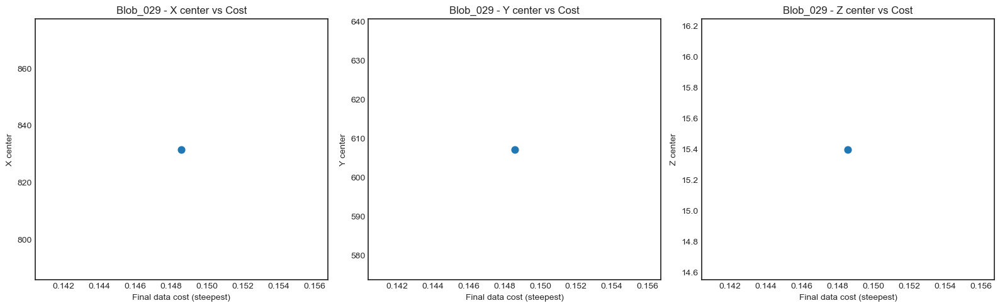


-------------------------------------
Blob: Blob_029
Minimum final data cost = 0.14857705357695097
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    829.4
xmax    833.8
ymin    605.0
ymax    609.4
zmin     13.2
zmax     17.6
Name: 28, dtype: object
-------------------------------------



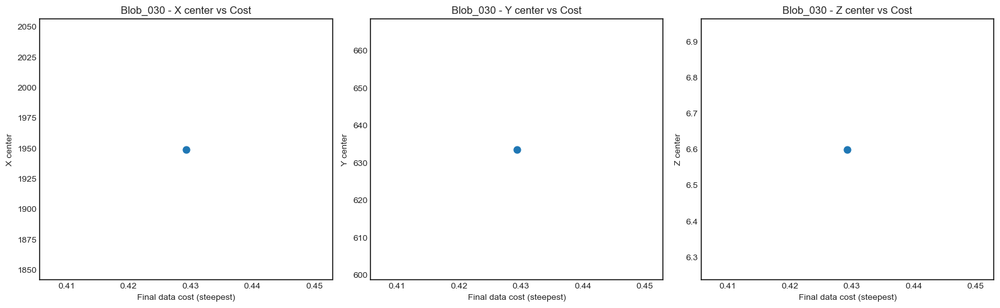


-------------------------------------
Blob: Blob_030
Minimum final data cost = 0.4293316314526925
Best meshfile           = meshgrid_step005.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1947.0
xmax    1951.4
ymin     631.4
ymax     635.8
zmin       4.4
zmax       8.8
Name: 29, dtype: object
-------------------------------------



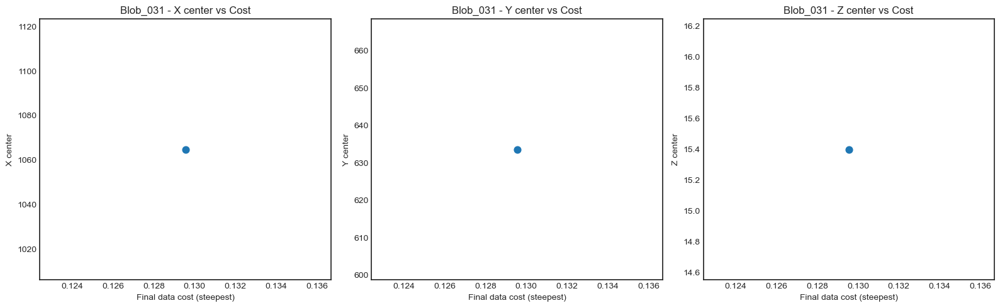


-------------------------------------
Blob: Blob_031
Minimum final data cost = 0.129547728676774
Best meshfile           = meshgrid_step001.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1062.6
xmax    1067.0
ymin     631.4
ymax     635.8
zmin      13.2
zmax      17.6
Name: 30, dtype: object
-------------------------------------



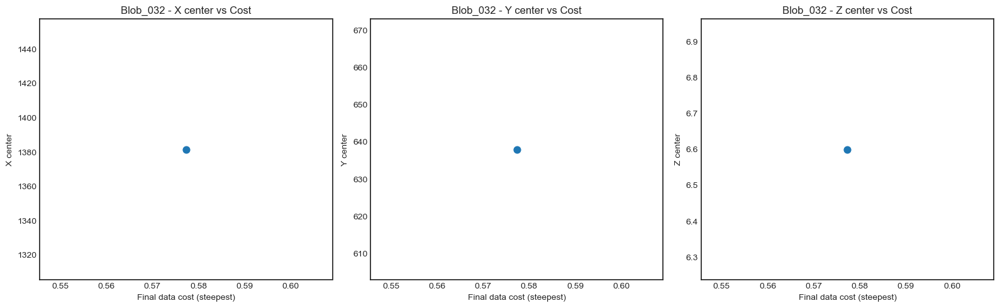


-------------------------------------
Blob: Blob_032
Minimum final data cost = 0.577324586736625
Best meshfile           = meshgrid_step005.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1379.4
xmax    1383.8
ymin     635.8
ymax     640.2
zmin       4.4
zmax       8.8
Name: 31, dtype: object
-------------------------------------



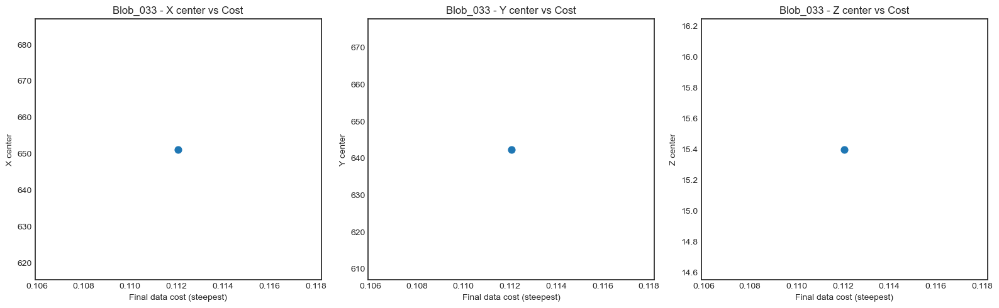


-------------------------------------
Blob: Blob_033
Minimum final data cost = 0.11206927286666468
Best meshfile           = meshgrid_step001.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    649.0
xmax    653.4
ymin    640.2
ymax    644.6
zmin     13.2
zmax     17.6
Name: 32, dtype: object
-------------------------------------



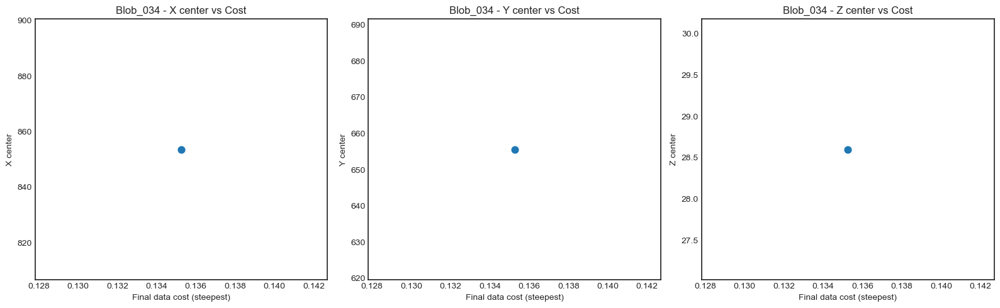


-------------------------------------
Blob: Blob_034
Minimum final data cost = 0.13525431366082405
Best meshfile           = meshgrid_step009.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    851.4
xmax    855.8
ymin    653.4
ymax    657.8
zmin     26.4
zmax     30.8
Name: 33, dtype: object
-------------------------------------



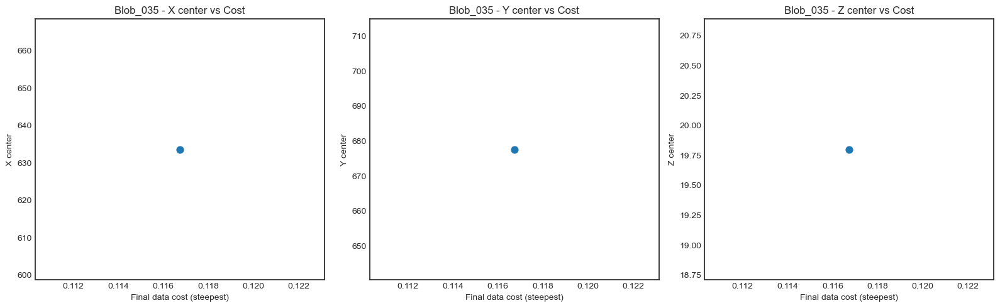


-------------------------------------
Blob: Blob_035
Minimum final data cost = 0.1167290671555663
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    631.4
xmax    635.8
ymin    675.4
ymax    679.8
zmin     17.6
zmax     22.0
Name: 34, dtype: object
-------------------------------------



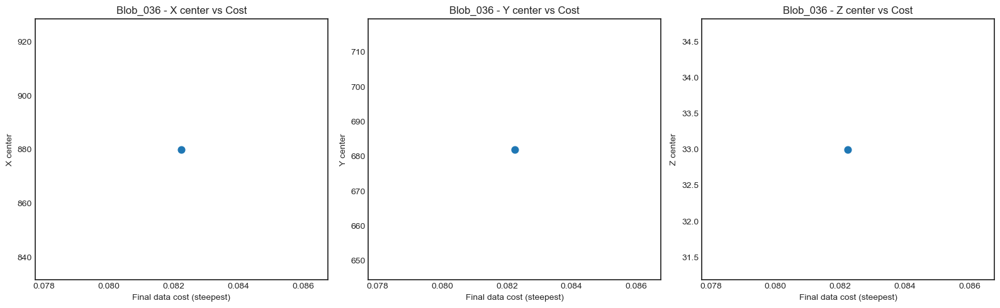


-------------------------------------
Blob: Blob_036
Minimum final data cost = 0.08224164330207585
Best meshfile           = meshgrid_step007.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    877.8
xmax    882.2
ymin    679.8
ymax    684.2
zmin     30.8
zmax     35.2
Name: 35, dtype: object
-------------------------------------



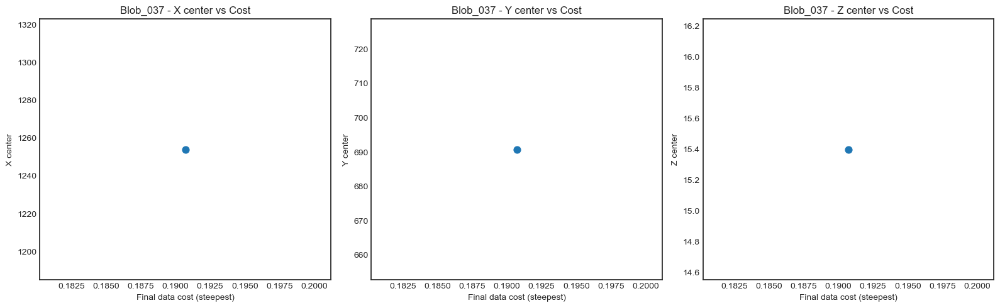


-------------------------------------
Blob: Blob_037
Minimum final data cost = 0.19071210070415975
Best meshfile           = meshgrid_step003.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1251.8
xmax    1256.2
ymin     688.6
ymax     693.0
zmin      13.2
zmax      17.6
Name: 36, dtype: object
-------------------------------------



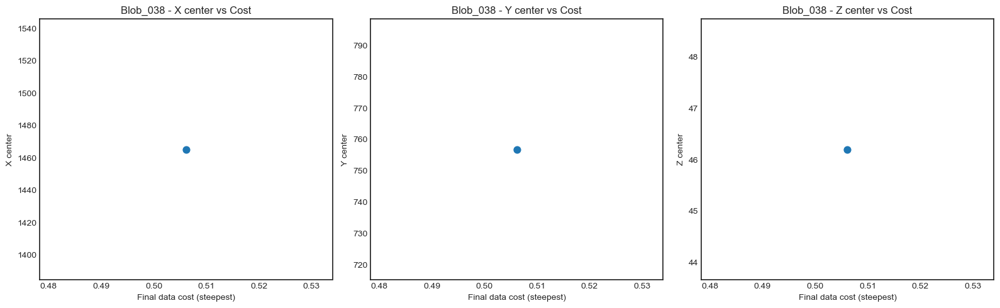


-------------------------------------
Blob: Blob_038
Minimum final data cost = 0.506167541365674
Best meshfile           = meshgrid_step022.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1463.0
xmax    1467.4
ymin     754.6
ymax     759.0
zmin      44.0
zmax      48.4
Name: 37, dtype: object
-------------------------------------



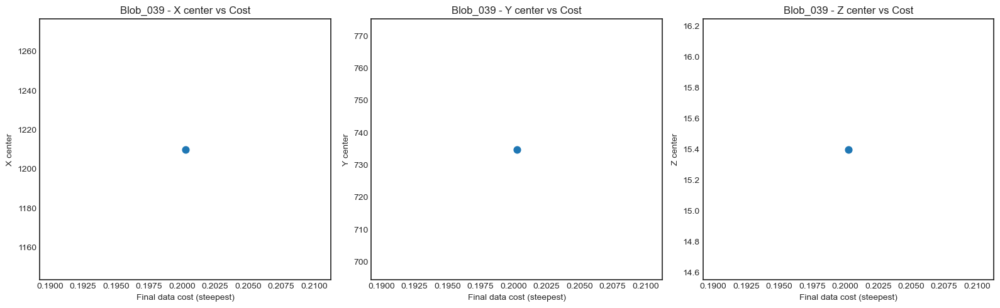


-------------------------------------
Blob: Blob_039
Minimum final data cost = 0.2002404175693673
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1207.8
xmax    1212.2
ymin     732.6
ymax     737.0
zmin      13.2
zmax      17.6
Name: 38, dtype: object
-------------------------------------



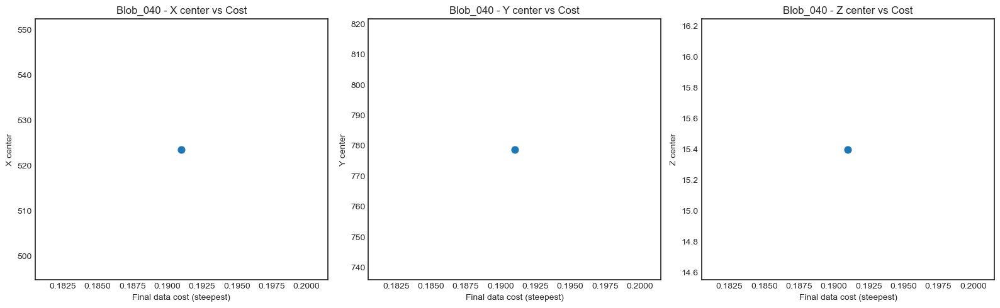


-------------------------------------
Blob: Blob_040
Minimum final data cost = 0.1910142147387381
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    521.4
xmax    525.8
ymin    776.6
ymax    781.0
zmin     13.2
zmax     17.6
Name: 39, dtype: object
-------------------------------------



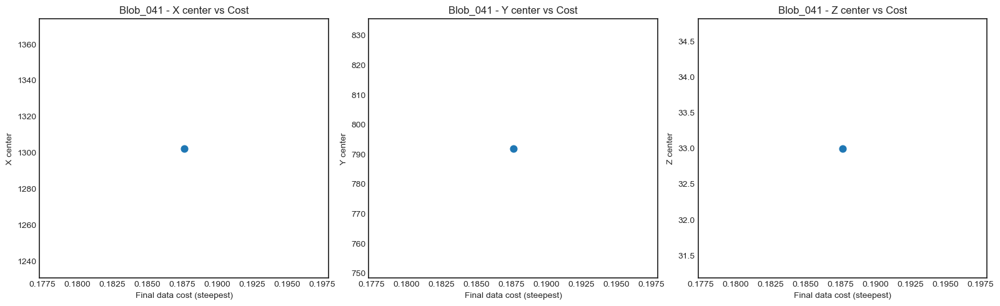


-------------------------------------
Blob: Blob_041
Minimum final data cost = 0.18762217254426233
Best meshfile           = meshgrid_step006.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1300.2
xmax    1304.6
ymin     789.8
ymax     794.2
zmin      30.8
zmax      35.2
Name: 40, dtype: object
-------------------------------------



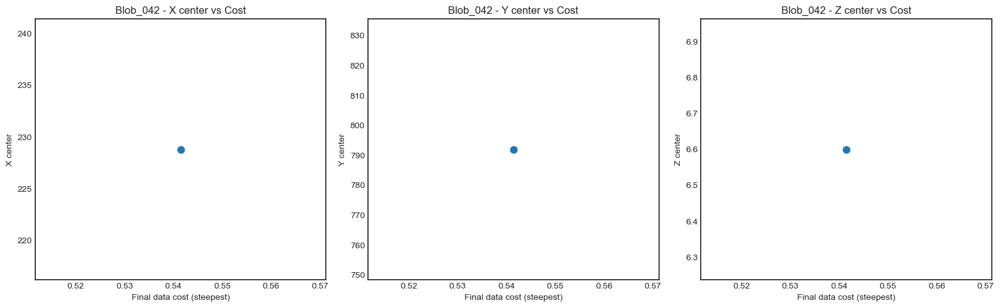


-------------------------------------
Blob: Blob_042
Minimum final data cost = 0.5414589423543249
Best meshfile           = meshgrid_step004.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    226.6
xmax    231.0
ymin    789.8
ymax    794.2
zmin      4.4
zmax      8.8
Name: 41, dtype: object
-------------------------------------



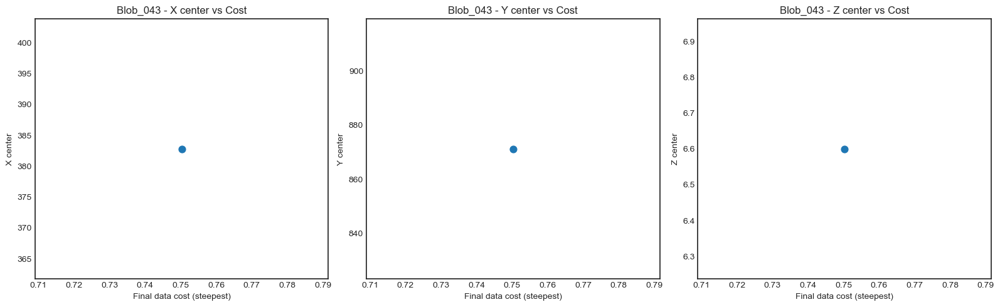


-------------------------------------
Blob: Blob_043
Minimum final data cost = 0.7502691649711604
Best meshfile           = meshgrid_step005.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    380.6
xmax    385.0
ymin    869.0
ymax    873.4
zmin      4.4
zmax      8.8
Name: 42, dtype: object
-------------------------------------



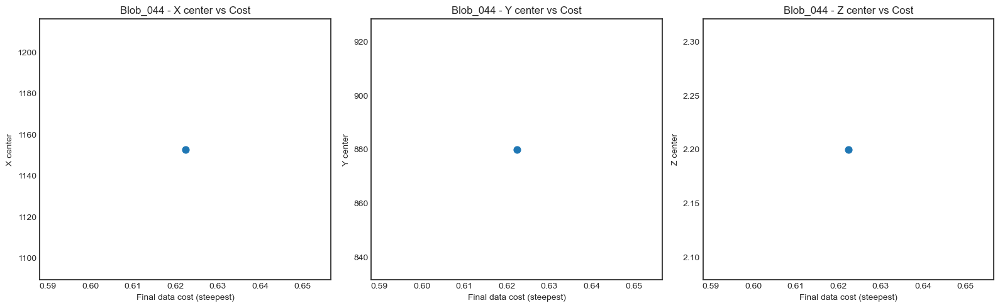


-------------------------------------
Blob: Blob_044
Minimum final data cost = 0.6223770980554816
Best meshfile           = meshgrid_step006.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1150.6
xmax    1155.0
ymin     877.8
ymax     882.2
zmin       0.0
zmax       4.4
Name: 43, dtype: object
-------------------------------------



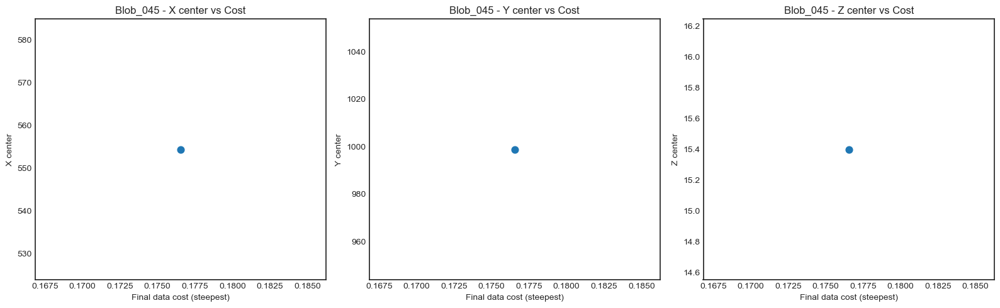


-------------------------------------
Blob: Blob_045
Minimum final data cost = 0.17654428116969176
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin     552.2
xmax     556.6
ymin     996.6
ymax    1001.0
zmin      13.2
zmax      17.6
Name: 44, dtype: object
-------------------------------------



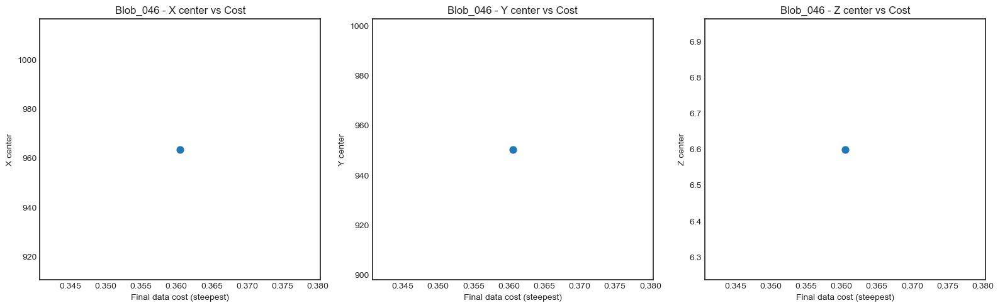


-------------------------------------
Blob: Blob_046
Minimum final data cost = 0.360537638035997
Best meshfile           = meshgrid_step006.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    961.4
xmax    965.8
ymin    948.2
ymax    952.6
zmin      4.4
zmax      8.8
Name: 45, dtype: object
-------------------------------------



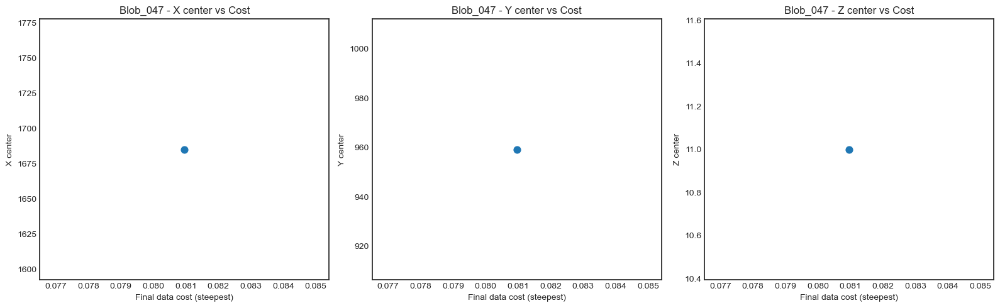


-------------------------------------
Blob: Blob_047
Minimum final data cost = 0.0809589119422538
Best meshfile           = meshgrid_step002.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1683.0
xmax    1687.4
ymin     957.0
ymax     961.4
zmin       8.8
zmax      13.2
Name: 46, dtype: object
-------------------------------------



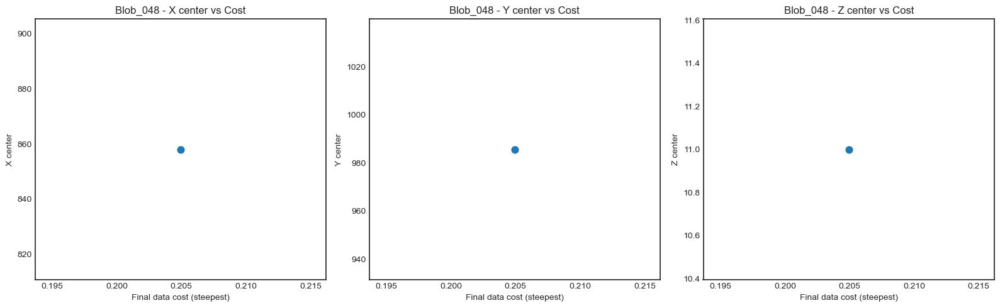


-------------------------------------
Blob: Blob_048
Minimum final data cost = 0.20493432058837108
Best meshfile           = meshgrid_step004.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    855.8
xmax    860.2
ymin    983.4
ymax    987.8
zmin      8.8
zmax     13.2
Name: 47, dtype: object
-------------------------------------



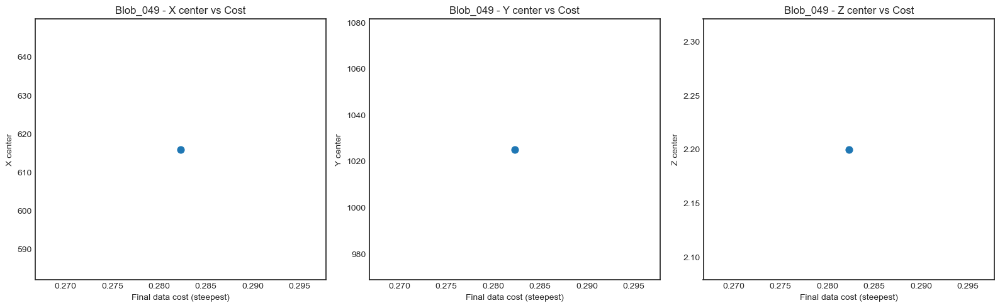


-------------------------------------
Blob: Blob_049
Minimum final data cost = 0.2822910658143018
Best meshfile           = meshgrid_step005.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin     613.8
xmax     618.2
ymin    1023.0
ymax    1027.4
zmin       0.0
zmax       4.4
Name: 48, dtype: object
-------------------------------------



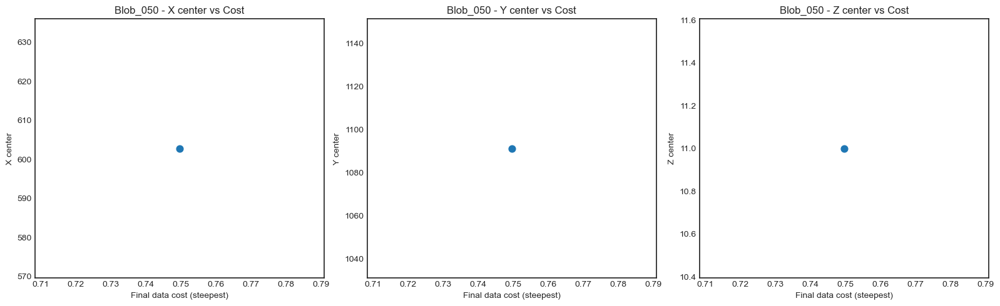


-------------------------------------
Blob: Blob_050
Minimum final data cost = 0.7496149720644445
Best meshfile           = meshgrid_step005.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin     600.6
xmax     605.0
ymin    1089.0
ymax    1093.4
zmin       8.8
zmax      13.2
Name: 49, dtype: object
-------------------------------------



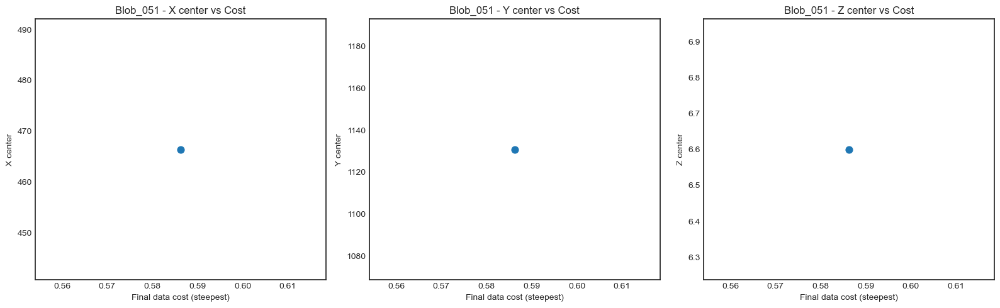


-------------------------------------
Blob: Blob_051
Minimum final data cost = 0.5862479419199011
Best meshfile           = meshgrid_step007.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin     464.2
xmax     468.6
ymin    1128.6
ymax    1133.0
zmin       4.4
zmax       8.8
Name: 50, dtype: object
-------------------------------------



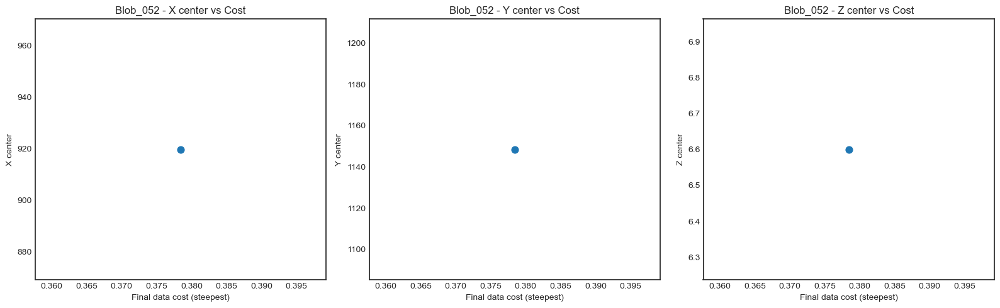


-------------------------------------
Blob: Blob_052
Minimum final data cost = 0.37843395720761847
Best meshfile           = meshgrid_step003.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin     917.4
xmax     921.8
ymin    1146.2
ymax    1150.6
zmin       4.4
zmax       8.8
Name: 51, dtype: object
-------------------------------------



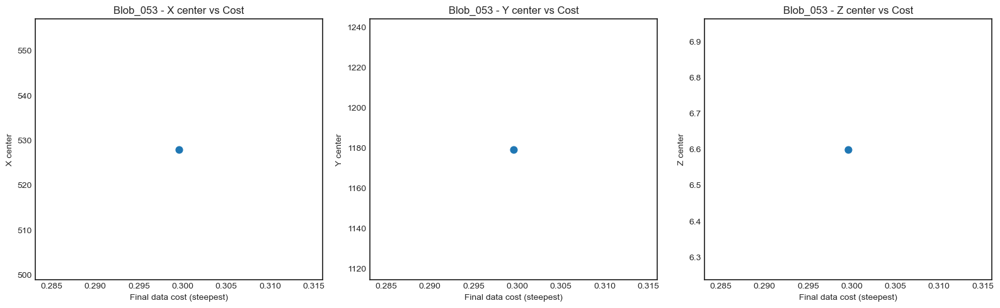


-------------------------------------
Blob: Blob_053
Minimum final data cost = 0.2995815433581426
Best meshfile           = meshgrid_step003.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin     525.8
xmax     530.2
ymin    1177.0
ymax    1181.4
zmin       4.4
zmax       8.8
Name: 52, dtype: object
-------------------------------------



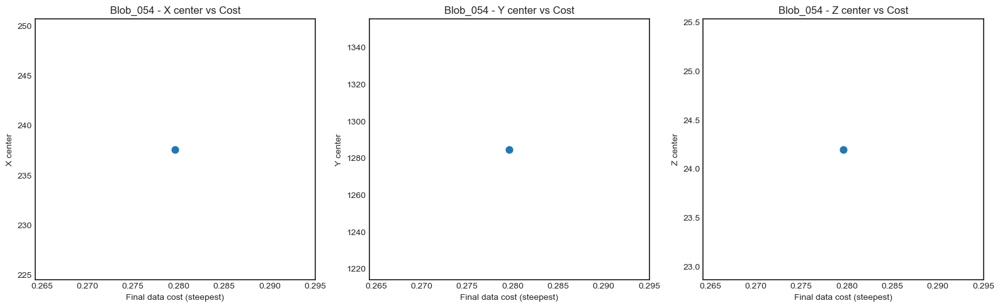


-------------------------------------
Blob: Blob_054
Minimum final data cost = 0.27962834496365363
Best meshfile           = meshgrid_step003.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin     235.4
xmax     239.8
ymin    1282.6
ymax    1287.0
zmin      22.0
zmax      26.4
Name: 53, dtype: object
-------------------------------------



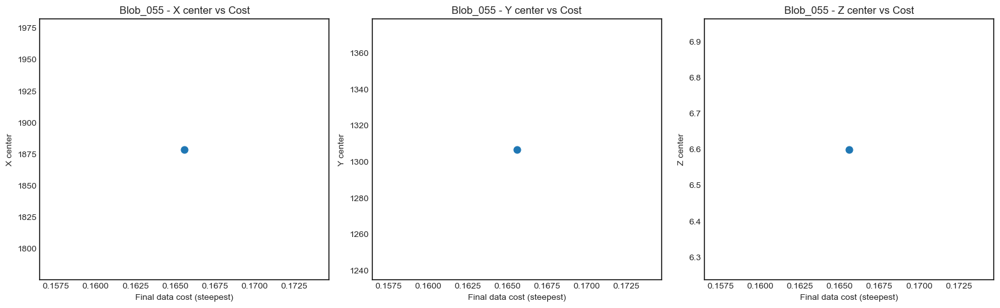


-------------------------------------
Blob: Blob_055
Minimum final data cost = 0.1655943567399107
Best meshfile           = meshgrid_step005.txt
Bounds xmin xmax ymin ymax zmin zmax:
xmin    1876.6
xmax    1881.0
ymin    1304.6
ymax    1309.0
zmin       4.4
zmax       8.8
Name: 54, dtype: object
-------------------------------------



In [28]:
# Plot Locations (per BLOB) — each blob is one grain

txt_path = os.path.join(
    base_dir,
    "4-Source_Detection",
    "Results_DataCost_Steepest",
    "best_per_blob_steepest.txt"
)

# columns:
# blob grain meshfile xmin xmax ymin ymax zmin zmax final_data_cost
colnames = ["blob","grain","meshfile","xmin","xmax","ymin","ymax","zmin","zmax","final_data_cost"]
df = pd.read_csv(txt_path, sep=r"\s+", names=colnames, comment="#")

# output folder
out_dir = os.path.join(base_dir, "4-Source_Detection", "Results_DataCost_Steepest")
os.makedirs(out_dir, exist_ok=True)

# loop blobs
for blob_name, bdf in df.groupby("blob"):

    bdf = bdf.copy()

    # drop NaNs (failed runs)
    bdf = bdf[np.isfinite(bdf["final_data_cost"])]
    if bdf.empty:
        print(f"{blob_name}: no valid costs (all NaN)")
        continue

    # centers
    bdf["x_center"] = 0.5 * (bdf["xmin"] + bdf["xmax"])
    bdf["y_center"] = 0.5 * (bdf["ymin"] + bdf["ymax"])
    bdf["z_center"] = 0.5 * (bdf["zmin"] + bdf["zmax"])

    data_cost = bdf["final_data_cost"].values

    # plots 
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    axes[0].scatter(data_cost, bdf["x_center"], s=60)
    axes[0].set_xlabel("Final data cost (steepest)")
    axes[0].set_ylabel("X center")
    axes[0].set_title(f"{blob_name} - X center vs Cost")

    axes[1].scatter(data_cost, bdf["y_center"], s=60)
    axes[1].set_xlabel("Final data cost (steepest)")
    axes[1].set_ylabel("Y center")
    axes[1].set_title(f"{blob_name} - Y center vs Cost")

    axes[2].scatter(data_cost, bdf["z_center"], s=60)
    axes[2].set_xlabel("Final data cost (steepest)")
    axes[2].set_ylabel("Z center")
    axes[2].set_title(f"{blob_name} - Z center vs Cost")

    plt.tight_layout()
    out_png = os.path.join(out_dir, f"Mini_Cost_{blob_name}.png")
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()

    # best for this blob (only row anyway)
    min_row = bdf.loc[bdf["final_data_cost"].idxmin()]
    print("\n-------------------------------------")
    print(f"Blob: {blob_name}")
    print("Minimum final data cost =", min_row["final_data_cost"])
    print("Best meshfile           =", min_row["meshfile"])
    print("Bounds xmin xmax ymin ymax zmin zmax:")
    print(min_row[["xmin","xmax","ymin","ymax","zmin","zmax"]])
    print("-------------------------------------\n")

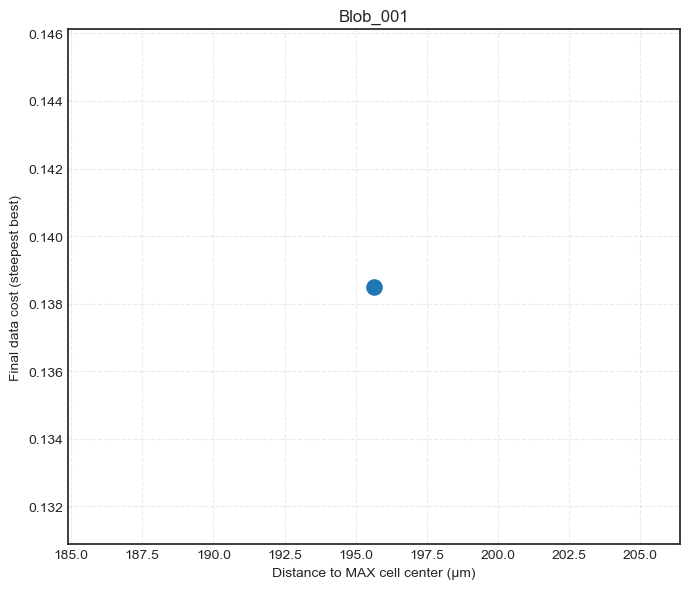


-------------------------------------
Blob: Blob_001
Final data cost (steepest) = 0.13850185127237363
Best meshfile              = meshgrid_step008.txt
Grain (from file)          = 1
Expected grain (blob#)     = 1
Distance to MAX cell       = 195.63925986365825
-------------------------------------



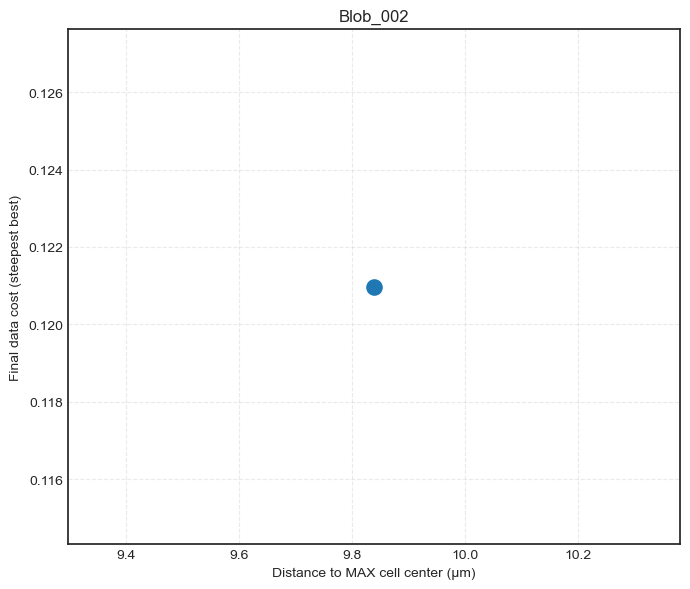


-------------------------------------
Blob: Blob_002
Final data cost (steepest) = 0.12097191983080716
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 2
Distance to MAX cell       = 9.838699100999033
-------------------------------------



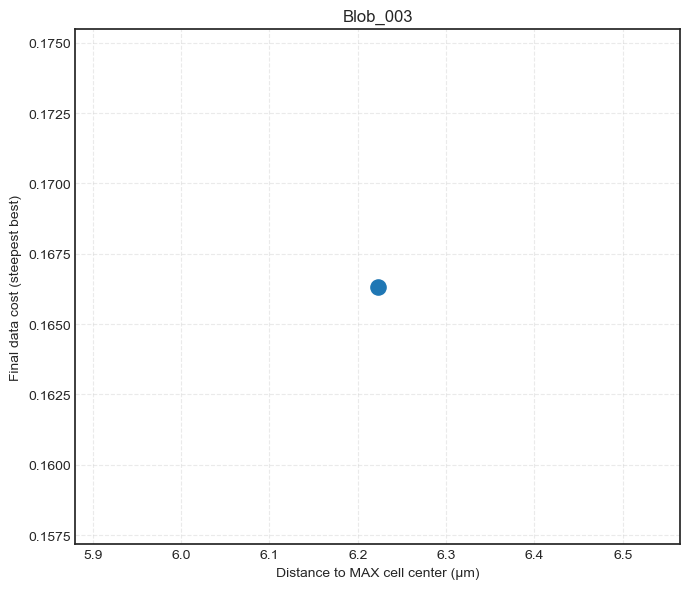


-------------------------------------
Blob: Blob_003
Final data cost (steepest) = 0.16632769720990373
Best meshfile              = meshgrid_step003.txt
Grain (from file)          = 1
Expected grain (blob#)     = 3
Distance to MAX cell       = 6.222539674441622
-------------------------------------



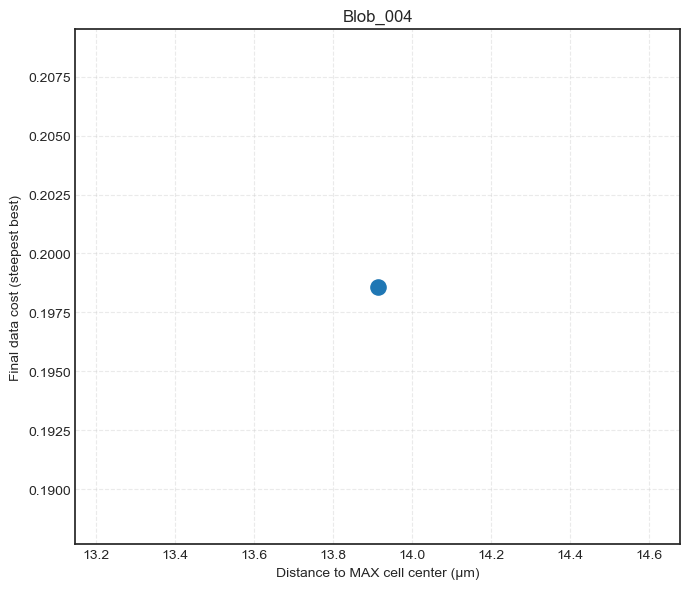


-------------------------------------
Blob: Blob_004
Final data cost (steepest) = 0.19858686556537936
Best meshfile              = meshgrid_step003.txt
Grain (from file)          = 1
Expected grain (blob#)     = 4
Distance to MAX cell       = 13.91402170474087
-------------------------------------



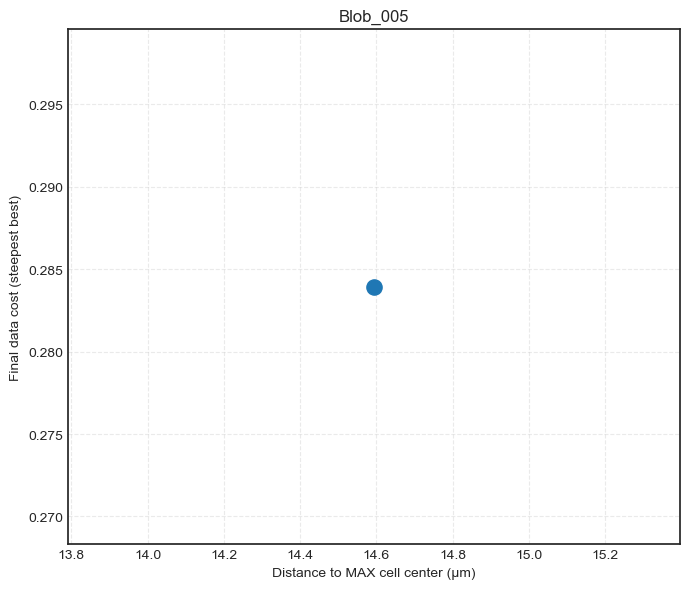


-------------------------------------
Blob: Blob_005
Final data cost (steepest) = 0.2839357429187462
Best meshfile              = meshgrid_step006.txt
Grain (from file)          = 1
Expected grain (blob#)     = 5
Distance to MAX cell       = 14.59314907756381
-------------------------------------



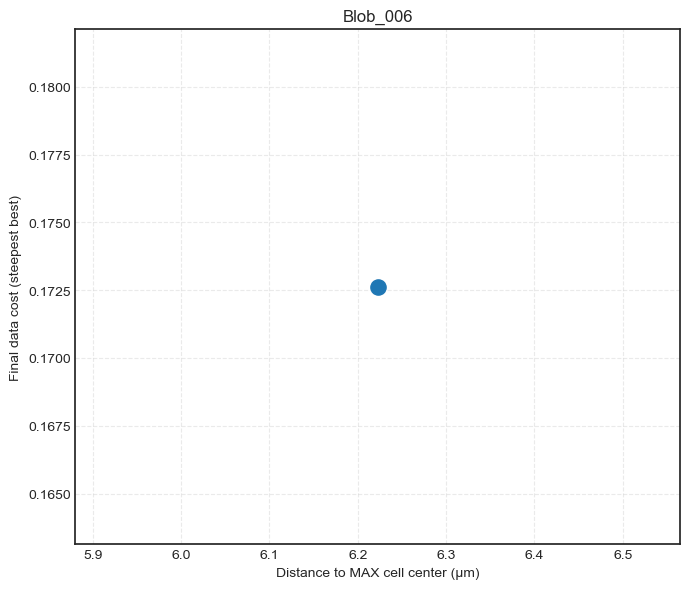


-------------------------------------
Blob: Blob_006
Final data cost (steepest) = 0.1726255850699723
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 6
Distance to MAX cell       = 6.222539674441602
-------------------------------------



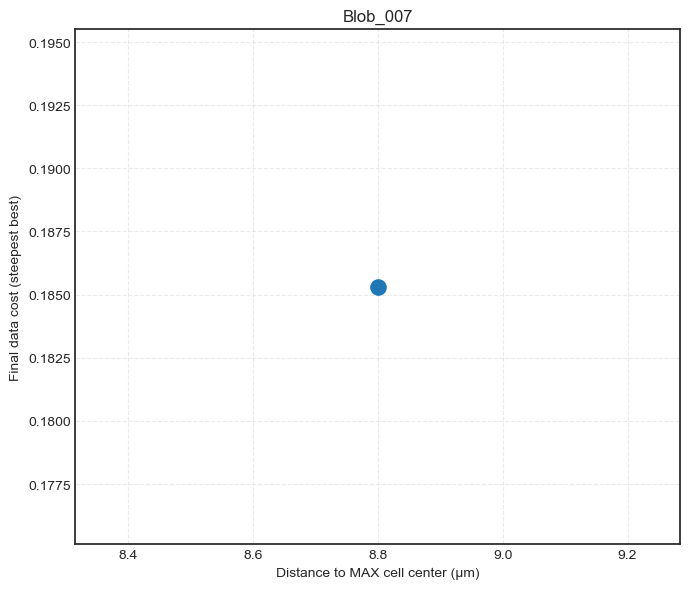


-------------------------------------
Blob: Blob_007
Final data cost (steepest) = 0.18530985402963893
Best meshfile              = meshgrid_step001.txt
Grain (from file)          = 1
Expected grain (blob#)     = 7
Distance to MAX cell       = 8.799999999999955
-------------------------------------



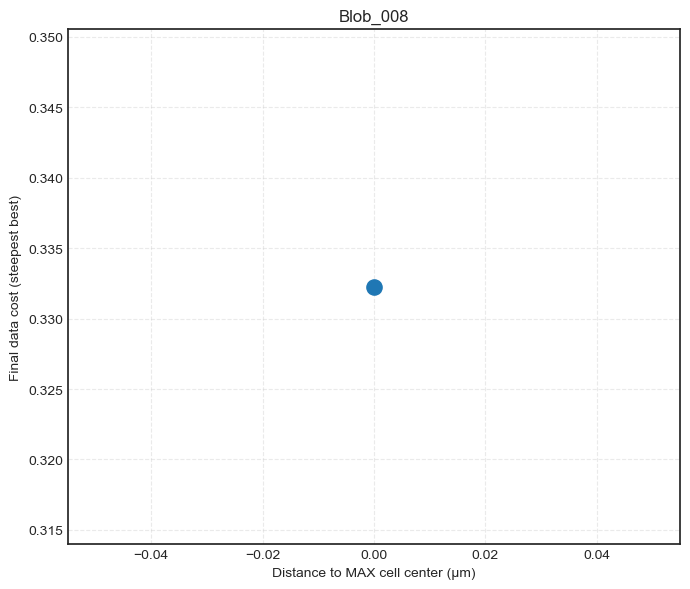


-------------------------------------
Blob: Blob_008
Final data cost (steepest) = 0.33225980748070766
Best meshfile              = meshgrid_step004.txt
Grain (from file)          = 1
Expected grain (blob#)     = 8
Distance to MAX cell       = 0.0
-------------------------------------



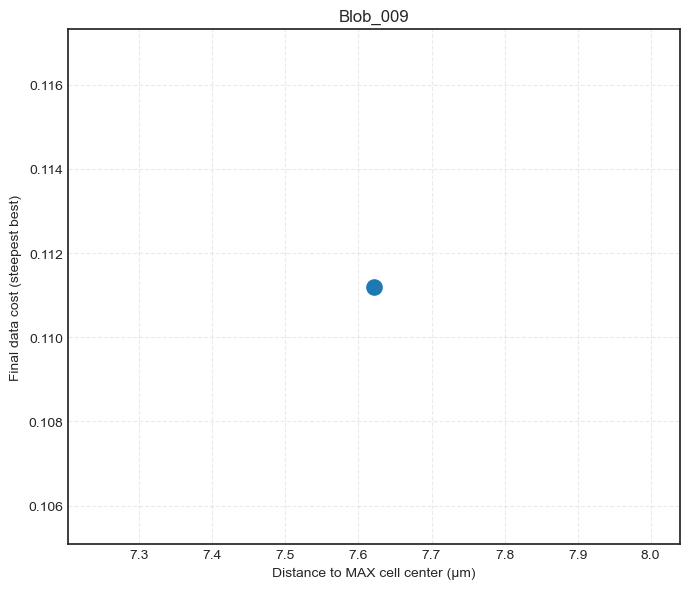


-------------------------------------
Blob: Blob_009
Final data cost (steepest) = 0.11120019528712174
Best meshfile              = meshgrid_step004.txt
Grain (from file)          = 1
Expected grain (blob#)     = 9
Distance to MAX cell       = 7.621023553303034
-------------------------------------



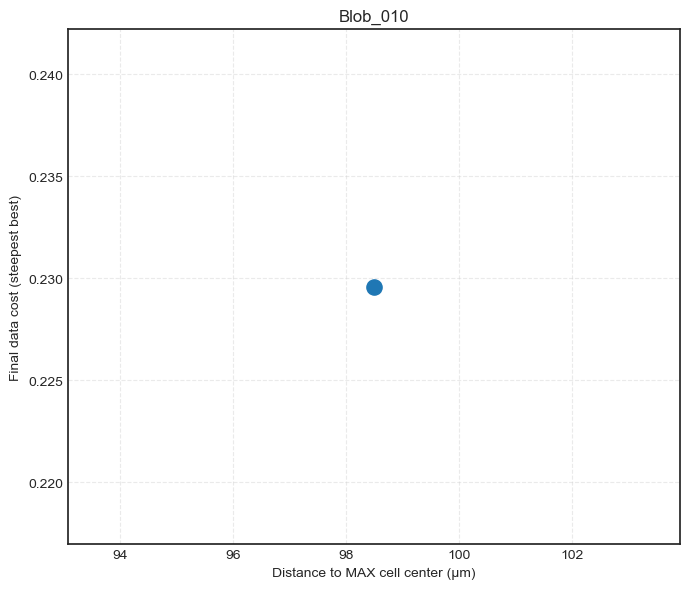


-------------------------------------
Blob: Blob_010
Final data cost (steepest) = 0.22958051963881712
Best meshfile              = meshgrid_step009.txt
Grain (from file)          = 1
Expected grain (blob#)     = 10
Distance to MAX cell       = 98.48532885663734
-------------------------------------



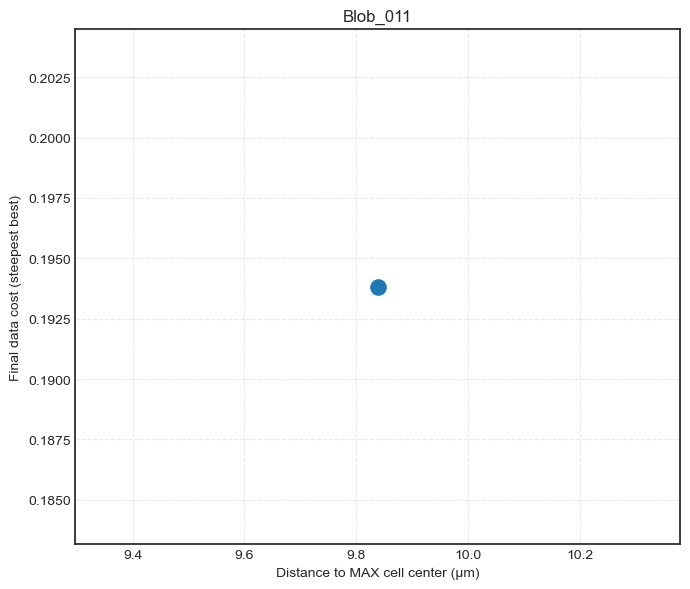


-------------------------------------
Blob: Blob_011
Final data cost (steepest) = 0.19382268296762264
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 11
Distance to MAX cell       = 9.83869910099905
-------------------------------------



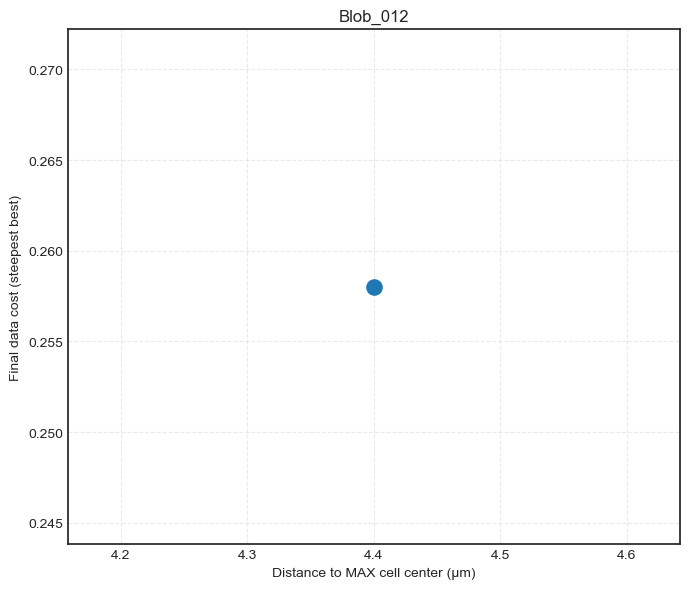


-------------------------------------
Blob: Blob_012
Final data cost (steepest) = 0.2580172899640566
Best meshfile              = meshgrid_step004.txt
Grain (from file)          = 1
Expected grain (blob#)     = 12
Distance to MAX cell       = 4.399999999999977
-------------------------------------



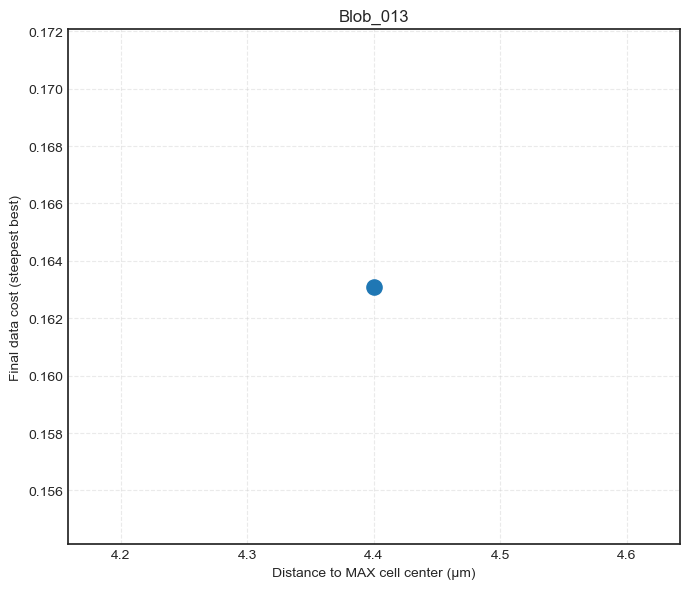


-------------------------------------
Blob: Blob_013
Final data cost (steepest) = 0.16309795407460406
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 13
Distance to MAX cell       = 4.400000000000091
-------------------------------------



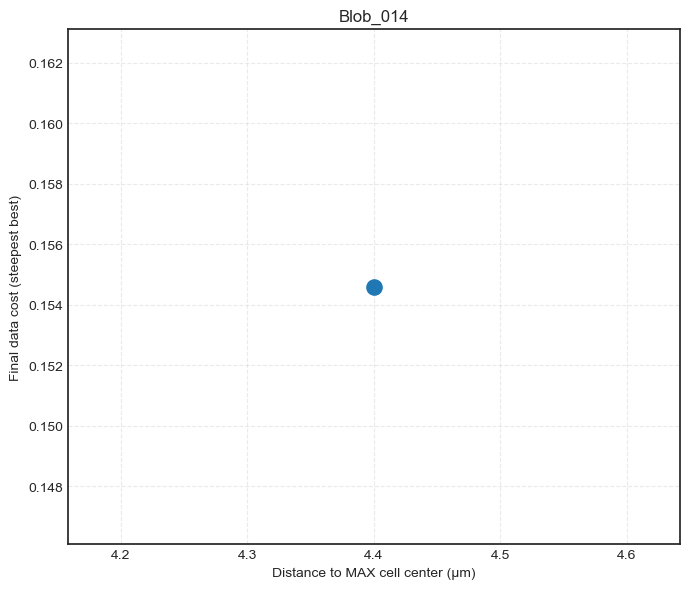


-------------------------------------
Blob: Blob_014
Final data cost (steepest) = 0.15459550667071614
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 14
Distance to MAX cell       = 4.399999999999977
-------------------------------------



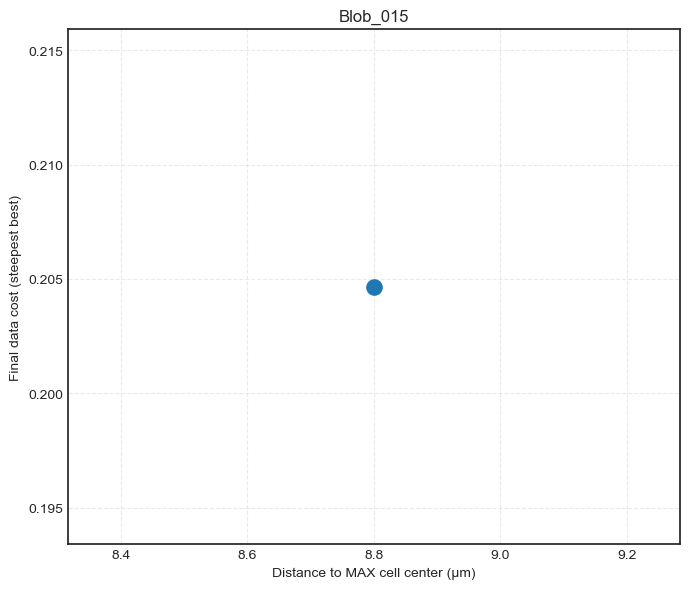


-------------------------------------
Blob: Blob_015
Final data cost (steepest) = 0.20466059269973827
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 15
Distance to MAX cell       = 8.799999999999955
-------------------------------------



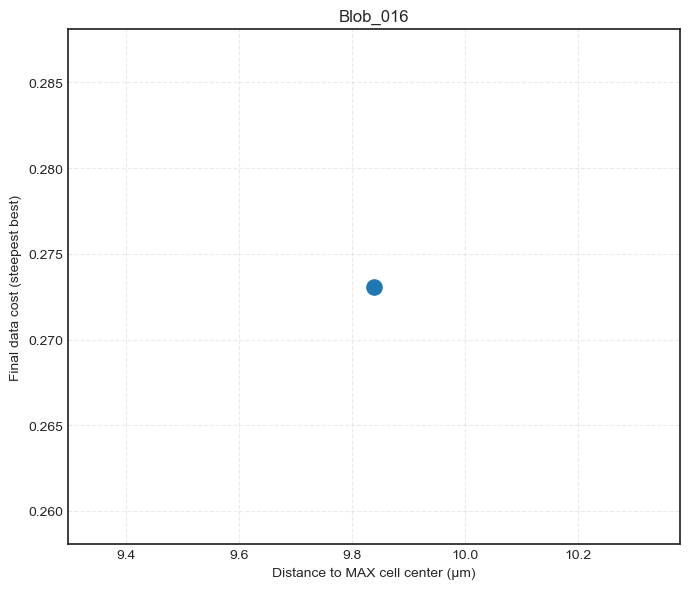


-------------------------------------
Blob: Blob_016
Final data cost (steepest) = 0.27308067493811705
Best meshfile              = meshgrid_step004.txt
Grain (from file)          = 1
Expected grain (blob#)     = 16
Distance to MAX cell       = 9.838699100999085
-------------------------------------



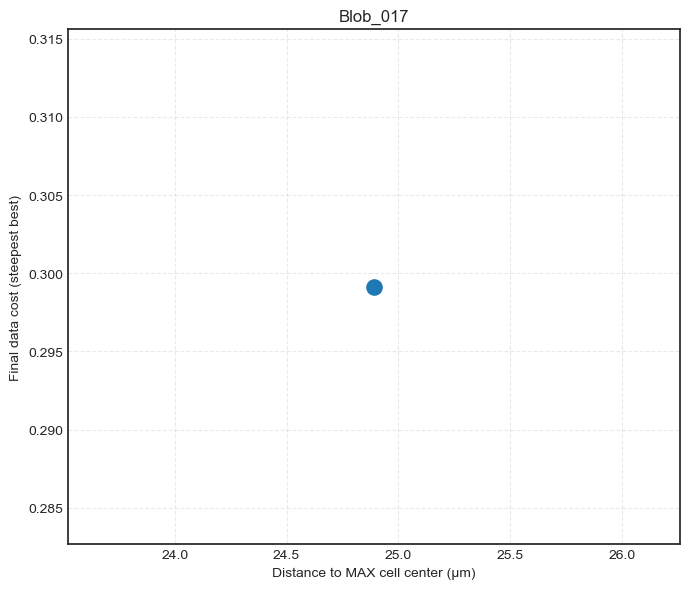


-------------------------------------
Blob: Blob_017
Final data cost (steepest) = 0.2991368069810912
Best meshfile              = meshgrid_step009.txt
Grain (from file)          = 1
Expected grain (blob#)     = 17
Distance to MAX cell       = 24.89015869776645
-------------------------------------



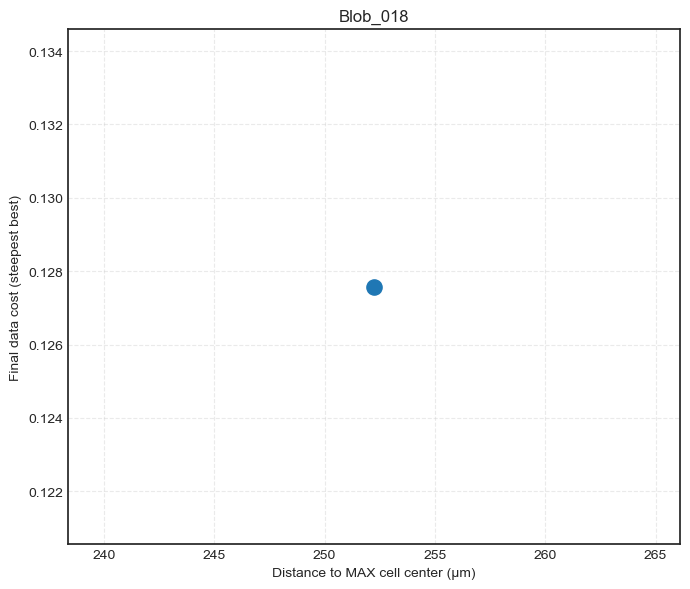


-------------------------------------
Blob: Blob_018
Final data cost (steepest) = 0.12757463330802124
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 18
Distance to MAX cell       = 252.23069571426078
-------------------------------------



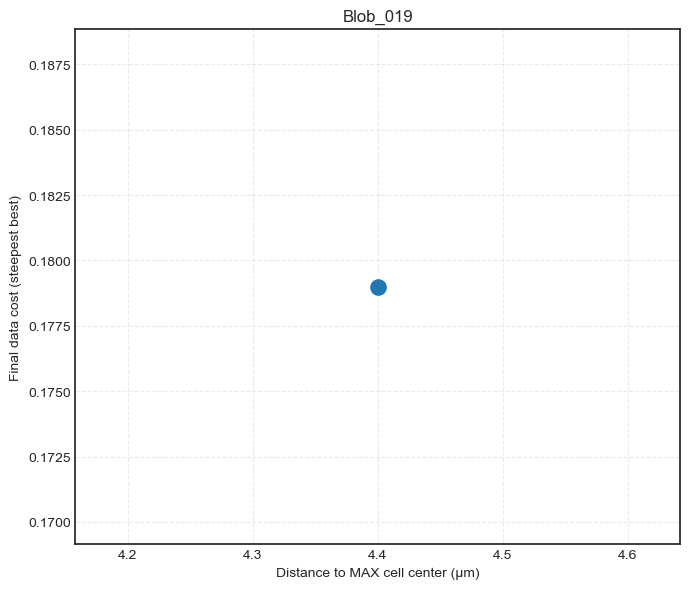


-------------------------------------
Blob: Blob_019
Final data cost (steepest) = 0.17899390057746525
Best meshfile              = meshgrid_step001.txt
Grain (from file)          = 1
Expected grain (blob#)     = 19
Distance to MAX cell       = 4.400000000000034
-------------------------------------



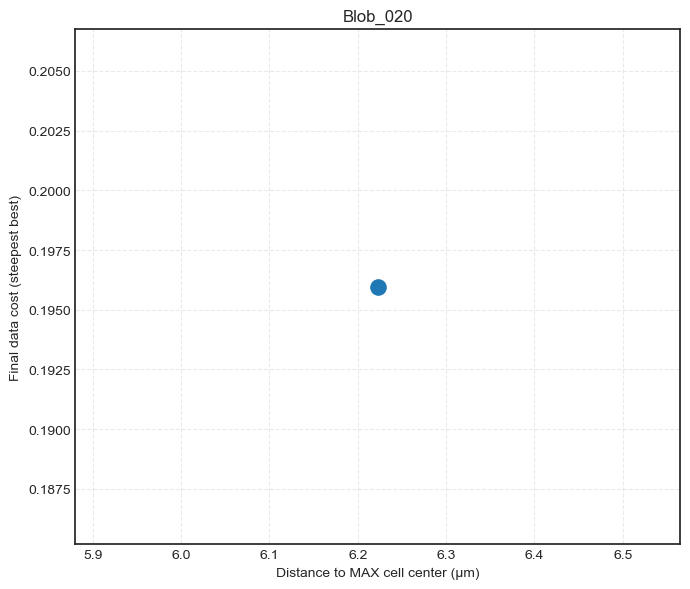


-------------------------------------
Blob: Blob_020
Final data cost (steepest) = 0.1959630647367916
Best meshfile              = meshgrid_step006.txt
Grain (from file)          = 1
Expected grain (blob#)     = 20
Distance to MAX cell       = 6.222539674441666
-------------------------------------



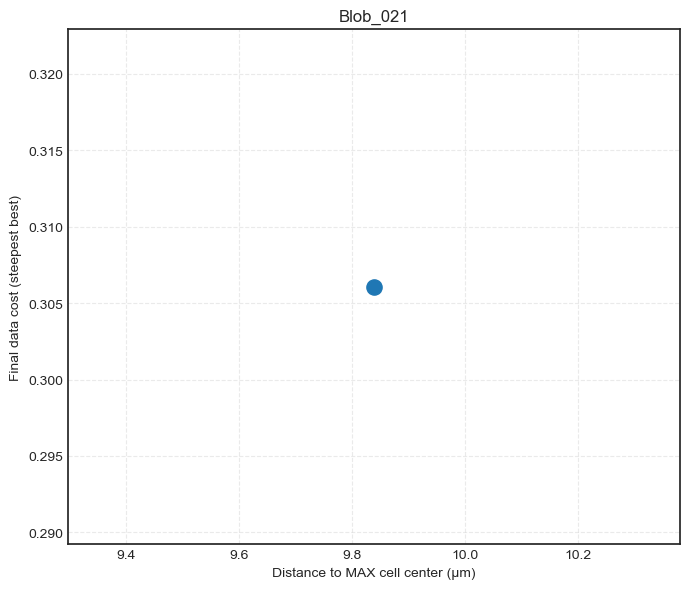


-------------------------------------
Blob: Blob_021
Final data cost (steepest) = 0.3060658814374878
Best meshfile              = meshgrid_step001.txt
Grain (from file)          = 1
Expected grain (blob#)     = 21
Distance to MAX cell       = 9.838699100999085
-------------------------------------



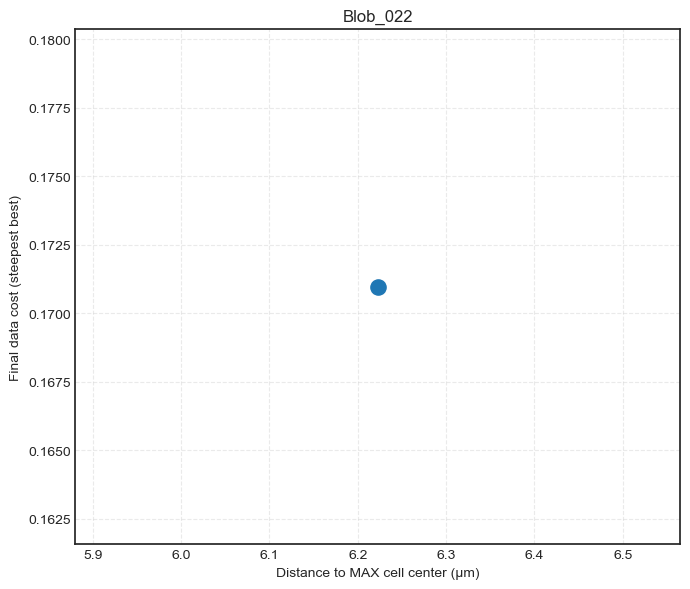


-------------------------------------
Blob: Blob_022
Final data cost (steepest) = 0.17096621203851525
Best meshfile              = meshgrid_step001.txt
Grain (from file)          = 1
Expected grain (blob#)     = 22
Distance to MAX cell       = 6.2225396744415225
-------------------------------------



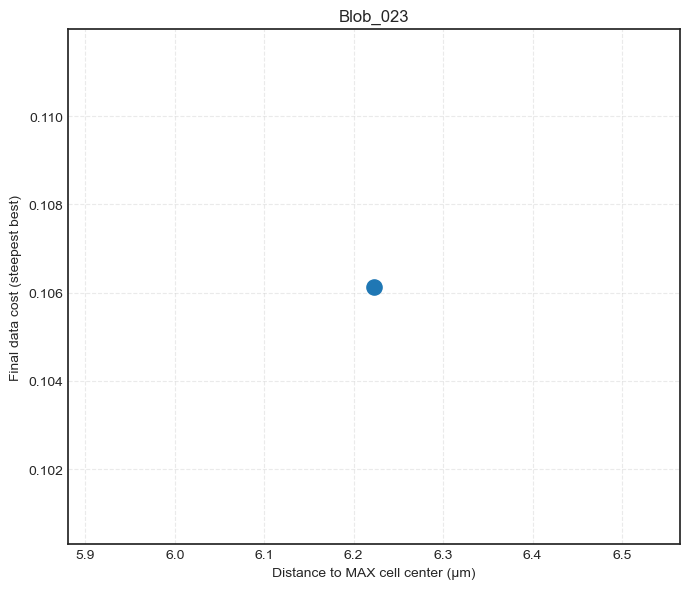


-------------------------------------
Blob: Blob_023
Final data cost (steepest) = 0.10613473406866838
Best meshfile              = meshgrid_step004.txt
Grain (from file)          = 1
Expected grain (blob#)     = 23
Distance to MAX cell       = 6.222539674441666
-------------------------------------



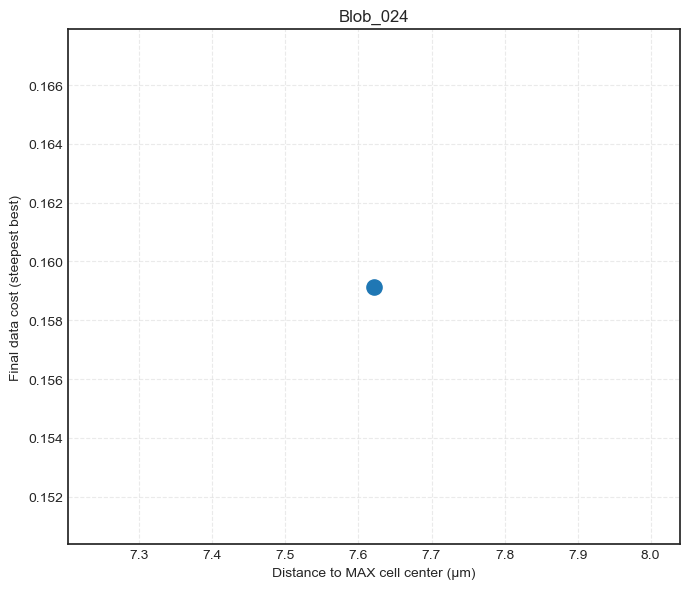


-------------------------------------
Blob: Blob_024
Final data cost (steepest) = 0.1591410807512898
Best meshfile              = meshgrid_step003.txt
Grain (from file)          = 1
Expected grain (blob#)     = 24
Distance to MAX cell       = 7.621023553303034
-------------------------------------



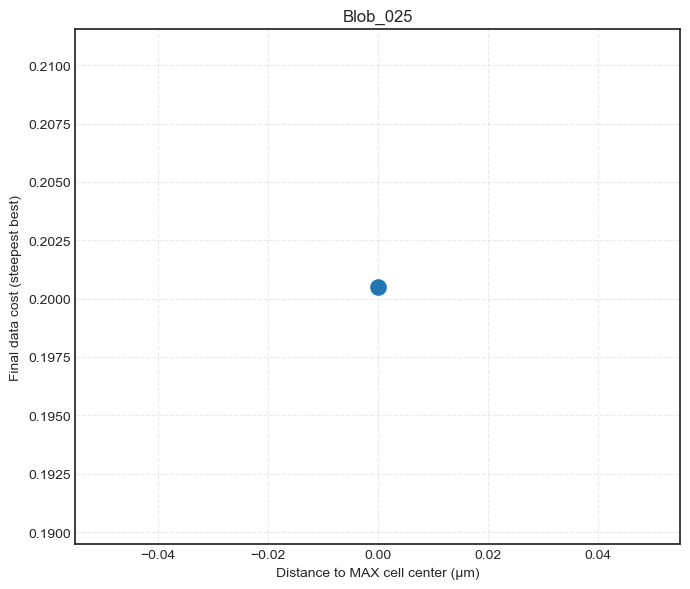


-------------------------------------
Blob: Blob_025
Final data cost (steepest) = 0.2005085860926331
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 25
Distance to MAX cell       = 0.0
-------------------------------------



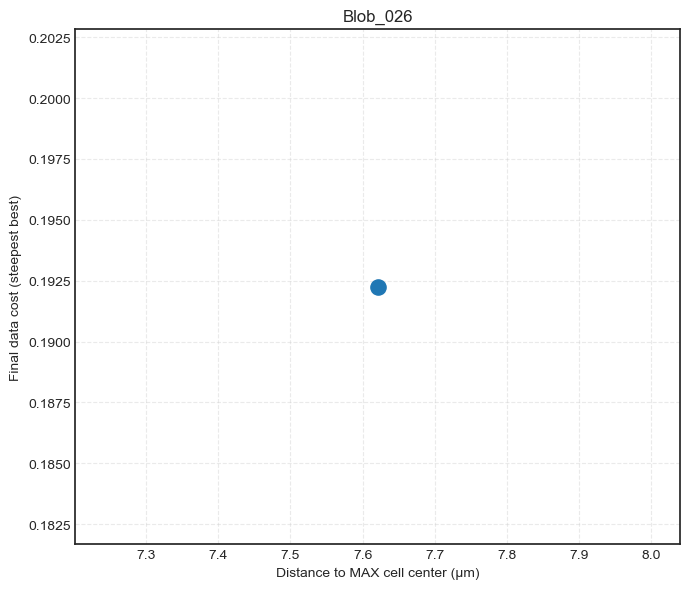


-------------------------------------
Blob: Blob_026
Final data cost (steepest) = 0.19225108385873568
Best meshfile              = meshgrid_step004.txt
Grain (from file)          = 1
Expected grain (blob#)     = 26
Distance to MAX cell       = 7.621023553303034
-------------------------------------



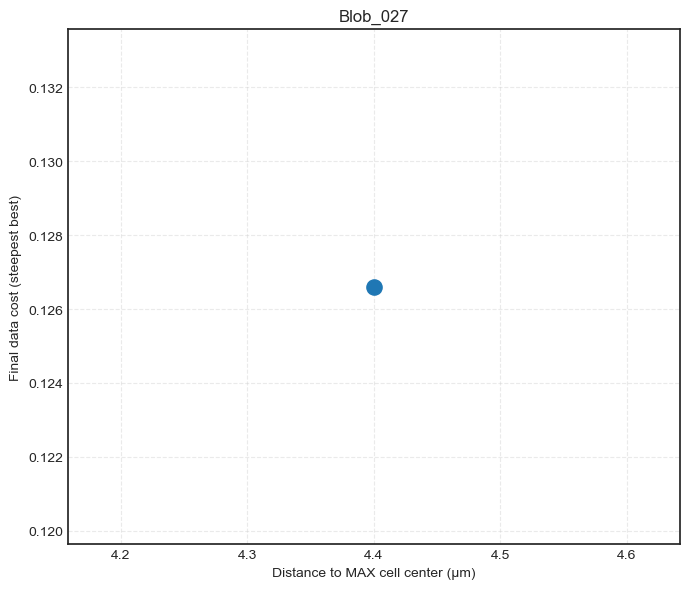


-------------------------------------
Blob: Blob_027
Final data cost (steepest) = 0.12660294978295789
Best meshfile              = meshgrid_step004.txt
Grain (from file)          = 1
Expected grain (blob#)     = 27
Distance to MAX cell       = 4.399999999999864
-------------------------------------



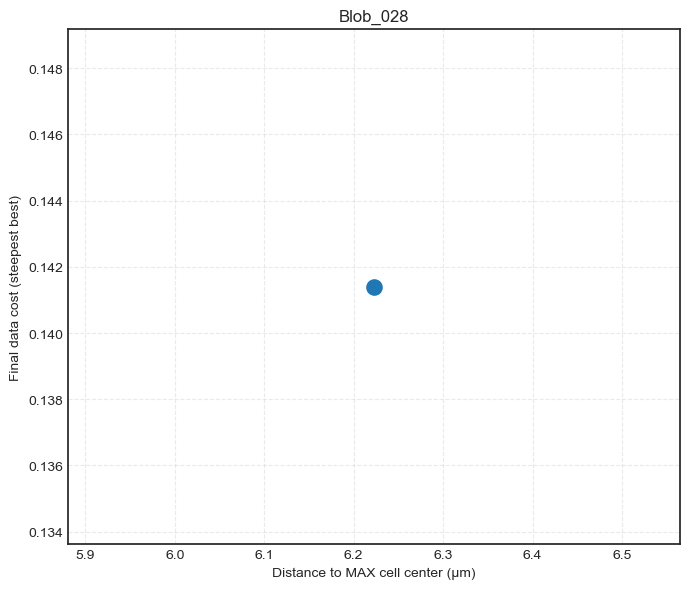


-------------------------------------
Blob: Blob_028
Final data cost (steepest) = 0.14139815809529846
Best meshfile              = meshgrid_step001.txt
Grain (from file)          = 1
Expected grain (blob#)     = 28
Distance to MAX cell       = 6.222539674441682
-------------------------------------



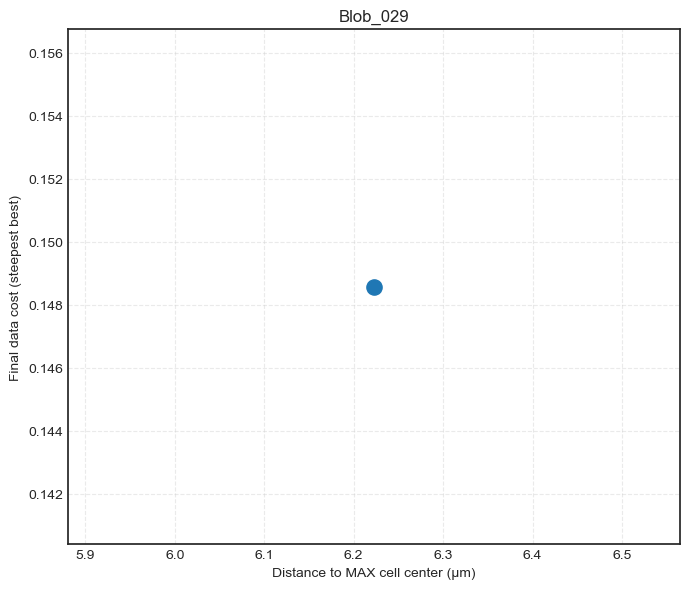


-------------------------------------
Blob: Blob_029
Final data cost (steepest) = 0.14857705357695097
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 29
Distance to MAX cell       = 6.222539674441746
-------------------------------------



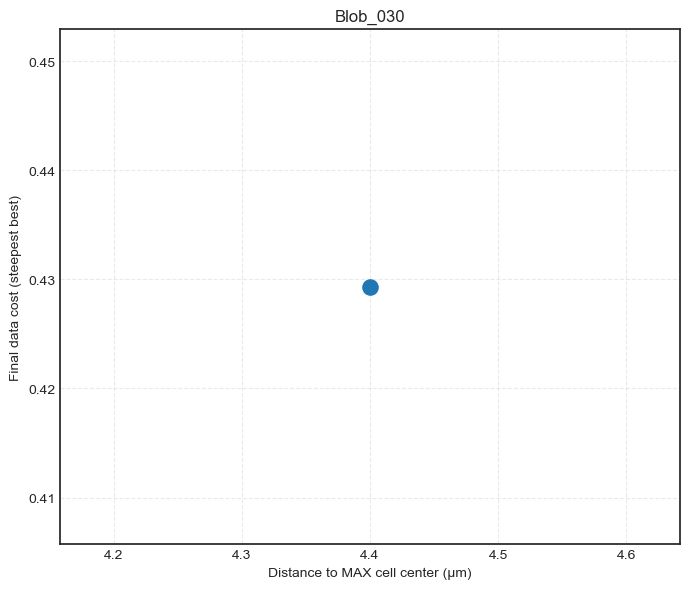


-------------------------------------
Blob: Blob_030
Final data cost (steepest) = 0.4293316314526925
Best meshfile              = meshgrid_step005.txt
Grain (from file)          = 1
Expected grain (blob#)     = 30
Distance to MAX cell       = 4.399999999999864
-------------------------------------



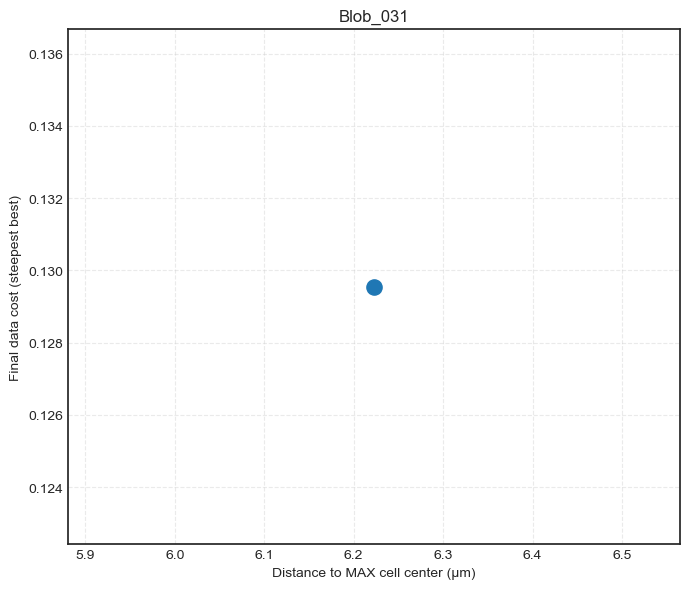


-------------------------------------
Blob: Blob_031
Final data cost (steepest) = 0.129547728676774
Best meshfile              = meshgrid_step001.txt
Grain (from file)          = 1
Expected grain (blob#)     = 31
Distance to MAX cell       = 6.222539674441682
-------------------------------------



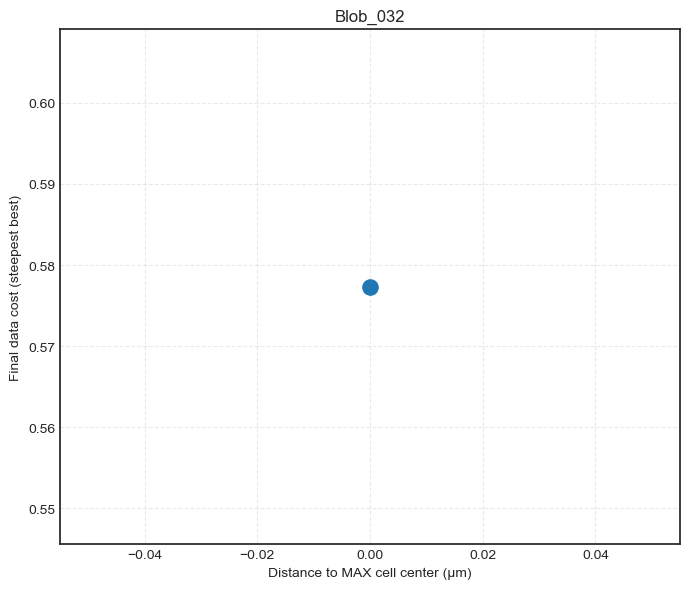


-------------------------------------
Blob: Blob_032
Final data cost (steepest) = 0.577324586736625
Best meshfile              = meshgrid_step005.txt
Grain (from file)          = 1
Expected grain (blob#)     = 32
Distance to MAX cell       = 0.0
-------------------------------------



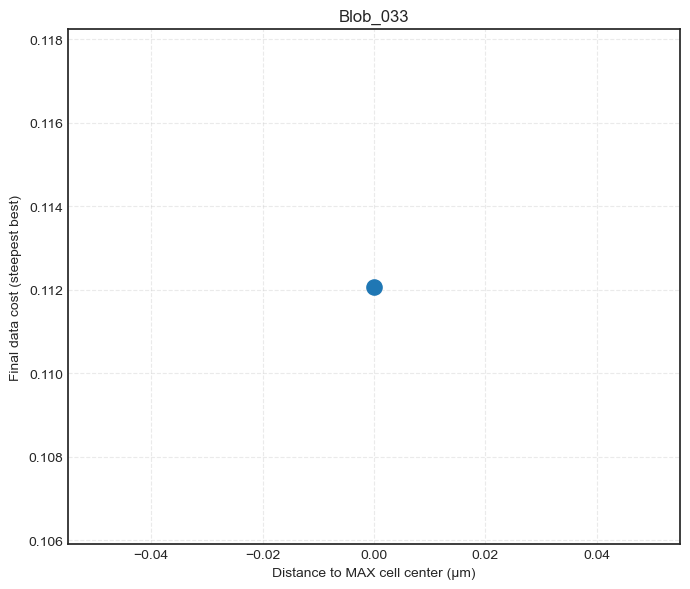


-------------------------------------
Blob: Blob_033
Final data cost (steepest) = 0.11206927286666468
Best meshfile              = meshgrid_step001.txt
Grain (from file)          = 1
Expected grain (blob#)     = 33
Distance to MAX cell       = 0.0
-------------------------------------



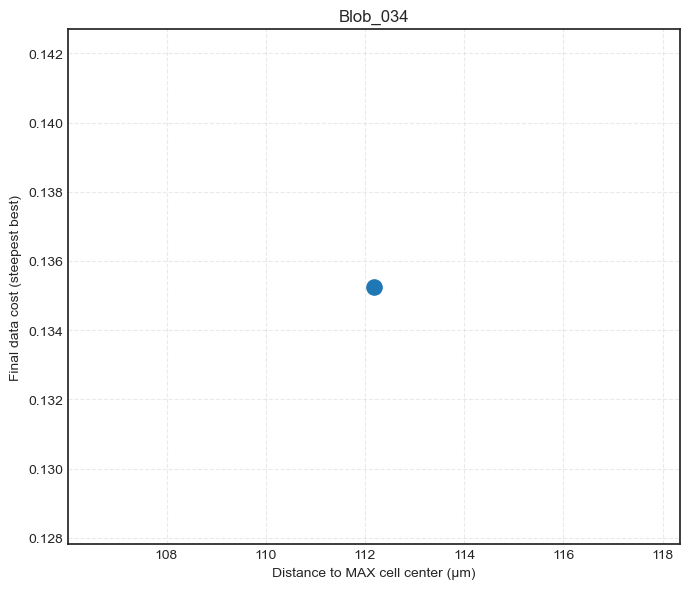


-------------------------------------
Blob: Blob_034
Final data cost (steepest) = 0.13525431366082405
Best meshfile              = meshgrid_step009.txt
Grain (from file)          = 1
Expected grain (blob#)     = 34
Distance to MAX cell       = 112.17842929904128
-------------------------------------



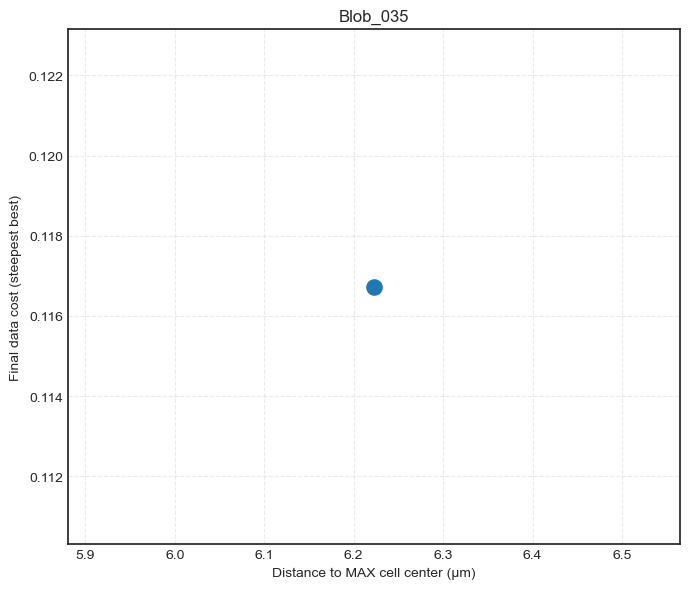


-------------------------------------
Blob: Blob_035
Final data cost (steepest) = 0.1167290671555663
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 35
Distance to MAX cell       = 6.222539674441682
-------------------------------------



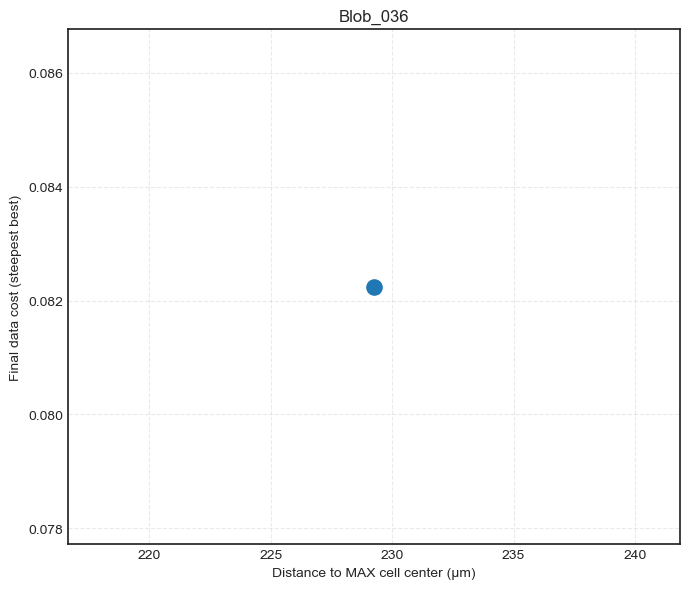


-------------------------------------
Blob: Blob_036
Final data cost (steepest) = 0.08224164330207585
Best meshfile              = meshgrid_step007.txt
Grain (from file)          = 1
Expected grain (blob#)     = 36
Distance to MAX cell       = 229.24849792310528
-------------------------------------



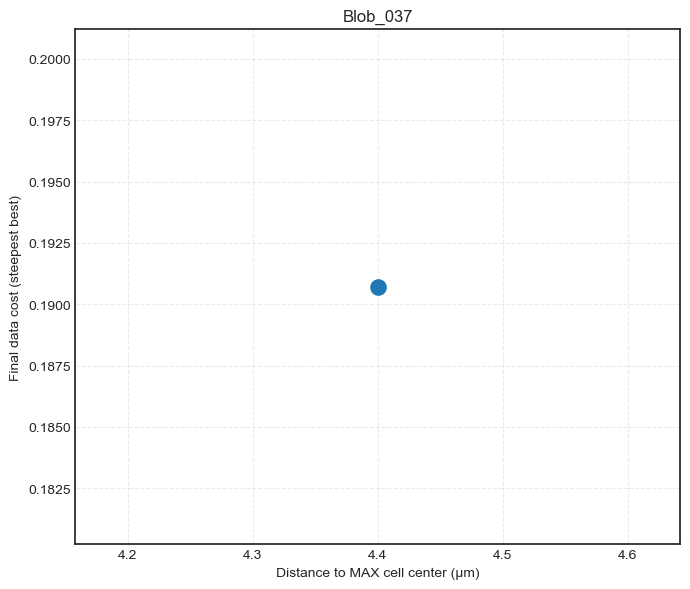


-------------------------------------
Blob: Blob_037
Final data cost (steepest) = 0.19071210070415975
Best meshfile              = meshgrid_step003.txt
Grain (from file)          = 1
Expected grain (blob#)     = 37
Distance to MAX cell       = 4.400000000000091
-------------------------------------



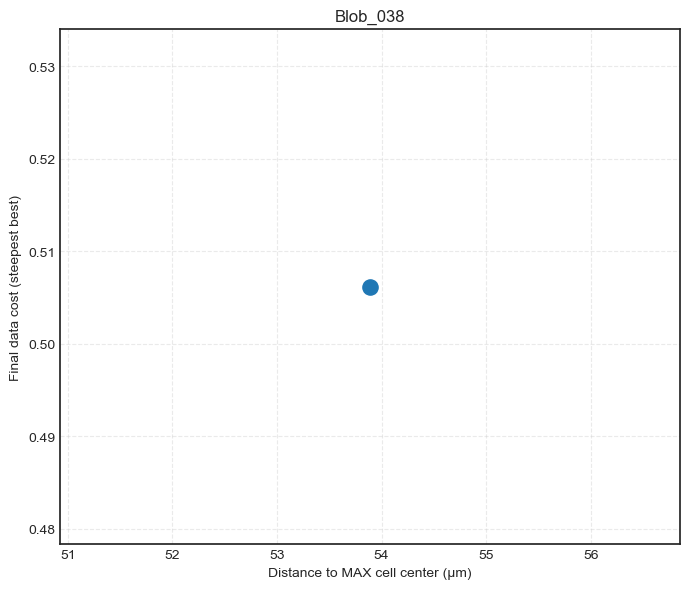


-------------------------------------
Blob: Blob_038
Final data cost (steepest) = 0.506167541365674
Best meshfile              = meshgrid_step022.txt
Grain (from file)          = 1
Expected grain (blob#)     = 38
Distance to MAX cell       = 53.888774341229926
-------------------------------------



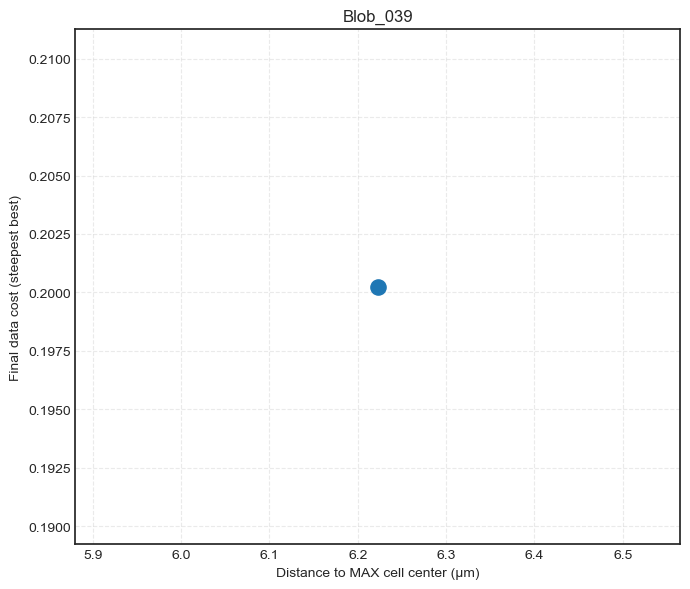


-------------------------------------
Blob: Blob_039
Final data cost (steepest) = 0.2002404175693673
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 39
Distance to MAX cell       = 6.222539674441682
-------------------------------------



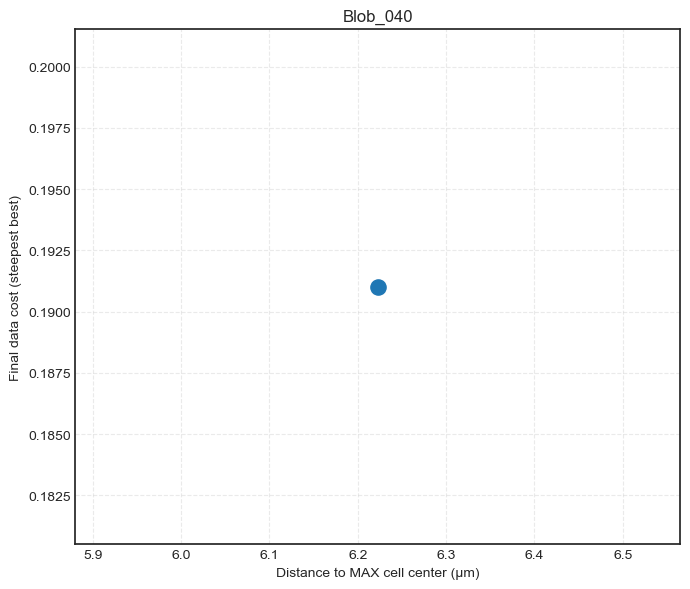


-------------------------------------
Blob: Blob_040
Final data cost (steepest) = 0.1910142147387381
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 40
Distance to MAX cell       = 6.222539674441682
-------------------------------------



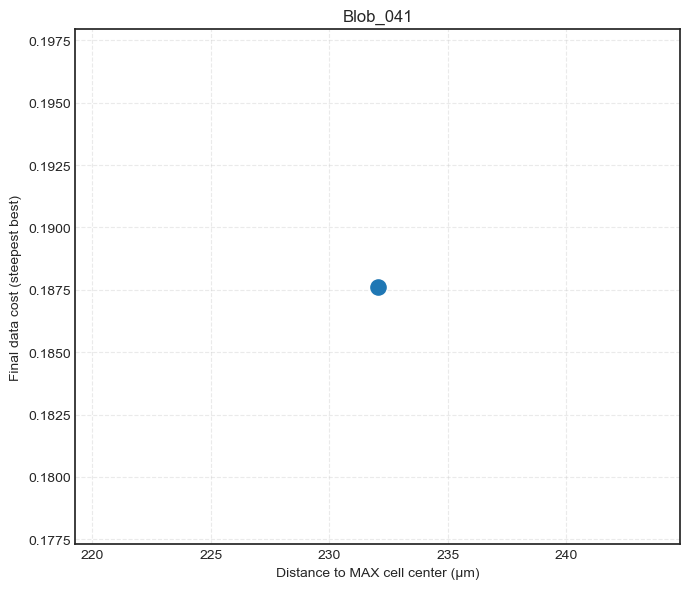


-------------------------------------
Blob: Blob_041
Final data cost (steepest) = 0.18762217254426233
Best meshfile              = meshgrid_step006.txt
Grain (from file)          = 1
Expected grain (blob#)     = 41
Distance to MAX cell       = 232.04584646413227
-------------------------------------



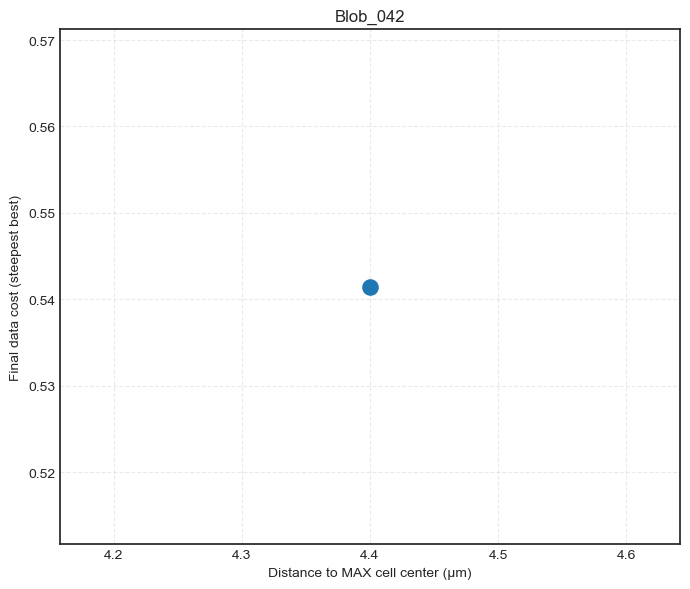


-------------------------------------
Blob: Blob_042
Final data cost (steepest) = 0.5414589423543249
Best meshfile              = meshgrid_step004.txt
Grain (from file)          = 1
Expected grain (blob#)     = 42
Distance to MAX cell       = 4.400000000000091
-------------------------------------



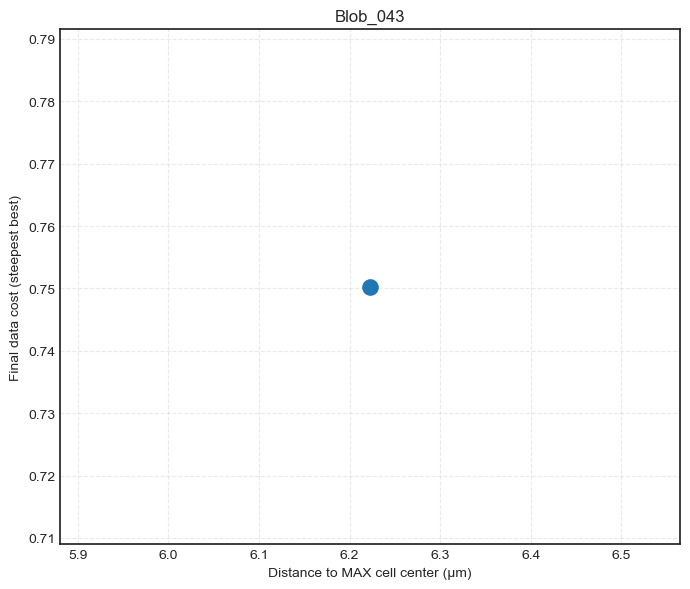


-------------------------------------
Blob: Blob_043
Final data cost (steepest) = 0.7502691649711604
Best meshfile              = meshgrid_step005.txt
Grain (from file)          = 1
Expected grain (blob#)     = 43
Distance to MAX cell       = 6.222539674441666
-------------------------------------



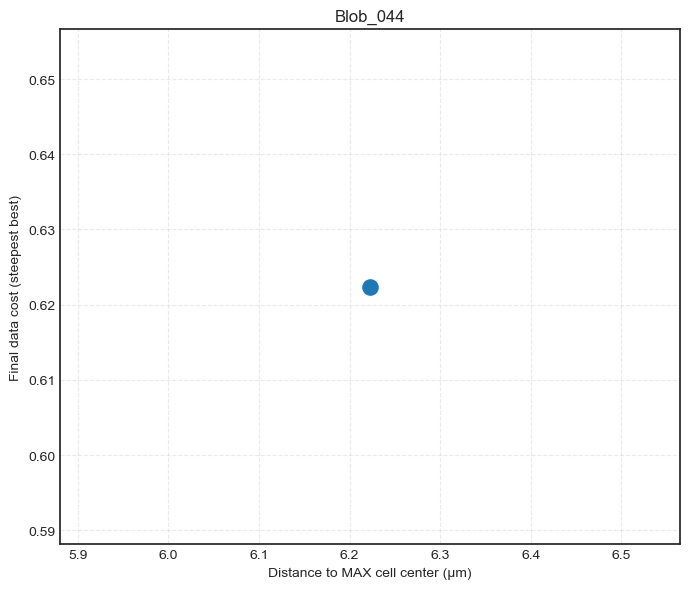


-------------------------------------
Blob: Blob_044
Final data cost (steepest) = 0.6223770980554816
Best meshfile              = meshgrid_step006.txt
Grain (from file)          = 1
Expected grain (blob#)     = 44
Distance to MAX cell       = 6.222539674441682
-------------------------------------



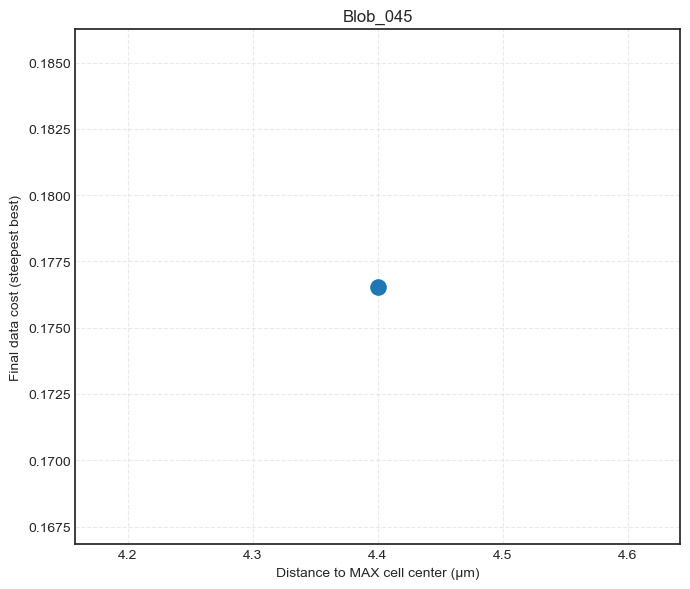


-------------------------------------
Blob: Blob_045
Final data cost (steepest) = 0.17654428116969176
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 45
Distance to MAX cell       = 4.399999999999864
-------------------------------------



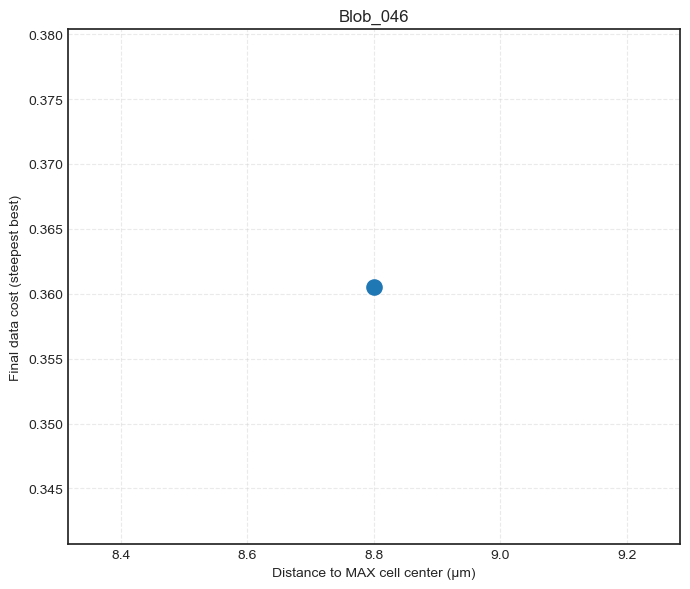


-------------------------------------
Blob: Blob_046
Final data cost (steepest) = 0.360537638035997
Best meshfile              = meshgrid_step006.txt
Grain (from file)          = 1
Expected grain (blob#)     = 46
Distance to MAX cell       = 8.799999999999955
-------------------------------------



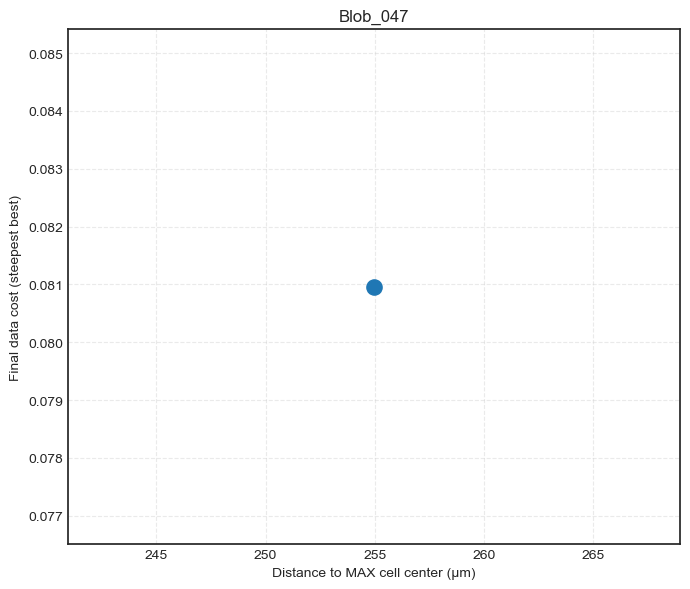


-------------------------------------
Blob: Blob_047
Final data cost (steepest) = 0.0809589119422538
Best meshfile              = meshgrid_step002.txt
Grain (from file)          = 1
Expected grain (blob#)     = 47
Distance to MAX cell       = 254.95603441819623
-------------------------------------



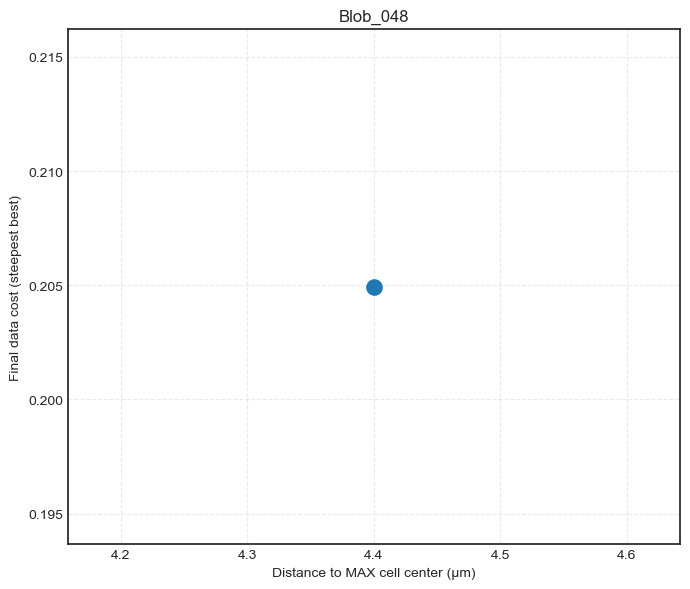


-------------------------------------
Blob: Blob_048
Final data cost (steepest) = 0.20493432058837108
Best meshfile              = meshgrid_step004.txt
Grain (from file)          = 1
Expected grain (blob#)     = 48
Distance to MAX cell       = 4.400000000000091
-------------------------------------



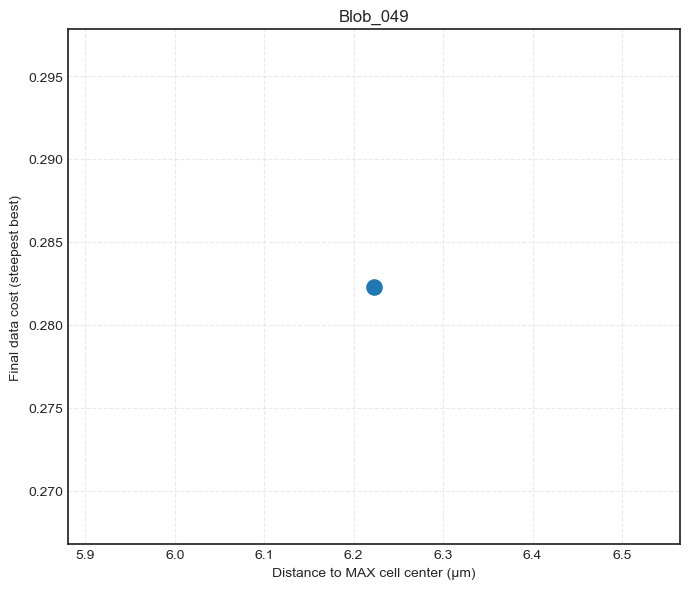


-------------------------------------
Blob: Blob_049
Final data cost (steepest) = 0.2822910658143018
Best meshfile              = meshgrid_step005.txt
Grain (from file)          = 1
Expected grain (blob#)     = 49
Distance to MAX cell       = 6.222539674441682
-------------------------------------



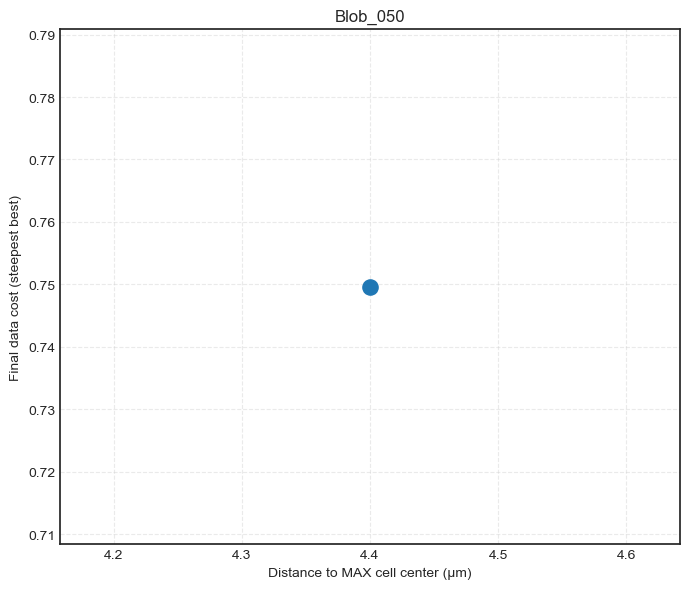


-------------------------------------
Blob: Blob_050
Final data cost (steepest) = 0.7496149720644445
Best meshfile              = meshgrid_step005.txt
Grain (from file)          = 1
Expected grain (blob#)     = 50
Distance to MAX cell       = 4.3999999999999995
-------------------------------------



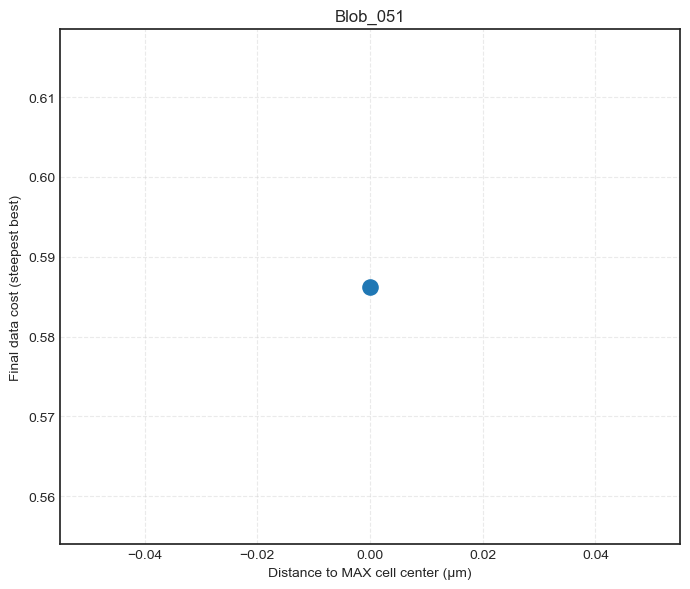


-------------------------------------
Blob: Blob_051
Final data cost (steepest) = 0.5862479419199011
Best meshfile              = meshgrid_step007.txt
Grain (from file)          = 1
Expected grain (blob#)     = 51
Distance to MAX cell       = 0.0
-------------------------------------



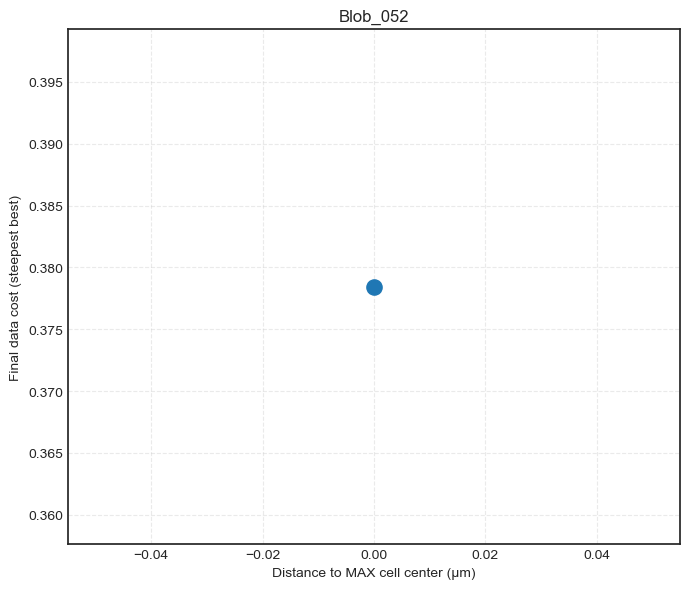


-------------------------------------
Blob: Blob_052
Final data cost (steepest) = 0.37843395720761847
Best meshfile              = meshgrid_step003.txt
Grain (from file)          = 1
Expected grain (blob#)     = 52
Distance to MAX cell       = 0.0
-------------------------------------



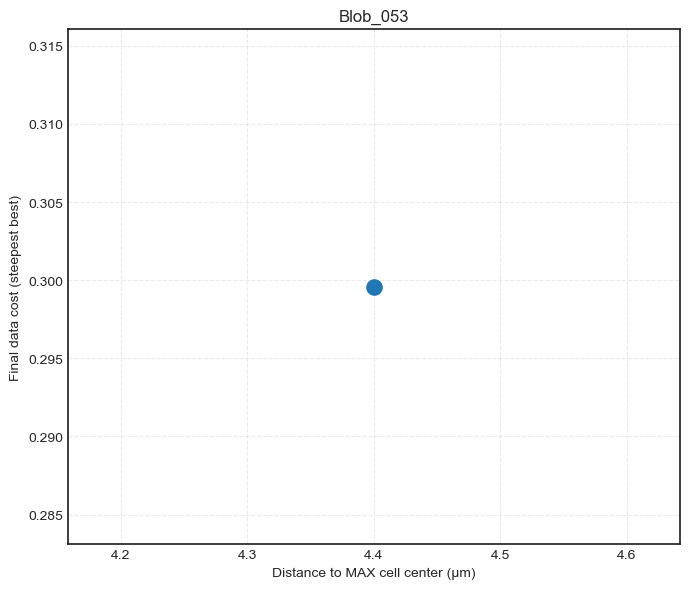


-------------------------------------
Blob: Blob_053
Final data cost (steepest) = 0.2995815433581426
Best meshfile              = meshgrid_step003.txt
Grain (from file)          = 1
Expected grain (blob#)     = 53
Distance to MAX cell       = 4.400000000000091
-------------------------------------



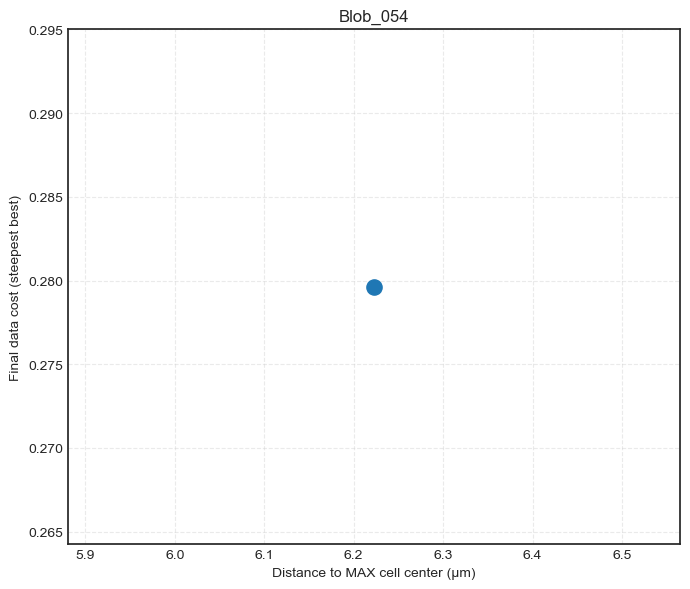


-------------------------------------
Blob: Blob_054
Final data cost (steepest) = 0.27962834496365363
Best meshfile              = meshgrid_step003.txt
Grain (from file)          = 1
Expected grain (blob#)     = 54
Distance to MAX cell       = 6.222539674441601
-------------------------------------



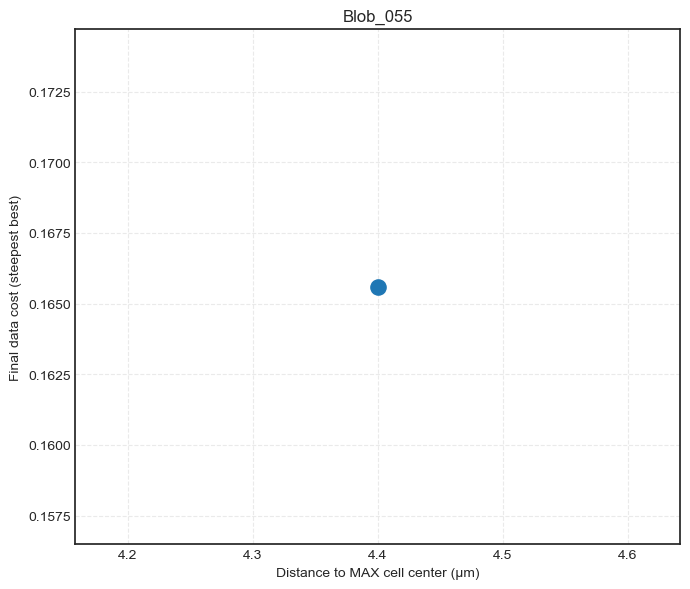


-------------------------------------
Blob: Blob_055
Final data cost (steepest) = 0.1655943567399107
Best meshfile              = meshgrid_step005.txt
Grain (from file)          = 1
Expected grain (blob#)     = 55
Distance to MAX cell       = 4.400000000000091
-------------------------------------



In [29]:
# distance from maxs

# =========================================================
# INPUTS
# =========================================================
# Steepest best-per-blob file
cost_txt_path = os.path.join(
    base_dir,
    "4-Source_Detection", "Results_DataCost_Steepest",
    "best_per_blob_steepest.txt"
)

# Max-cells combined CSV 
BLOB_ROOT = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Tomofast_Output_Blobs")
THR = 0.9
max_csv_path = os.path.join(BLOB_ROOT, f"ALL_BLOBS_grain_max_meshrow_{THR:.1f}.csv")

# Output plots folder
out_dir = os.path.join(base_dir, "4-Source_Detection", "Results_DataCost_Steepest")
os.makedirs(out_dir, exist_ok=True)

# =========================================================
# HELPERS
# =========================================================
def blob_index(blob_name: str) -> int:
    """Extract numeric index from 'Blob_001' -> 1"""
    m = re.search(r"(\d+)", str(blob_name))
    if not m:
        return np.nan
    return int(m.group(1))

# =========================================================
# 1) READ STEEPEST COST FILE (BEST PER BLOB)
# =========================================================
# file columns:
# blob grain meshfile xmin xmax ymin ymax zmin zmax final_data_cost
colnames = ["blob","grain","meshfile","xmin","xmax","ymin","ymax","zmin","zmax","final_data_cost"]
df = pd.read_csv(cost_txt_path, sep=r"\s+", names=colnames, comment="#")

# Keep only finite costs
df = df[np.isfinite(df["final_data_cost"])].copy()

# Grain like "grain_1" -> extract number
df["grain"] = df["grain"].astype(str).str.extract(r"(\d+)", expand=False)
df["grain"] = pd.to_numeric(df["grain"], errors="coerce")
df = df.dropna(subset=["grain"]).copy()
df["grain"] = df["grain"].astype(int)

# Centers of best cell
df["x_center"] = 0.5 * (df["xmin"] + df["xmax"])
df["y_center"] = 0.5 * (df["ymin"] + df["ymax"])
df["z_center"] = 0.5 * (df["zmin"] + df["zmax"])

# =========================================================
# 2) READ MAX CELLS CSV
# =========================================================
if not os.path.exists(max_csv_path):
    raise FileNotFoundError(f"Max-cells CSV not found:\n{max_csv_path}")

maxdf = pd.read_csv(max_csv_path)

# Normalize column name
if "Blob" in maxdf.columns:
    maxdf = maxdf.rename(columns={"Blob": "blob"})

# Max-cell centers from X1..Z2
maxdf["x_max_center"] = 0.5 * (maxdf["X1"] + maxdf["X2"])
maxdf["y_max_center"] = 0.5 * (maxdf["Y1"] + maxdf["Y2"])
maxdf["z_max_center"] = 0.5 * (maxdf["Z1"] + maxdf["Z2"])

# Match rule: Blob_001 -> expected_grain = 1, etc.
maxdf["expected_grain"] = maxdf["blob"].apply(blob_index)
maxdf = maxdf.dropna(subset=["expected_grain"]).copy()
maxdf["expected_grain"] = maxdf["expected_grain"].astype(int)

# If multiple rows per blob, keep first
maxdf = maxdf.drop_duplicates(subset=["blob"], keep="first")

# =========================================================
# 3) MERGE: add max-cell center to steepest best rows
# =========================================================
df["expected_grain"] = df["blob"].apply(blob_index)
df = df.dropna(subset=["expected_grain"]).copy()
df["expected_grain"] = df["expected_grain"].astype(int)

dfm = df.merge(
    maxdf[["blob", "expected_grain", "x_max_center", "y_max_center", "z_max_center"]],
    on=["blob", "expected_grain"],
    how="left"
)

missing = dfm[dfm["x_max_center"].isna()][["blob","grain","expected_grain"]].drop_duplicates()
if len(missing) > 0:
    print("\nWARNING: Missing max-cell match for these blobs:")
    print(missing.to_string(index=False))
    print()

# Distance between steepest best center and max-cell center
dfm["distance_to_maxcell"] = np.sqrt(
    (dfm["x_center"] - dfm["x_max_center"])**2 +
    (dfm["y_center"] - dfm["y_max_center"])**2 +
    (dfm["z_center"] - dfm["z_max_center"])**2
)

# =========================================================
# 4) PLOT PER BLOB (only 1 point per blob for steepest best)
# =========================================================
for blob_name, bdf in dfm.groupby("blob"):

    bdf = bdf.copy()
    bdf = bdf[np.isfinite(bdf["distance_to_maxcell"])].copy()
    if len(bdf) == 0:
        print(f"Skip {blob_name}: no max-cell center found.")
        continue

    # one point
    plt.figure(figsize=(7, 6))
    plt.scatter(bdf["distance_to_maxcell"], bdf["final_data_cost"], s=120)

    plt.xlabel("Distance to MAX cell center (µm)")
    plt.ylabel("Final data cost (steepest best)")
    plt.title(f"{blob_name}")
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.tight_layout()

    out_png = os.path.join(out_dir, f"SteepestBest_Cost_vs_DistToMaxCell_{blob_name}.png")
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()

    row = bdf.iloc[0]
    print("\n-------------------------------------")
    print("Blob:", blob_name)
    print("Final data cost (steepest) =", row["final_data_cost"])
    print("Best meshfile              =", row["meshfile"])
    print("Grain (from file)          =", row["grain"])
    print("Expected grain (blob#)     =", row["expected_grain"])
    print("Distance to MAX cell       =", row["distance_to_maxcell"])
    print("-------------------------------------\n")

# Tool 3: Source Vector Direction and Intensity Detection
this tool fits the full data with the detected true sources locations in a single inversion run

### 1. Combine best locations 
(into one mesh file)

In [30]:
## combine best meshs: BEST location per anomaly  (i from X, j=1, k=1)
## reads: 4-Source_Detection/Results_DataCost/all_final_data_costs_ALL_BLOBS.txt
## writes: 4-Source_Detection/combined_best_blobs_mesh.txt

# -----------------------------
# 1) Paths
# -----------------------------

summary_path = os.path.join(
    base_dir, "4-Source_Detection", "Results_DataCost_Steepest", "best_per_blob_steepest.txt"
)
out_path = os.path.join(
    base_dir, "4-Source_Detection", "combined_best_blobs_mesh.txt"
)
# -----------------------------
# 2) Read summary table (blob, grain, meshfile, bounds, cost)
# -----------------------------
colnames = ["blob", "grain", "meshfile", "xmin", "xmax", "ymin", "ymax",
            "zmin", "zmax", "final_data_cost"]

df = pd.read_csv(summary_path, sep=r"\s+", names=colnames, skiprows=1)

# -----------------------------
# 3) Best mesh per BLOB
# -----------------------------
best = df.loc[df.groupby("blob")["final_data_cost"].idxmin()].reset_index(drop=True)

n_blobs = len(best)
print("Number of blobs detected:", n_blobs)

# -----------------------------
# 4) Assign simple indices
# i = 1 ... n_blobs
# -----------------------------
best = best.reset_index(drop=True)
best["i"] = best.index + 1
best["j"] = 1
best["k"] = 1

best_sorted = best.copy()

# -----------------------------
# 5) Write combined mesh file
# -----------------------------
with open(out_path, "w") as f:
    f.write(f"{n_blobs}\n")

    print("\nWriting mesh entries (best per blob):")
    for _, row in best_sorted.iterrows():
        xmin, xmax = row["xmin"], row["xmax"]
        ymin, ymax = row["ymin"], row["ymax"]
        zmin, zmax = row["zmin"], row["zmax"]
        i = int(row["i"]); j = 1; k = 1

        print(f"  {row['blob']}  {row['meshfile']}  -> i={i}, j={j}, k={k}")
        f.write(f"{xmin} {xmax} {ymin} {ymax} {zmin} {zmax} 0 0 0 {i} {j} {k}\n")

# -----------------------------
# 6) Print max i, j, k
# -----------------------------
imax = int(best_sorted["i"].max()) if n_blobs else 0

print("\n====================================")
print(" Mesh Index Summary")
print("====================================")
print(f"Max i = {imax}")
print("j is fixed to 1")
print("k is fixed to 1")
print("====================================")

print("\nCombined mesh file saved to:")
print(out_path)


Number of blobs detected: 55

Writing mesh entries (best per blob):
  Blob_001  meshgrid_step008.txt  -> i=1, j=1, k=1
  Blob_002  meshgrid_step002.txt  -> i=2, j=1, k=1
  Blob_003  meshgrid_step003.txt  -> i=3, j=1, k=1
  Blob_004  meshgrid_step003.txt  -> i=4, j=1, k=1
  Blob_005  meshgrid_step006.txt  -> i=5, j=1, k=1
  Blob_006  meshgrid_step002.txt  -> i=6, j=1, k=1
  Blob_007  meshgrid_step001.txt  -> i=7, j=1, k=1
  Blob_008  meshgrid_step004.txt  -> i=8, j=1, k=1
  Blob_009  meshgrid_step004.txt  -> i=9, j=1, k=1
  Blob_010  meshgrid_step009.txt  -> i=10, j=1, k=1
  Blob_011  meshgrid_step002.txt  -> i=11, j=1, k=1
  Blob_012  meshgrid_step004.txt  -> i=12, j=1, k=1
  Blob_013  meshgrid_step002.txt  -> i=13, j=1, k=1
  Blob_014  meshgrid_step002.txt  -> i=14, j=1, k=1
  Blob_015  meshgrid_step002.txt  -> i=15, j=1, k=1
  Blob_016  meshgrid_step004.txt  -> i=16, j=1, k=1
  Blob_017  meshgrid_step009.txt  -> i=17, j=1, k=1
  Blob_018  meshgrid_step002.txt  -> i=18, j=1, k=1
  Blo

### 2. Create Parfile
create parfile for data fitting in a single run inversion
*  User Attention: define num of grains (true locations) nx and data size Ndata (full data) from the most first line

In [31]:
#Create Parfile
# User Attention: define num of grains nx and data size Ndata

output_path = os.path.join(base_dir, "0-Parfiles","Parfile_QDM_Dipole.txt")

par_text = """==================================================================================
GLOBAL
==================================================================================
global.outputFolderPath         = ./output/QDM
global.description              = QDM inversion data

==================================================================================
MODEL GRID parameters
==================================================================================
# nx ny nz
modelGrid.size                        = 55 1 1
modelGrid.magn.file                   = ./data/QDM/meshgrid.txt
modelGrid.magn.nModelComponents       = 3
==================================================================================
DATA parameters
==================================================================================
forward.data.magn.nData                = 139464
forward.data.magn.dataGridFile         = ./data/QDM/Mag_Inversion.obs
forward.data.magn.dataValuesFile       = ./data/QDM/Mag_Inversion.obs
forward.data.magn.nDataComponents      = 1

==================================================================================
MAGNETIC FIELD constants
==================================================================================
forward.magneticField.inclination              = 90.0
forward.magneticField.declination              = 0.0
forward.magneticField.XaxisDeclination         = 0.d0

==================================================================================
DEPTH WEIGHTING
==================================================================================
# 1-depth weight, 2-distance weight.
forward.depthWeighting.type                    = 1

==================================================================================
SENSITIVITY KERNEL
==================================================================================
# 0-calculate the sensitivity, 1-read from files at the specified folder.
sensit.readFromFiles                  = 0
sensit.folderPath                     = ./output/QDM/SENSIT/

==================================================================================
MATRIX COMPRESSION
==================================================================================
# 0-none, 1-wavelet compression.
forward.matrixCompression.type                        = 0
# The minimum compressed sensitivity absolute value.
forward.matrixCompression.rate                        = 0.1

==================================================================================
PRIOR MODEL
==================================================================================
# 1-set value, 2-read from file.
inversion.priorModel.type                  = 1
inversion.priorModel.magn.value            = 0.000000

==================================================================================
INVERSION parameters
==================================================================================
inversion.nMajorIterations              = 3
inversion.nMinorIterations              = 100
#inversion.modelDamping.normPower        = 1.4d0

==================================================================================
MODEL DAMPING (m - m_prior)
==================================================================================
inversion.modelDamping.magn.weight      = 0.d0


==================================================================================
JOINT INVERSION parameters
==================================================================================
inversion.joint.grav.problemWeight      = 0.00000000
inversion.joint.magn.problemWeight      = 1.00000000

===================================================================================
ADMM constraints
===================================================================================
inversion.admm.enableADMM           = 0
inversion.admm.nLithologies         = 1
inversion.admm.magn.bounds          = 0. 1.d10
inversion.admm.magn.weight          = 50.d0

#inversion.admm.magn.bounds          = -1.d10 0.d0
"""

with open(output_path, "w") as f:
    f.write(par_text)

print("Parfile created:", output_path)


Parfile created: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\0-Parfiles\Parfile_QDM_Dipole.txt


### 3. Run Tomofast inversion for Dipole Fitting
fit the true detected locations with the full data
* for WSL use the first line, for Linux use the second line (just a simple directory change)

In [32]:
# WSL Tomofast-x Run

#start run time
script_start_time = time.time()


### Run Tomofast Inversion Data (combined grains, one run)

# Convert Windows path (e.g. C:\Users\USER\...) to WSL path (/mnt/c/Users/USER/...)
def to_wsl_path(win_path: str) -> str:
    win_path = win_path.replace("\\", "/")   # C:/Users/USER/OneDrive - Curtin/...
    drive = win_path[0].lower()              # 'c'
    rest = win_path[2:]                      # /Users/USER/OneDrive - Curtin/...
    return f"/mnt/{drive}/{rest}"

base_dir_wsl = to_wsl_path(base_dir)
print("WSL version of current dir:", base_dir_wsl)

WSL = r"C:\Windows\System32\wsl.exe"

# Helper function to run a WSL command with live output
def run_live(cmd):
    process = subprocess.Popen(
        [WSL, "bash", "-lc", cmd],  # If running directly in Ubuntu VM, use cmd only
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )
    for line in process.stdout:
        print(line, end="")
        sys.stdout.flush()
    process.wait()
    print(f"\n[Return code: {process.returncode}]\n")


print("=== COPYING FILES TO TOMOFAST-x ===\n")

# ---------------------------------------------------------
# 1) Copy parfile + Mag_Inversion.obs to TomoFast-x
# ---------------------------------------------------------
run_live(f"cp '{base_dir_wsl}/0-Parfiles/Parfile_QDM_Dipole.txt'  {TOMOFAST_HOME_WSL}/parfiles/")
run_live(f"cp '{base_dir_wsl}/4-3D_Inversion_Filtered/Mag_Inversion.obs'   {TOMOFAST_HOME_WSL}/data/QDM/")

# ---------------------------------------------------------
# 2) Copy combined mesh file as meshgrid.txt (many grains, one run)
# ---------------------------------------------------------
combined_mesh_win = os.path.join(base_dir, "4-Source_Detection", "combined_best_blobs_mesh.txt")
combined_mesh_wsl = to_wsl_path(combined_mesh_win)

print("Using combined mesh file:")
print("Windows:", combined_mesh_win)
print("WSL:    ", combined_mesh_wsl)

run_live(f"cp '{combined_mesh_wsl}' '{TOMOFAST_HOME_WSL}/data/QDM/meshgrid.txt'")

# ---------------------------------------------------------
# 3) Run TomoFast-x once
# ---------------------------------------------------------
print("\n=== RUNNING TOMOFAST-X (combined grains) ===\n")

#run_live(f"cd {TOMOFAST_HOME_WSL} && ./tomofastx -p ./parfiles/Parfile_QDM_Dipole.txt | tee ./output/QDM/QDM_log.txt")

run_live(
    f"cd {TOMOFAST_HOME_WSL} && "
    f"{{ time ./tomofastx -p ./parfiles/Parfile_QDM_Dipole.txt; }} "   #time
    f"2>&1 | tee ./output/QDM/QDM_log.txt"
)
# ---------------------------------------------------------
# 4) Copy TomoFast-x output from Linux -> Windows
# ---------------------------------------------------------
output_win = os.path.join(base_dir, "4-Source_Detection", "Tomofast_Output", "combined_grains")
os.makedirs(output_win, exist_ok=True)

output_wsl = to_wsl_path(output_win)

print("Copying Tomofast-x output from Linux to Windows folder:")
print("Linux source:   /home/abekhit/Tomofast-x/output/QDM/")
print("Windows target:", output_win)

run_live(f"cp -r {TOMOFAST_HOME_WSL}/output/QDM/data '{output_wsl}/'")
run_live(f"cp -r {TOMOFAST_HOME_WSL}/output/QDM/model '{output_wsl}/'")
run_live(f"cp -r {TOMOFAST_HOME_WSL}/output/QDM/Paraview '{output_wsl}/'")
run_live(f"cp -r {TOMOFAST_HOME_WSL}/output/QDM/QDM_log.txt '{output_wsl}/'")
run_live(f"cp -r {TOMOFAST_HOME_WSL}/output/QDM/Parfile_copy.txt '{output_wsl}/'")
run_live(f"cp -r {TOMOFAST_HOME_WSL}/output/QDM/costs.txt '{output_wsl}/'")
# run_live(f"cp -r {TOMOFAST_HOME_WSL}/output/QDM/SENSIT '{output_wsl}/'")  # optional, very large

print("\nDone: combined mesh inversion finished and outputs copied.\n")

# calculate cost time
total_time = time.time() - script_start_time
print(f"\nTotal runtime: {total_time/60:.2f} minutes ({total_time:.1f} seconds)")

WSL version of current dir: /mnt/d//My_Work/Tomofast-x-µ/Work/Natural_applications/3 - Copy
=== COPYING FILES TO TOMOFAST-x ===


[Return code: 0]


[Return code: 0]

Using combined mesh file:
Windows: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\4-Source_Detection\combined_best_blobs_mesh.txt
WSL:     /mnt/d//My_Work/Tomofast-x-µ/Work/Natural_applications/3 - Copy/4-Source_Detection/combined_best_blobs_mesh.txt

[Return code: 0]


=== RUNNING TOMOFAST-X (combined grains) ===

 MEMORY USED (mpi init) [GB] =   9.2830657958984375E-003
 Started Tomofast-x, version >= 2.0.8.4
 global.outputFolderPath =./output/QDM
 global.description = QDM inversion data
 modelGrid.size =          55           1           1
 modelGrid.magn.file =./data/QDM/meshgrid.txt
 modelGrid.magn.nModelComponents =           3
 forward.data.magn.nData =      139464
 forward.data.magn.dataGridFile =./data/QDM/Mag_Inversion.obs
 forward.data.magn.dataValuesFile =./data/QDM/Mag_Inversion.obs
 forward.data.m

### 4. Vectors Directions Analysis
* User Attention define cell sizes (dx,dy,dz) [cell volume] for dipole moment calculation 

In [33]:
# Vector Direction Calculation (Double Check Step)
# Each cell in the model = one grain
# User Attention define cell sizes (dx,dy,dz) [cell volume] for dipole moment calculation 

# folder containing Tomofast outputs
root_folder = os.path.join(base_dir, "4-Source_Detection", "Tomofast_Output")

# combined-grains run
grain_folders = ["combined_grains"]
print("Found model folder(s):", grain_folders)

# --------------------------------------
# LOOP OVER (here only 'combined_grains')
# --------------------------------------
for grain in grain_folders:
    print("\n=====================================")
    print("Processing", grain)
    print("=====================================\n")

    Model = os.path.join(root_folder, grain, "model", "mag_final_model_full.txt")

    # -----------------------------
    # Load the model:
    # first line = number of grains
    # following lines = Mx My Mz per grain
    # -----------------------------
    with open(Model, "r") as f:
        lines = f.readlines()

    Ngrains = int(lines[0].strip())
    print("Number of grains in model:", Ngrains)

    # convert remaining lines (one per grain) into array
    data = np.loadtxt(lines[1:])  # read from second line onward
    data = np.atleast_2d(data)    # ensure 2D even if Ngrains = 1

    # -----------------------------
    # Process each grain
    # -----------------------------
    for grain_idx, (Mx, My, Mz_raw) in enumerate(data, start=1):

        print(f"\n--- Grain {grain_idx} ---")

        # Apply sign flip (same as your original code)
        Mz = -Mz_raw

        m = np.sqrt(Mx**2 + My**2 + Mz**2)

        if m == 0:
            dec, inc = np.nan, np.nan
        else:
            theta = np.degrees(np.arccos(Mz / m))
            phi   = np.degrees(np.arctan2(My, Mx))

            inc = theta - 90
            #dec= phi - 90
            dec = 90- phi

            change = True
            while change:
                change = False

                if inc > 90:
                    inc = 180 - inc 
                    dec = dec + 180
                    change = True

                if inc < -90:
                    inc = -180 - inc
                    dec = dec + 180
                    change = True

                if dec < 0:
                    dec = dec + 360
                    change = True

                if dec >= 360:
                    dec = dec - 360
                    change = True

        print("phi=", phi, "theta=", theta)
        print("dec=", dec, "inc=", inc)

        # Cell size (m)
        dx = 4.4e-6
        dy = 4.4e-6
        dz = 4.4e-6
        V = dx * dy * dz  # m^3

        # Horizontal magnitude
        H = np.hypot(Mx, My)

        # Inclination (positive down)
        inc_rad = np.arctan2(Mz, H)
        inc_deg = np.degrees(inc_rad)

        # Magnetization amplitude (A/m)
        M_amp = np.sqrt(Mx**2 + My**2 + Mz**2)

        # Magnetic moment amplitude (A·m^2)
        moment_amp = M_amp * V

        print("Magnetization amplitude:", M_amp*1e-6, "A/m")
        print("Magnetic moment amplitude:", moment_amp, "A·m²")


Found model folder(s): ['combined_grains']

Processing combined_grains

Number of grains in model: 55

--- Grain 1 ---
phi= -118.44862855927579 theta= 80.29372315074426
dec= 208.4486285592758 inc= -9.706276849255744
Magnetization amplitude: 0.001387665792355053 A/m
Magnetic moment amplitude: 1.1820692285597284e-13 A·m²

--- Grain 2 ---
phi= 179.86821166437107 theta= 107.02697891787993
dec= 270.1317883356289 inc= 17.02697891787993
Magnetization amplitude: 0.002243696386212473 A/m
Magnetic moment amplitude: 1.9112703296312333e-13 A·m²

--- Grain 3 ---
phi= 81.93685102333815 theta= 155.70406960364082
dec= 8.06314897666185 inc= 65.70406960364082
Magnetization amplitude: 0.0029113280063663384 A/m
Magnetic moment amplitude: 2.4799856489431016e-13 A·m²

--- Grain 4 ---
phi= 129.46286769774113 theta= 121.8245726367582
dec= 320.5371323022589 inc= 31.824572636758205
Magnetization amplitude: 0.0016436509554170493 A/m
Magnetic moment amplitude: 1.4001276298624594e-13 A·m²

--- Grain 5 ---
phi= 160

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Using combined-grains model: ['combined_grains']

Processing: combined_grains
Number of grains detected: 55
Grain 1: dec=208.45, inc=-9.71
Grain 2: dec=270.13, inc=17.03
Grain 3: dec=8.06, inc=65.70
Grain 4: dec=320.54, inc=31.82
Grain 5: dec=289.32, inc=3.85
Grain 6: dec=276.42, inc=56.46
Grain 7: dec=271.95, inc=27.25
Grain 8: dec=284.48, inc=63.61
Grain 9: dec=318.36, inc=26.58
Grain 10: dec=298.87, inc=-7.03
Grain 11: dec=288.81, inc=-0.11
Grain 12: dec=0.12, inc=11.89
Grain 13: dec=275.72, inc=48.98
Grain 14: dec=206.25, inc=61.71
Grain 15: dec=293.50, inc=13.24
Grain 16: dec=215.20, inc=-5.91
Grain 17: dec=237.53, inc=15.32
Grain 18: dec=329.49, inc=61.08
Grain 19: dec=285.52, inc=42.17
Grain 20: dec=288.34, inc=36.13
Grain 21: dec=280.28, inc=-6.17
Grain 22: dec=294.75, inc=45.10
Grain 23: dec=299.91, inc=44.44
Grain 24: dec=294.07, inc=42.76
Grain 25: dec=264.89, inc=31.11
Grain 26: dec=63.22, inc=37.29
Grain 27: dec=282.87, inc=24.78
Grain 28: dec=244.20, inc=58.14
Grain 29: d

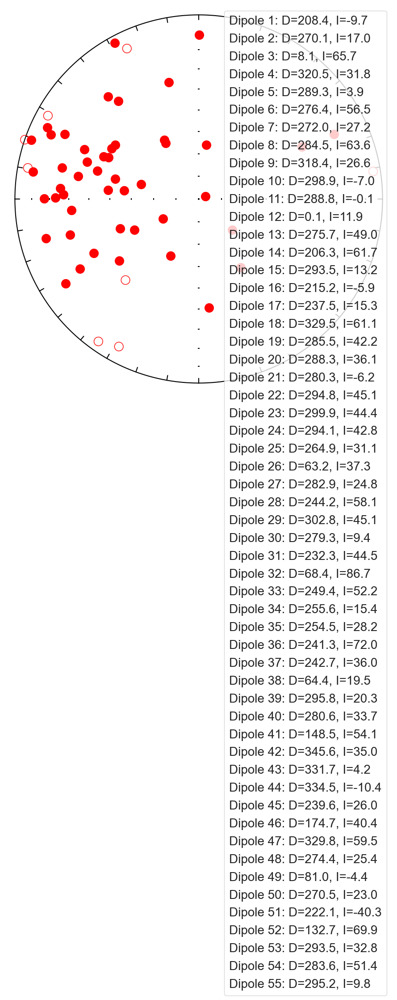

Saved combined plot: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\4-Source_Detection\aAll_Combined_Grains_DecInc.png


In [34]:
### Stereonet plot (combined grains)

# Root folder of Tomofast outputs
root_folder = os.path.join(base_dir, "4-Source_Detection", "Tomofast_Output")

#  use combined_grains model
grain_folders = ["combined_grains"]
print("Using combined-grains model:", grain_folders)

results = []  # store (grain_index, dec, inc)

for folder in grain_folders:

    print("\nProcessing:", folder)

    # path to final model
    Model = os.path.join(root_folder, folder, "model", "mag_final_model_full.txt")

    # ---- Load model: first line = Ngrains, rest = Mx My Mz ----
    with open(Model, "r") as f:
        lines = f.readlines()

    Ngrains = int(lines[0].strip())
    print("Number of grains detected:", Ngrains)

    data = np.loadtxt(lines[1:])
    data = np.atleast_2d(data)  # ensure 2D

    # --------------------------------------
    # Compute dec/inc for each grain cell
    # --------------------------------------
    for idx, (Mx, My, Mz_raw) in enumerate(data, start=1):

        Mz = -Mz_raw  # same sign flip
        m = np.sqrt(Mx**2 + My**2 + Mz**2)

        if m == 0:
            dec, inc = np.nan, np.nan
        else:
            theta = np.degrees(np.arccos(Mz / m))
            phi   = np.degrees(np.arctan2(My, Mx))

            inc = theta - 90
            #dec= phi - 90
            dec = 90- phi

            change = True
            while change:
                change = False

                if inc > 90:
                    inc = 180 - inc
                    dec = dec + 180
                    change = True

                if inc < -90:
                    inc = -180 - inc
                    dec = dec + 180
                    change = True

                if dec < 0:
                    dec = dec + 360
                    change = True

                if dec >= 360:
                    dec = dec - 360
                    change = True

        print(f"Grain {idx}: dec={dec:.2f}, inc={inc:.2f}")
        results.append((idx, dec, inc))


# ======================================
# Plot on Stereonet
# ======================================

plt.figure(figsize=(9, 9))
ipmag.plot_net()

ax = plt.gca()

#ax.text(
#    0.02, 0.98, "(d)",
#    transform=ax.transAxes,
#    fontsize=30,
 #   fontweight="bold",
 #   va="top",
 #   ha="left"
#)

#colors = plt.cm.tab10(np.linspace(0, 1, len(results)))

colors = ["r"] * len(results)   # all points same color (black)

for (grain_idx, dec, inc), col in zip(results, colors):
    ipmag.plot_di(dec, inc, color=col, marker='o', markersize=200)
    
    #plt.plot([], [], marker='o', color=col, 
            # label=f"Dipole {grain_idx}: D={dec:.1f}, I={inc:.1f}")
    plt.plot([], [], color="r", linestyle="None",
         label=f"Dipole {grain_idx}: D={dec:.1f}, I={inc:.1f}")


#plt.legend(loc="upper right", fontsize=10, frameon=True)
plt.legend(loc="upper right", handlelength=0, handletextpad=0, fontsize=20, frameon=True)

#plt.title("Dec–Inc of Combined Grains (Equal-Area Net)", fontsize=14)

out_png = os.path.join(base_dir, "4-Source_Detection", "aAll_Combined_Grains_DecInc.png")
plt.savefig(out_png, dpi=300, bbox_inches='tight')

plt.show()

print("Saved combined plot:", out_png)


Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


Using combined-grains model: ['combined_grains']

Processing: combined_grains
Number of grains detected: 55
Grain 1: dec=208.45, inc=-9.71, moment=1.182e-13
Grain 2: dec=270.13, inc=17.03, moment=1.911e-13
Grain 3: dec=8.06, inc=65.70, moment=2.480e-13
Grain 4: dec=320.54, inc=31.82, moment=1.400e-13
Grain 5: dec=289.32, inc=3.85, moment=4.985e-13
Grain 6: dec=276.42, inc=56.46, moment=1.491e-13
Grain 7: dec=271.95, inc=27.25, moment=2.794e-13
Grain 8: dec=284.48, inc=63.61, moment=8.565e-15
Grain 9: dec=318.36, inc=26.58, moment=1.989e-13
Grain 10: dec=298.87, inc=-7.03, moment=1.461e-12
Grain 11: dec=288.81, inc=-0.11, moment=2.805e-13
Grain 12: dec=0.12, inc=11.89, moment=5.998e-15
Grain 13: dec=275.72, inc=48.98, moment=1.119e-13
Grain 14: dec=206.25, inc=61.71, moment=1.577e-14
Grain 15: dec=293.50, inc=13.24, moment=1.008e-12
Grain 16: dec=215.20, inc=-5.91, moment=7.242e-15
Grain 17: dec=237.53, inc=15.32, moment=7.206e-13
Grain 18: dec=329.49, inc=61.08, moment=1.693e-14
Grain 

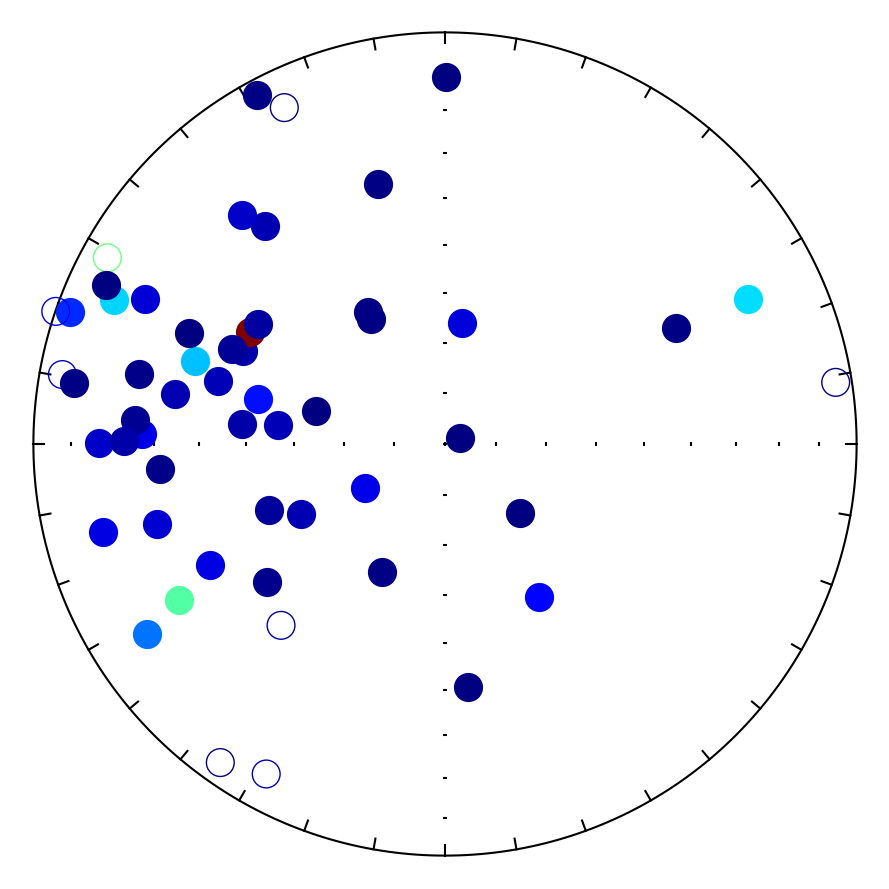

Saved combined plot: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3\4-Source_Detection\All_Combined_Grains_DecInc_byMoment.png


In [2]:
### Stereonet plot (combined grains) — color by moment
# ============================================================
#  User Attention define cell sizes (dx,dy,dz) [cell volume] for dipole moment calculation  
# ============================================================
dx = 4.4* 1e-6   # cell size in X 
dy = 4.4* 1e-6   # cell size in Y
dz = 4.4* 1e-6   # cell size in Z
volume = dx * dy * dz

base_dir = os.getcwd()
root_folder = os.path.join(base_dir, "4-Source_Detection", "Tomofast_Output")

grain_folders = ["combined_grains"]
print("Using combined-grains model:", grain_folders)

results = []  # store (grain_index, dec, inc, moment)

for folder in grain_folders:

    print("\nProcessing:", folder)
    Model = os.path.join(root_folder, folder, "model", "mag_final_model_full.txt")

    with open(Model, "r") as f:
        lines = f.readlines()

    Ngrains = int(lines[0].strip())
    print("Number of grains detected:", Ngrains)

    data = np.loadtxt(lines[1:])
    data = np.atleast_2d(data)

    for idx, (Mx, My, Mz_raw) in enumerate(data, start=1):

        Mz = -Mz_raw
        mag = np.sqrt(Mx**2 + My**2 + Mz**2)     # magnetization magnitude
        moment = mag * volume                    # moment intensity (your definition)

        if mag == 0:
            dec, inc = np.nan, np.nan
        else:
            theta = np.degrees(np.arccos(Mz / mag))
            phi   = np.degrees(np.arctan2(My, Mx))

            inc = theta - 90
            dec = 90 - phi

            change = True
            while change:
                change = False
                if inc > 90:
                    inc = 180 - inc
                    dec = dec + 180
                    change = True
                if inc < -90:
                    inc = -180 - inc
                    dec = dec + 180
                    change = True
                if dec < 0:
                    dec = dec + 360
                    change = True
                if dec >= 360:
                    dec = dec - 360
                    change = True

        print(f"Grain {idx}: dec={dec:.2f}, inc={inc:.2f}, moment={moment:.3e}")
        results.append((idx, dec, inc, moment))


# ======================================
# Plot on Stereonet
# ======================================
plt.figure(figsize=(9, 9))
ipmag.plot_net()
ax = plt.gca()

#ax.text(0.02, 0.98, "(d)", transform=ax.transAxes,
#        fontsize=30, fontweight="bold", va="top", ha="left")

# --- color by moment ---
moments = np.array([r[3] for r in results], dtype=float)
good = np.isfinite(moments)

vmin = np.nanmin(moments[good])
vmax = np.nanmax(moments[good])
norm = Normalize(vmin=vmin, vmax=vmax)
cmap = plt.cm.jet

for (grain_idx, dec, inc, moment) in results:
    if not (np.isfinite(dec) and np.isfinite(inc) and np.isfinite(moment)):
        continue
    col = cmap(norm(moment))
    ipmag.plot_di(dec, inc, color=col, marker='o', markersize=400)

# colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
#cbar = plt.colorbar(sm, ax=ax, pad=0.05)
#cbar.set_label("Magnetic moment (A·m²)", fontsize=16)
#cbar.ax.tick_params(labelsize=16)
#cbar.ax.yaxis.get_offset_text().set_fontsize(16)

#legend
for (grain_idx, dec, inc, moment) in results:
    plt.plot([], [], color="k", linestyle="None",
             label=f"Dipole {grain_idx}: D={dec:.1f}°, I={inc:.1f}°, m={moment:.2e} A·m²")



#plt.legend(loc="upper right", handlelength=0, handletextpad=0, fontsize=12)

out_png = os.path.join(base_dir, "4-Source_Detection", "All_Combined_Grains_DecInc_byMoment.png")
plt.savefig(out_png, dpi=300, bbox_inches="tight")

out_svg = os.path.join(base_dir, "4-Source_Detection", "All_Combined_Grains_DecInc_byMoment.svg")
plt.savefig(out_svg, format="svg", bbox_inches="tight")

plt.show()

print("Saved combined plot:", out_png)


### 5. Final Report and plots
* User Attention define cell sizes (dx,dy,dz) [cell volume] for dipole moment calculation 

In [36]:
# Vector Direction Calculation + Best Mesh Centers as TABLE (ONE MODEL, MANY BLOB LOCATIONS)
# User Attention define cell sizes (dx,dy,dz) [cell volume] for dipole moment calculation 

# ---------------------------------------------------------
# 1) Paths
# ---------------------------------------------------------
summary_path = os.path.join(
    base_dir,
    "4-Source_Detection",
    "Results_DataCost_Steepest",
    "best_per_blob_steepest.txt"
)


Model = os.path.join(
    base_dir,
    "4-Source_Detection",
    "Tomofast_Output",
    "combined_grains",          # or whatever your single-run folder is
    "model",
    "mag_final_model_full.txt"
)

out_csv = os.path.join(base_dir, "4-Source_Detection", "Blob_Vector_Summary.csv")

# ---------------------------------------------------------
# 2) Read summary + best per blob
# ---------------------------------------------------------
df = pd.read_csv(
    summary_path,
    sep=r"\s+",
    skiprows=1,
    names=["blob", "grain", "meshfile", "xmin", "xmax", "ymin", "ymax",
           "zmin", "zmax", "final_data_cost"]
)

# best mesh row per blob
best = df.loc[df.groupby("blob")["final_data_cost"].idxmin()].reset_index(drop=True)

# sort blobs Blob_001, Blob_002, ...
def blob_num(b):
    m = re.search(r"(\d+)$", b)
    return int(m.group(1)) if m else 10**9

best = best.sort_values("blob", key=lambda s: s.map(blob_num)).reset_index(drop=True)

print("Number of blobs (best rows):", len(best))
print("First blobs:", best["blob"].head().tolist())

# compute centers
best["x_center"] = 0.5 * (best["xmin"] + best["xmax"])
best["y_center"] = 0.5 * (best["ymin"] + best["ymax"])
best["z_center"] = 0.5 * (best["zmin"] + best["zmax"])

# ---------------------------------------------------------
# 3) Load the ONE model file (Mx My Mz rows)
# ---------------------------------------------------------
print("\nModel file:", Model)
with open(Model, "r") as f:
    lines = f.readlines()

Nmodel = int(lines[0].strip())
data = np.loadtxt(lines[1:])
data = np.atleast_2d(data)

print("Number of cells in model:", Nmodel)

# check matching
if Nmodel != len(best):
    print("WARNING: model cells != number of blobs in best table")
    print("  Nmodel =", Nmodel)
    print("  Nblobs =", len(best))
    print("Fix by: (1) ensuring blob list matches model order, (2) removing extra blobs, or (3) using the correct model file.")

# ---------------------------------------------------------
# 4) Compute directions per blob (row i = blob i after sorting)
# ---------------------------------------------------------
dx = dy = dz = 4.4e-6
V = dx * dy * dz

table_rows = []

n = min(Nmodel, len(best))  # safe loop

for i in range(n):
    blob_name = best.loc[i, "blob"]
    Mx, My, Mz_raw = data[i]

    # sign flip (same as your original)
    Mz = -Mz_raw
    m = np.sqrt(Mx**2 + My**2 + Mz**2)

    if m == 0:
        dec, inc = np.nan, np.nan
    else:
        theta = np.degrees(np.arccos(Mz / m))
        phi   = np.degrees(np.arctan2(My, Mx))

        inc = theta - 90
        #dec= phi - 90
        dec = 90- phi

        change = True
        while change:
            change = False
            if inc > 90:
                inc = 180 - inc
                dec = dec + 180
                change = True
            if inc < -90:
                inc = -180 - inc
                dec = dec + 180
                change = True
            if dec < 0:
                dec = dec + 360
                change = True
            if dec >= 360:
                dec = dec - 360
                change = True

    M_amp = np.sqrt(Mx**2 + My**2 + Mz**2)
    moment_amp = M_amp * V

    table_rows.append({
        "blob": blob_name,
        "meshfile": best.loc[i, "meshfile"],
        "final_data_cost": best.loc[i, "final_data_cost"],
        "x_center": best.loc[i, "x_center"],
        "y_center": best.loc[i, "y_center"],
        "z_center": best.loc[i, "z_center"],
       # "Mx": Mx,
       # "My": My,
       # "Mz_raw": Mz_raw,
      #  "Mz_flipped": Mz,
        "dec": dec,
        "inc": inc,
        #"M_amp(A/m)": M_amp,
        "moment(A·m²)": moment_amp
    })

results_table = pd.DataFrame(table_rows)

print("\n================= FINAL Report (PER BLOB) =================\n")
print(results_table.to_string(index=False))

results_table.to_csv(out_csv, index=False)
print("\n Saved:", out_csv)


Number of blobs (best rows): 55
First blobs: ['Blob_001', 'Blob_002', 'Blob_003', 'Blob_004', 'Blob_005']

Model file: D:\My_Work\Tomofast-x-µ\Work\Natural_applications\3 - Copy\4-Source_Detection\Tomofast_Output\combined_grains\model\mag_final_model_full.txt
Number of cells in model: 55

================= FINAL Report (PER BLOB) =================

    blob             meshfile  final_data_cost  x_center  y_center  z_center        dec        inc  moment(A·m²)
Blob_001 meshgrid_step008.txt         0.138502     475.2      -4.4      15.4 208.448629  -9.706277  1.182069e-13
Blob_002 meshgrid_step002.txt         0.120972    1082.4      74.8      19.8 270.131788  17.026979  1.911270e-13
Blob_003 meshgrid_step003.txt         0.166328     638.0      88.0      24.2   8.063149  65.704070  2.479986e-13
Blob_004 meshgrid_step003.txt         0.198587    1064.8     123.2      19.8 320.537132  31.824573  1.400128e-13
Blob_005 meshgrid_step006.txt         0.283936     910.8     162.8      24.2 289.322

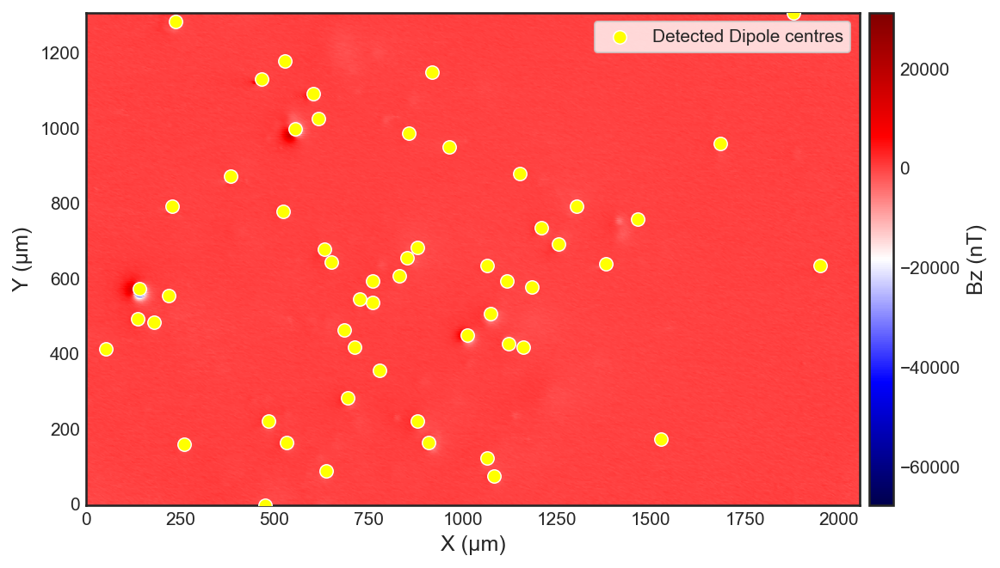

In [8]:
# plot detected locations on Bz

# ---------- 1. Read mag.obs ----------
mag_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Mag_Inversion.obs")
mag = np.loadtxt(mag_path, skiprows=1)

x = mag[:, 0]
y = mag[:, 1]
bz = mag[:, 3]
#back to QDM Converntion
bz = -1*mag[:, 3]

# ---------- 2. Read grain centres ----------
grain_path = os.path.join(base_dir, "4-Source_Detection", "Blob_Vector_Summary.csv")
grains = pd.read_csv(grain_path, sep=None, engine="python")

gx = grains["x_center"].values
gy = grains["y_center"].values

# ---------- 3. Improve colour scaling ----------
bz_min = np.percentile(bz, 0)
bz_max = np.percentile(bz, 100)

# ---------- 4. Apply nicer matplotlib style ----------
plt.style.use("seaborn-v0_8-white")

# ---------- 5. Plot ----------
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

# Bz scatter (clipped for prettier colour contrast)
sc = ax.scatter(
    x, y, c=bz, s=10, cmap="seismic",
    vmin=bz_min, vmax=bz_max, rasterized=True
)

cbar = plt.colorbar(sc, ax=ax, shrink=0.67, pad=0.01)
cbar.set_label("Bz (nT)", fontsize=12)
cbar.ax.tick_params(labelsize=10)

# Grain centres
ax.scatter(
    gx, gy, c="yellow", s=55, edgecolors="white",
    linewidths=0.7, label="Detected Dipole centres", zorder=3
)

# ---------- 6. Labels & styling ----------
ax.set_xlabel("X (µm)", fontsize=12)
ax.set_ylabel("Y (µm)", fontsize=12)
#ax.set_title("Bz Map with Grain Centres", fontsize=14)

ax.set_aspect("equal", adjustable="box")
ax.grid(True, linestyle="--", alpha=0.3)
ax.margins(0)
plt.legend(frameon=True, fontsize=10, loc="upper right")
plt.tight_layout()

out_png = os.path.join(base_dir, "4-Source_Detection", "BZ_grains_centers.png")
plt.savefig(out_png, dpi=300, bbox_inches='tight')
plt.show()


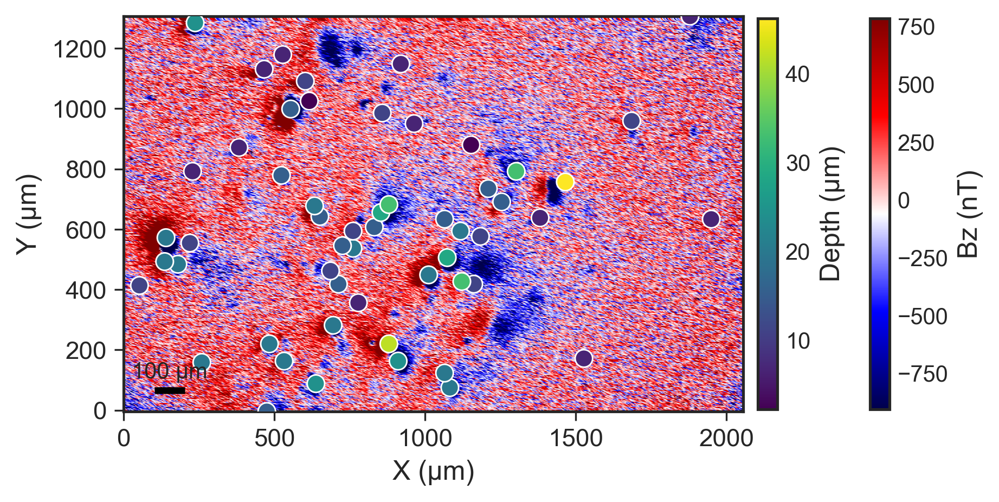

In [4]:
# plot detected locations and depths on bz

# ---------- 1. Read mag.obs ----------
mag_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Mag_Inversion.obs")
mag = np.loadtxt(mag_path, skiprows=1)

x = mag[:, 0]
y = mag[:, 1]
bz =  mag[:, 3]   # QDM convention

bz = -1 * mag[:, 3]   # QDM convention

# ---------- 2. Read grain centres ----------
grain_path = os.path.join(base_dir, "4-Source_Detection", "Blob_Vector_Summary.csv")
grains = pd.read_csv(grain_path, sep=None, engine="python")

gx = grains["x_center"].values
gy = grains["y_center"].values
gz = grains["z_center"].values   # <<< depth

# ---------- 3. Improve colour scaling (clip 2% outliers) ----------
bz_min = np.percentile(bz, 2)
bz_max = np.percentile(bz, 98)

# ---------- 4. Apply matplotlib style ----------
plt.style.use("seaborn-v0_8-white")

# ---------- 5. Plot ----------
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)

# Bz scatter
sc = ax.scatter(
    x, y, c=bz, s=10, cmap="seismic",
    vmin=bz_min, vmax=bz_max, rasterized=True
)

cbar = fig.colorbar(sc, ax=ax, shrink=0.52, pad=0.0)
cbar.set_label("Bz (nT)", fontsize=12)
cbar.ax.tick_params(labelsize=10)

# Grain centres colored by depth
scz = ax.scatter(
    gx, gy, c=gz, cmap="viridis", s=60,
    edgecolors="white", linewidths=0.7,
    label="Detected dipole centres", zorder=3
)

cbarz = plt.colorbar(scz, ax=ax, shrink=0.52, pad=0.02)
cbarz.set_label("Depth (µm)", fontsize=12)
cbarz.ax.tick_params(labelsize=10)

# ---------- Scale bar (e.g., 100 µm) ----------
bar_len = 100.0  # µm
x0 = np.min(x) + 0.05 * (np.max(x) - np.min(x))
y0 = np.min(y) + 0.05 * (np.max(y) - np.min(y))

ax.plot([x0, x0 + bar_len], [y0, y0], color="k", linewidth=3, solid_capstyle="butt", zorder=5)
ax.text(x0 + 0.5 * bar_len, y0 + 0.02 * (np.max(y) - np.min(y)),
        f"{int(bar_len)} µm", ha="center", va="bottom", fontsize=10)

# ---------- 6. Labels & styling ----------
ax.set_xlabel("X (µm)", fontsize=12)
ax.set_ylabel("Y (µm)", fontsize=12)

ax = plt.gca()
ax.tick_params(axis="both",length=4, labelsize=11)

ax.set_aspect("equal", adjustable="box")
#ax.grid(True, linestyle="--", alpha=0.3)
ax.margins(0)

#ax.text(
#    0.02, 0.98, "(b)",
 #   transform=ax.transAxes,
 #   fontsize=18,
 #   fontweight="bold",
 #   va="top",
 #   ha="left"
#)

#plt.legend(frameon=True, fontsize=12, loc="upper right")
#plt.tight_layout()
plt.subplots_adjust(right=0.8)  

# Save PNG
out_png = os.path.join(base_dir, "4-Source_Detection", "BZ_grains_centers_depth.png")
plt.savefig(out_png, dpi=300, bbox_inches='tight')

plt.show()


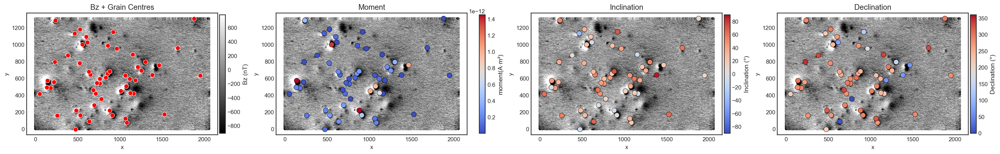

In [10]:
# plot full results (locations, moment, inc, dec)

# ---------- 1) Read mag.obs ----------
mag_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Mag_Inversion.obs")
mag = np.loadtxt(mag_path, skiprows=1)

x = mag[:, 0]
y = mag[:, 1]
bz = mag[:, 3]

bz = -1*mag[:, 3]


# ---------- 2) Read grain centres & properties ----------
grain_path = os.path.join(base_dir, "4-Source_Detection", "Blob_Vector_Summary.csv")
grains = pd.read_csv(grain_path)

# Required columns
if "x_center" not in grains.columns or "y_center" not in grains.columns:
    raise ValueError(f"CSV must contain x_center and y_center. Found: {list(grains.columns)}")
if "dec" not in grains.columns or "inc" not in grains.columns:
    raise ValueError(f"CSV must contain dec and inc. Found: {list(grains.columns)}")

gx = grains["x_center"].to_numpy()
gy = grains["y_center"].to_numpy()
dec = grains["dec"].to_numpy()
inc = grains["inc"].to_numpy()

# moment column name can vary
moment_col_candidates = ["moment(A·m²)", "moment(A·m2)", "moment", "Moment", "moment_amp"]
moment_col = None
for c in moment_col_candidates:
    if c in grains.columns:
        moment_col = c
        break
if moment_col is None:
    raise ValueError(f"Could not find moment column in CSV. Found: {list(grains.columns)}")
moment = grains[moment_col].to_numpy()

# ---------- 3) Clip ranges ----------
bz_min = np.nanpercentile(bz, 2)
bz_max = np.nanpercentile(bz, 98)

m_min = np.nanpercentile(moment, 2)
m_max = np.nanpercentile(moment, 98)

# ---------- 4) Figure ----------
fig, axs = plt.subplots(1, 4, figsize=(24, 6), dpi=140, constrained_layout=True)

def plot_bz_background(ax):
    # GREY background
    sc = ax.scatter(
        x, y, c=bz, s=10, cmap="gray",
        vmin=bz_min, vmax=bz_max, rasterized=True
    )
    ax.set_aspect("equal")
    ax.grid(True, linestyle="--", alpha=0.25)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    return sc

# 1) Bz + centres
ax = axs[0]
sc_bz0 = plot_bz_background(ax)
ax.scatter(gx, gy, c="red", s=60, edgecolors="white", linewidths=0.7, zorder=3)
ax.set_title("Bz + Grain Centres", fontsize=13)

# 2) Moment
ax = axs[1]
plot_bz_background(ax)
sc_m = ax.scatter(
    gx, gy, c=moment, s=75, cmap="coolwarm",
    vmin=m_min, vmax=m_max,
    edgecolors="black", linewidths=0.5, zorder=3
)
ax.set_title("Moment", fontsize=13)

# 3) Inclination
ax = axs[2]
plot_bz_background(ax)
sc_i = ax.scatter(
    gx, gy, c=inc, s=75, cmap="coolwarm",
    vmin=-90, vmax=90,
    edgecolors="black", linewidths=0.5, zorder=3
)
ax.set_title("Inclination", fontsize=13)

# 4) Declination
ax = axs[3]
plot_bz_background(ax)
sc_d = ax.scatter(
    gx, gy, c=dec, s=75, cmap="coolwarm",
    vmin=0, vmax=360,
    edgecolors="black", linewidths=0.5, zorder=3
)
ax.set_title("Declination", fontsize=13)

# ---------- Colorbars (FIXED POSITIONS) ----------
# Put each colorbar next to its own axis (no global colorbar)
cb_bz = fig.colorbar(sc_bz0, ax=axs[0], fraction=0.031, pad=0.01)
cb_bz.set_label("Bz (nT)", fontsize=11)

cb_m = fig.colorbar(sc_m, ax=axs[1], fraction=0.031, pad=0.01)
cb_m.set_label(f"{moment_col}", fontsize=11)

cb_i = fig.colorbar(sc_i, ax=axs[2], fraction=0.031, pad=0.01)
cb_i.set_label("Inclination (°)", fontsize=11)

cb_d = fig.colorbar(sc_d, ax=axs[3], fraction=0.031, pad=0.01)
cb_d.set_label("Declination (°)", fontsize=11)

out_png = os.path.join(base_dir, "4-Source_Detection", "BZ_grains_centers_results.png")
plt.savefig(out_png, dpi=300, bbox_inches='tight')
plt.show()


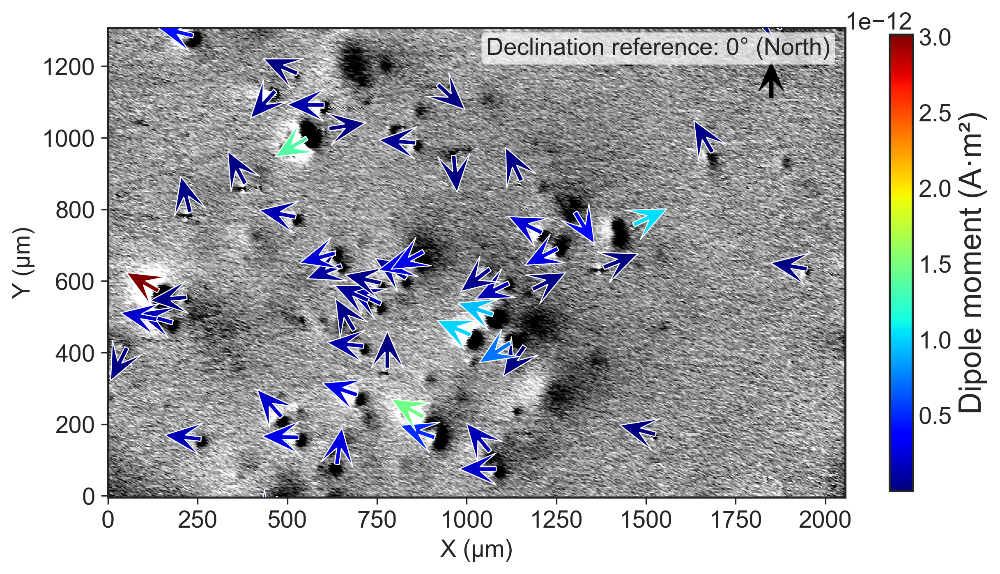

In [5]:
# plot declinations arrows colored by moment overlaied on bz

# ---------- 1) Read mag.obs ----------
mag_path = os.path.join(base_dir, "4-3D_Inversion_Filtered", "Mag_Inversion.obs")
mag = np.loadtxt(mag_path, skiprows=1)

x = mag[:, 0]
y = mag[:, 1]
bz = mag[:, 3]


bz = -1*mag[:, 3]

# ---------- 2) Read grain centres & properties ----------
grain_path = os.path.join(base_dir, "4-Source_Detection", "Blob_Vector_Summary.csv")
grains = pd.read_csv(grain_path)

# Required columns
required_cols = ["x_center", "y_center", "dec"]
for c in required_cols:
    if c not in grains.columns:
        raise ValueError(f"Missing column {c} in Blob_Vector_Summary.csv")

gx = grains["x_center"].to_numpy()
gy = grains["y_center"].to_numpy()
dec = grains["dec"].to_numpy()

# moment column name can vary
moment_col_candidates = ["moment(A·m²)", "moment(A·m2)", "moment", "Moment", "moment_amp"]
moment_col = None
for c in moment_col_candidates:
    if c in grains.columns:
        moment_col = c
        break
if moment_col is None:
    raise ValueError(f"Could not find moment column in CSV. Found: {list(grains.columns)}")
moment = grains[moment_col].to_numpy()

# ---------- 3) Clip ranges ----------
bz_min = np.nanpercentile(bz, 2)
bz_max = np.nanpercentile(bz, 98)

m_min = np.nanmin(moment)
m_max = np.nanmax(moment)

# ---------- 4) Figure ----------
fig, ax = plt.subplots(1, 1, figsize=(8, 6), dpi=300, constrained_layout=True)

# --- Bz background (GREY) ---
sc_bz = ax.scatter(
    x, y,
    c=bz, s=10, cmap="gray",
    vmin=bz_min, vmax=bz_max,
    rasterized=True
)


ax.set_aspect("equal")
ax.grid(True, linestyle="--", alpha=0.25)
ax.margins(0)
ax.set_xlabel("X (µm)", fontsize=14)
ax.set_ylabel("Y (µm)", fontsize=14)
ax.tick_params(axis="both",length=4, labelsize=14)
#ax.set_title("Bz map + Declination arrows (colored by Moment)", fontsize=13)

# ---------- Declination arrows ----------
# Use declination from results directly (degrees → radians)
dec_rad = np.deg2rad(dec)

# Unit direction vectors
#u = np.cos(dec_rad)
#v = np.sin(dec_rad)

# Geophysical declination convention:
# 0° = North (+Y), clockwise positive
u = np.sin(dec_rad)
v = np.cos(dec_rad)
           
# Fixed arrow length in data units (handle NaNs safely)
dx = np.ptp(x[np.isfinite(x)])
dy = np.ptp(y[np.isfinite(y)])
arrow_len = 0.05 * max(dx, dy)

# Color normalization for moment
norm_m = Normalize(vmin=m_min, vmax=m_max)

q = ax.quiver(
    gx, gy,
    u * arrow_len, v * arrow_len,
    moment,
    cmap="jet",
    norm=norm_m,
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.008,          # slightly thicker
    headwidth=7,
    headlength=8,
    edgecolor="white",    # contrast edge
    linewidth=0.6,
    zorder=4
)

# ----------  3: Reference arrow ----------
#x0 = np.nanmin(x) + 0.08 * dx
#y0 = np.nanmin(y) + 0.10 * dy
x0 = np.nanmax(x) - 0.10 * dx,
y0 = np.nanmax(y) - 0.15 * dy,

# Reference arrow (0° = North, pointing UP)
ax.quiver(
    x0, y0,
    0.0, arrow_len,          #  UPWARD arrow
    color="black",
    angles="xy",
    scale_units="xy",
    scale=1,
    width=0.006,
    headwidth=6.0,
    headlength=7.0,
    zorder=4
)


#ax.text(
#    x0, y0 + 1.15 * arrow_len,
#    "Declination reference: 0° (North)",
#    fontsize=9,
#    ha="center",
#    va="bottom",
#    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, ec="none"),
#    zorder=5
#)

ax.text(
    0.98, 0.98,
    "Declination reference: 0° (North)",
    transform=ax.transAxes,
    fontsize=14,
    ha="right",
    va="top",
    bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, ec="none"),
    zorder=5
)


#ax.text(
 #   x0, y0 - 0.04 * dy,
 #   "Arrows show declination (°), clockwise from North",
  #  fontsize=7,
  #  ha="left",
  #  va="top",
  #  bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7, ec="none"),
  #  zorder=5
#)


# ---------- Colorbars ----------
#cb_bz = fig.colorbar(sc_bz, ax=ax, fraction=0.046, pad=0.02)
#cb_bz.set_label("Bz (nT)", fontsize=12)
#cb_bz.ax.tick_params(labelsize=10)


#cb_q = fig.colorbar(q, ax=ax, fraction=0.045, pad=0) #0.08
cb_q = fig.colorbar(
    q, ax=ax,
    fraction=0.031, pad=-0.01
)
cb_q.set_label("Dipole moment (A·m²)", fontsize=18)
cb_q.ax.tick_params(labelsize=14)
#  scientific notation
cb_q.ax.yaxis.get_offset_text().set_fontsize(14)

#ax.text(
#    0.02, 0.98, "(c)",
 #   transform=ax.transAxes,
  #  fontsize=30,
   # fontweight="bold",
   # va="top",
   # ha="left"
#)

out_png = os.path.join(base_dir, "4-Source_Detection", "BZ_grains_Dec.png")
plt.savefig(out_png, dpi=300, bbox_inches='tight')
plt.show()


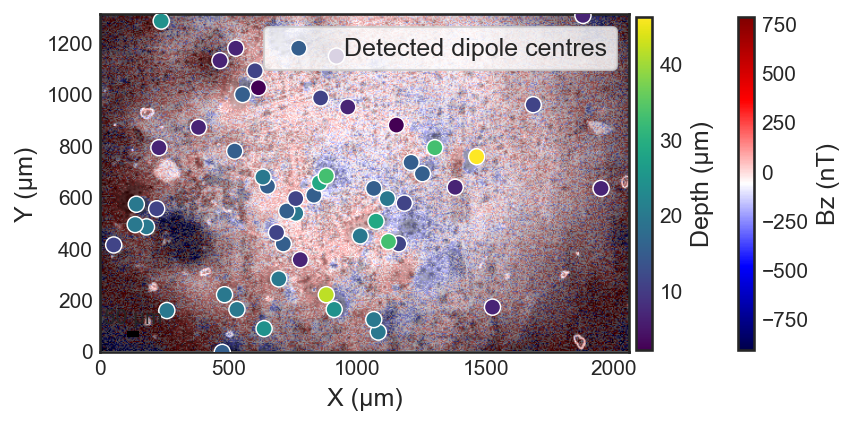

In [12]:
# plot led locations on led on bz
# User attention define pixel size (data spacing) (pix=)

# ---------- LOAD MAT (Bz + LED) ----------
mat_file = glob.glob(os.path.join(base_dir, "*.mat"))[0]
mat = loadmat(mat_file)

Bz  = np.squeeze(mat["Bz"]) * 1e9          # nT
led = np.squeeze(mat["newLED"])

# ---------- LOAD GRAIN CENTRES ----------
grain_path = os.path.join(base_dir, "4-Source_Detection", "Blob_Vector_Summary.csv")
grains = pd.read_csv(grain_path, sep=None, engine="python")

gx = grains["x_center"].values
gy = grains["y_center"].values
gz = grains["z_center"].values   # depth (µm)

# ---------- Pixel size (µm / pixel) ----------
pix = 4.4
ny, nx = Bz.shape

x = np.linspace(0, nx * pix, nx)
y = np.linspace(0, ny * pix, ny)

extent = [x.min(), x.max(), y.min(), y.max()]

# ---------- Improve colour scaling (clip 2% outliers) ----------
bz_min = np.percentile(Bz, 2)
bz_max = np.percentile(Bz, 98)

# ---------- Style ----------
plt.style.use("seaborn-v0_8-white")

# ---------- Plot ----------
fig, ax = plt.subplots(figsize=(8, 6), dpi=150)

# --- Bz base ---
im = ax.imshow(
    Bz,
    cmap="seismic",
    vmin=bz_min,
    vmax=bz_max,
    origin="upper",
    extent=extent
)

cbar = plt.colorbar(im, ax=ax, shrink=0.48, pad=0.01)
cbar.set_label("Bz (nT)", fontsize=12)
cbar.ax.tick_params(labelsize=10)

# --- LED overlay ---
ax.imshow(
    led,
    cmap="gray",
    alpha=0.7,
    origin="upper",
    extent=extent,
    vmin=np.percentile(led, 5),
    vmax=np.percentile(led, 95)
)

# --- Grain centres colored by depth ---
scz = ax.scatter(
    gx, gy, c=gz, cmap="viridis", s=60,
    edgecolors="white", linewidths=0.7,
    label="Detected dipole centres", zorder=3
)

cbarz = plt.colorbar(scz, ax=ax, shrink=0.48, pad=0.01)
cbarz.set_label("Depth (µm)", fontsize=12)
cbarz.ax.tick_params(labelsize=10)

# ---------- Scale bar ----------
bar_len = 50.0  # µm
x0 = x.min() + 0.05 * (x.max() - x.min())
y0 = y.min() + 0.05 * (y.max() - y.min())

ax.plot([x0, x0 + bar_len], [y0, y0],
        color="k", linewidth=3, solid_capstyle="butt", zorder=5)
ax.text(x0 + 0.5 * bar_len, y0 + 0.02 * (y.max() - y.min()),
        f"{int(bar_len)} µm", ha="center", va="bottom", fontsize=10, zorder=5)

# ---------- Labels & styling ----------
ax.set_xlabel("X (µm)", fontsize=12)
ax.set_ylabel("Y (µm)", fontsize=12)
ax.set_aspect("equal", adjustable="box")
ax.margins(0)

#ax.text(
#    0.02, 0.98, "(b)",
#    transform=ax.transAxes,
 #   fontsize=18,
 #   fontweight="bold",
 #   va="top",
 #   ha="left"
#)

plt.legend(frameon=True, fontsize=12, loc="upper right")
#plt.tight_layout()
plt.subplots_adjust(right=0.75)  
# ---------- Save ----------
out_png = os.path.join(base_dir, "Bz_LED_grain_centers_depth.png")
plt.savefig(out_png, dpi=300, bbox_inches="tight")
plt.show()


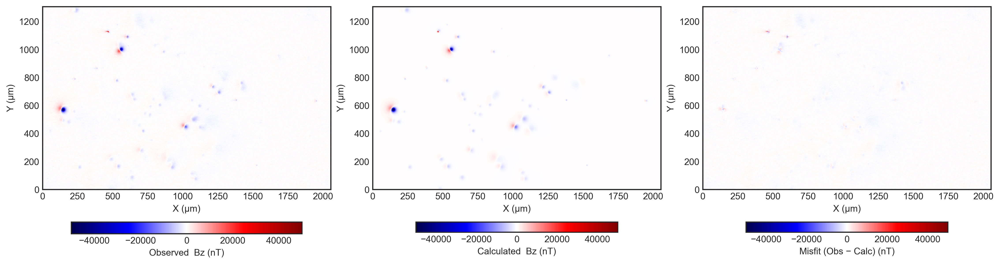

Data cost = 0.411008


In [42]:
# plot obs, calc, misfit

# Direc
data_dir = os.path.join(base_dir, "4-Source_Detection", "Tomofast_Output", "combined_grains", "data")

obs_file    = os.path.join(data_dir, "mag_observed_data.txt")
calc_file   = os.path.join(data_dir, "mag_calc_final_data.txt")
misfit_file = os.path.join(data_dir, "mag_misfit_final_data.txt")

# Helpers
def load_field_table(path, names=("x", "y", "z", "value")):
    df = pd.read_csv(path, sep=r"\s+", names=list(names))
    df[["x", "y", "value"]] = df[["x", "y", "value"]].apply(pd.to_numeric, errors="coerce")
    df = df.dropna(subset=["x", "y", "value"])
    df = df[np.isfinite(df["x"]) & np.isfinite(df["y"]) & np.isfinite(df["value"])]
    return df

def df_to_grid(df):
    xs = np.sort(df["x"].unique())
    ys = np.sort(df["y"].unique())
    grid = (
        df.pivot_table(index="y", columns="x", values="value")
          .reindex(index=ys, columns=xs)
    )
    return grid.to_numpy(), xs, ys


# Check files 
if not os.path.exists(obs_file):
    raise FileNotFoundError(f"Missing file: {obs_file}")
if not os.path.exists(calc_file):
    raise FileNotFoundError(f"Missing file: {calc_file}")
if not os.path.exists(misfit_file):
    raise FileNotFoundError(f"Missing file: {misfit_file}")

# Load 
obs_df    = load_field_table(obs_file)
calc_df   = load_field_table(calc_file)
misfit_df = load_field_table(misfit_file)

if obs_df.empty or calc_df.empty or misfit_df.empty:
    raise ValueError("Empty/invalid data after cleaning.")


# Grid
obs_grid, xs, ys       = df_to_grid(obs_df)
calc_grid, xs2, ys2    = df_to_grid(calc_df)
misfit_grid, xs3, ys3  = df_to_grid(misfit_df)

if xs.size == 0 or ys.size == 0 or xs2.size == 0 or ys2.size == 0 or xs3.size == 0 or ys3.size == 0:
    raise ValueError("No valid grid (x/y unique values are empty).")

extent = [xs.min(), xs.max(), ys.min(), ys.max()]
if not np.all(np.isfinite(extent)):
    raise ValueError("Bad extent (NaN/Inf).")

# Plot (3 panels) 
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=300)

im0 = axes[0].imshow(-obs_grid, origin="lower", cmap="seismic", extent=extent, aspect="equal", vmin=-50000, vmax=50000)
#axes[0].set_title("Observed")
axes[0].set_xlabel("X (µm)")
axes[0].set_ylabel("Y (µm)")
axes[0].margins(0)
#cbar0 = plt.colorbar(im0, ax=axes[0], shrink=0.85)
#cbar0.set_label("Observed  Bz (nT)")

cbar0 = plt.colorbar(im0, ax=axes[0], orientation="horizontal", pad=0.1,  shrink=0.8)
cbar0.set_label("Observed  Bz (nT)")


im1 = axes[1].imshow(-calc_grid, origin="lower", cmap="seismic", extent=extent, aspect="equal", vmin=-50000, vmax=50000)
#axes[1].set_title("Calculated")
axes[1].set_xlabel("X (µm)")
axes[1].set_ylabel("Y (µm)")
axes[1].margins(0)
#cbar1 = plt.colorbar(im1, ax=axes[1], shrink=0.85)
#cbar1.set_label("Calculated  Bz (nT)")

cbar1 = plt.colorbar(im1, ax=axes[1], orientation="horizontal", pad=0.1, shrink=0.7)
cbar1.set_label("Calculated  Bz (nT)")

im2 = axes[2].imshow(-misfit_grid, origin="lower", cmap="seismic", extent=extent, aspect="equal",  vmin=-50000, vmax=50000)
#axes[2].set_title("Misfit (Obs - Calc)")
axes[2].set_xlabel("X (µm)")
axes[2].set_ylabel("Y (µm)")
axes[2].margins(0)
#cbar2 = plt.colorbar(im2, ax=axes[2], shrink=0.85)
#cbar2.set_label("Misfit (Obs − Calc)  Bz (nT)")

cbar2 = plt.colorbar(im2, ax=axes[2], orientation="horizontal", pad=0.1,  shrink=0.7)
cbar2.set_label("Misfit (Obs − Calc) (nT)")

plt.tight_layout(pad=0.2)

fig_path = os.path.join(data_dir, "obs_calc_misfit.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()

# Data cost = ||pred - obs|| / ||obs||
bz_obs  = obs_df["value"].to_numpy()
bz_pred = calc_df["value"].to_numpy()

data_cost = np.linalg.norm(bz_pred - bz_obs) / np.linalg.norm(bz_obs)
print(f"Data cost = {data_cost:.6f}")